# final


After train-validation split:
Training samples  : 2624
Validation samples: 656
Test samples      : 1073

Model:
SignCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1152, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=3, bias=True)
  )
)

Total parameters    : 388611
Trainable parameters: 388611

========== TRAINING =====

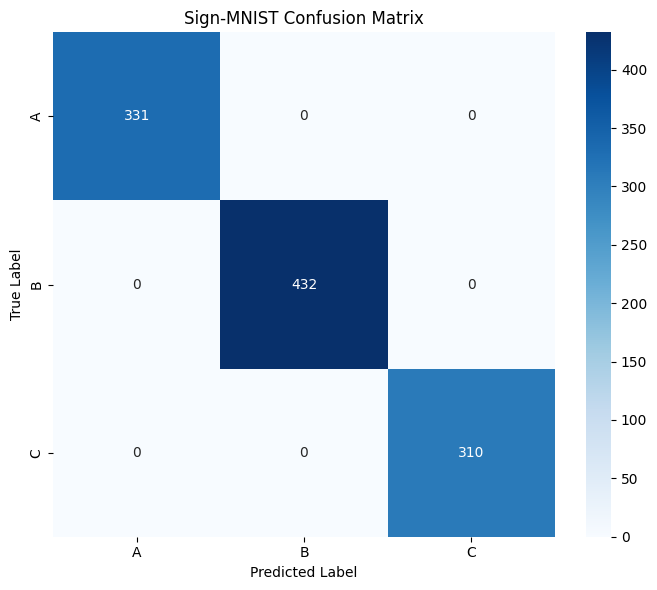


========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       331
           B     1.0000    1.0000    1.0000       432
           C     1.0000    1.0000    1.0000       310

    accuracy                         1.0000      1073
   macro avg     1.0000    1.0000    1.0000      1073
weighted avg     1.0000    1.0000    1.0000      1073



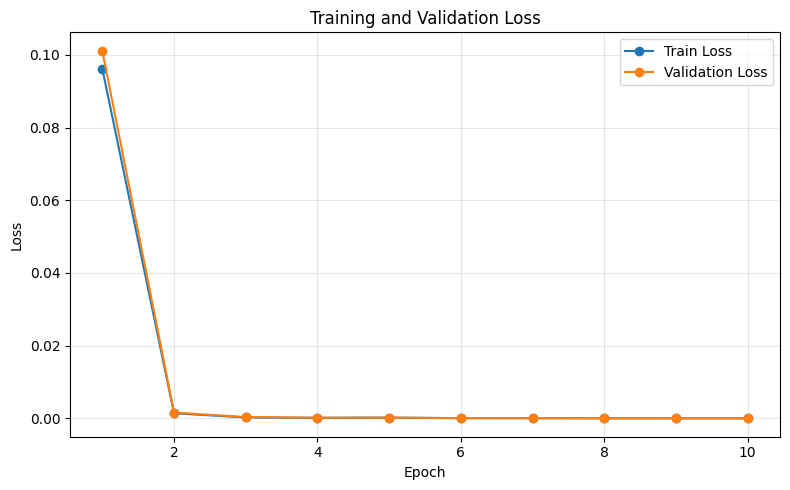

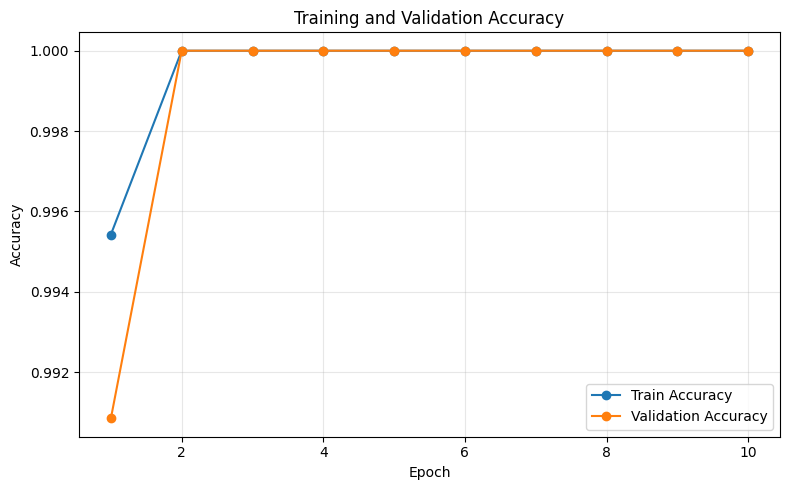



              FINAL TEST RESULTS
Test Loss       : 0.0010
Accuracy        : 1.0000
Precision       : 1.0000
Recall          : 1.0000
F1 Score        : 1.0000

Model saved as: sign_model2.pth
Best model saved as: best_sign_cnn.pth


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    accuracy_score,
    precision_recall_fscore_support
)
from sklearn.preprocessing import label_binarize



# =====================================================
# CONFIG
# =====================================================

BATCH_SIZE = 64
EPOCHS = 10
LR = 1e-3

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# A,B,C
SELECTED_CLASSES = [0,1,2]

# =====================================================
# DATASET
# =====================================================

train_df = pd.read_csv("sign_mnist_train.csv")
test_df = pd.read_csv("sign_mnist_test.csv")

train_df = train_df[
    train_df["label"].isin(SELECTED_CLASSES)
]

test_df = test_df[
    test_df["label"].isin(SELECTED_CLASSES)
]

label_map = {
    0:0,
    1:1,
    2:2
}

train_df["label"] = train_df["label"].map(label_map)
test_df["label"] = test_df["label"].map(label_map)


train_df, val_df = train_test_split(
    train_df,
    test_size=0.20,
    random_state=42,
    stratify=train_df["label"]
)

print("\nAfter train-validation split:")
print("Training samples  :", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples      :", len(test_df))


class SignDataset(Dataset):

    def __init__(self, df):

        self.labels = df["label"].values

        self.images = (
            df.drop("label", axis=1)
            .values
            .reshape(-1,28,28)
            .astype(np.float32)
            /255.0
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        image = torch.tensor(
            self.images[idx]
        ).unsqueeze(0)

        label = torch.tensor(
            self.labels[idx]
        ).long()

        return image, label

train_ds = SignDataset(train_df)
val_ds = SignDataset(val_df)
test_ds = SignDataset(test_df)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# =====================================================
# MODEL
# =====================================================

class SignCNN(nn.Module):

    def __init__(self):

        super().__init__()

        # 1*28*28
        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=1,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.MaxPool2d(2),

            # 32*14*14
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2),

            #64*7*7
            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
             #128*3*3
            nn.Flatten(),

            nn.Linear(128 * 3 * 3, 256),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(256, 3)
        )

    def forward(self,x):

        x = self.features(x)
        x = self.classifier(x)

        return x


model = SignCNN().to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LR
)


# =====================================================
# MODEL SUMMARY
# =====================================================

print("\nModel:")
print(model)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTotal parameters    :", total_params)
print("Trainable parameters:", trainable_params)

# =====================================================
# EVALUATION FUNCTION
# =====================================================

def evaluate(model, loader):

    model.eval()

    total_loss = 0.0

    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            total_loss += loss.item()

            probs = torch.softmax(
                outputs,
                dim=1
            )

            preds = torch.argmax(
                outputs,
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_probs.extend(
                probs.cpu().numpy()
            )

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            all_labels,
            all_preds,
            average="weighted",
            zero_division=0
        )
    )

    return {
        "loss": total_loss / len(loader),
        "acc": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "labels": all_labels,
        "preds": all_preds,
        "probs": all_probs
    }


# =====================================================
# TRAIN
# =====================================================
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_acc = 0.0

print("\n========== TRAINING ==========\n")
for epoch in range(EPOCHS):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    train_metrics = evaluate(
        model,
        train_loader
    )

    val_metrics = evaluate(
        model,
        val_loader
    )

    history["train_loss"].append(
        train_metrics["loss"]
    )

    history["val_loss"].append(
        val_metrics["loss"]
    )

    history["train_acc"].append(
        train_metrics["acc"]
    )

    history["val_acc"].append(
        val_metrics["acc"]
    )

    if val_metrics["acc"] > best_val_acc:

        best_val_acc = val_metrics["acc"]

        torch.save(
            model.state_dict(),
            "best_sign_cnn.pth"
        )

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"| Train Loss: {train_metrics['loss']:.4f} "
        f"| Train Acc: {train_metrics['acc']:.4f} "
        f"| Val Loss: {val_metrics['loss']:.4f} "
        f"| Val Acc: {val_metrics['acc']:.4f}"
    )


print("\nBest Validation Accuracy:",
      f"{best_val_acc:.4f}")

model.load_state_dict(
    torch.load(
        "best_sign_cnn.pth",
        map_location=DEVICE
    )
)


test_metrics = evaluate(
    model,
    test_loader
)

test_loss = test_metrics["loss"]

y_true = test_metrics["labels"]
y_pred = test_metrics["preds"]
y_prob = test_metrics["probs"]


class_names = [
    "A",
    "B",
    "C"
]

# =====================================================
# CONFUSION MATRIX
# =====================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(3)
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Sign-MNIST Confusion Matrix")

plt.tight_layout()
plt.show()


# =====================================================
# PER-CLASS CLASSIFICATION REPORT
# =====================================================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(3),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# =====================================================
# ROC-AUC
# =====================================================

y_true_bin = label_binarize(
    y_true,
    classes=np.arange(3)
)

auc = roc_auc_score(
    y_true_bin,
    y_prob,
    multi_class="ovr",
    average="macro"
)


# =====================================================
# TRAINING LOSS CURVE
# =====================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# =====================================================
# TRAINING ACCURACY CURVE
# =====================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    history["train_acc"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    range(1, EPOCHS + 1),
    history["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# =====================================================
# FINAL TEST METRICS
# =====================================================

acc = accuracy_score(
    y_true,
    y_pred
)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
)


print("\n")
print("==============================================")
print("              FINAL TEST RESULTS")
print("==============================================")

print(f"Test Loss       : {test_loss:.4f}")
print(f"Accuracy        : {acc:.4f}")
print(f"Precision       : {precision:.4f}")
print(f"Recall          : {recall:.4f}")
print(f"F1 Score        : {f1:.4f}")
# print(f"ROC-AUC (OvR)   : {auc:.4f}")

print("==============================================")


# =====================================================
# SAVE FINAL MODEL
# =====================================================

torch.save(
    model.state_dict(),
    "sign_model2.pth"
)

print("\nModel saved as: sign_model2.pth")
print("Best model saved as: best_sign_cnn.pth")

# intermediate step results

## display input image

tensor([[0.7961, 0.8039, 0.8118, 0.8078, 0.8118, 0.8196, 0.8235, 0.8196, 0.8235,
         0.8196, 0.8157, 0.8118, 0.8118, 0.8196, 0.8157, 0.8235, 0.8235, 0.8118,
         0.8196, 0.8196, 0.8157, 0.8196, 0.8235, 0.8196, 0.8118, 0.8157, 0.8196,
         0.8118],
        [0.8078, 0.8157, 0.8196, 0.8157, 0.8157, 0.8235, 0.8275, 0.8235, 0.8275,
         0.8196, 0.8196, 0.8235, 0.8275, 0.8275, 0.8196, 0.8157, 0.8275, 0.8431,
         0.8235, 0.8314, 0.8314, 0.8275, 0.8275, 0.8235, 0.8235, 0.8275, 0.8235,
         0.8235],
        [0.8196, 0.8196, 0.8235, 0.8275, 0.8235, 0.8235, 0.8314, 0.8314, 0.8275,
         0.8314, 0.8235, 0.8235, 0.8314, 0.8275, 0.8745, 0.8157, 0.6353, 0.6902,
         0.8588, 0.8000, 0.8078, 0.8510, 0.8471, 0.8392, 0.8314, 0.8196, 0.8275,
         0.8314],
        [0.8196, 0.8235, 0.8275, 0.8353, 0.8431, 0.8353, 0.8275, 0.8353, 0.8353,
         0.8275, 0.8471, 0.8471, 0.7020, 0.6549, 0.8941, 0.7922, 0.6314, 0.5059,
         0.5176, 0.6078, 0.5529, 0.7333, 0.8235, 0.6235

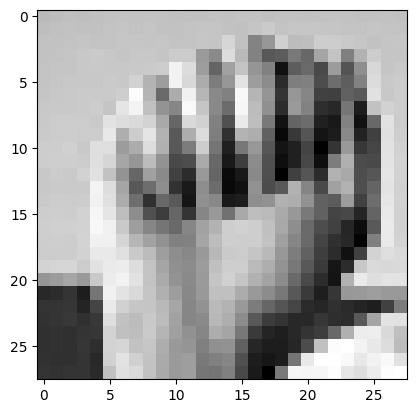

In [ ]:
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset, DataLoader
import numpy as np

# Redefine for local scope if the cell is run independently
# otherwise, it should be available from j1VgweClW3n8
SELECTED_CLASSES = [0,1,2]
label_map = {0:0, 1:1, 2:2}

test_df_raw = pd.read_csv("sign_mnist_test.csv")
test_df_filtered = test_df_raw[test_df_raw["label"].isin(SELECTED_CLASSES)].copy()
test_df_filtered["label"] = test_df_filtered["label"].map(label_map)


class SignDataset(Dataset):

    def __init__(self, df):

        self.labels = df["label"].values

        self.images = (
            df.drop("label", axis=1)
            .values
            .reshape(-1,28,28)
            .astype(np.float32)
            /255.0
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        image = torch.tensor(
            self.images[idx]
        ).unsqueeze(0)

        label = torch.tensor(
            self.labels[idx]
        ).long()

        return image.reshape(28,28), label


test_ds = SignDataset(test_df_filtered)

img, _ = test_ds.__getitem__(0)
print(img)
plt.imshow(img, cmap='gray')

## display features

-----INPUT IMAGE-----
LABEL: 0


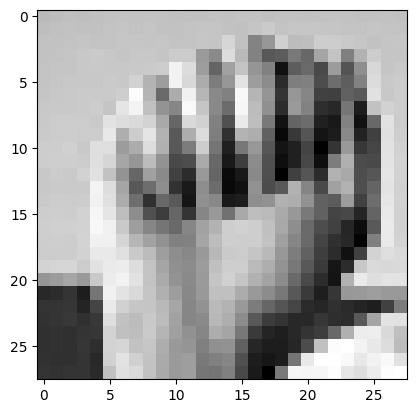

Dimension: torch.Size([1, 1, 28, 28])

-----AFTER CONV1 IMAGE-----


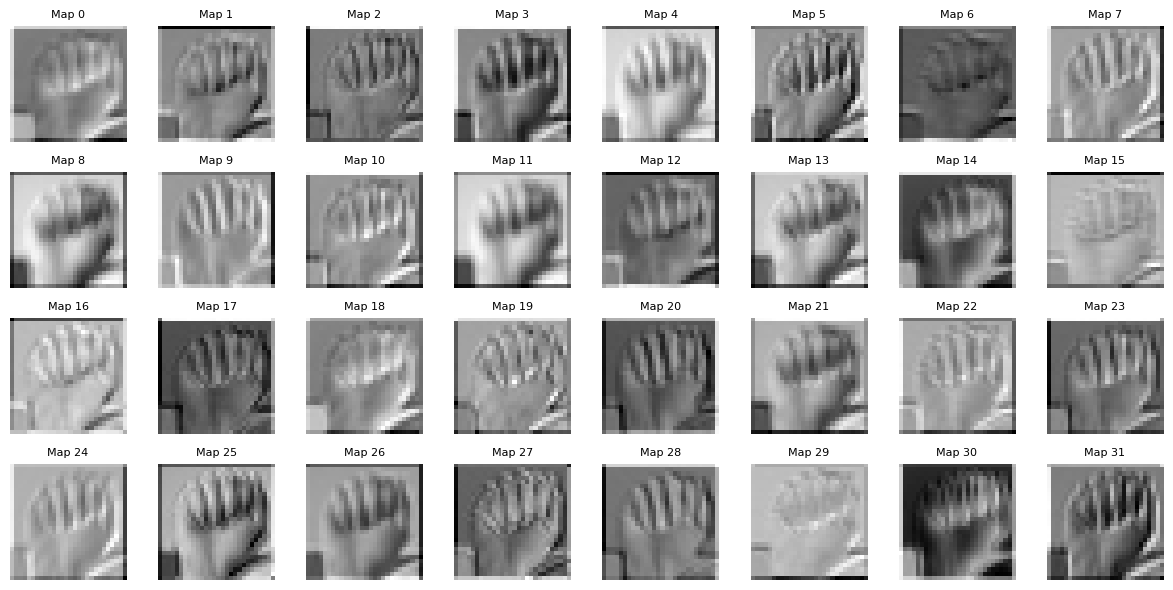

Dimension: torch.Size([1, 32, 28, 28])

-----AFTER RELU1 IMAGE-----


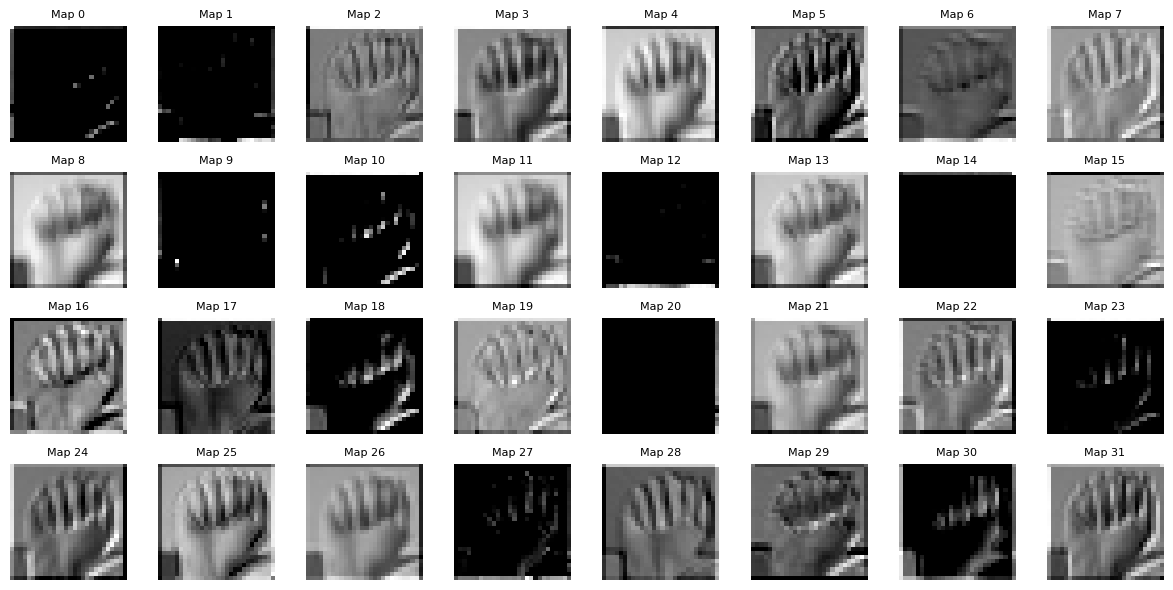

Dimension: torch.Size([1, 32, 28, 28])

-----AFTER POOL1 IMAGE-----


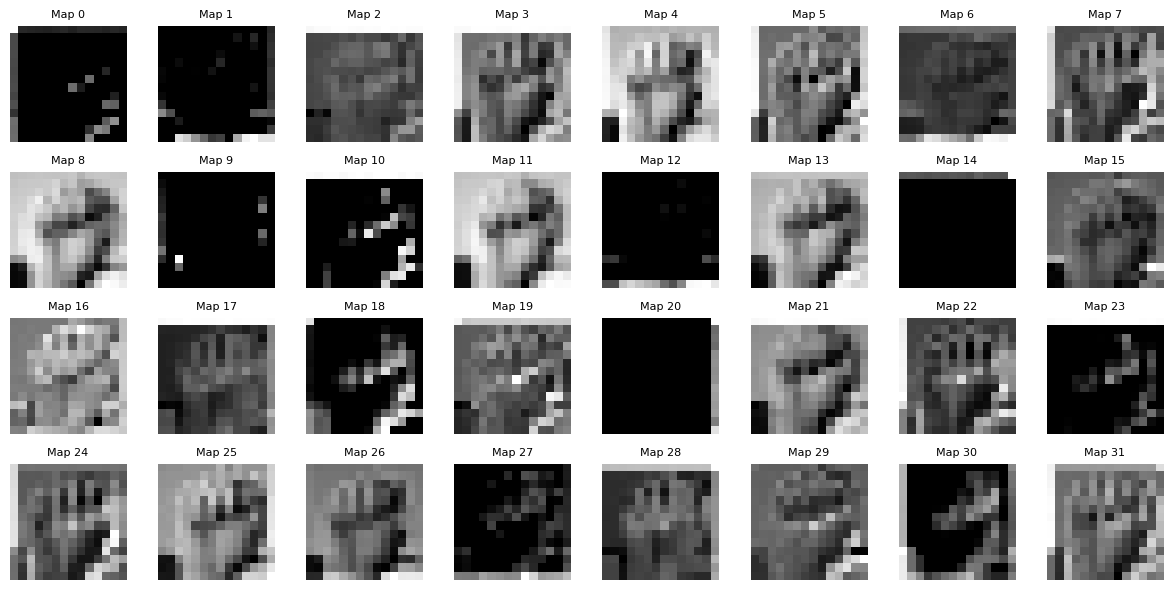

Dimension: torch.Size([1, 32, 14, 14])

-----AFTER CONV2 IMAGE-----


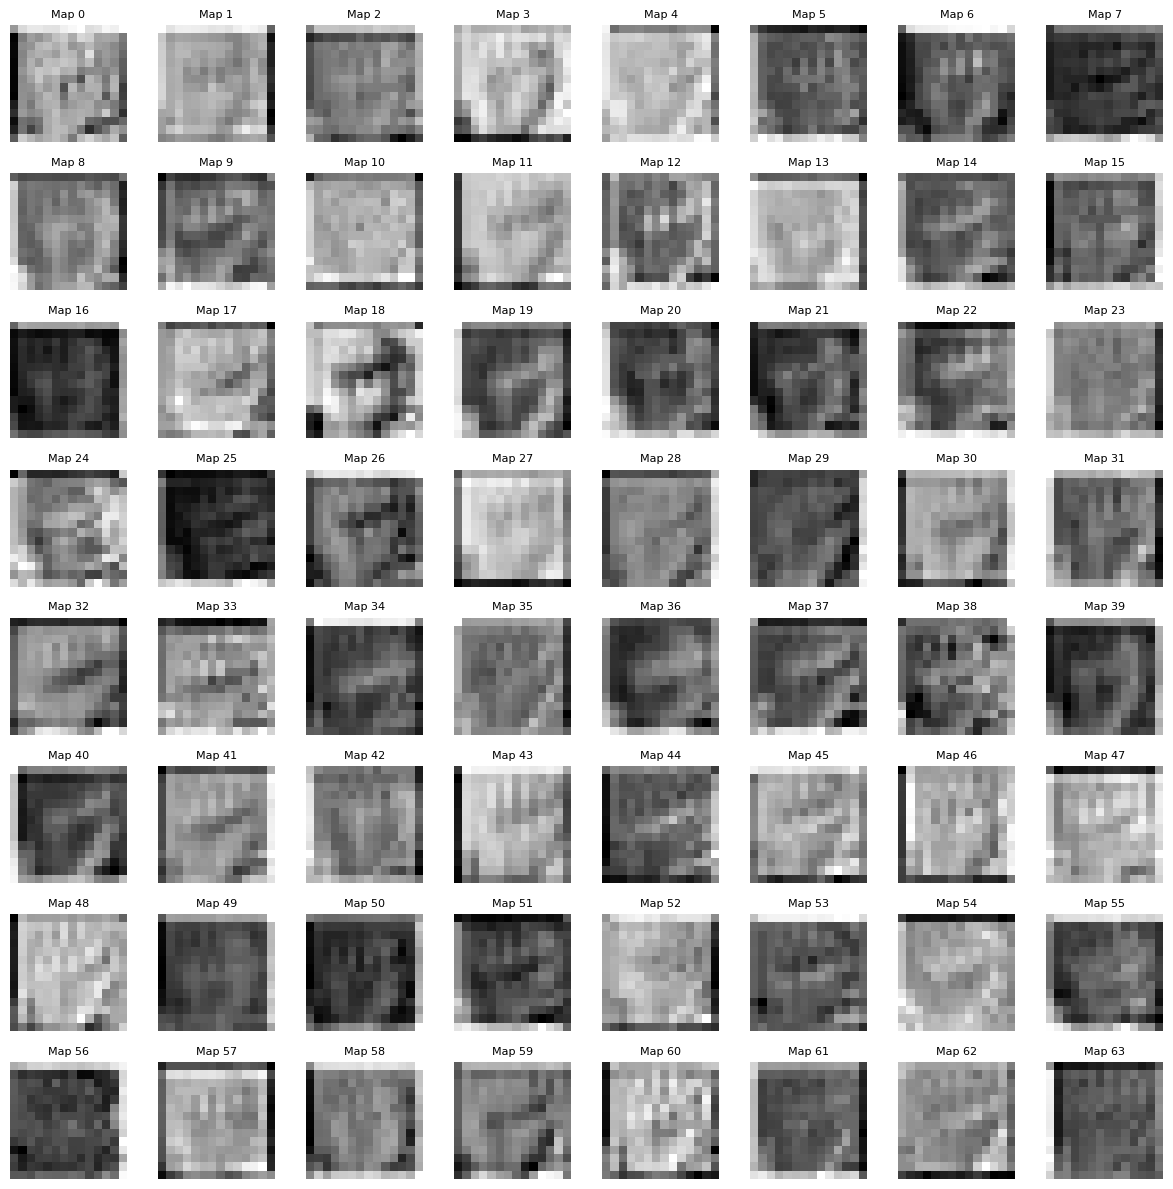

Dimension: torch.Size([1, 64, 14, 14])

-----AFTER RELU2 IMAGE-----


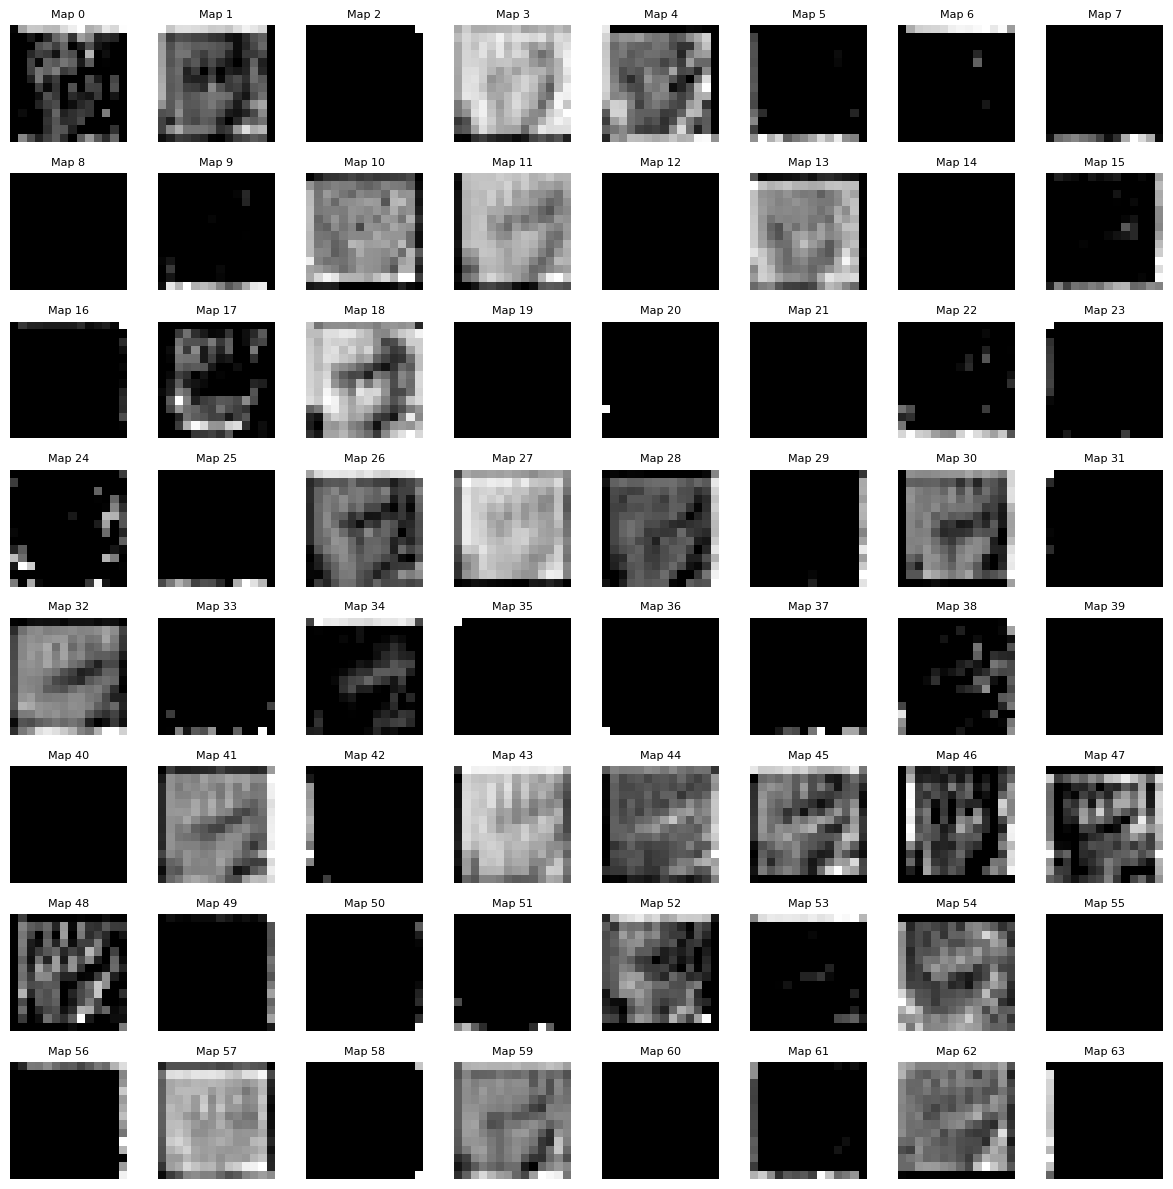

Dimension: torch.Size([1, 64, 14, 14])

-----AFTER POOL2 IMAGE-----


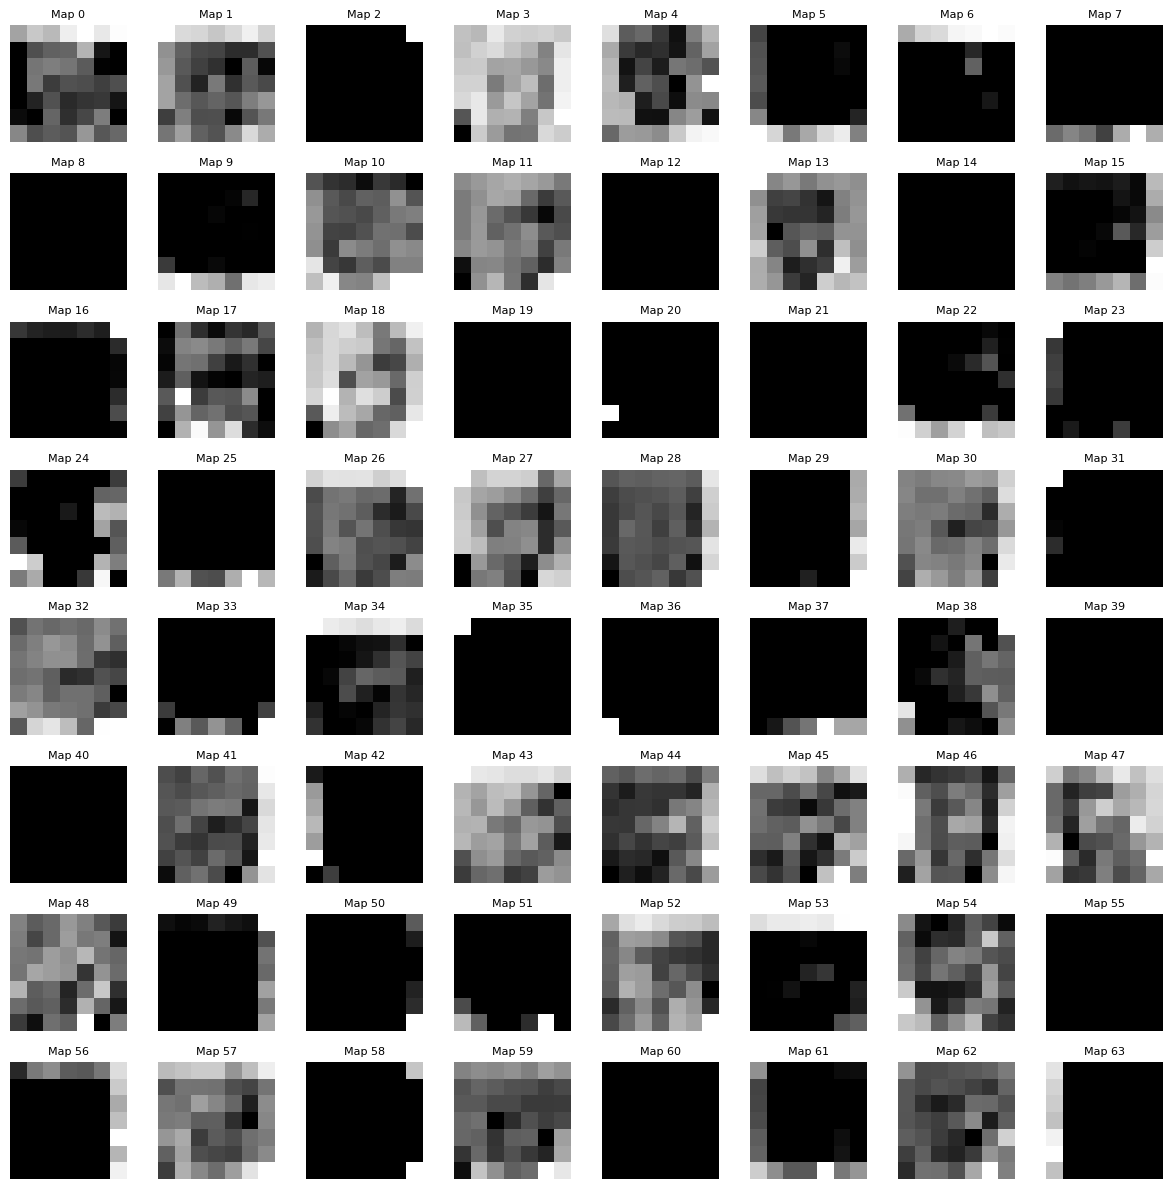

Dimension: torch.Size([1, 64, 7, 7])

-----AFTER CONV3 IMAGE-----


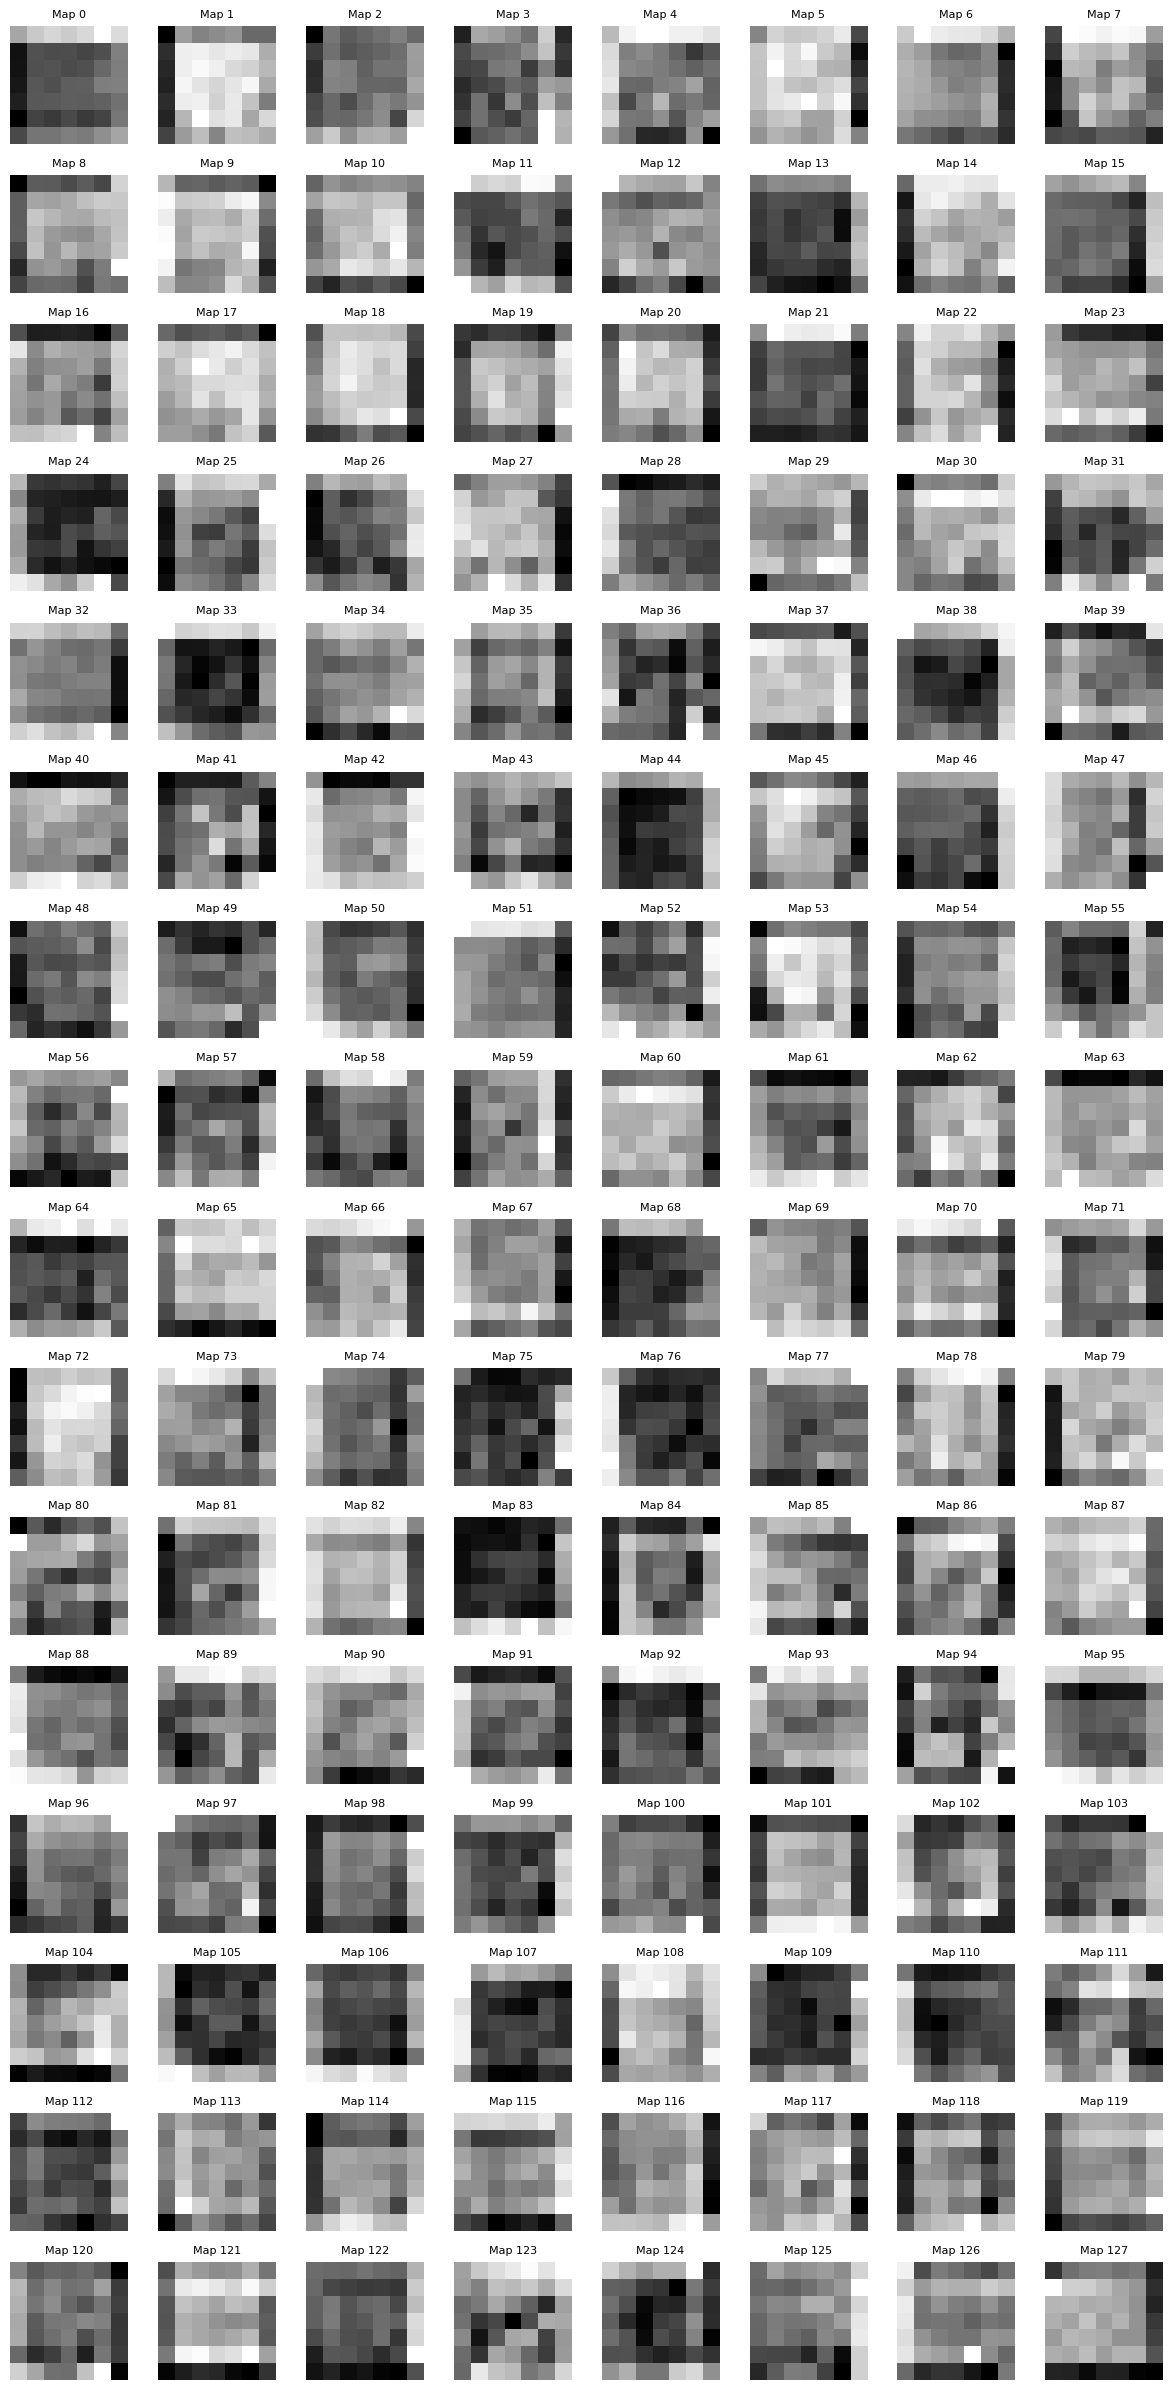

Dimension: torch.Size([1, 128, 7, 7])

-----AFTER RELU3 IMAGE-----


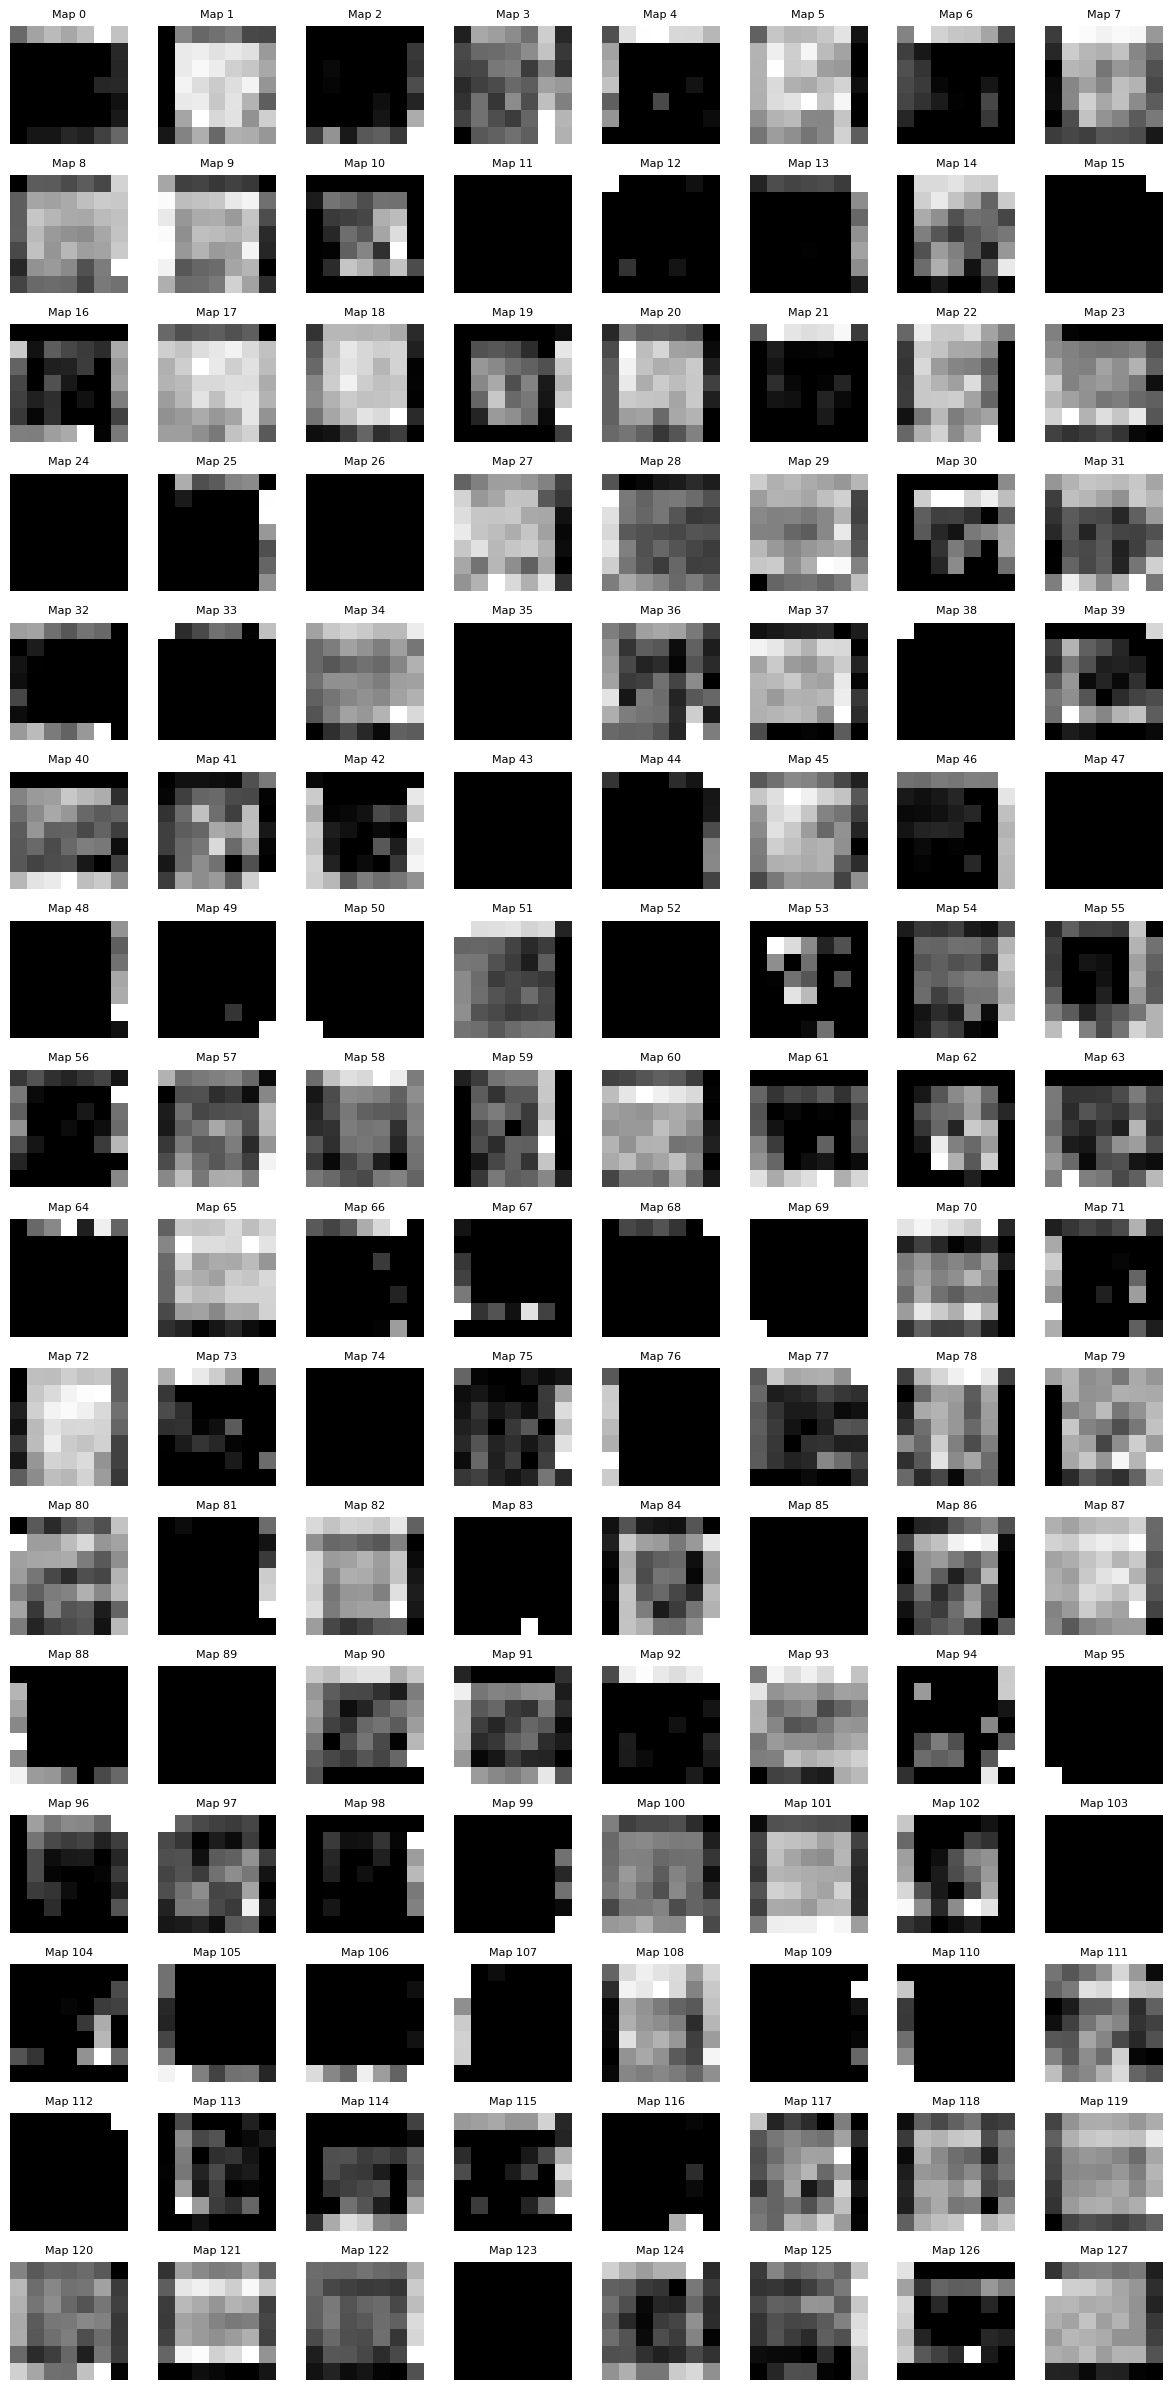

Dimension: torch.Size([1, 128, 7, 7])

-----AFTER POOL3 IMAGE-----


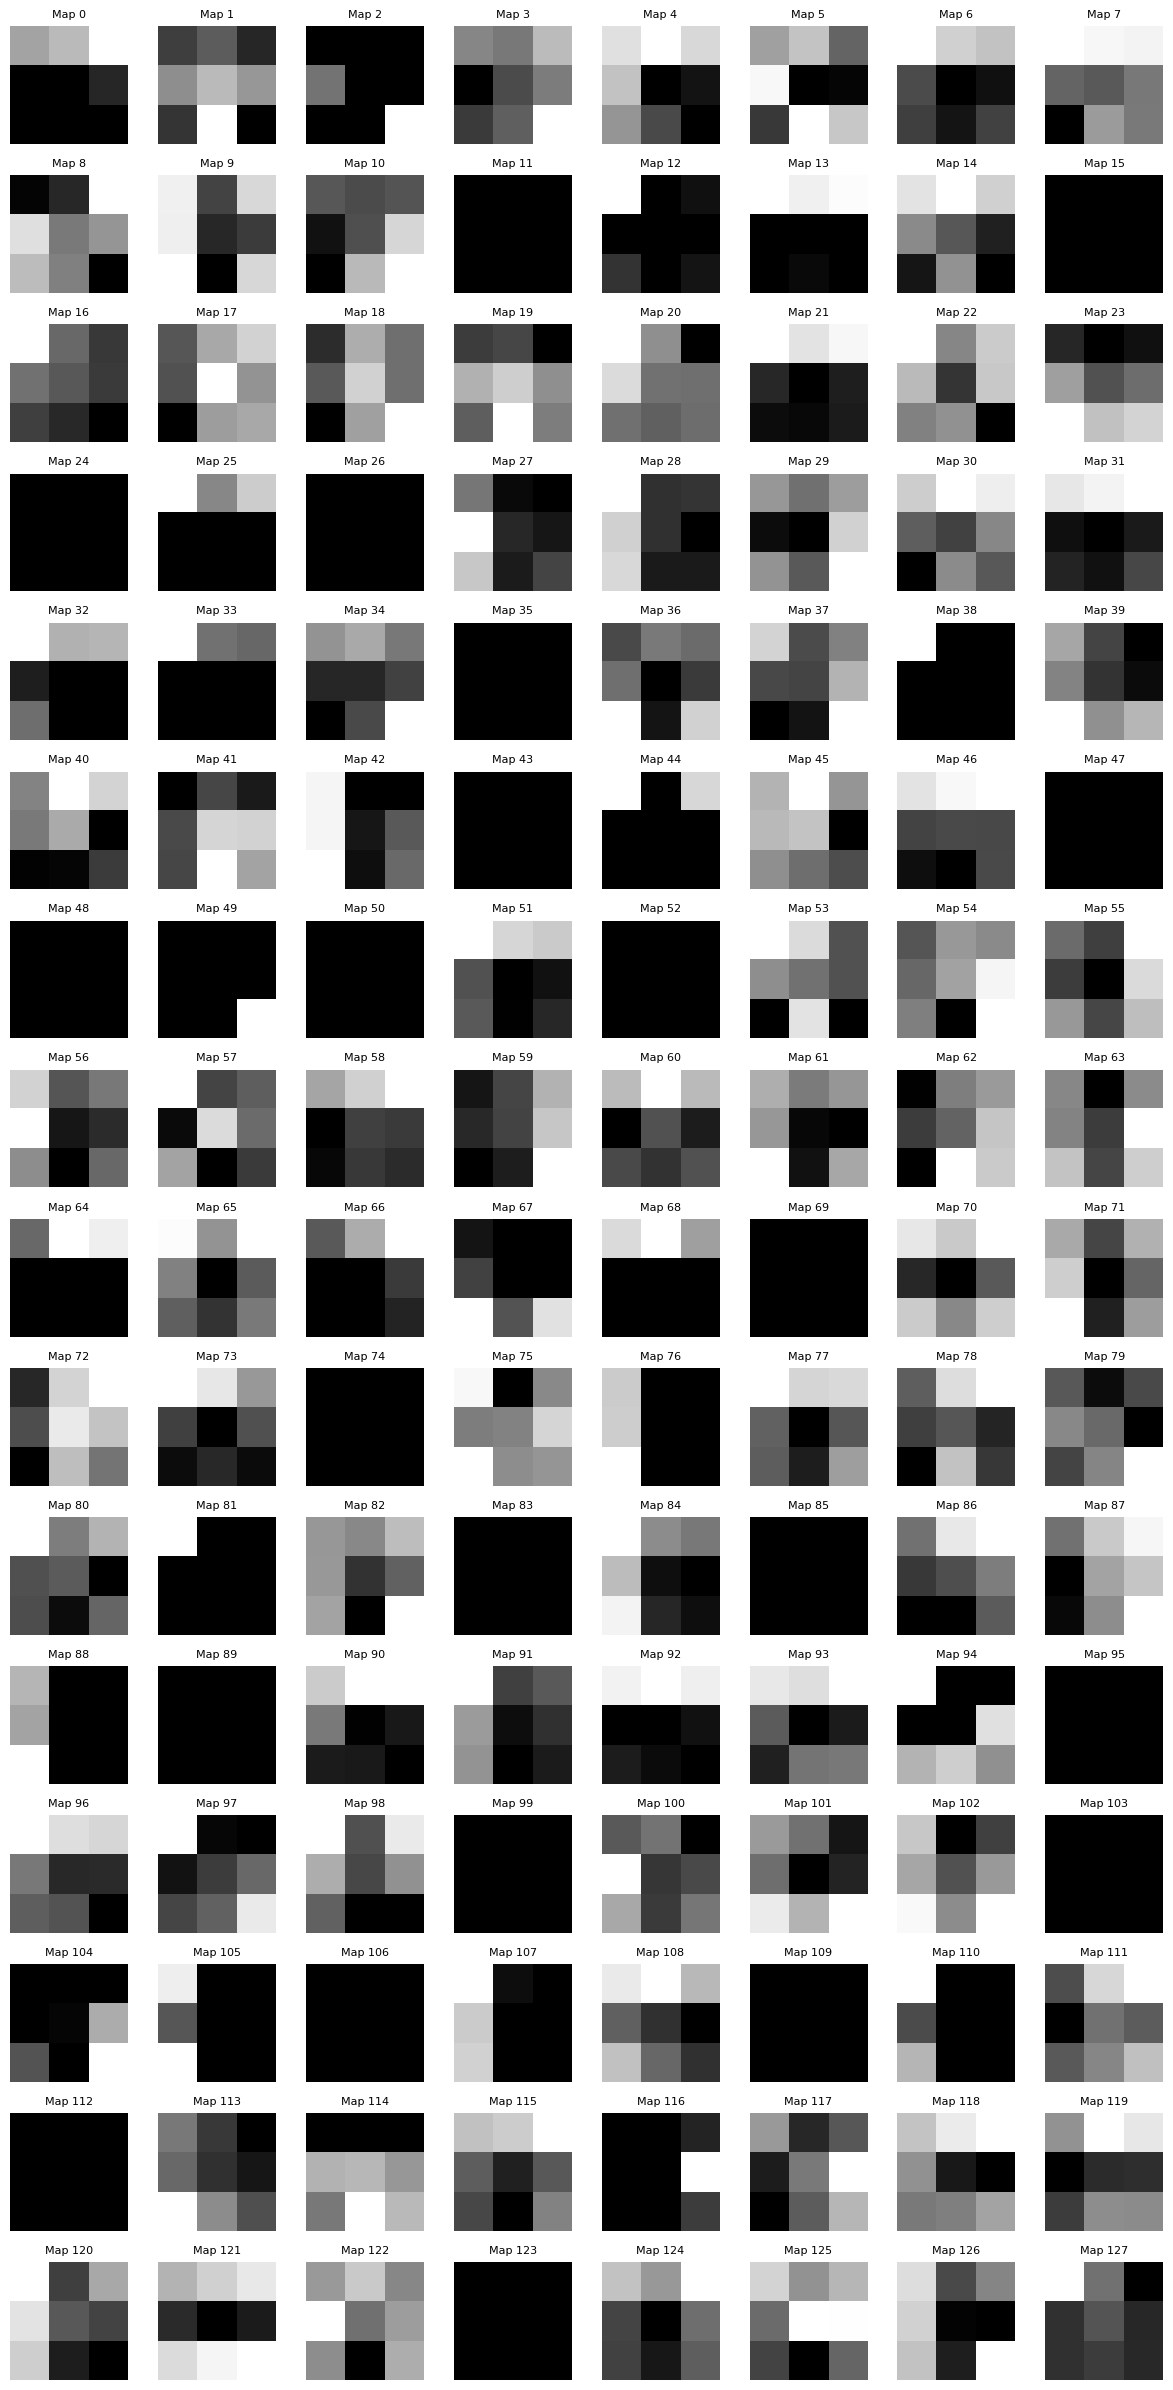

Dimension: torch.Size([1, 128, 3, 3])


In [ ]:
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset, DataLoader
import numpy as np
import torch.nn as nn

# Redefine for local scope if the cell is run independently
# otherwise, it should be available from j1VgweClW3n8
SELECTED_CLASSES = [0,1,2]
label_map = {0:0, 1:1, 2:2}

test_df_raw = pd.read_csv("sign_mnist_test.csv")
test_df_filtered = test_df_raw[test_df_raw["label"].isin(SELECTED_CLASSES)].copy()
test_df_filtered["label"] = test_df_filtered["label"].map(label_map)


class SignCNN(nn.Module):

    def __init__(self):

        super().__init__()

        # 1*28*28
        self.features1 = nn.Sequential(
            nn.Conv2d(
                in_channels=1,
                out_channels=32,
                kernel_size=3,
                padding=1
            )
        )
        self.features2 = nn.Sequential(
            nn.ReLU()
        )
        self.features3 = nn.Sequential(
            nn.MaxPool2d(2)
        )

        self.features4 = nn.Sequential(
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            )
        )
        self.features5 = nn.Sequential(
            nn.ReLU()
        )
        self.features6 = nn.Sequential(
            nn.MaxPool2d(2)
        )

        self.features7 = nn.Sequential(
            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            )
        )
        self.features8 = nn.Sequential(
            nn.ReLU()
        )
        self.features9 = nn.Sequential(
            nn.MaxPool2d(2)
        )

        self.classifier1 = nn.Sequential(
            # 128*3*3
            nn.Flatten()
        )

        self.classifier2 = nn.Sequential(
            nn.Linear(128 * 3 * 3, 256)
        )
        self.classifier3 = nn.Sequential(
            nn.ReLU()
        )

        self.classifier4 = nn.Sequential(
            nn.Dropout(0.5)
        )

        self.classifier5 = nn.Sequential(
            nn.Linear(256, 3)
        )

    def forward(self,x):

        x1 = self.features1(x)
        x2 = self.features2(x1)
        x3 = self.features3(x2)
        x4 = self.features4(x3)
        x5 = self.features5(x4)
        x6 = self.features6(x5)
        x7 = self.features7(x6)
        x8 = self.features8(x7)
        x9 = self.features9(x8)

        x10 = self.classifier1(x9)
        x11 = self.classifier2(x10)
        x12 = self.classifier3(x11)
        x13 = self.classifier4(x12)
        x14 = self.classifier5(x13)

        return x, x1, x2, x3, x4, x5, x6, x7, x8, x9, x10, x11, x12, x13, x14


class SignDataset(Dataset):

    def __init__(self, df):

        self.labels = df["label"].values

        self.images = (
            df.drop("label", axis=1)
            .values
            .reshape(-1,28,28)
            .astype(np.float32)
            /255.0
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        image = torch.tensor(
            self.images[idx]
        ).unsqueeze(0)

        label = torch.tensor(
            self.labels[idx]
        ).long()

        return image, label


test_ds = SignDataset(test_df_filtered)
img, lab = test_ds.__getitem__(0)
img_batched = img.unsqueeze(0)


model = SignCNN()
# image0, image1, image2, image3, image4, image5, image6, image7, image8, image9, image10, image11, image12, image13, image14 = model(img_batched)
outputs = model(img_batched)

# for i, output in enumerate(outputs):
#     print(f"image{i}: {output.shape}")


def get_feature_maps(images):
    output_numpy = images.detach().cpu().numpy()
    # print(output_numpy[0, 0])
    # print(output_numpy[0, 1])
    fig, axes = plt.subplots(nrows=4, ncols=8, figsize=(12, 6))
    for i in range(32):
        row = i // 8
        col = i % 8
        feature_map = output_numpy[0, i]
        axes[row, col].imshow(feature_map, cmap='gray')
        axes[row, col].axis('off')
        axes[row, col].set_title(f"Map {i}", fontsize=8)
    plt.tight_layout()
    plt.show()

def get_feature_maps2(images):
    output_numpy = images.detach().cpu().numpy()
    # print(output_numpy[0, 0])
    # print(output_numpy[0, 1])
    fig, axes = plt.subplots(nrows=8, ncols=8, figsize=(12, 12))
    for i in range(64):
        row = i // 8
        col = i % 8
        feature_map = output_numpy[0, i]
        axes[row, col].imshow(feature_map, cmap='gray')
        axes[row, col].axis('off')
        axes[row, col].set_title(f"Map {i}", fontsize=8)
    plt.tight_layout()
    plt.show()

def get_feature_maps3(images):
    output_numpy = images.detach().cpu().numpy()
    # print(output_numpy[0, 0])
    # print(output_numpy[0, 1])
    fig, axes = plt.subplots(nrows=16, ncols=8, figsize=(12, 24))
    for i in range(128):
        row = i // 8
        col = i % 8
        feature_map = output_numpy[0, i]
        axes[row, col].imshow(feature_map, cmap='gray')
        axes[row, col].axis('off')
        axes[row, col].set_title(f"Map {i}", fontsize=8)
    plt.tight_layout()
    plt.show()


# torch.set_printoptions(profile="full")
print("-----INPUT IMAGE-----")
print(f"LABEL: {lab}")
plt.imshow(outputs[0].reshape(28,28), cmap='gray')
plt.show()
print(f"Dimension: {outputs[0].shape}")

print()
print("-----AFTER CONV1 IMAGE-----")
get_feature_maps(outputs[1])
# print(outputs[1][0])
print(f"Dimension: {outputs[1].shape}")

print()
print("-----AFTER RELU1 IMAGE-----")
get_feature_maps(outputs[2])
# print(outputs[2][0])
print(f"Dimension: {outputs[2].shape}")

print()
print("-----AFTER POOL1 IMAGE-----")
get_feature_maps(outputs[3])
# print(outputs[3][0])
print(f"Dimension: {outputs[3].shape}")

print()
print("-----AFTER CONV2 IMAGE-----")
get_feature_maps2(outputs[4])
# print(outputs[1][0])
print(f"Dimension: {outputs[4].shape}")

print()
print("-----AFTER RELU2 IMAGE-----")
get_feature_maps2(outputs[5])
# print(outputs[2][0])
print(f"Dimension: {outputs[5].shape}")

print()
print("-----AFTER POOL2 IMAGE-----")
get_feature_maps2(outputs[6])
# print(outputs[3][0])
print(f"Dimension: {outputs[6].shape}")

print()
print("-----AFTER CONV3 IMAGE-----")
get_feature_maps3(outputs[7])
# print(outputs[1][0])
print(f"Dimension: {outputs[7].shape}")

print()
print("-----AFTER RELU3 IMAGE-----")
get_feature_maps3(outputs[8])
# print(outputs[2][0])
print(f"Dimension: {outputs[8].shape}")

print()
print("-----AFTER POOL3 IMAGE-----")
get_feature_maps3(outputs[9])
# print(outputs[3][0])
print(f"Dimension: {outputs[9].shape}")

## classifier results

In [ ]:
# torch.set_printoptions(profile="full")

print()
print("-----AFTER FLATTEN IMAGE-----")
# get_feature_maps(outputs[10])
print(outputs[10][0])
print(f"Dimension: {outputs[10].shape}")

print()
print("-----AFTER LINEAR1 IMAGE-----")
# get_feature_maps(outputs[11])
print(outputs[11][0])
print(f"Dimension: {outputs[11].shape}")

print()
print("-----AFTER RELU4 IMAGE-----")
# get_feature_maps(outputs[12])
print(outputs[12][0])
print(f"Dimension: {outputs[12].shape}")

print()
print("-----AFTER DROPOUT IMAGE-----")
# get_feature_maps(outputs[13])
print(outputs[13][0])
print(f"Dimension: {outputs[13].shape}")

print()
print("-----AFTER LINEAR2 IMAGE-----")
# get_feature_maps(outputs[14])
print(outputs[14][0])
print(f"Dimension: {outputs[14].shape}")



-----AFTER FLATTEN IMAGE-----
tensor([0.1059, 0.1207, 0.1655,  ..., 0.1264, 0.1286, 0.1250],
       grad_fn=<SelectBackward0>)
Dimension: torch.Size([1, 1152])

-----AFTER LINEAR1 IMAGE-----
tensor([ 0.0138,  0.0313, -0.0214,  0.1324,  0.0490, -0.0460,  0.0738,  0.0167,
        -0.1275, -0.0128, -0.0346,  0.0313,  0.0304,  0.0728, -0.0193, -0.0334,
         0.0656,  0.0683, -0.0259, -0.0245, -0.0194,  0.0407, -0.0222, -0.0189,
         0.0098,  0.0349,  0.0213, -0.0549,  0.0076,  0.0171,  0.0188,  0.0460,
        -0.0293,  0.0204, -0.0067, -0.0208, -0.0154, -0.1109,  0.0240,  0.0380,
        -0.0067, -0.0247, -0.0163,  0.0847,  0.0449, -0.0261, -0.0172, -0.0094,
         0.0204,  0.0034, -0.0445, -0.0323, -0.0679, -0.0087,  0.0021, -0.0246,
         0.0669,  0.0190,  0.0027,  0.0033, -0.0284,  0.0513, -0.0574,  0.0904,
        -0.0225,  0.0404,  0.0764, -0.0607, -0.0331,  0.0128, -0.0521, -0.0002,
        -0.0011, -0.0239, -0.0339,  0.0627, -0.0056, -0.0874, -0.0189,  0.0267,
        

## softmax

In [ ]:
print("\n========== SOFTMAX ==========")

probabilities = torch.softmax(
    outputs[14][0],
    dim=0
)

for i, probability in enumerate(probabilities):
    print(
        f"class{[i]}: "
        f"{probability.item():.6f}"
    )

print(
    "\nProbability sum:",
    probabilities.sum().item()
)



========== SOFTMAX ==========
class[0]: 0.307300
class[1]: 0.339566
class[2]: 0.353135

Probability sum: 1.0


## loss calculation

In [ ]:
print(lab)

tensor(0)


In [ ]:
criterion = nn.CrossEntropyLoss()
logits = outputs[14][0]

target = torch.tensor(
    lab.item(),
    dtype=torch.long
)

loss = criterion(
    logits,
    target
)

print("\n========== LOSS CALCULATION ==========")

print("Logits:")
print(logits)

print("\nTarget:")
print(target)

print("\nSoftmax probabilities:")
print(probabilities)

print(
    "\nCross Entropy Loss:",
    loss.item()
)



========== LOSS CALCULATION ==========
Logits:
tensor([-0.0727,  0.0271,  0.0663], grad_fn=<SelectBackward0>)

Target:
tensor(0)

Softmax probabilities:
tensor([0.3073, 0.3396, 0.3531], grad_fn=<SoftmaxBackward0>)

Cross Entropy Loss: 1.1799321174621582


In [ ]:
# linear_layer = nn.Linear(20, 30)
# print("Weights:")
# print(linear_layer.weight)
# print(len(linear_layer.weight))
# print(len(linear_layer.weight[0]))
# print(max(linear_layer.weight[0]))
# print(min(linear_layer.weight[0]))
# print("\nBiases:")
# print(linear_layer.bias)
# print(len(linear_layer.bias))
# print(max(linear_layer.bias))
# print(min(linear_layer.bias))

# test

Device: cpu

Model created.
SignCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1152, out_features=256, bias=True)
  (relu4): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=3, bias=True)
)


              TRAINING PIPELINE DEMONSTRATION
Epochs: 2
Batch size: 64
Learning rate: 0.001



################################################################################
          

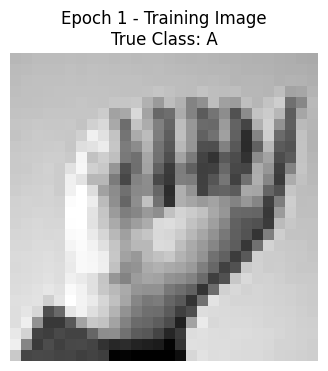



FORWARD PASS - EPOCH 1
input      Shape: (64, 1, 28, 28)      Mean:  0.605586 Min:  0.000000 Max:  1.000000
conv1      Shape: (64, 32, 28, 28)     Mean: -0.043528 Min: -1.583450 Max:  1.129587
relu1      Shape: (64, 32, 28, 28)     Mean:  0.131061 Min:  0.000000 Max:  1.129587
pool1      Shape: (64, 32, 14, 14)     Mean:  0.158204 Min:  0.000000 Max:  1.129587
conv2      Shape: (64, 64, 14, 14)     Mean: -0.006518 Min: -0.495999 Max:  0.585127
relu2      Shape: (64, 64, 14, 14)     Mean:  0.055567 Min:  0.000000 Max:  0.585127
pool2      Shape: (64, 64, 7, 7)       Mean:  0.072694 Min:  0.000000 Max:  0.585127
conv3      Shape: (64, 128, 7, 7)      Mean:  0.004218 Min: -0.393699 Max:  0.273530
relu3      Shape: (64, 128, 7, 7)      Mean:  0.029594 Min:  0.000000 Max:  0.273530
pool3      Shape: (64, 128, 3, 3)      Mean:  0.041872 Min:  0.000000 Max:  0.273530
flatten    Shape: (64, 1152)           Mean:  0.041872 Min:  0.000000 Max:  0.273530
fc1        Shape: (64, 256)            M

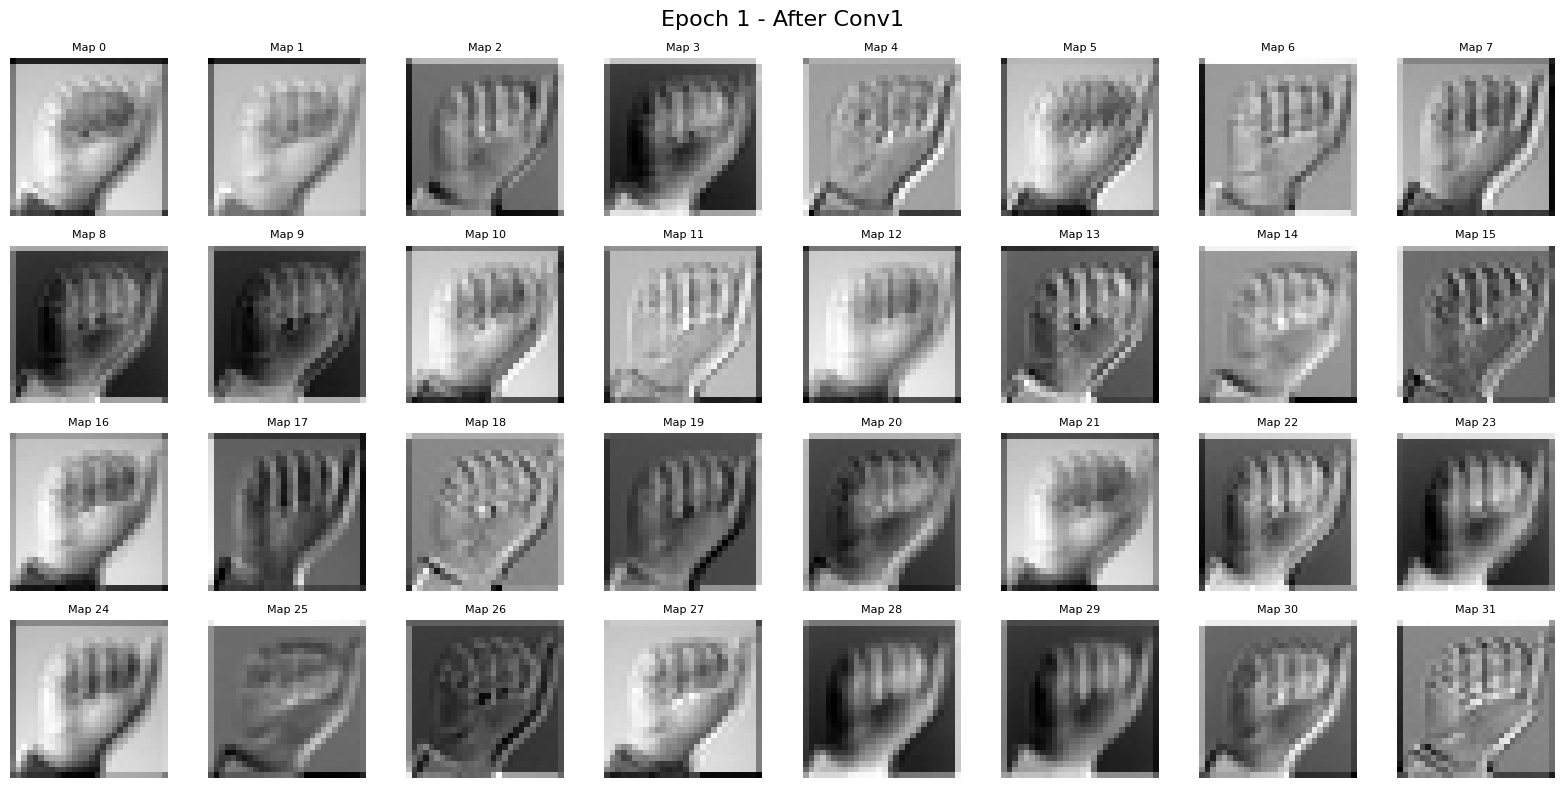

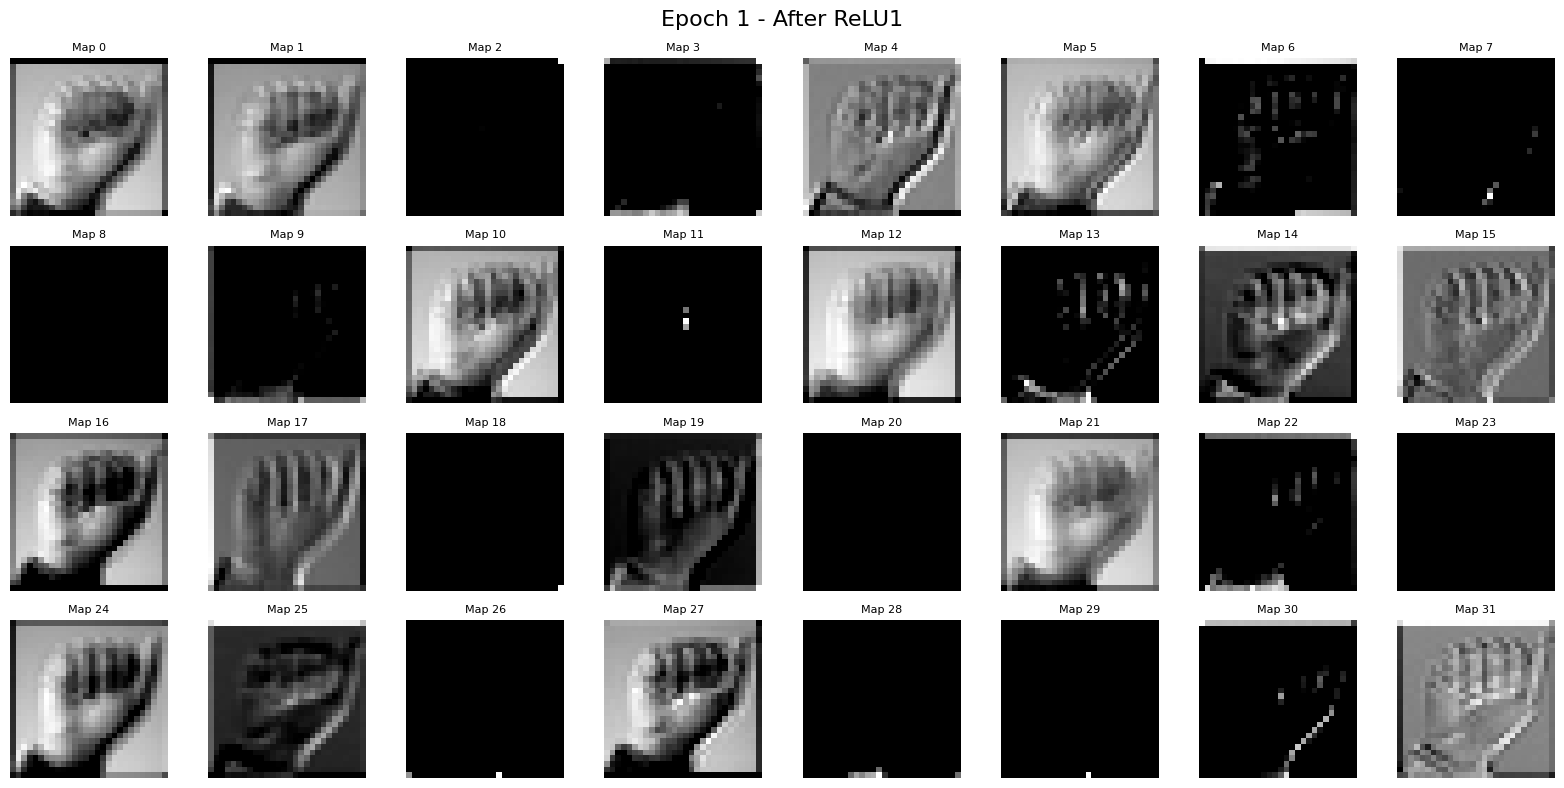

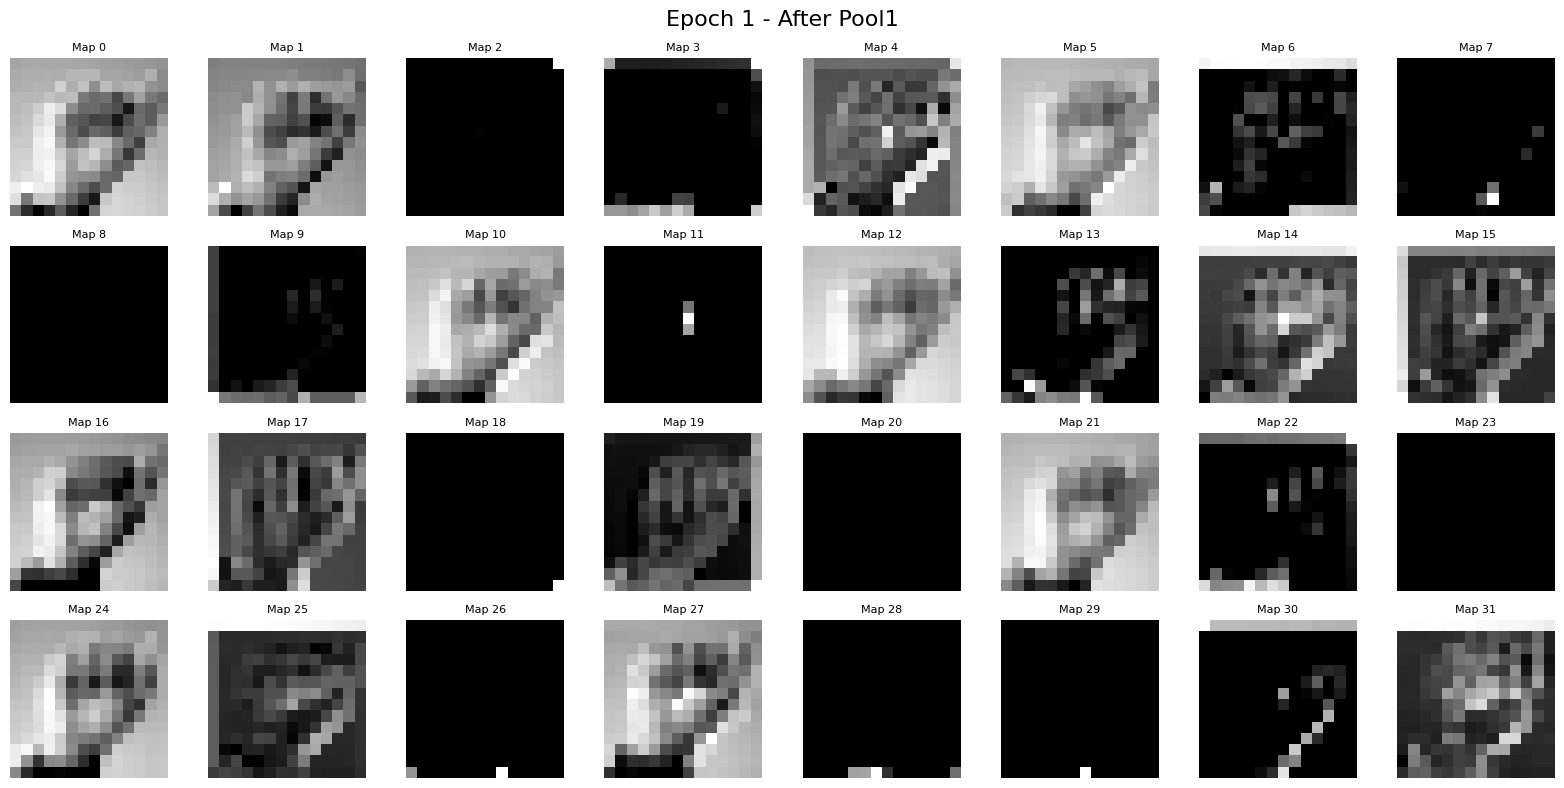

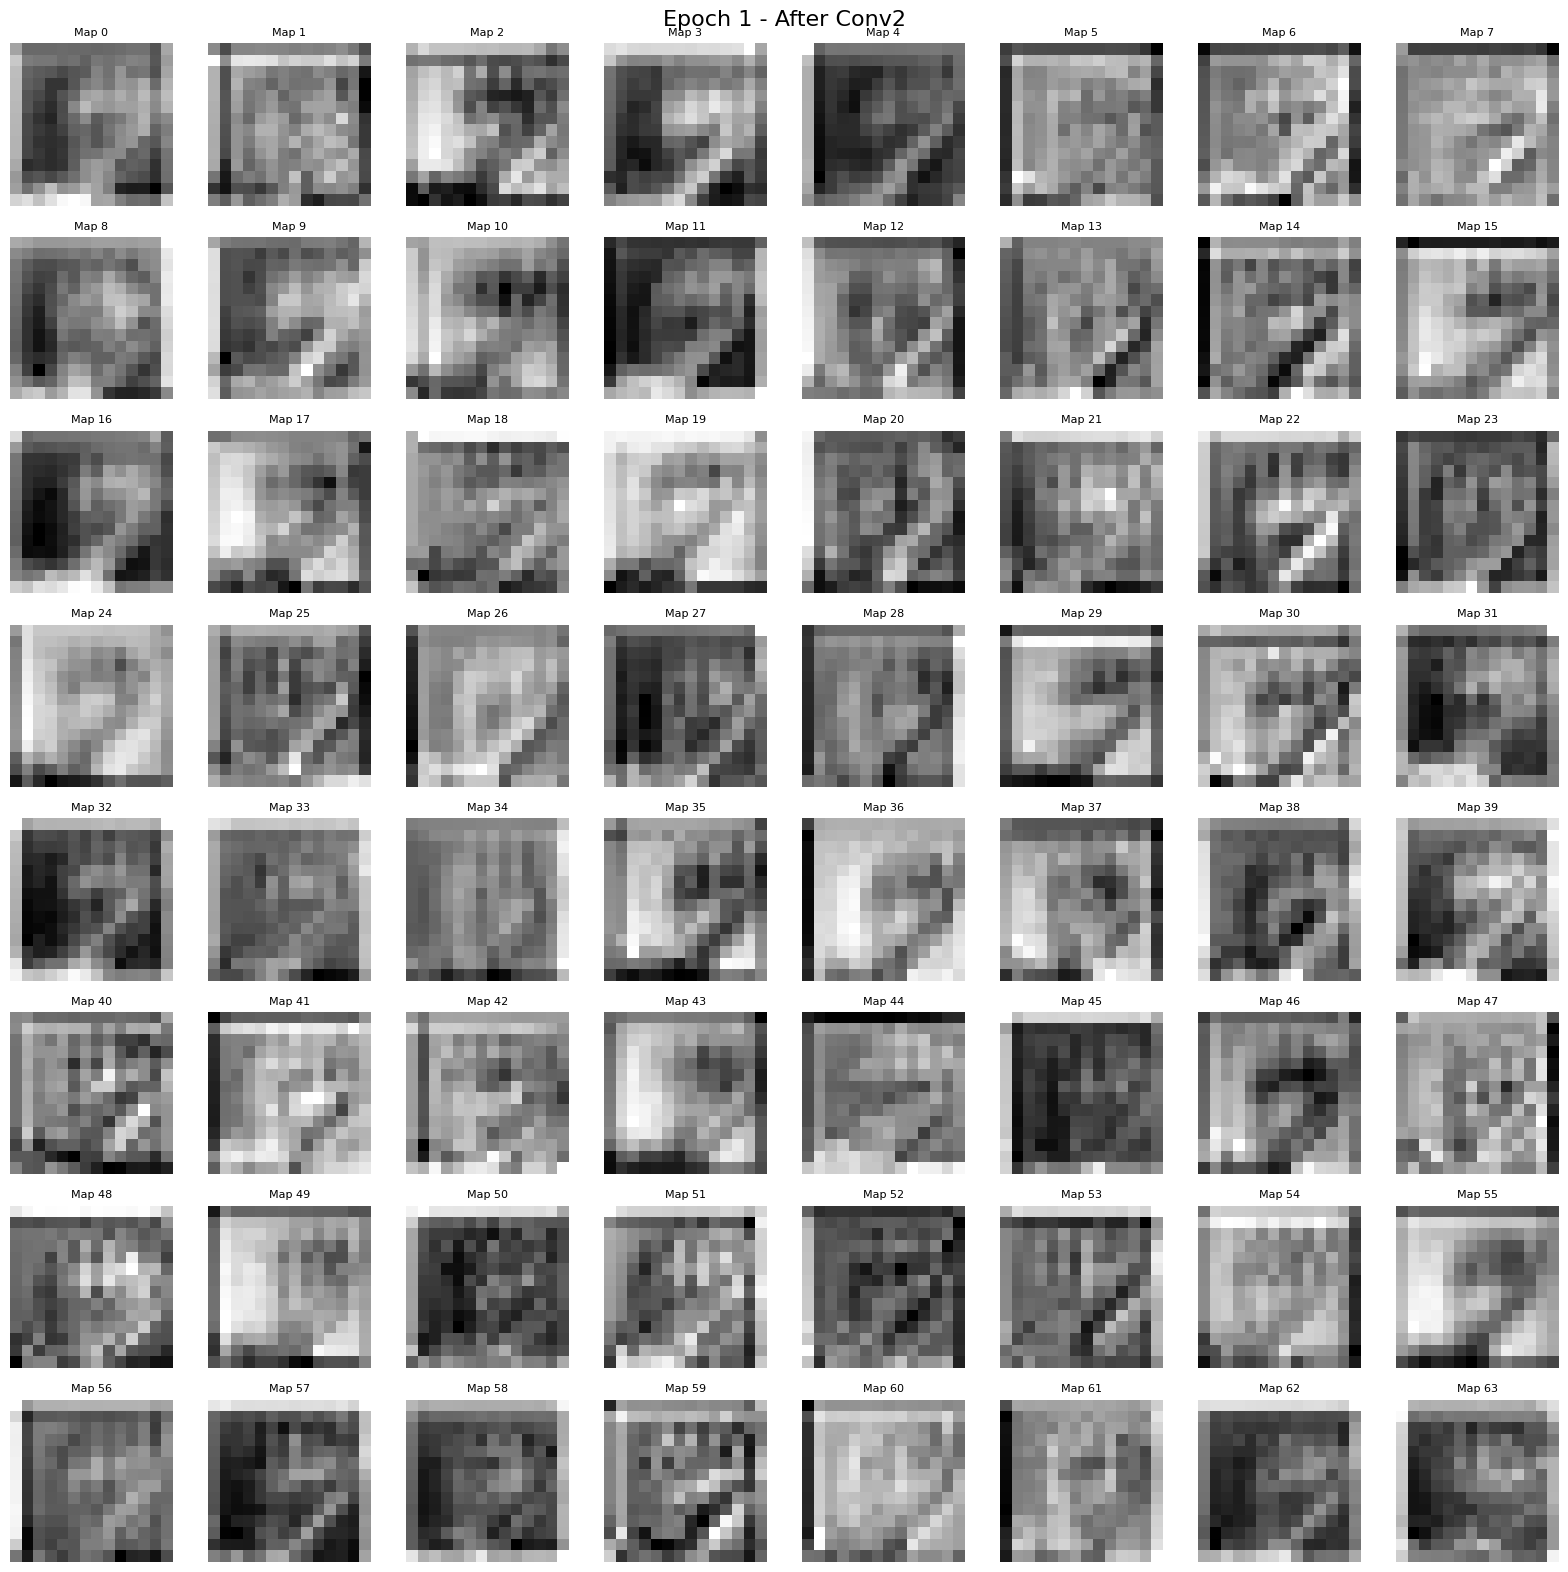

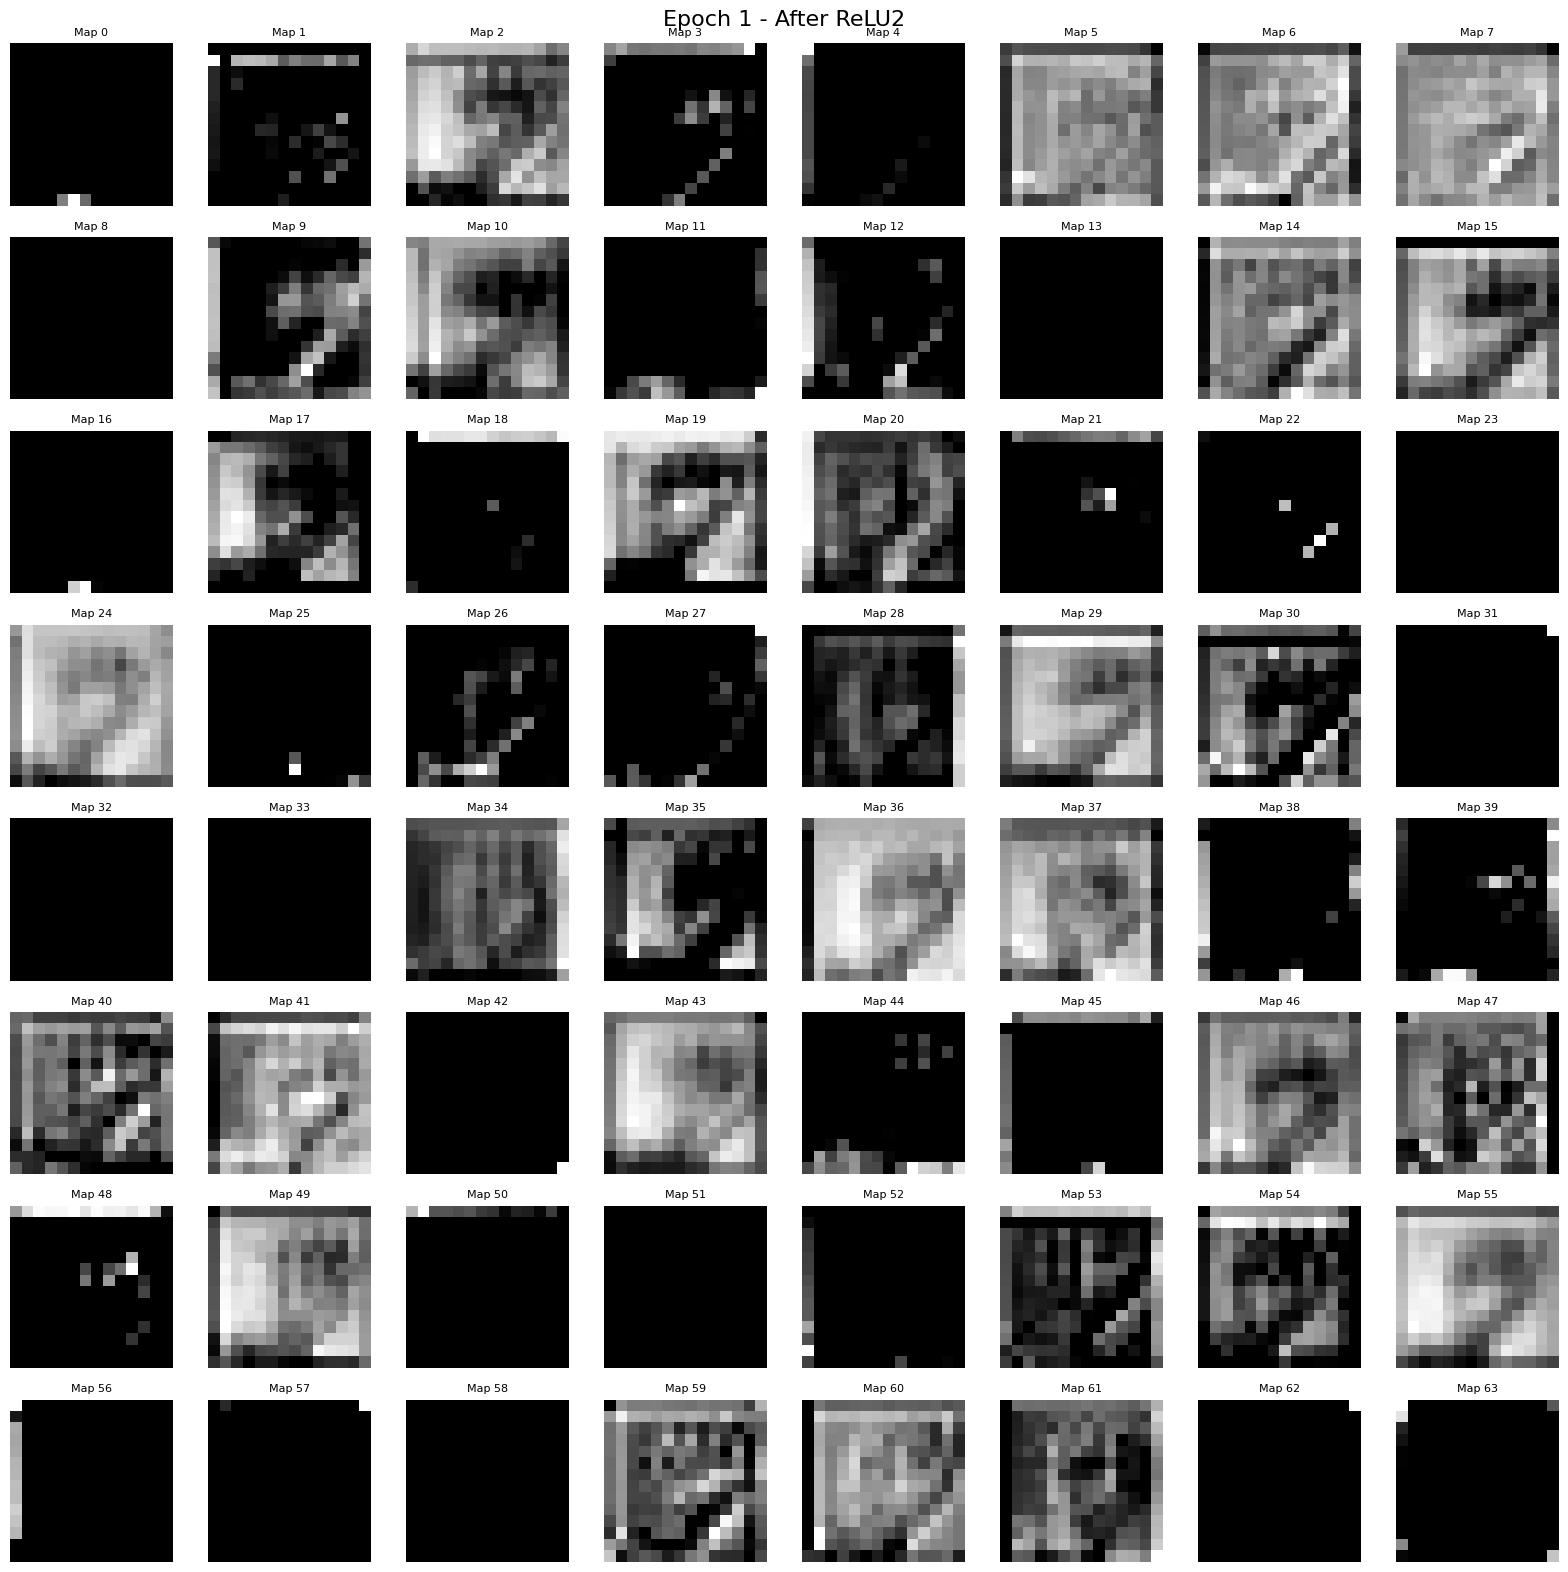

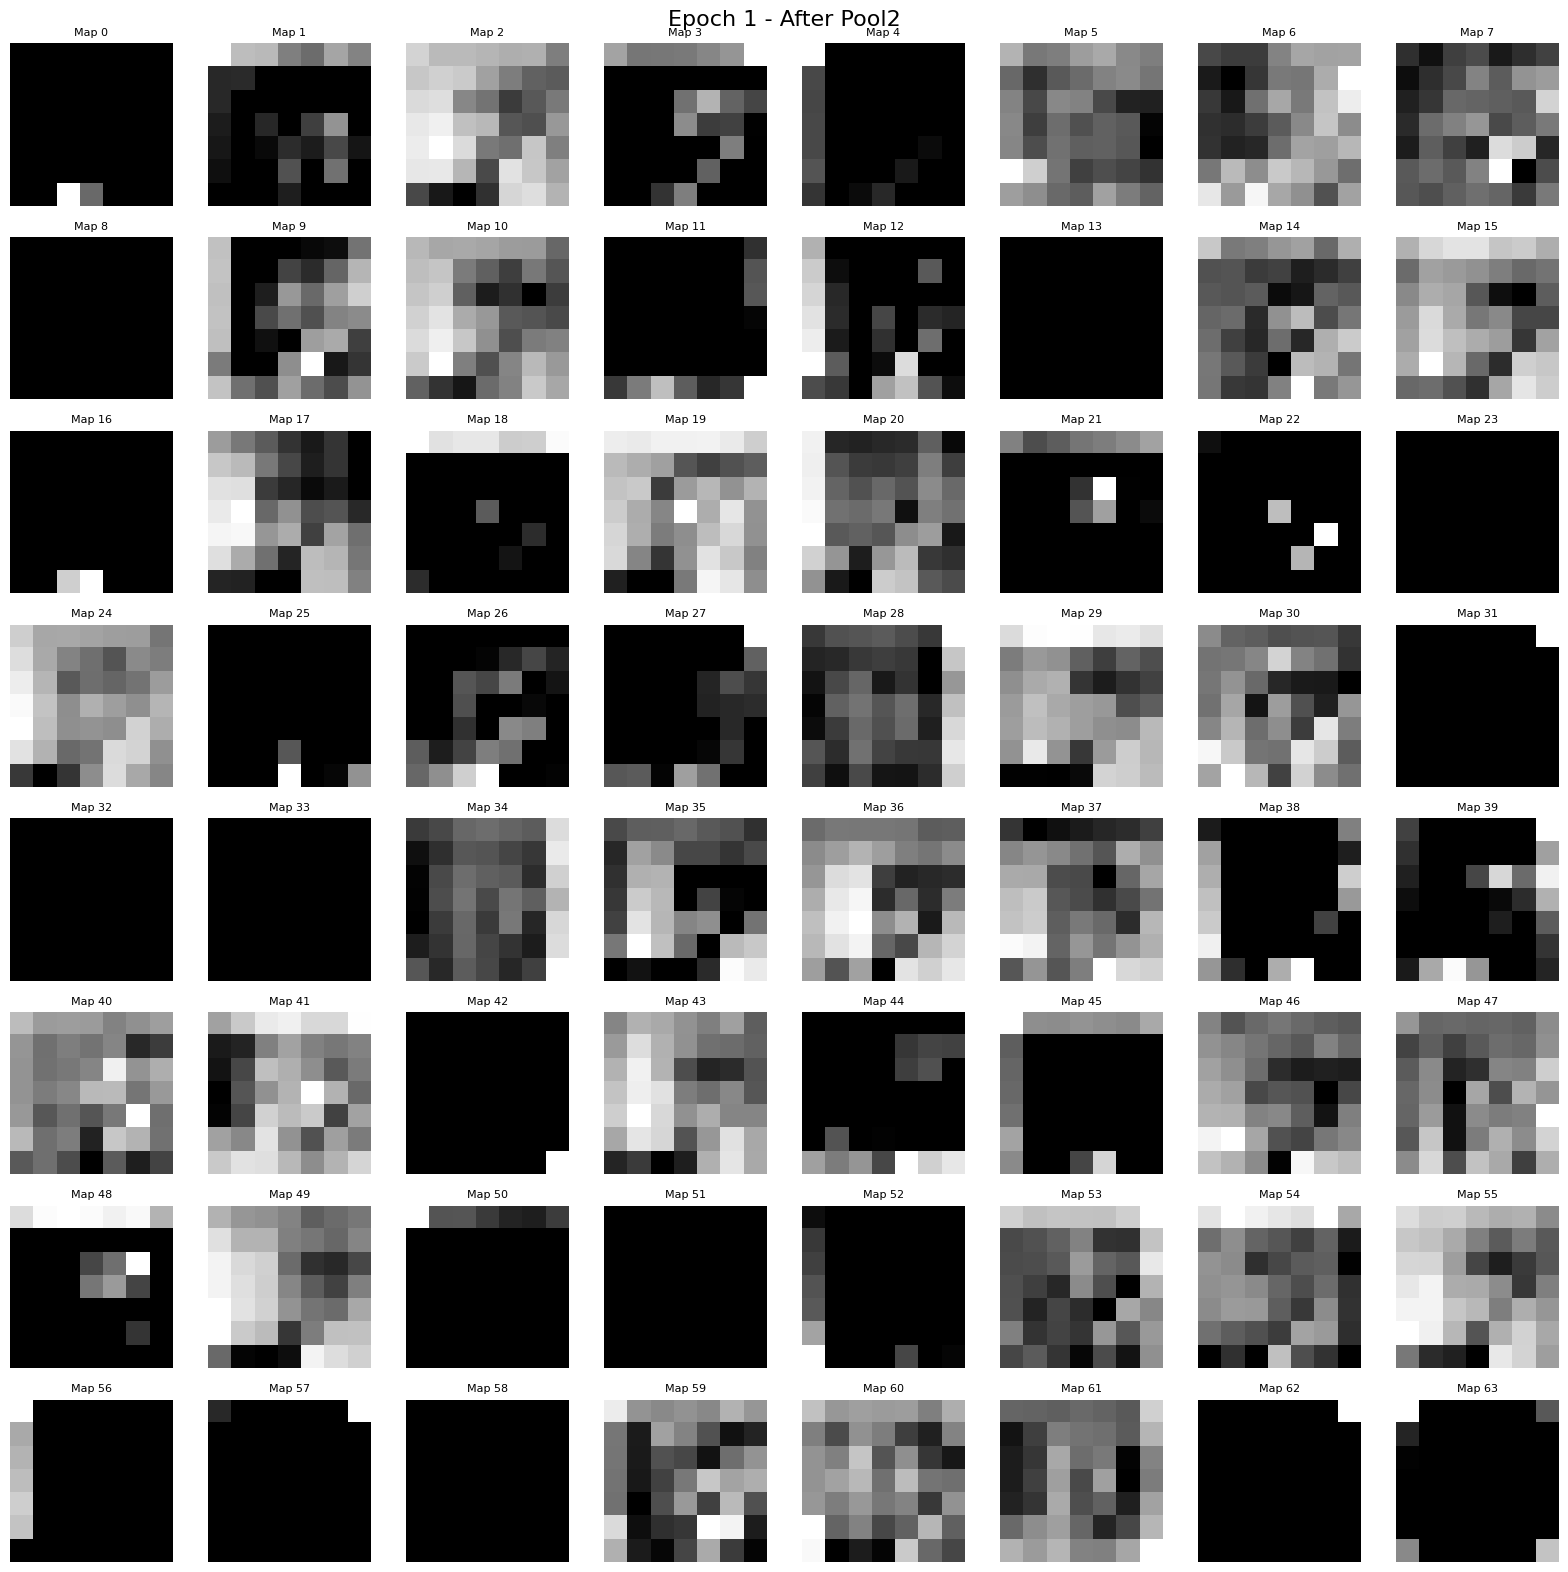

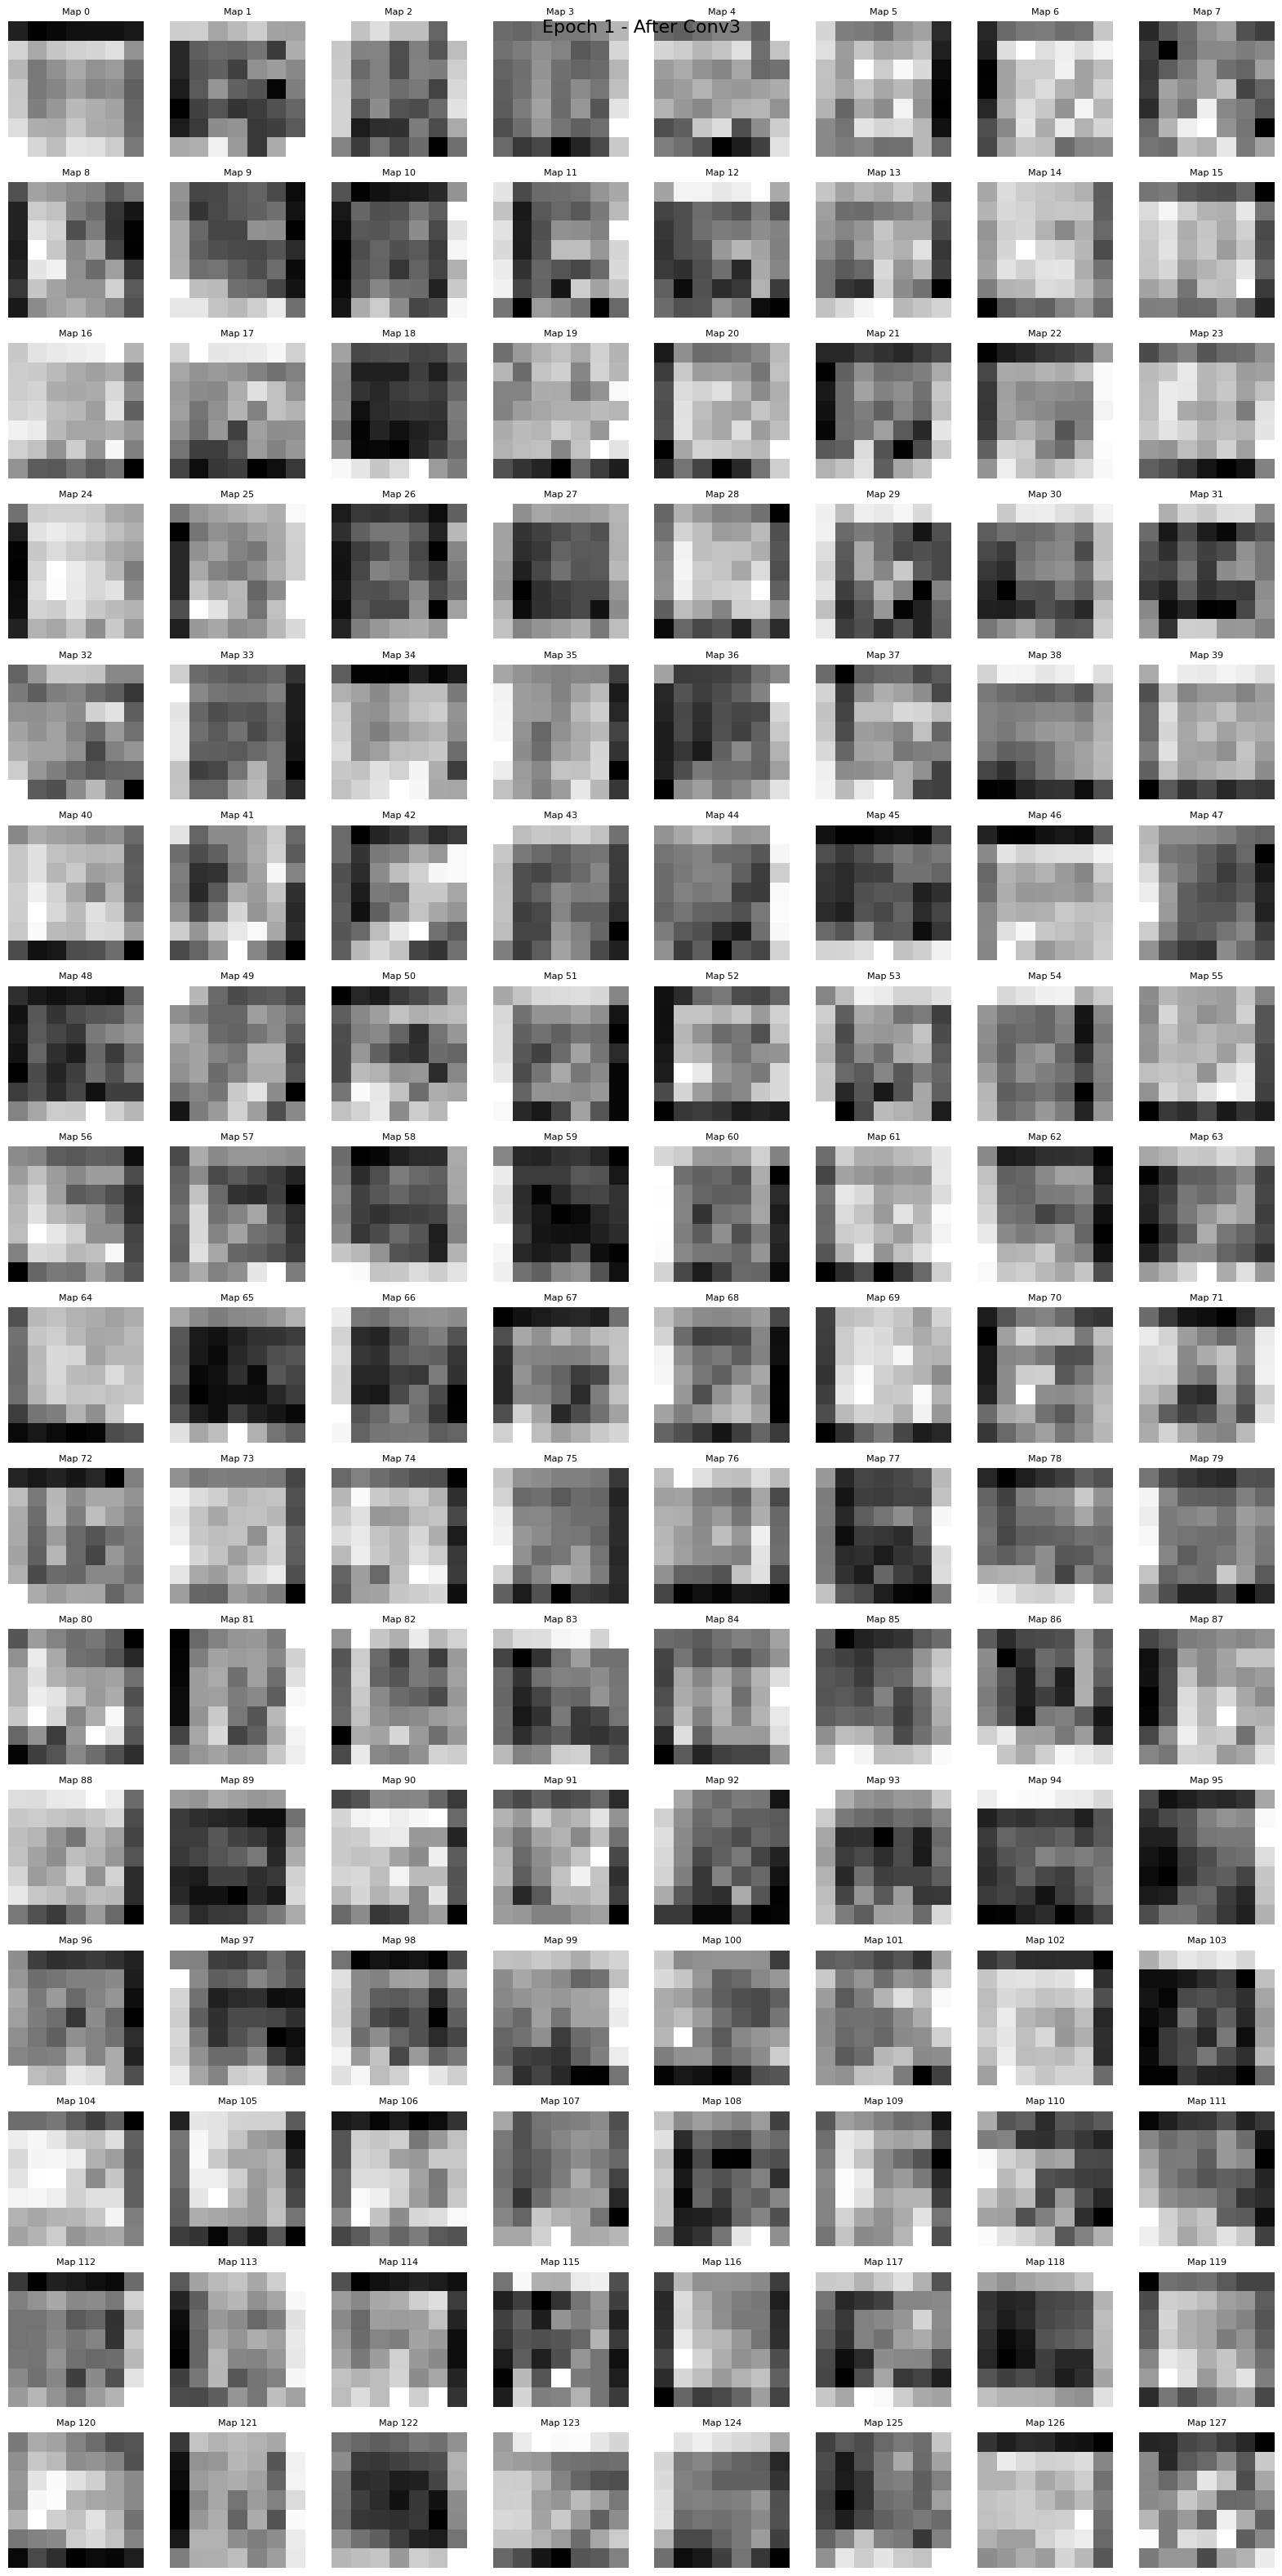

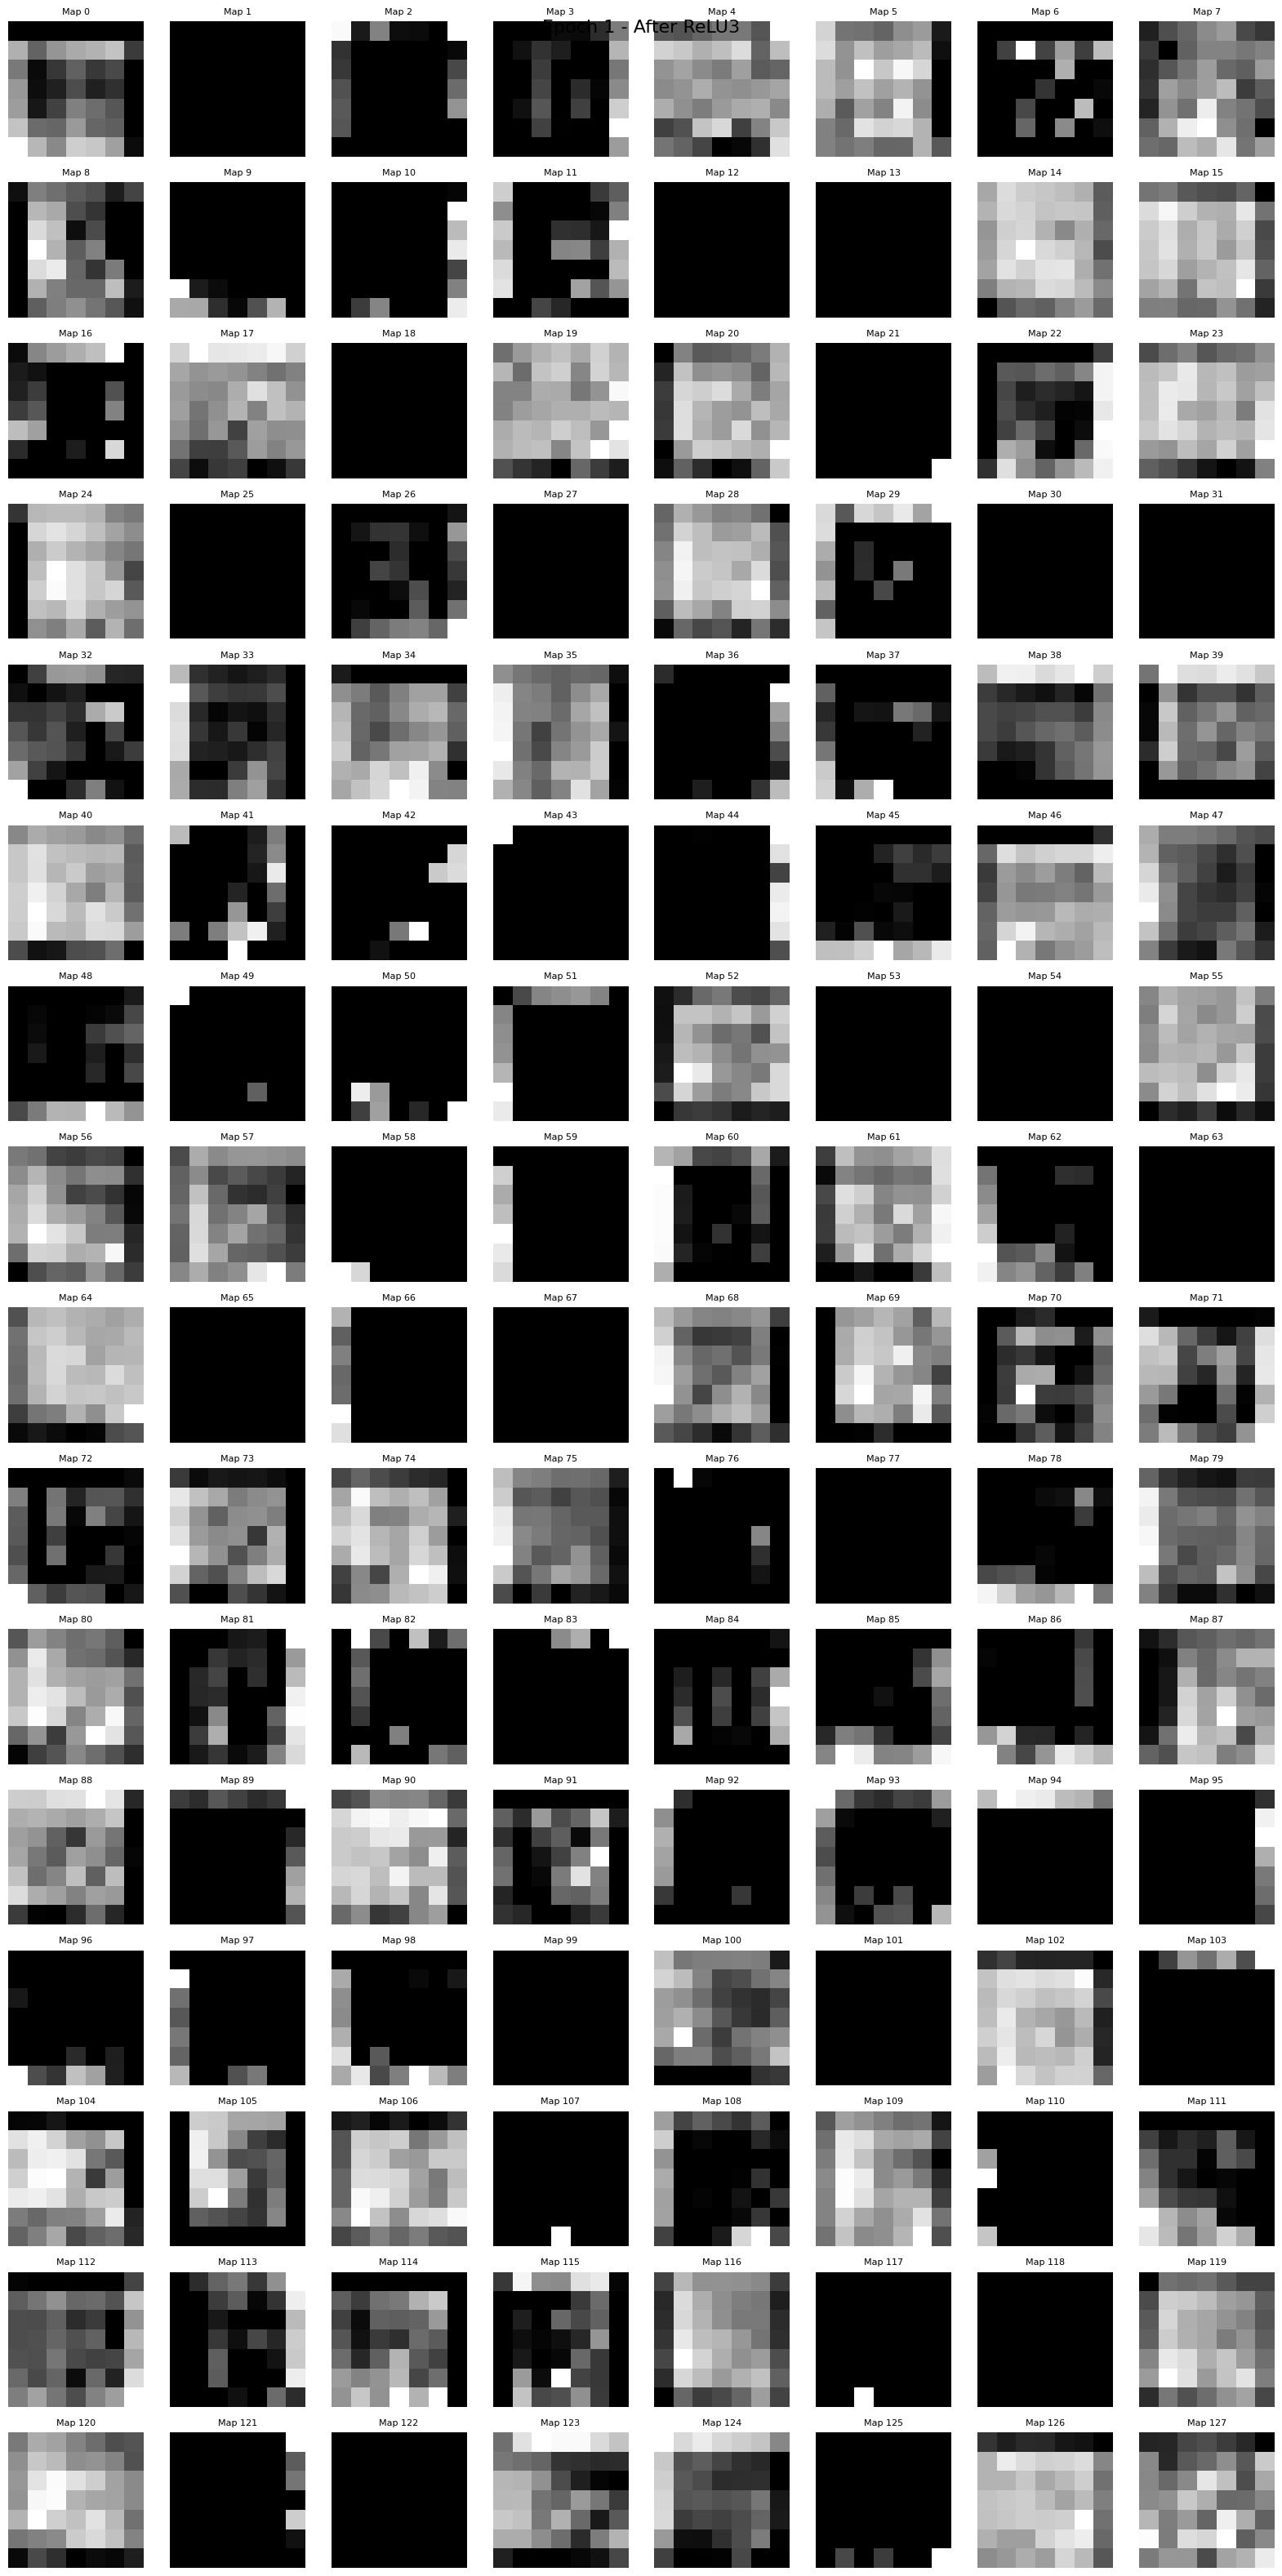

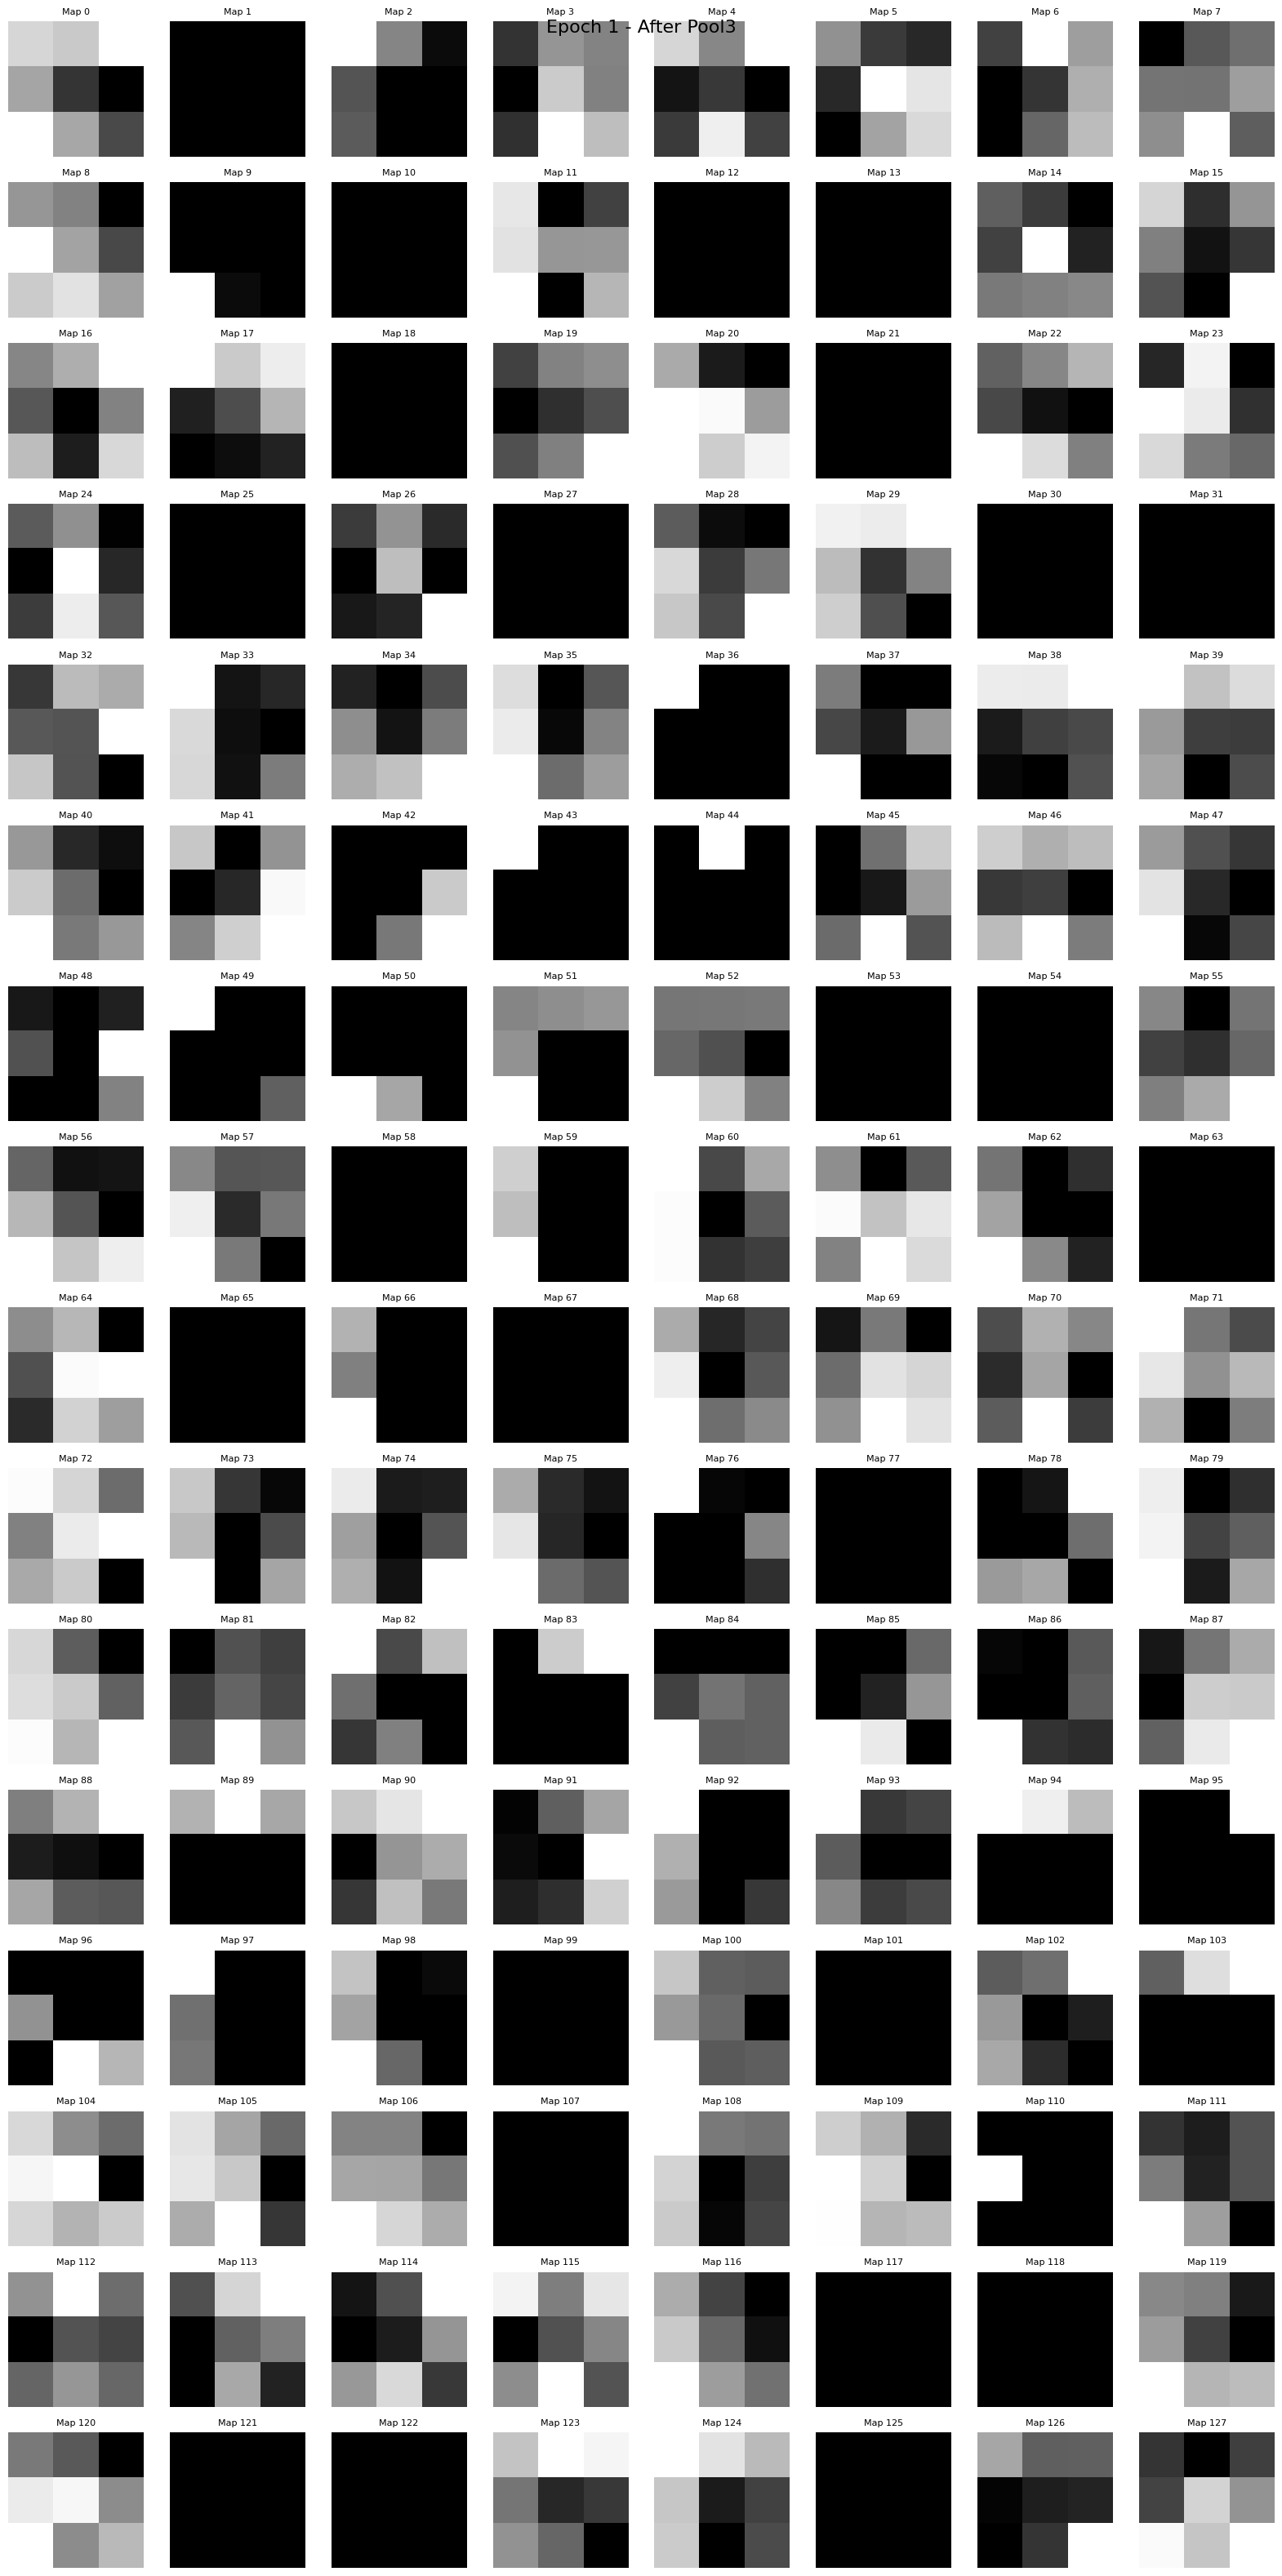


AFTER FLATTEN
Shape: (1152,)
First 40 values:
tensor([0.0734, 0.0709, 0.0817, 0.0636, 0.0411, 0.0306, 0.0816, 0.0640, 0.0454,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0289, 0.0151, 0.0013, 0.0096, 0.0000, 0.0000, 0.0104, 0.0000, 0.0000,
        0.0072, 0.0210, 0.0185, 0.0000, 0.0286, 0.0182, 0.0068, 0.0359, 0.0267,
        0.0672, 0.0612, 0.0703, 0.0526])

AFTER LINEAR 1
Shape: (256,)
First 40 values:
tensor([ 0.0216,  0.0235, -0.0516,  0.0005, -0.0361, -0.0037,  0.0027,  0.0741,
        -0.0011,  0.0169, -0.0075,  0.0328, -0.1336,  0.0071,  0.0302,  0.0058,
         0.0984, -0.0371,  0.0605,  0.0604, -0.0713, -0.0012, -0.0267,  0.0175,
        -0.0308,  0.0032, -0.0661, -0.0273,  0.0816,  0.0190,  0.0828, -0.0346,
         0.0049,  0.0339, -0.0197,  0.0503, -0.0243,  0.0847, -0.0825,  0.0936])

AFTER RELU
Shape: (256,)
First 40 values:
tensor([0.0216, 0.0235, 0.0000, 0.0005, 0.0000, 0.0000, 0.0027, 0.0741, 0.0000,
        0.0169, 0.000

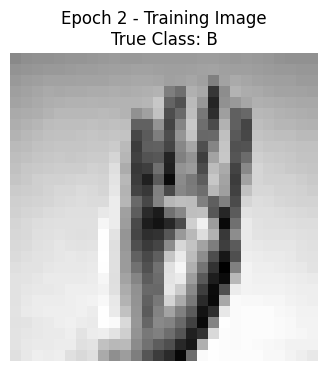



FORWARD PASS - EPOCH 2
input      Shape: (64, 1, 28, 28)      Mean:  0.634987 Min:  0.000000 Max:  1.000000
conv1      Shape: (64, 32, 28, 28)     Mean: -0.042147 Min: -1.587209 Max:  1.136587
relu1      Shape: (64, 32, 28, 28)     Mean:  0.137034 Min:  0.000000 Max:  1.136587
pool1      Shape: (64, 32, 14, 14)     Mean:  0.164543 Min:  0.000000 Max:  1.136587
conv2      Shape: (64, 64, 14, 14)     Mean: -0.009297 Min: -0.543624 Max:  0.658443
relu2      Shape: (64, 64, 14, 14)     Mean:  0.055600 Min:  0.000000 Max:  0.658443
pool2      Shape: (64, 64, 7, 7)       Mean:  0.072619 Min:  0.000000 Max:  0.658443
conv3      Shape: (64, 128, 7, 7)      Mean:  0.001948 Min: -0.383202 Max:  0.371639
relu3      Shape: (64, 128, 7, 7)      Mean:  0.032246 Min:  0.000000 Max:  0.371639
pool3      Shape: (64, 128, 3, 3)      Mean:  0.045061 Min:  0.000000 Max:  0.371639
flatten    Shape: (64, 1152)           Mean:  0.045061 Min:  0.000000 Max:  0.371639
fc1        Shape: (64, 256)            M

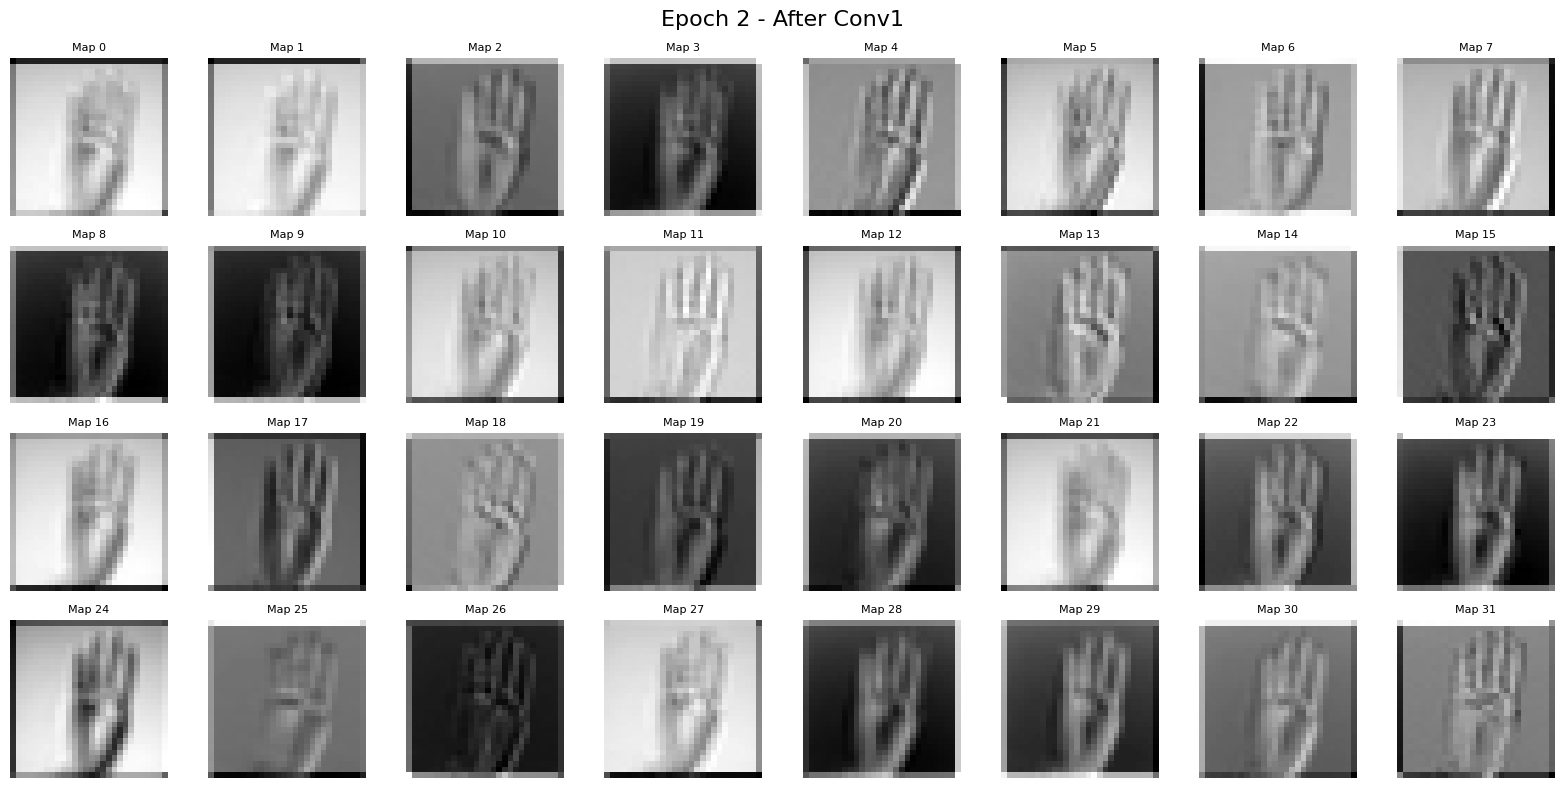

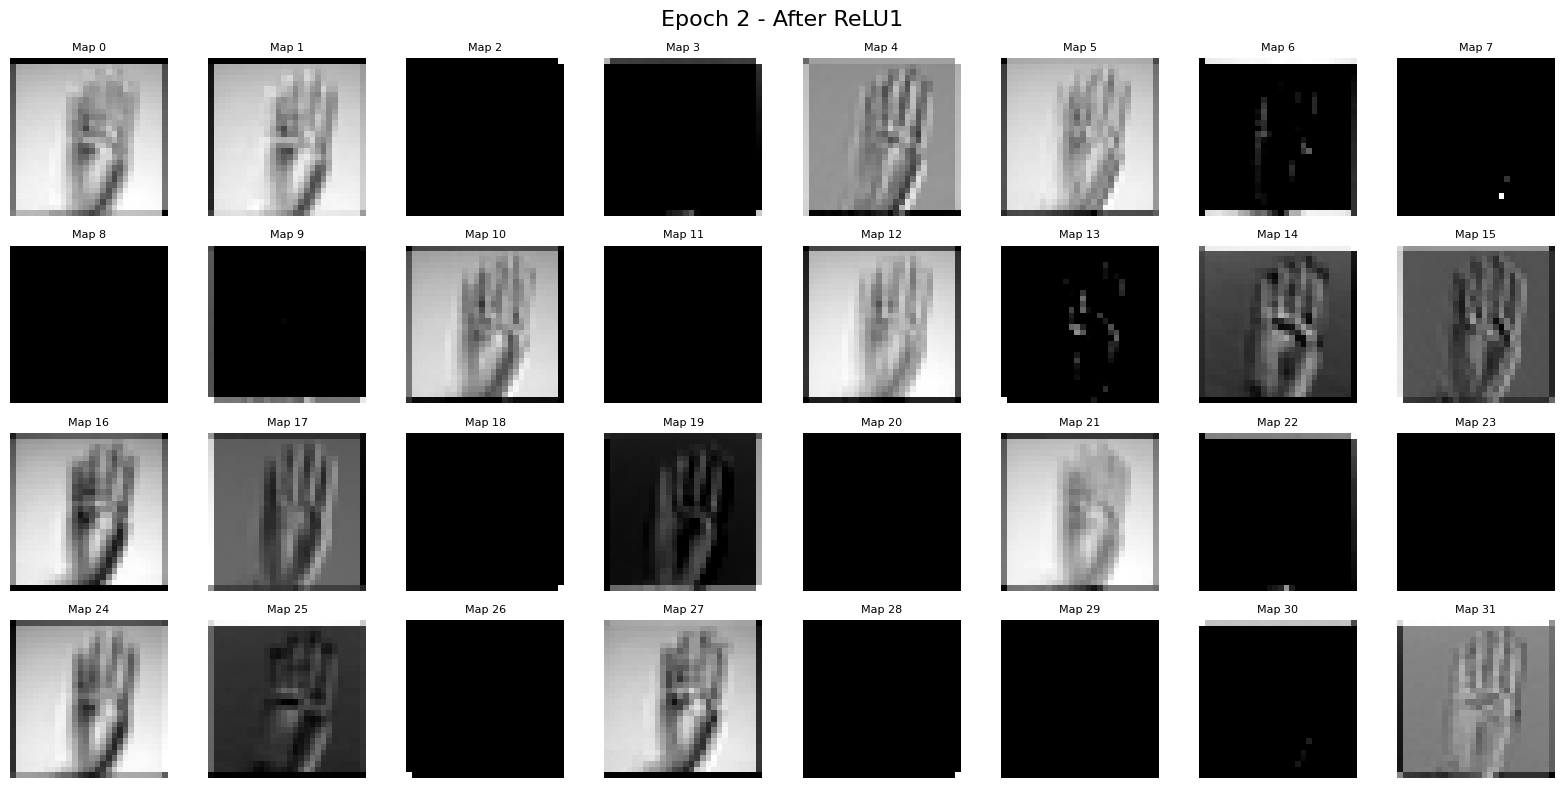

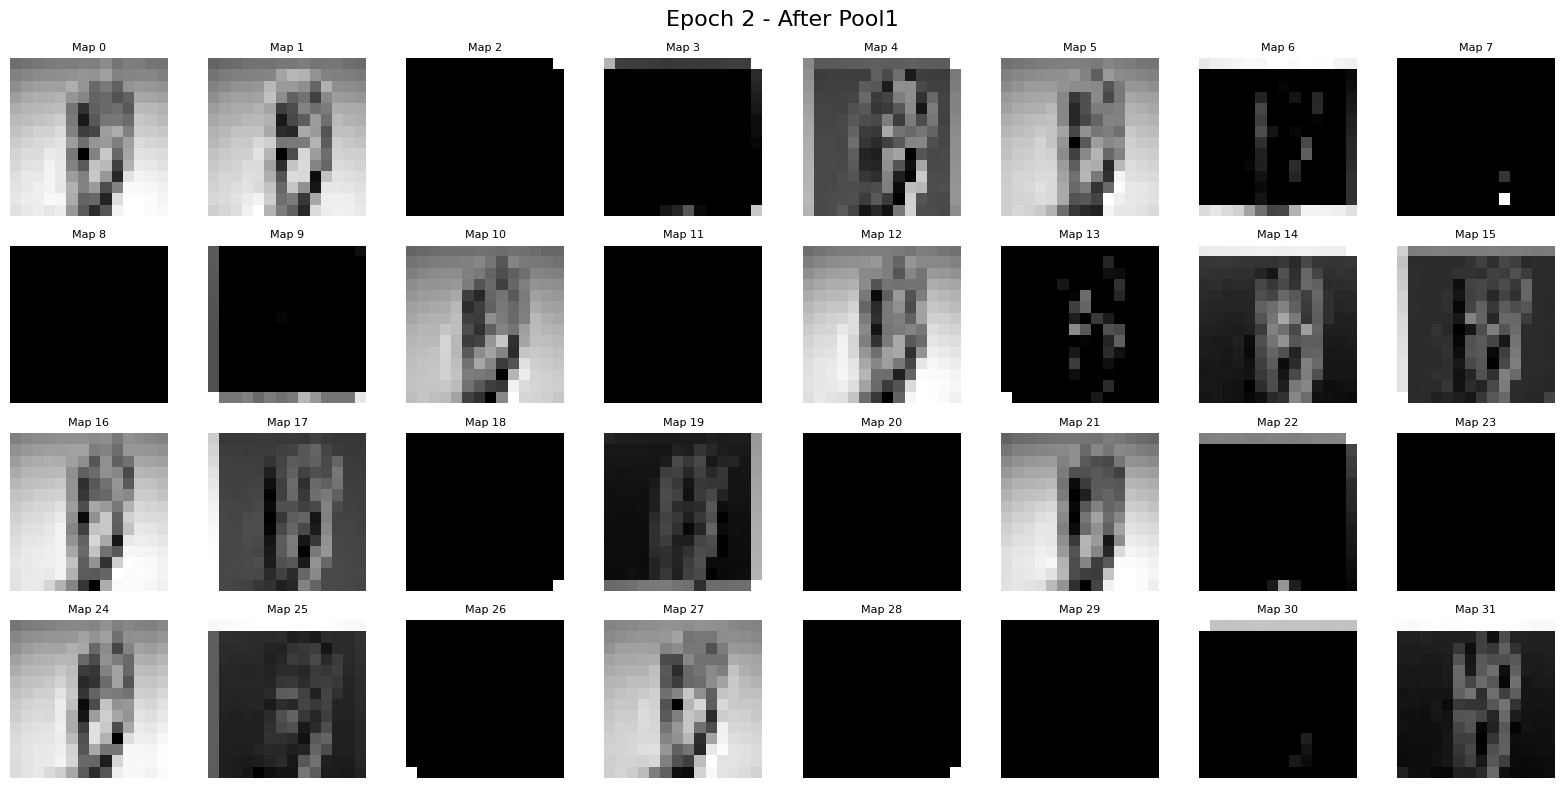

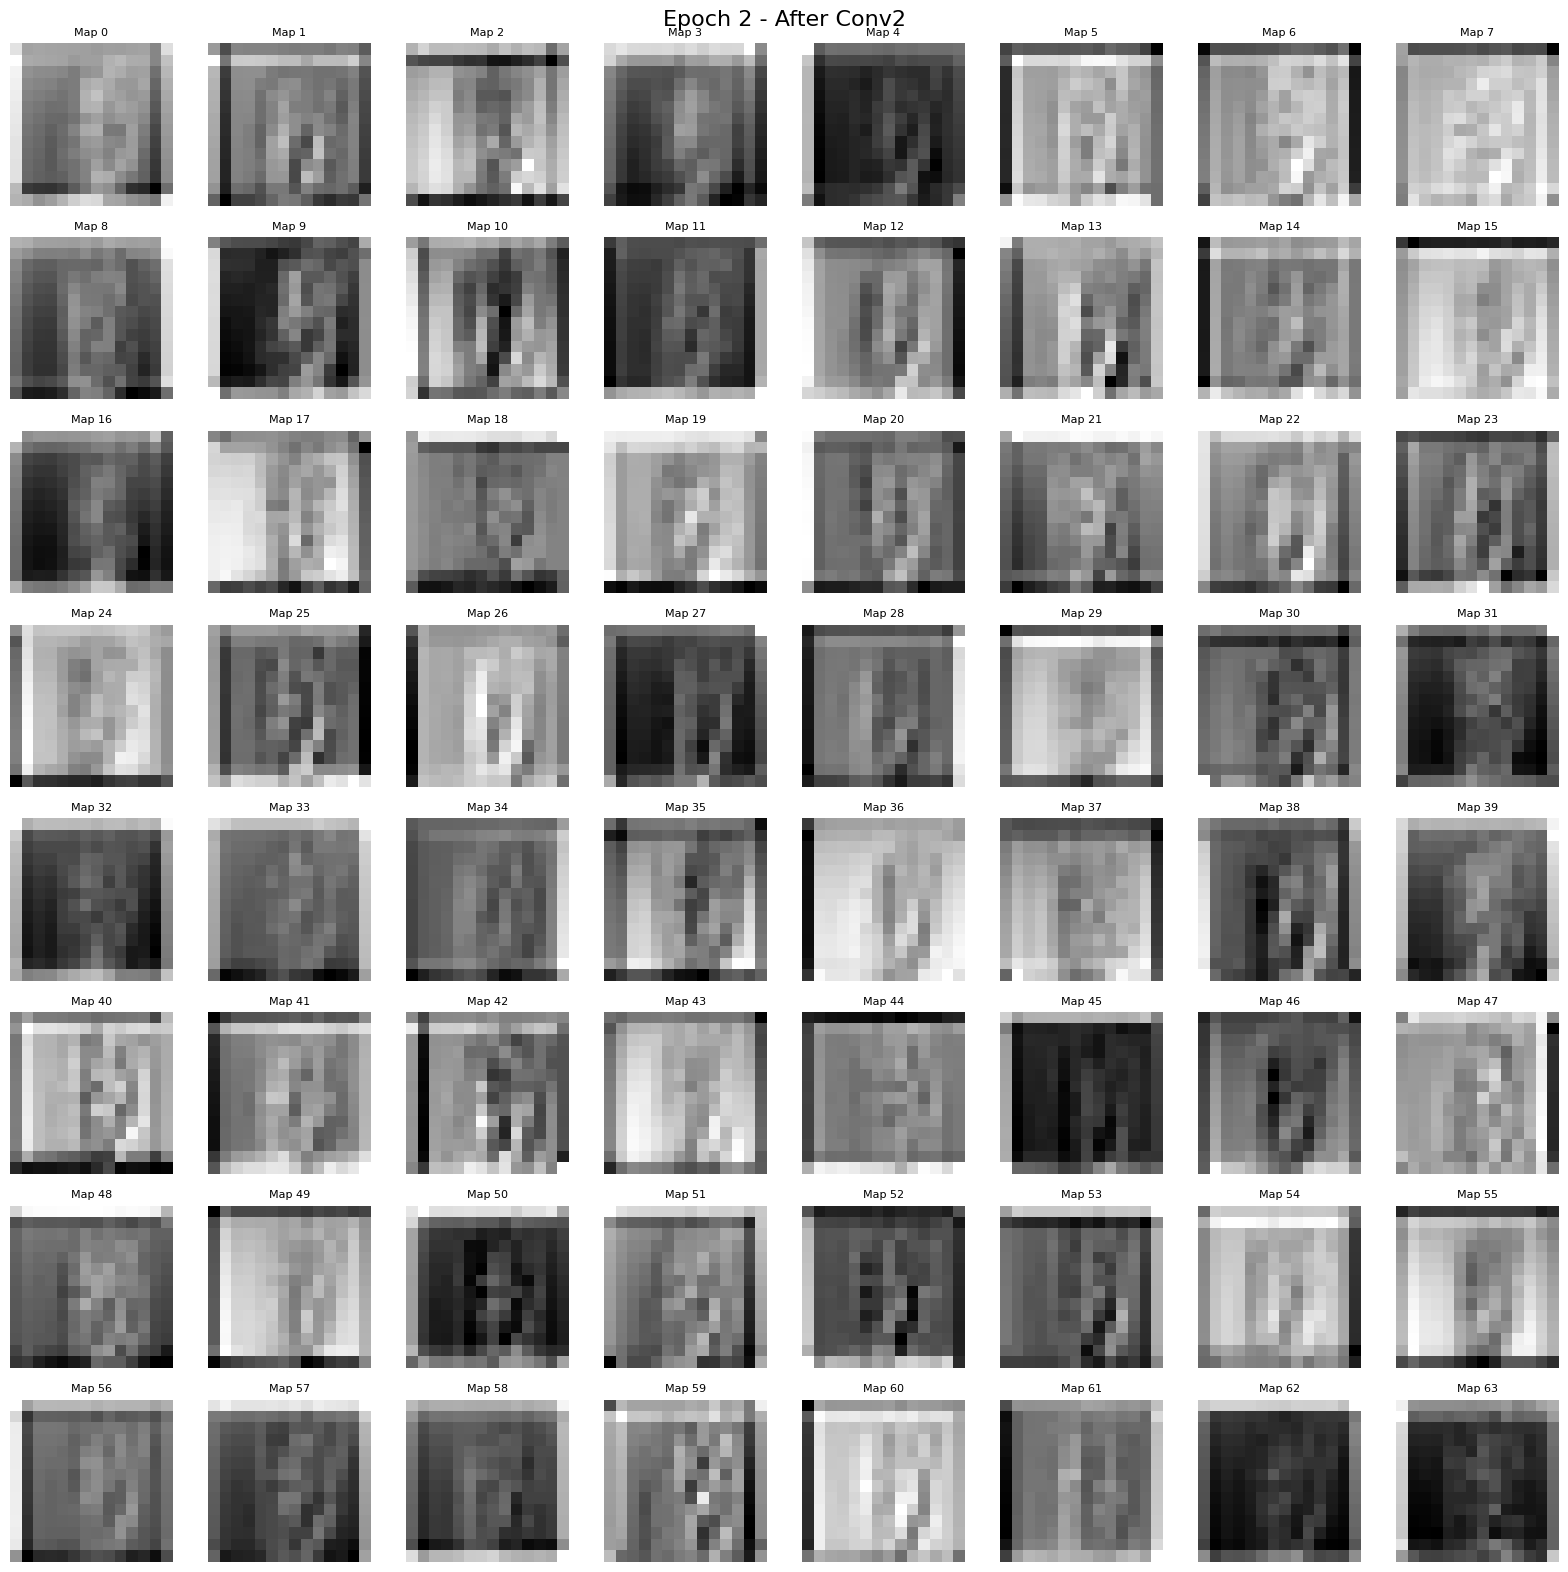

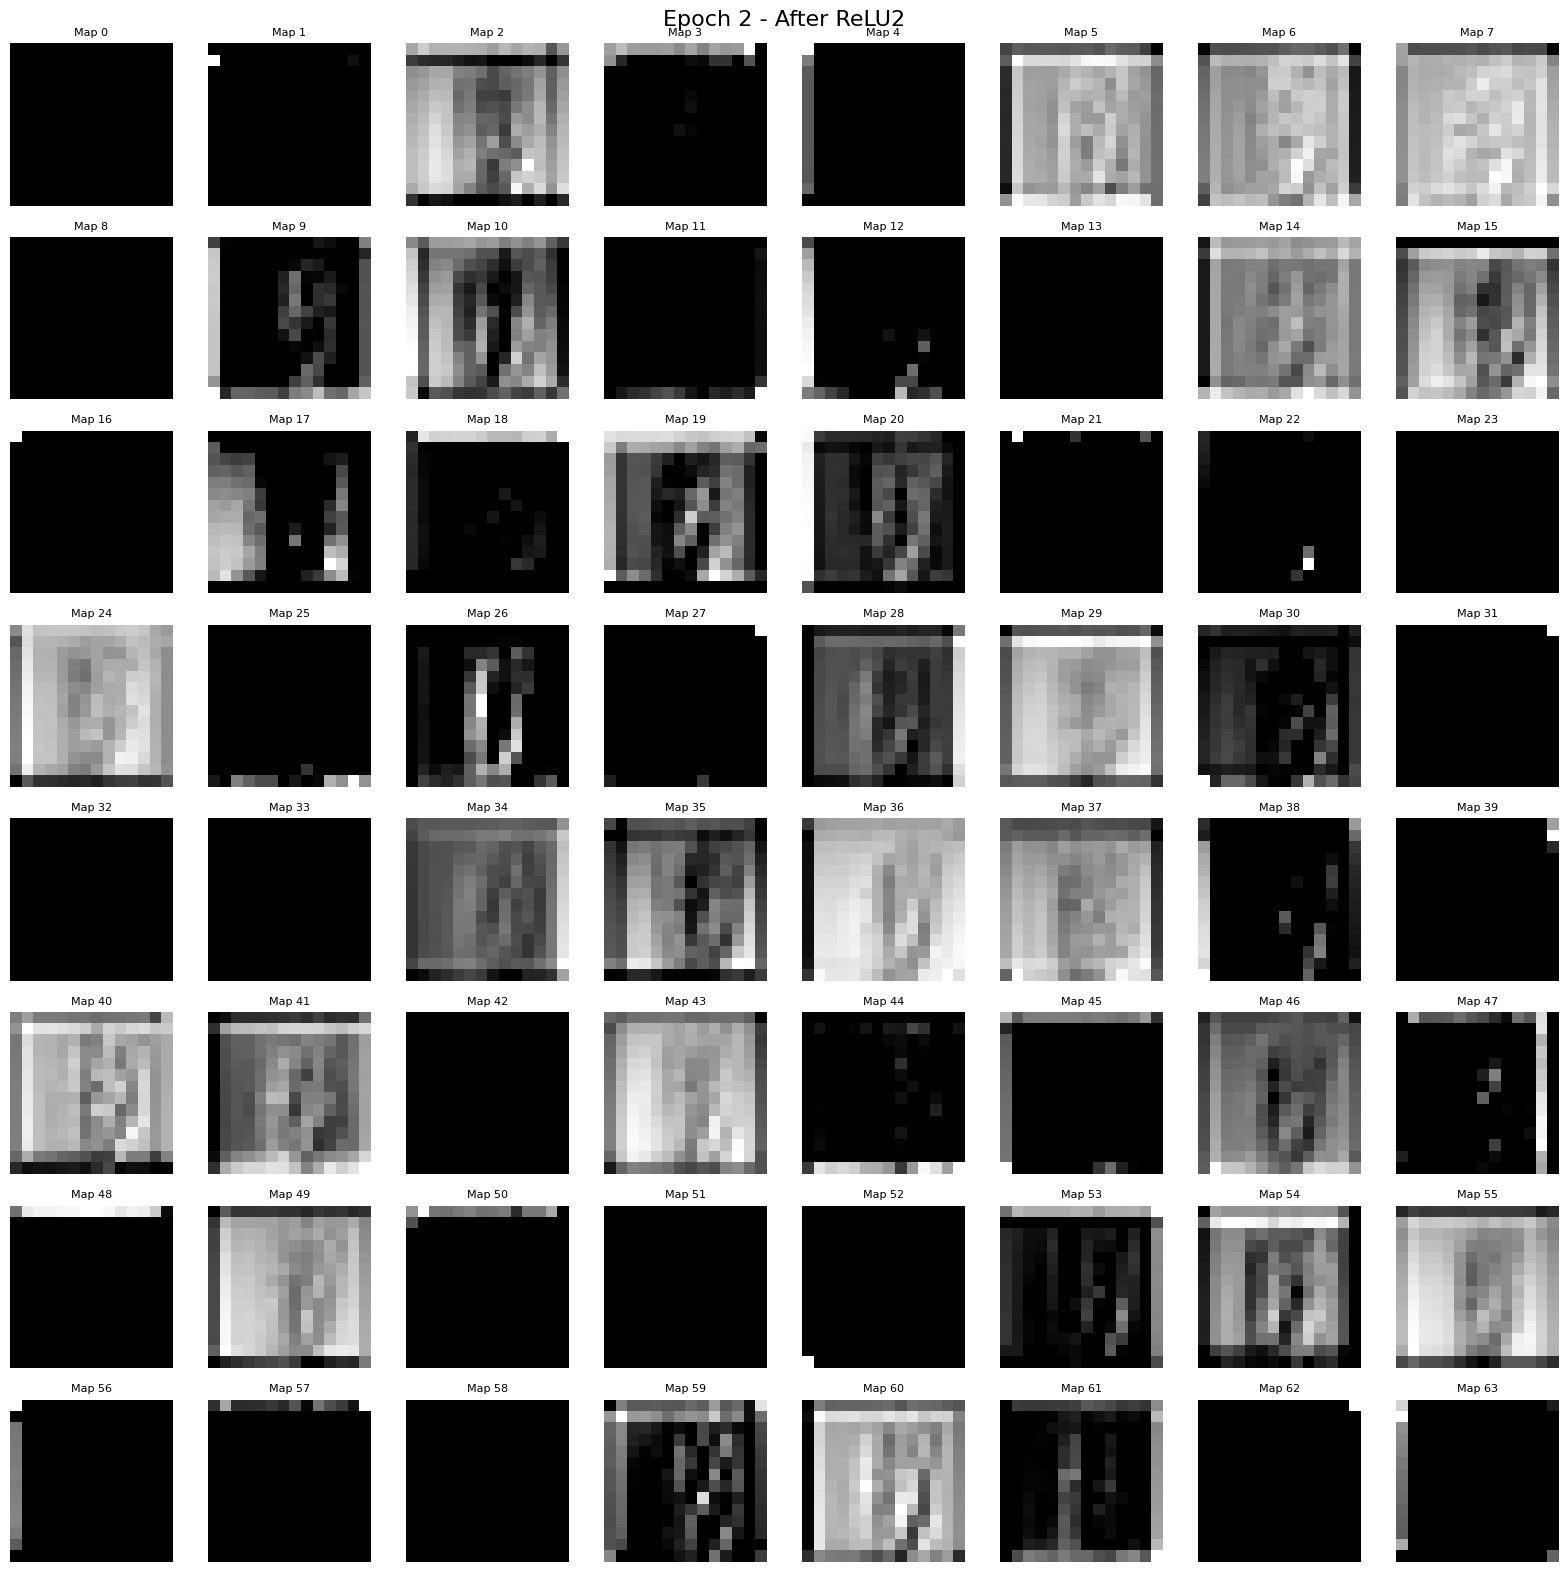

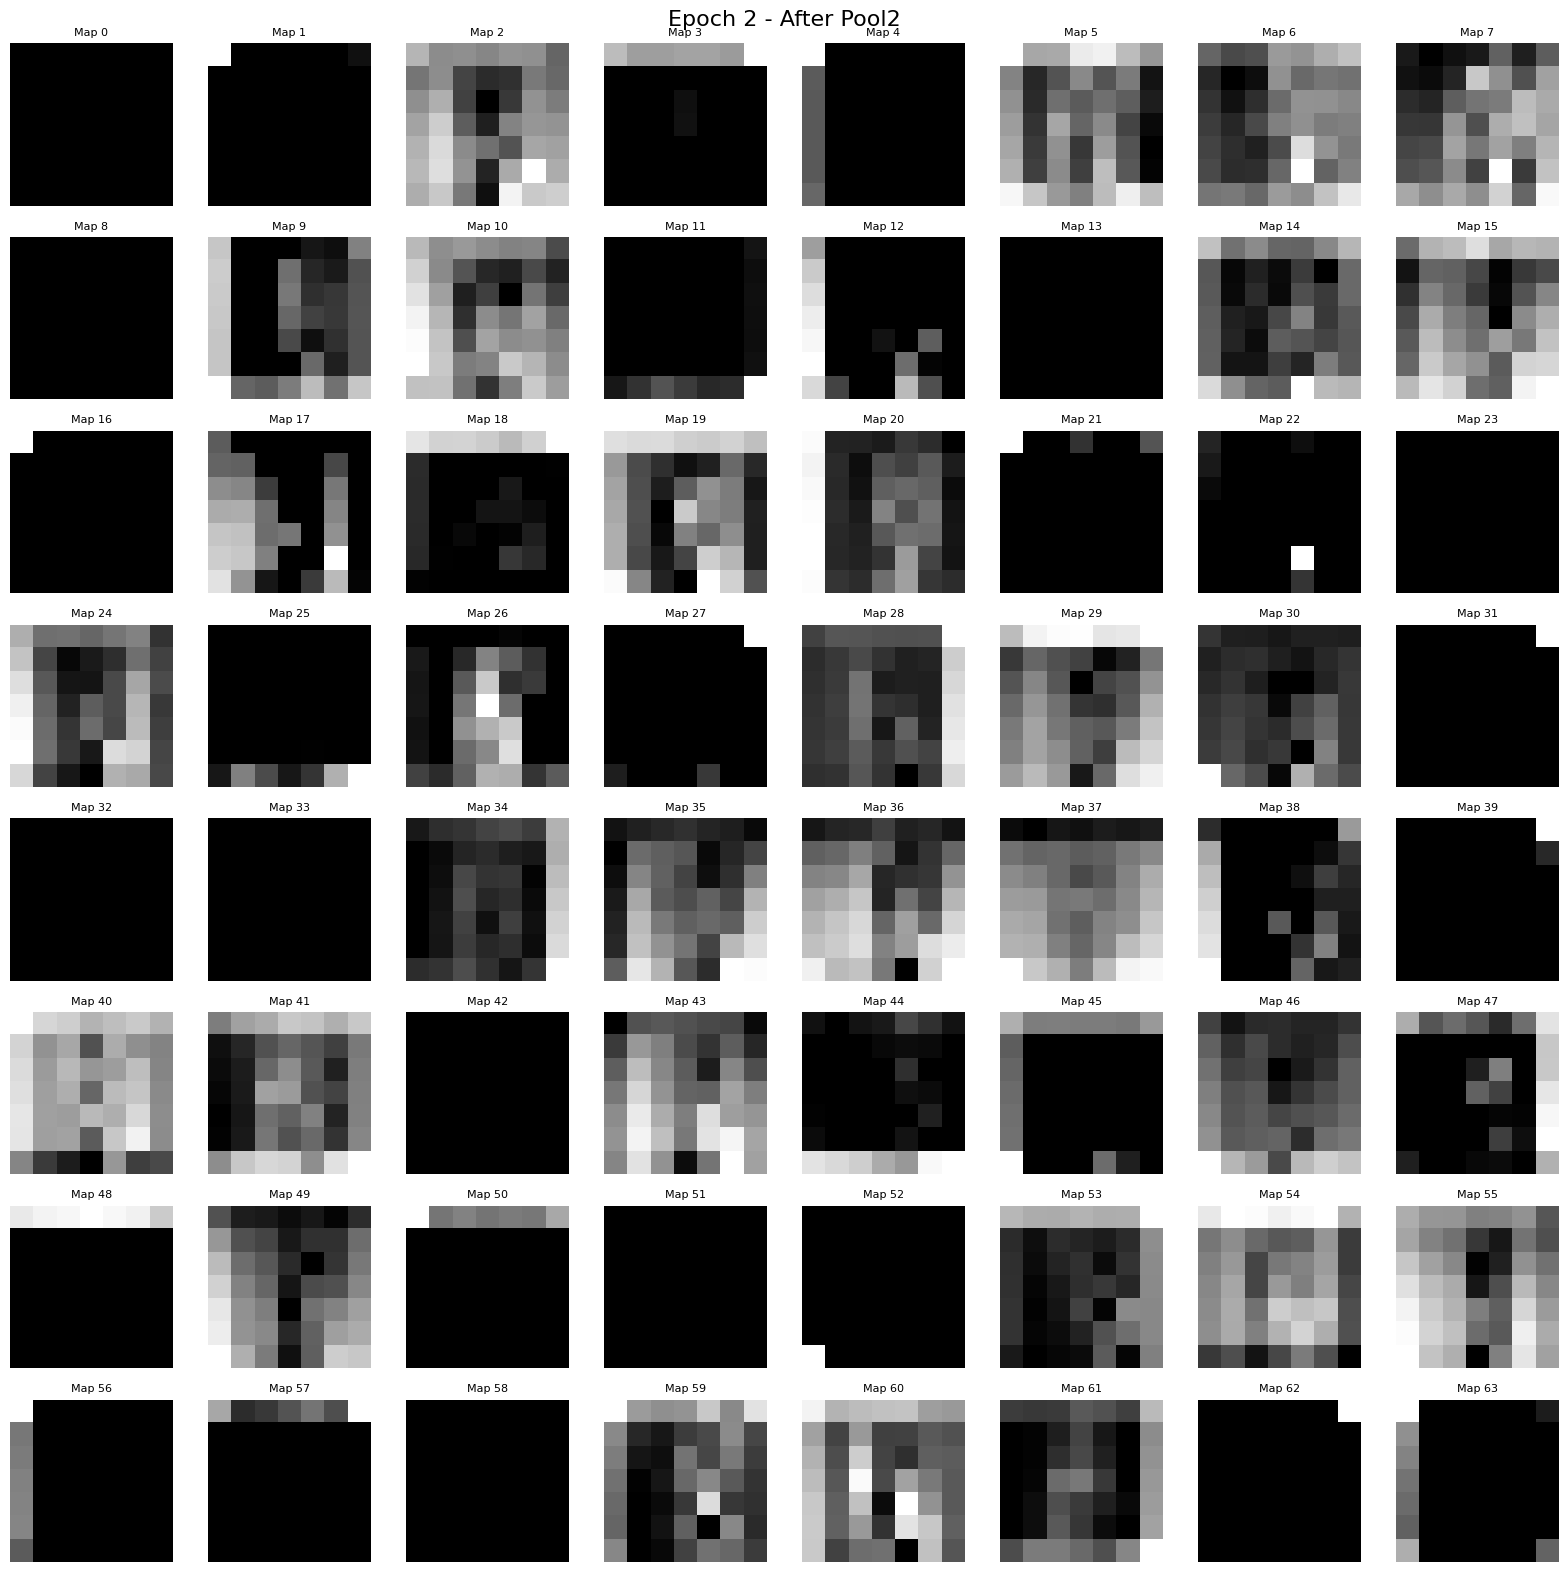

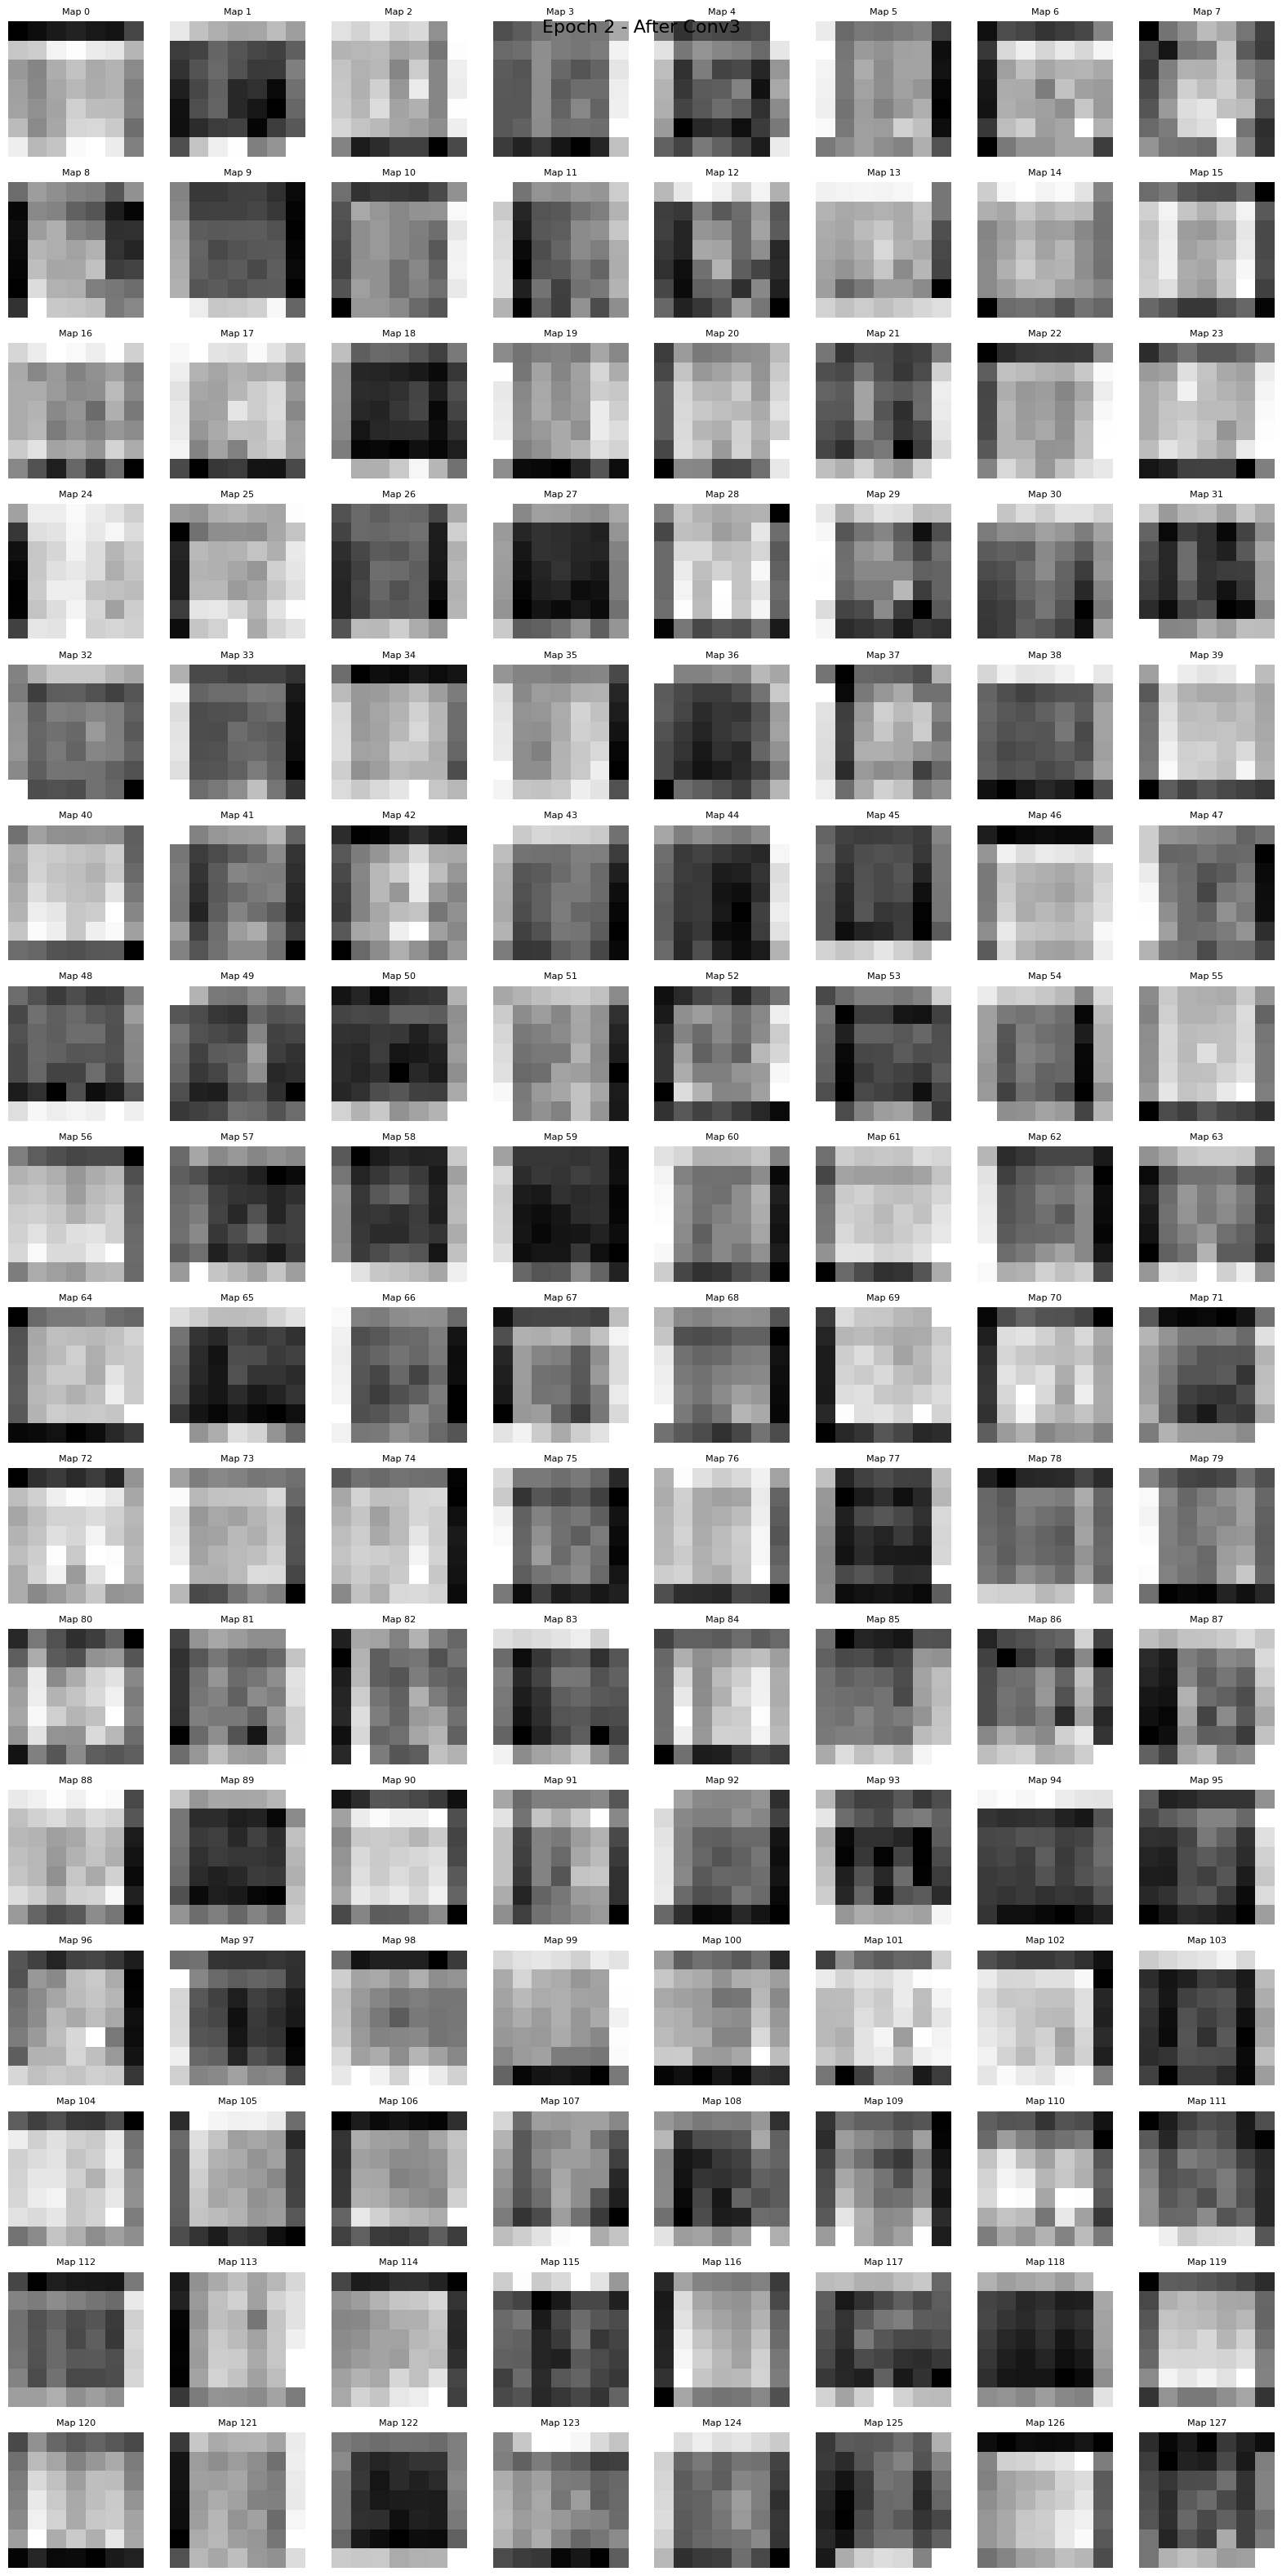

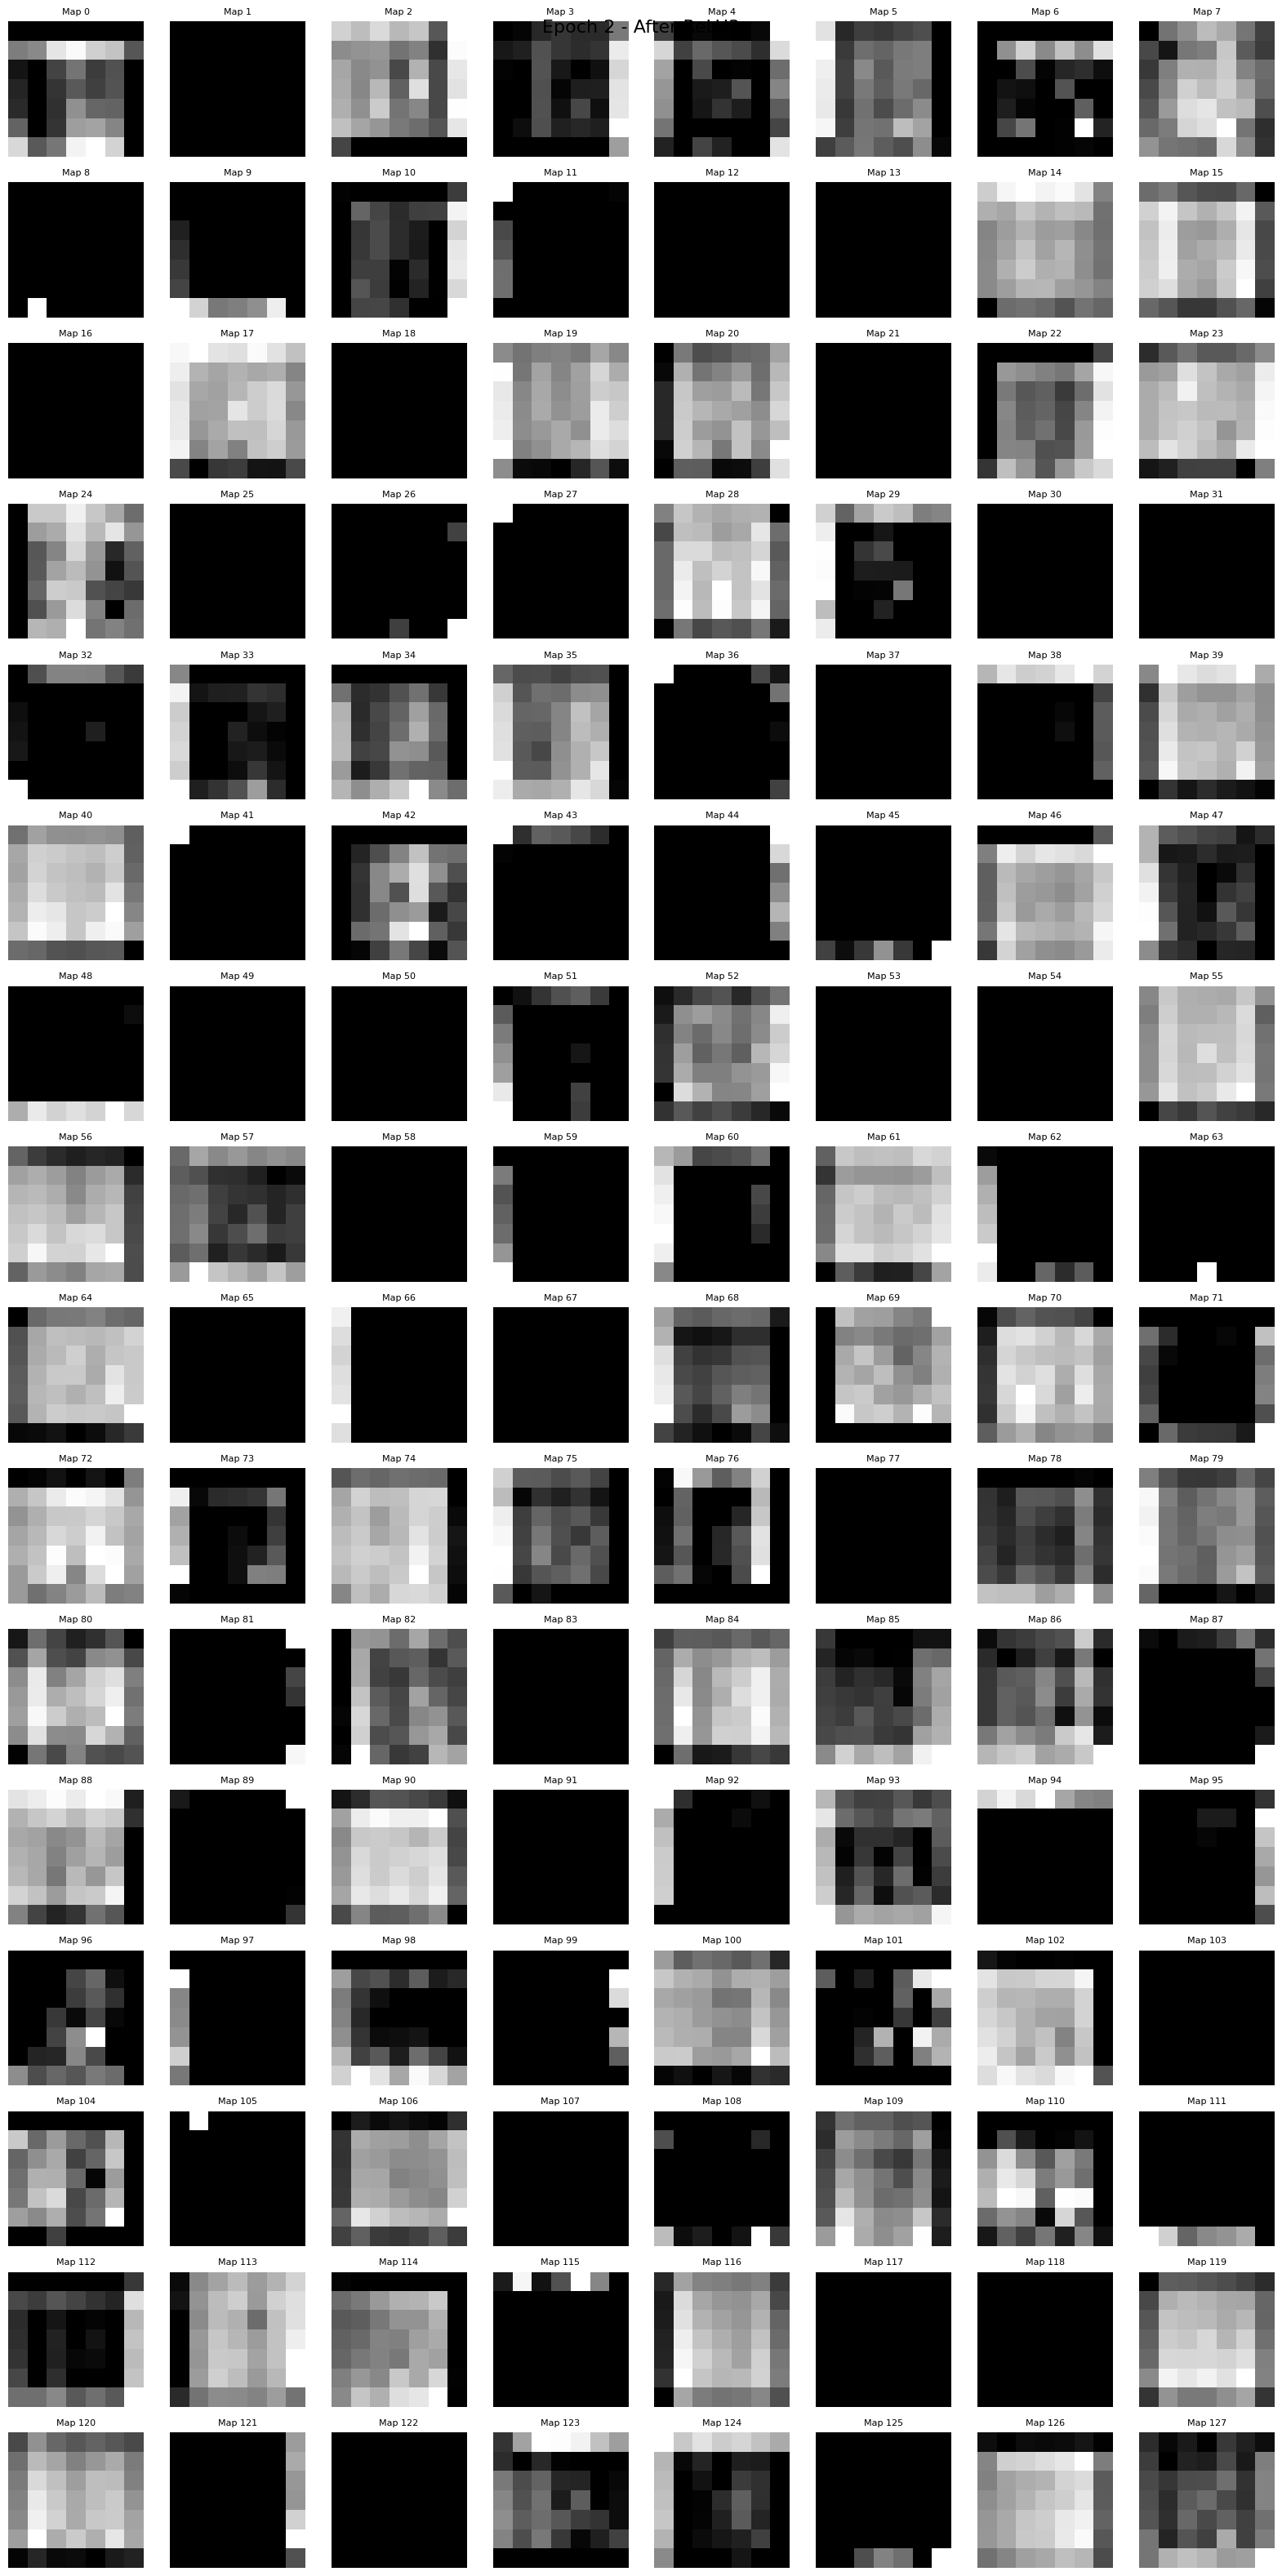

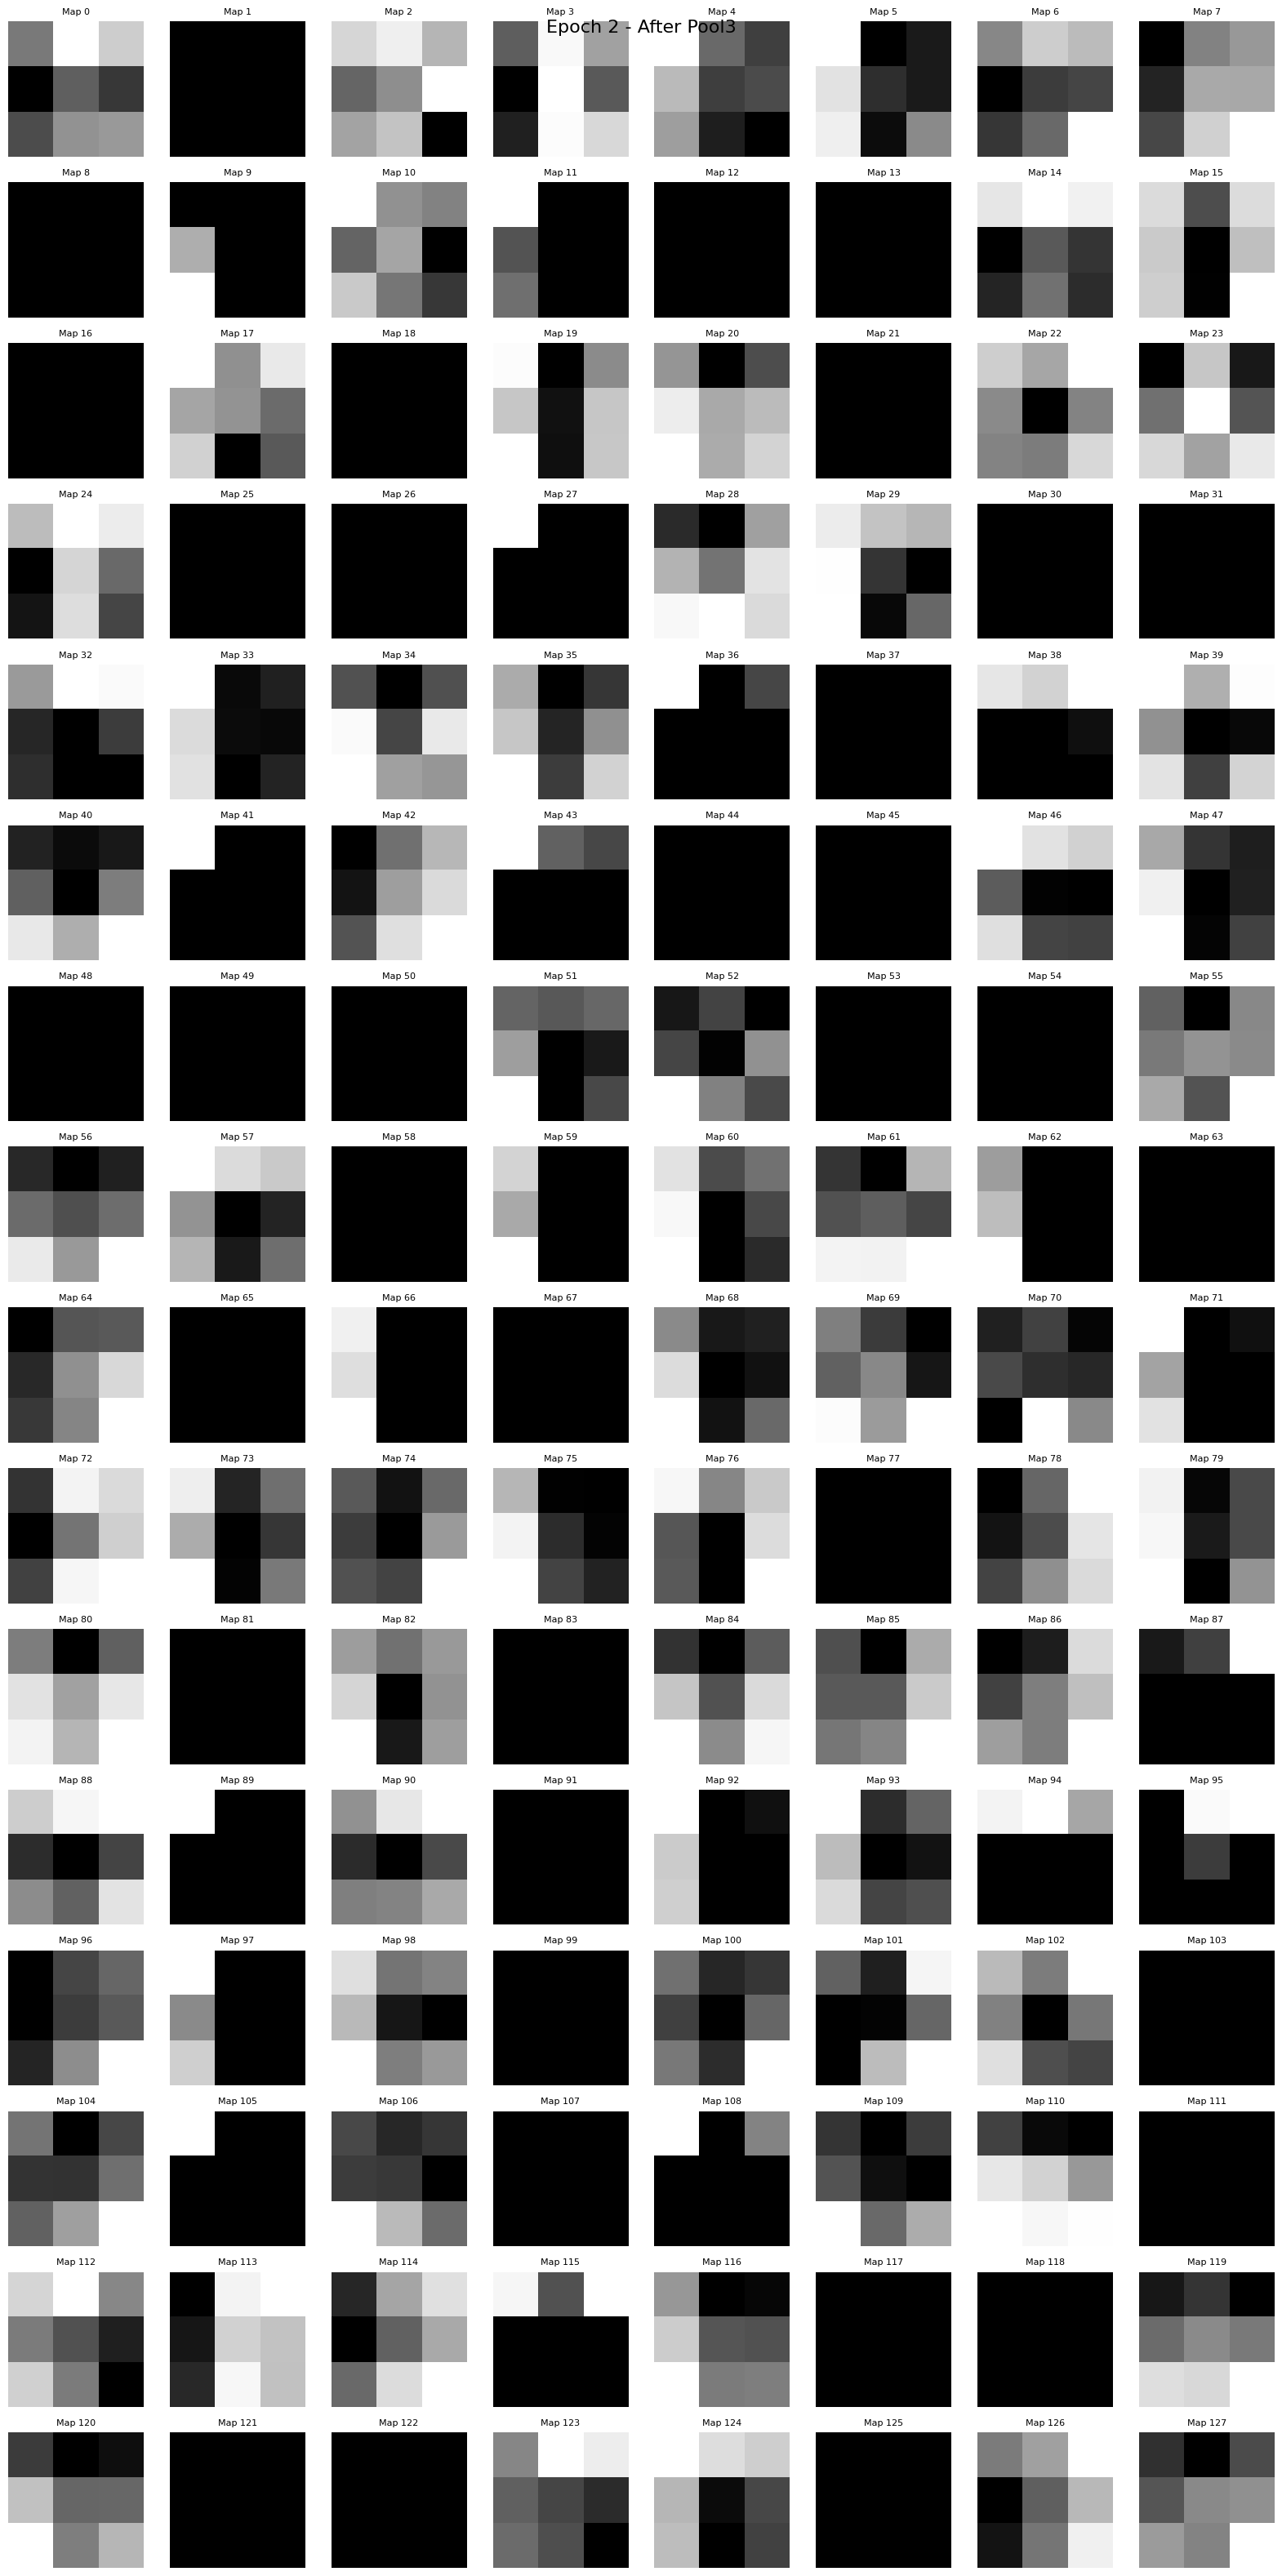


AFTER FLATTEN
Shape: (1152,)
First 40 values:
tensor([0.0322, 0.0585, 0.0487, 0.0084, 0.0272, 0.0194, 0.0233, 0.0371, 0.0384,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0559, 0.0581, 0.0528, 0.0456, 0.0492, 0.0596, 0.0512, 0.0541, 0.0362,
        0.0144, 0.0357, 0.0236, 0.0013, 0.0366, 0.0138, 0.0058, 0.0361, 0.0311,
        0.0444, 0.0222, 0.0157, 0.0340])

AFTER LINEAR 1
Shape: (256,)
First 40 values:
tensor([-0.0454, -0.0468, -0.0715, -0.0181, -0.0697,  0.0549, -0.0394,  0.1086,
        -0.0269,  0.0104, -0.0363, -0.0458, -0.1208, -0.0457,  0.0834, -0.0112,
         0.1024, -0.0005,  0.0040,  0.0015, -0.0901,  0.0045, -0.0173, -0.0707,
        -0.0458, -0.0646, -0.0670, -0.0622,  0.0125,  0.0822,  0.0244, -0.0338,
         0.0350,  0.0999,  0.0043,  0.0713, -0.0284,  0.1349, -0.0564,  0.1168])

AFTER RELU
Shape: (256,)
First 40 values:
tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0549, 0.0000, 0.1086, 0.0000,
        0.0104, 0.000

In [ ]:
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns
# import sys
# import torch
# import torch.nn as nn
# import torch.optim as optim

# from torch.utils.data import Dataset, DataLoader


# # ============================================================
# # CONFIGURATION
# # ============================================================

# BATCH_SIZE = 64
# EPOCHS = 2
# LR = 1e-3

# DEVICE = torch.device(
#     "cuda" if torch.cuda.is_available() else "cpu"
# )

# SELECTED_CLASSES = [0, 1, 2]

# CLASS_NAMES = {
#     0: "A",
#     1: "B",
#     2: "C"
# }


# print("Device:", DEVICE)


# # ============================================================
# # LOAD DATA
# # ============================================================

# train_df = pd.read_csv(
#     "sign_mnist_train.csv"
# )

# train_df = train_df[
#     train_df["label"].isin(SELECTED_CLASSES)
# ].copy()


# # ============================================================
# # DATASET
# # ============================================================

# class SignDataset(Dataset):

#     def __init__(self, df):

#         self.labels = df["label"].values

#         self.images = (
#             df.drop("label", axis=1)
#             .values
#             .reshape(-1, 28, 28)
#             .astype(np.float32)
#             / 255.0
#         )

#     def __len__(self):
#         return len(self.labels)

#     def __getitem__(self, idx):

#         image = torch.tensor(
#             self.images[idx]
#         ).unsqueeze(0)

#         label = torch.tensor(
#             self.labels[idx]
#         ).long()

#         return image, label


# train_ds = SignDataset(train_df)

# train_loader = DataLoader(
#     train_ds,
#     batch_size=BATCH_SIZE,
#     shuffle=True
# )


# # ============================================================
# # MODEL
# # ============================================================

# class SignCNN(nn.Module):

#     def __init__(self):

#         super().__init__()

#         # ----------------------------------------------------
#         # BLOCK 1
#         # ----------------------------------------------------

#         self.conv1 = nn.Conv2d(
#             in_channels=1,
#             out_channels=32,
#             kernel_size=3,
#             padding=1
#         )

#         self.relu1 = nn.ReLU()

#         self.pool1 = nn.MaxPool2d(2)


#         # ----------------------------------------------------
#         # BLOCK 2
#         # ----------------------------------------------------

#         self.conv2 = nn.Conv2d(
#             in_channels=32,
#             out_channels=64,
#             kernel_size=3,
#             padding=1
#         )

#         self.relu2 = nn.ReLU()

#         self.pool2 = nn.MaxPool2d(2)


#         # ----------------------------------------------------
#         # BLOCK 3
#         # ----------------------------------------------------

#         self.conv3 = nn.Conv2d(
#             in_channels=64,
#             out_channels=128,
#             kernel_size=3,
#             padding=1
#         )

#         self.relu3 = nn.ReLU()

#         self.pool3 = nn.MaxPool2d(2)


#         # ----------------------------------------------------
#         # CLASSIFIER
#         # ----------------------------------------------------

#         self.flatten = nn.Flatten()

#         self.fc1 = nn.Linear(
#             128 * 3 * 3,
#             256
#         )

#         self.relu4 = nn.ReLU()

#         self.dropout = nn.Dropout(0.5)

#         self.fc2 = nn.Linear(
#             256,
#             3
#         )


#     def forward(self, x, return_intermediate=False):

#         outputs = {}

#         outputs["input"] = x

#         x = self.conv1(x)
#         outputs["conv1"] = x

#         x = self.relu1(x)
#         outputs["relu1"] = x

#         x = self.pool1(x)
#         outputs["pool1"] = x

#         x = self.conv2(x)
#         outputs["conv2"] = x

#         x = self.relu2(x)
#         outputs["relu2"] = x

#         x = self.pool2(x)
#         outputs["pool2"] = x

#         x = self.conv3(x)
#         outputs["conv3"] = x

#         x = self.relu3(x)
#         outputs["relu3"] = x

#         x = self.pool3(x)
#         outputs["pool3"] = x

#         x = self.flatten(x)
#         outputs["flatten"] = x

#         x = self.fc1(x)
#         outputs["fc1"] = x

#         x = self.relu4(x)
#         outputs["relu4"] = x

#         x = self.dropout(x)
#         outputs["dropout"] = x

#         x = self.fc2(x)
#         outputs["logits"] = x


#         if return_intermediate:
#             return x, outputs

#         return x


# # ============================================================
# # CREATE MODEL
# # ============================================================

# model = SignCNN().to(DEVICE)

# criterion = nn.CrossEntropyLoss()

# optimizer = optim.Adam(
#     model.parameters(),
#     lr=LR
# )


# print("\nModel created.")
# print(model)


# # ============================================================
# # FEATURE MAP VISUALIZATION
# # ============================================================

# def show_feature_maps(tensor, title, max_maps):

#     data = tensor.detach().cpu()

#     # Remove batch dimension
#     data = data[0]

#     number_of_maps = min(
#         data.shape[0],
#         max_maps
#     )

#     columns = 8

#     rows = int(
#         np.ceil(
#             number_of_maps / columns
#         )
#     )

#     plt.figure(
#         figsize=(16, 2 * rows)
#     )

#     for i in range(number_of_maps):

#         plt.subplot(
#             rows,
#             columns,
#             i + 1
#         )

#         plt.imshow(
#             data[i],
#             cmap="gray"
#         )

#         plt.title(
#             f"Map {i}",
#             fontsize=8
#         )

#         plt.axis("off")

#     plt.suptitle(
#         title,
#         fontsize=16
#     )

#     plt.tight_layout()
#     plt.show()


# # ============================================================
# # SHOW VECTOR VALUES
# # ============================================================

# def show_vector(tensor, title, max_values=30):

#     values = (
#         tensor
#         .detach()
#         .cpu()
#         .flatten()
#     )

#     print("\n" + "=" * 70)

#     print(title)

#     print("=" * 70)

#     print(
#         "Shape:",
#         tuple(tensor.shape)
#     )

#     print(
#         "First",
#         min(max_values, len(values)),
#         "values:"
#     )

#     print(
#         values[
#             :max_values
#         ]
#     )


# # ============================================================
# # TRAINING DEMONSTRATION
# # ============================================================

# print("\n")
# print("=" * 80)
# print("              TRAINING PIPELINE DEMONSTRATION")
# print("=" * 80)

# print(
#     f"Epochs: {EPOCHS}"
# )

# print(
#     f"Batch size: {BATCH_SIZE}"
# )

# print(
#     f"Learning rate: {LR}"
# )

# print("=" * 80)


# # ============================================================
# # TRAIN FOR 2 EPOCHS
# # ============================================================

# for epoch in range(EPOCHS):

#     model.train()

#     epoch_loss = 0.0

#     epoch_correct = 0

#     epoch_total = 0


#     print("\n\n")
#     print("#" * 80)
#     print(
#         f"                         EPOCH {epoch + 1}"
#     )
#     print("#" * 80)


#     # --------------------------------------------------------
#     # ONLY USE ONE BATCH FOR THIS DEMONSTRATION
#     # --------------------------------------------------------

#     for batch_idx, (
#         images,
#         labels
#     ) in enumerate(train_loader):

#         # ====================================================
#         # STOP AFTER FIRST BATCH
#         # ====================================================

#         if batch_idx > 0:
#             break

#         images = images.to(DEVICE)
#         labels = labels.to(DEVICE)


#         # ====================================================
#         # SELECT ONE IMAGE FROM THIS BATCH
#         # ====================================================

#         selected_image = images[0:1]
#         selected_label = labels[0:1]

#         print("\n")
#         print("-" * 80)

#         print(
#             f"EPOCH {epoch + 1} "
#             f"| BATCH {batch_idx + 1} "
#             f"| SELECTED IMAGE 1"
#         )

#         print("-" * 80)

#         print(
#             "Batch shape:",
#             tuple(images.shape)
#         )

#         print(
#             "Selected image shape:",
#             tuple(selected_image.shape)
#         )

#         print(
#             "True label:",
#             selected_label.item(),
#             f"({CLASS_NAMES[selected_label.item()]})"
#         )


#         # ====================================================
#         # DISPLAY INPUT IMAGE
#         # ====================================================

#         plt.figure(
#             figsize=(4, 4)
#         )

#         plt.imshow(
#             selected_image[0, 0]
#             .detach()
#             .cpu(),
#             cmap="gray"
#         )

#         plt.title(
#             f"Epoch {epoch + 1} - "
#             f"Training Image\n"
#             f"True Class: "
#             f"{CLASS_NAMES[selected_label.item()]}"
#         )

#         plt.axis("off")
#         plt.show()


#         # ====================================================
#         # SAVE WEIGHTS BEFORE UPDATE
#         # ====================================================

#         conv1_weight_before = (
#             model.conv1.weight
#             .detach()
#             .clone()
#         )

#         fc1_weight_before = model.fc1.weight.detach().clone()
#         fc1_bias_before   = model.fc1.bias.detach().clone()

#         # fc2_weight_before = model.fc2.weight.detach().clone()
#         # fc2_bias_before   = model.fc2.bias.detach().clone()


#         # ====================================================
#         # CLEAR GRADIENTS
#         # ====================================================

#         optimizer.zero_grad()


#         # ====================================================
#         # FORWARD PASS
#         # ====================================================

#         logits, intermediate = model(
#             images,
#             return_intermediate=True
#         )


#         # ====================================================
#         # DISPLAY SELECTED IMAGE'S FORWARD PASS
#         # ====================================================

#         print("\n")
#         print("=" * 80)

#         print(
#             f"FORWARD PASS - EPOCH {epoch + 1}"
#         )

#         print("=" * 80)


#         for name, tensor in intermediate.items():

#             print(
#                 f"{name:10s} "
#                 f"Shape: {str(tuple(tensor.shape)):20s} "
#                 f"Mean: {tensor.mean().item(): .6f} "
#                 f"Min: {tensor.min().item(): .6f} "
#                 f"Max: {tensor.max().item(): .6f}"
#             )


#         # ====================================================
#         # VISUALIZE IMAGE 1
#         # ====================================================

#         print("\n")
#         print(
#             "Showing feature maps for selected image..."
#         )


#         show_feature_maps(
#             intermediate["conv1"][0:1],
#             f"Epoch {epoch + 1} - "
#             "After Conv1",
#             32
#         )


#         show_feature_maps(
#             intermediate["relu1"][0:1],
#             f"Epoch {epoch + 1} - "
#             "After ReLU1",
#             32
#         )


#         show_feature_maps(
#             intermediate["pool1"][0:1],
#             f"Epoch {epoch + 1} - "
#             "After Pool1",
#             32
#         )


#         show_feature_maps(
#             intermediate["conv2"][0:1],
#             f"Epoch {epoch + 1} - "
#             "After Conv2",
#             64
#         )


#         show_feature_maps(
#             intermediate["relu2"][0:1],
#             f"Epoch {epoch + 1} - "
#             "After ReLU2",
#             64
#         )


#         show_feature_maps(
#             intermediate["pool2"][0:1],
#             f"Epoch {epoch + 1} - "
#             "After Pool2",
#             64
#         )


#         show_feature_maps(
#             intermediate["conv3"][0:1],
#             f"Epoch {epoch + 1} - "
#             "After Conv3",
#             128
#         )


#         show_feature_maps(
#             intermediate["relu3"][0:1],
#             f"Epoch {epoch + 1} - "
#             "After ReLU3",
#             128
#         )


#         show_feature_maps(
#             intermediate["pool3"][0:1],
#             f"Epoch {epoch + 1} - "
#             "After Pool3",
#             128
#         )

#         show_vector(
#             intermediate["flatten"][0],
#             "AFTER FLATTEN",
#             40
#         )

#         show_vector(
#             intermediate["fc1"][0],
#             "AFTER LINEAR 1",
#             40
#         )

#         show_vector(
#             intermediate["relu4"][0],
#             "AFTER RELU",
#             40
#         )

#         zero_count = (
#             intermediate["relu4"][0] == 0
#         ).sum().item()

#         total_count = intermediate["relu4"][0].numel()

#         print(
#             f"Zero activations: "
#             f"{zero_count}/{total_count}"
#         )

#         print(
#             f"Percentage zero: "
#             f"{100 * zero_count / total_count:.2f}%"
#         )

#         show_vector(
#             intermediate["dropout"][0],
#             "AFTER DROPOUT",
#             40
#         )

#         zero_count = (
#             intermediate["dropout"][0] == 0
#         ).sum().item()

#         total_count = intermediate["dropout"][0].numel()

#         print(
#             f"Zero dropout: "
#             f"{zero_count}/{total_count}"
#         )

#         print(
#             f"Percentage zero: "
#             f"{100 * zero_count / total_count:.2f}%"
#         )

#         # sys.exit()

#         # ====================================================
#         # LOGITS
#         # ====================================================

#         selected_logits = (
#             logits[0]
#         )

#         print("\n")
#         print("=" * 80)

#         print("FINAL LOGITS")

#         print("=" * 80)

#         print(
#             selected_logits
#             .detach()
#             .cpu()
#         )


#         # ====================================================
#         # SOFTMAX
#         # ====================================================

#         probabilities = torch.softmax(
#             logits,
#             dim=1
#         )

#         selected_probabilities = (
#             probabilities[0]
#         )


#         print("\n")
#         print("=" * 80)

#         print("SOFTMAX PROBABILITIES")

#         print("=" * 80)


#         for class_id in range(3):

#             print(
#                 f"Class {class_id} "
#                 f"({CLASS_NAMES[class_id]}): "
#                 f"{selected_probabilities[class_id].item():.6f}"
#             )


#         print(
#             "\nProbability sum:",
#             selected_probabilities.sum().item()
#         )


#         # ====================================================
#         # PREDICTION
#         # ====================================================

#         predicted_class = torch.argmax(
#             probabilities,
#             dim=1
#         )


#         print("\n")
#         print("=" * 80)

#         print("PREDICTION")

#         print("=" * 80)


#         print(
#             "True class:",
#             selected_label.item(),
#             f"({CLASS_NAMES[selected_label.item()]})"
#         )

#         print(
#             "Predicted class:",
#             predicted_class[0].item(),
#             f"({CLASS_NAMES[predicted_class[0].item()]})"
#         )

#         print(
#             "Confidence:",
#             f"{selected_probabilities[predicted_class[0]].item():.6f}"
#         )


#         # ====================================================
#         # LOSS CALCULATION
#         # ====================================================

#         loss = criterion(
#             logits,
#             labels
#         )


#         print("\n")
#         print("=" * 80)

#         print("CROSS ENTROPY LOSS")

#         print("=" * 80)


#         print(
#             "Batch loss:",
#             loss.item()
#         )


#         # ----------------------------------------------------
#         # LOSS FOR SELECTED IMAGE ONLY
#         # ----------------------------------------------------

#         selected_loss = criterion(
#             logits[0:1],
#             labels[0:1]
#         )


#         print(
#             "Selected image loss:",
#             selected_loss.item()
#         )


#         # ====================================================
#         # BACKPROPAGATION
#         # ====================================================

#         loss.backward()

#         print("\n")
#         print("=" * 80)

#         print("BACKPROPAGATION / GRADIENTS")

#         print("=" * 80)


#         # ====================================================
#         # SHOW GRADIENTS
#         # ====================================================

#         # for name, parameter in model.named_parameters():

#         #     if parameter.grad is not None:

#         #         print(
#         #             f"\n{name}"
#         #         )

#         #         print(
#         #             "Shape:",
#         #             tuple(parameter.grad.shape)
#         #         )

#         #         print(
#         #             "Mean gradient:",
#         #             parameter.grad.mean().item()
#         #         )

#         #         print(
#         #             "Min gradient:",
#         #             parameter.grad.min().item()
#         #         )

#         #         print(
#         #             "Max gradient:",
#         #             parameter.grad.max().item()
#         #         )

#         #         print(
#         #             "Gradient norm:",
#         #             parameter.grad.norm().item()
#         #         )


#         # ====================================================
#         # DISPLAY CONV1 GRADIENT MATRIX
#         # ====================================================

#         conv1_gradient = (
#             model.conv1.weight.grad
#             .detach()
#             .cpu()
#         )


#         print("\n")
#         # print("=" * 80)

#         print(
#             "CONV1 GRADIENT - FILTER 0"
#         )

#         # print("=" * 80)

#         print(
#             conv1_gradient[0, 0]
#         )

#         # ------------------------------------------------------------
#         # FC1 WEIGHT GRADIENT
#         # ------------------------------------------------------------

#         fc1_weight_grad = model.fc1.weight.grad

#         print("\nFC1 Weight Gradient:")
#         print(
#             fc1_weight_grad[0][:30]
#         )


#         # ------------------------------------------------------------
#         # FC1 BIAS GRADIENT
#         # ------------------------------------------------------------

#         fc1_bias_grad = model.fc1.bias.grad

#         print("\nFC1 Bias Gradient:")
#         print(
#             fc1_bias_grad[:10]
#         )

#         print("\n")
#         print("=" * 80)


#         # # ====================================================
#         # # VISUALIZE GRADIENTS
#         # # ====================================================

#         # plt.figure(
#         #     figsize=(12, 6)
#         # )

#         # for i in range(32):

#         #     plt.subplot(
#         #         4,
#         #         8,
#         #         i + 1
#         #     )

#         #     plt.imshow(
#         #         conv1_gradient[i, 0],
#         #         cmap="coolwarm"
#         #     )

#         #     plt.title(
#         #         f"Grad {i}",
#         #         fontsize=8
#         #     )

#         #     plt.axis("off")


#         # plt.suptitle(
#         #     f"Epoch {epoch + 1} - "
#         #     "Conv1 Weight Gradients"
#         # )

#         # plt.tight_layout()
#         # plt.show()


#         # ====================================================
#         # WEIGHT UPDATE
#         # ====================================================

#         print("\n")
#         print("=" * 80)

#         print("WEIGHT UPDATE")

#         print("=" * 80)


#         print(
#             "Conv1 Filter 0 BEFORE optimizer.step():"
#         )

#         print(
#             conv1_weight_before[0, 0]
#             .cpu()
#         )


#         # ====================================================
#         # OPTIMIZER STEP
#         # ====================================================

#         optimizer.step()


#         # ====================================================
#         # SAVE WEIGHTS AFTER UPDATE
#         # ====================================================

#         conv1_weight_after = (
#             model.conv1.weight
#             .detach()
#             .clone()
#         )

#         fc1_weight_after = model.fc1.weight.detach().clone()
#         fc1_bias_after   = model.fc1.bias.detach().clone()

#         # fc2_weight_after = model.fc2.weight.detach().clone()
#         # fc2_bias_after   = model.fc2.bias.detach().clone()



#         # ====================================================
#         # CALCULATE ACTUAL WEIGHT CHANGE
#         # ====================================================

#         conv1_weight_change = (
#             conv1_weight_after
#             - conv1_weight_before
#         )

#         fc1_weight_change = (
#             fc1_weight_after
#             - fc1_weight_before
#         )

#         fc1_bias_change = (
#             fc1_bias_after
#             - fc1_bias_before
#         )

#         # fc2_weight_change = (
#         #     fc2_weight_after
#         #     - fc2_weight_before
#         # )

#         # fc2_bias_change = (
#         #     fc2_bias_after
#         #     - fc2_bias_before
#         # )



#         print("\n")

#         print(
#             "Conv1 Filter 0 AFTER optimizer.step():"
#         )

#         print(
#             conv1_weight_after[0, 0]
#             .cpu()
#         )


#         print("\n")

#         print(
#             "Conv1 Filter 0 ACTUAL CHANGE:"
#         )

#         print(
#             conv1_weight_change[0, 0]
#             .cpu()
#         )


#         # ====================================================
#         # WEIGHT UPDATE STATISTICS
#         # ====================================================

#         # print("\n")
#         # print(
#         #     "Weight update statistics:"
#         # )

#         # print(
#         #     "Mean:",
#         #     conv1_weight_change.mean().item()
#         # )

#         # print(
#         #     "Min:",
#         #     conv1_weight_change.min().item()
#         # )

#         # print(
#         #     "Max:",
#         #     conv1_weight_change.max().item()
#         # )

#         # print(
#         #     "L2 norm:",
#         #     conv1_weight_change.norm().item()
#         # )




#         # ============================================================
#         # FC1 WEIGHT UPDATE
#         # ============================================================

#         neuron = 0

#         print("\n")
#         print("=" * 80)
#         print("FC1 WEIGHT UPDATE")
#         print("=" * 80)

#         print(
#             "FC1 weight shape:",
#             tuple(model.fc1.weight.shape)
#         )

#         print(
#             f"\nFC1 neuron {neuron}"
#         )

#         print("\nWeights BEFORE update:")
#         print(
#             fc1_weight_before[neuron][:30]
#         )

#         print("\nWeights AFTER update:")
#         print(
#             fc1_weight_after[neuron][:30]
#         )

#         print("\nWeight CHANGE:")
#         print(
#             fc1_weight_change[neuron][:30]
#         )

#         print("\n")
#         print("=" * 80)
#         print("FC1 BIAS UPDATE")
#         print("=" * 80)

#         print("Bias BEFORE:")
#         print(
#             fc1_bias_before[:10]
#         )

#         print("\nBias AFTER:")
#         print(
#             fc1_bias_after[:10]
#         )

#         print("\nBias CHANGE:")
#         print(
#             fc1_bias_change[:10]
#         )


#         # # ====================================================
#         # # VISUALIZE WEIGHT CHANGE
#         # # ====================================================

#         # plt.figure(
#         #     figsize=(12, 6)
#         # )

#         # for i in range(32):

#         #     plt.subplot(
#         #         4,
#         #         8,
#         #         i + 1
#         #     )

#         #     plt.imshow(
#         #         conv1_weight_change[i, 0]
#         #         .cpu(),
#         #         cmap="coolwarm"
#         #     )

#         #     plt.title(
#         #         f"Update {i}",
#         #         fontsize=8
#         #     )

#         #     plt.axis("off")


#         # plt.suptitle(
#         #     f"Epoch {epoch + 1} - "
#         #     "Conv1 Weight Updates"
#         # )

#         # plt.tight_layout()
#         # plt.show()


#         # ====================================================
#         # UPDATE EPOCH STATISTICS
#         # ====================================================

#         epoch_loss += loss.item()

#         epoch_correct += (
#             predicted_class == labels
#         ).sum().item()

#         epoch_total += labels.size(0)


#     # ========================================================
#     # EPOCH RESULT
#     # ========================================================

#     epoch_accuracy = (
#         epoch_correct /
#         epoch_total
#     )

#     print("\n")
#     print("#" * 80)

#     print(
#         f"EPOCH {epoch + 1} RESULT"
#     )

#     print("#" * 80)

#     print(
#         f"Training Loss: "
#         f"{epoch_loss:.6f}"
#     )

#     print(
#         f"Training Accuracy: "
#         f"{epoch_accuracy:.6f}"
#     )

#     print("#" * 80)


# print("\n")
# print("=" * 80)
# print("              TRAINING DEMONSTRATION COMPLETE")
# print("=" * 80)


# FINALE

Device: cpu

Model created.
SignCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1152, out_features=256, bias=True)
  (relu4): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=3, bias=True)
)


              TRAINING PIPELINE DEMONSTRATION
Epochs: 2
Batch size: 64
Learning rate: 0.001



################################################################################
          

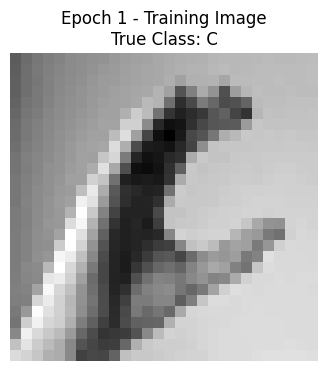



FORWARD PASS - EPOCH 1
input      Shape: (64, 1, 28, 28)      Mean:  0.599782 Min:  0.000000 Max:  1.000000
conv1      Shape: (64, 32, 28, 28)     Mean:  0.031097 Min: -1.145826 Max:  1.489874
relu1      Shape: (64, 32, 28, 28)     Mean:  0.185532 Min:  0.000000 Max:  1.489874
pool1      Shape: (64, 32, 14, 14)     Mean:  0.213546 Min:  0.000000 Max:  1.489874
conv2      Shape: (64, 64, 14, 14)     Mean: -0.001315 Min: -0.715187 Max:  0.724490
relu2      Shape: (64, 64, 14, 14)     Mean:  0.082256 Min:  0.000000 Max:  0.724490
pool2      Shape: (64, 64, 7, 7)       Mean:  0.103945 Min:  0.000000 Max:  0.724490
conv3      Shape: (64, 128, 7, 7)      Mean:  0.000565 Min: -0.443187 Max:  0.395769
relu3      Shape: (64, 128, 7, 7)      Mean:  0.040549 Min:  0.000000 Max:  0.395769
pool3      Shape: (64, 128, 3, 3)      Mean:  0.055234 Min:  0.000000 Max:  0.395769
flatten    Shape: (64, 1152)           Mean:  0.055234 Min:  0.000000 Max:  0.395769
fc1        Shape: (64, 256)            M

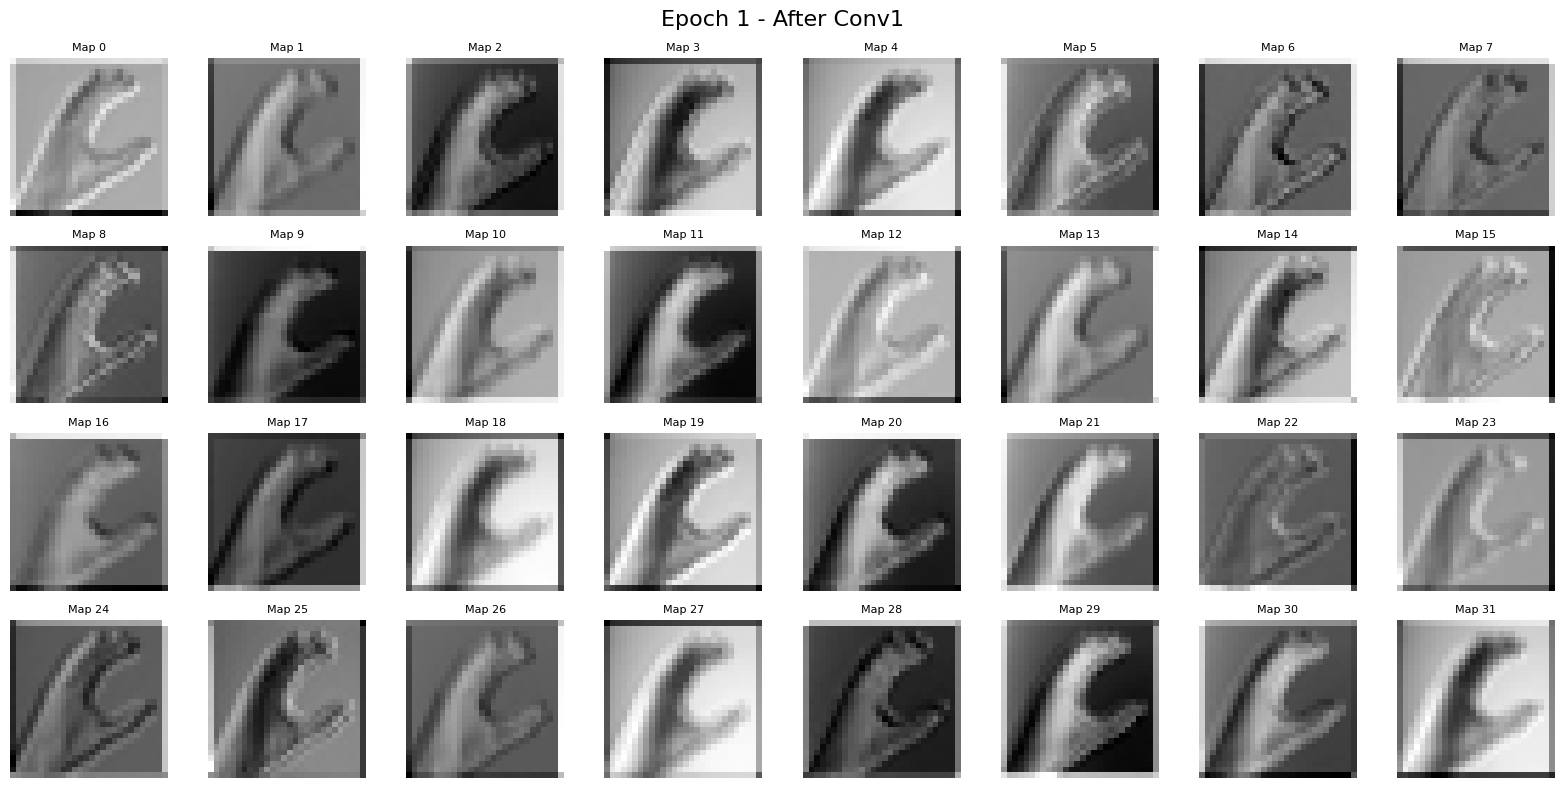

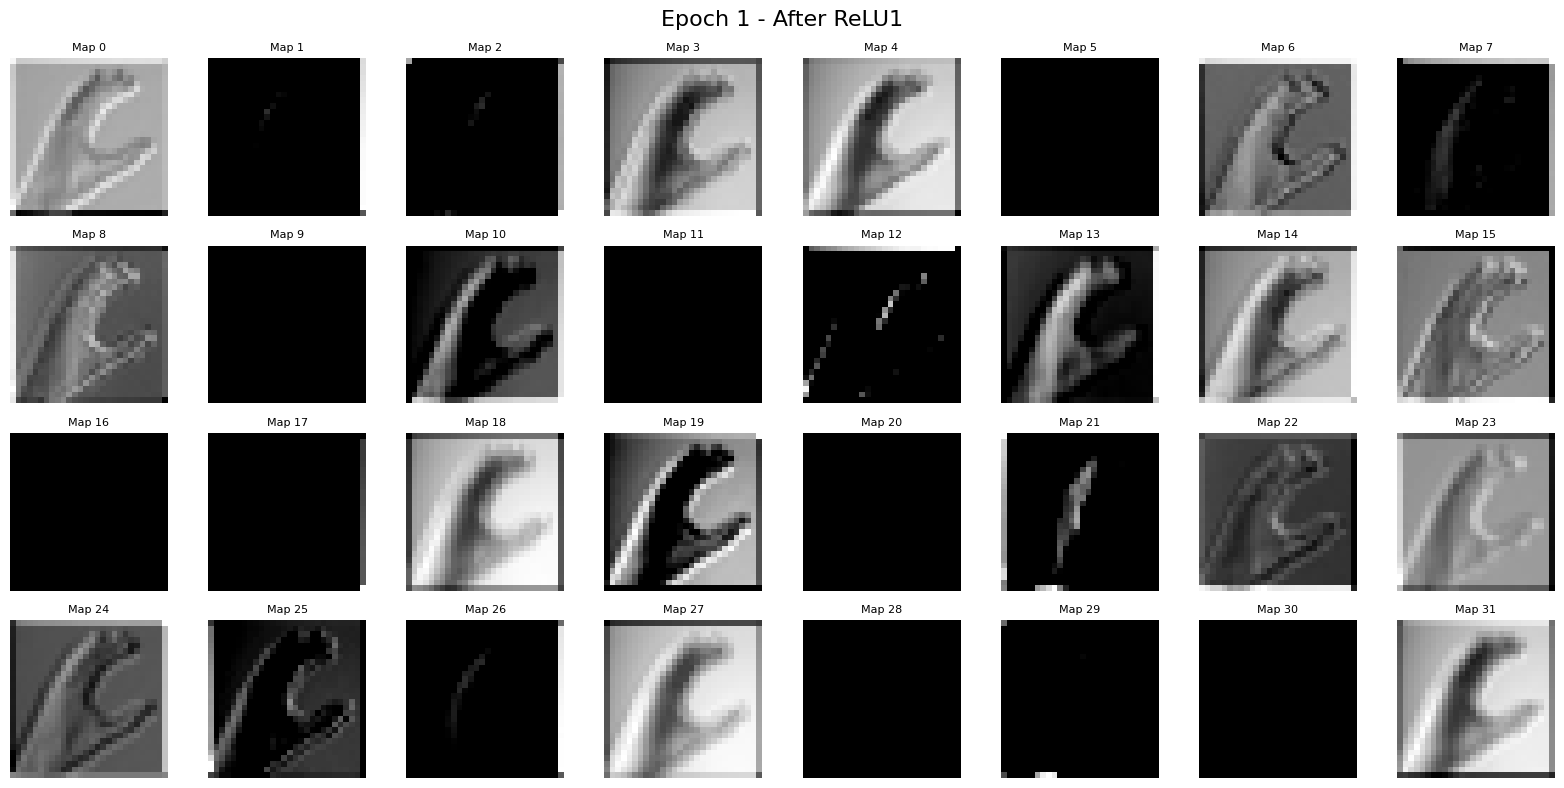

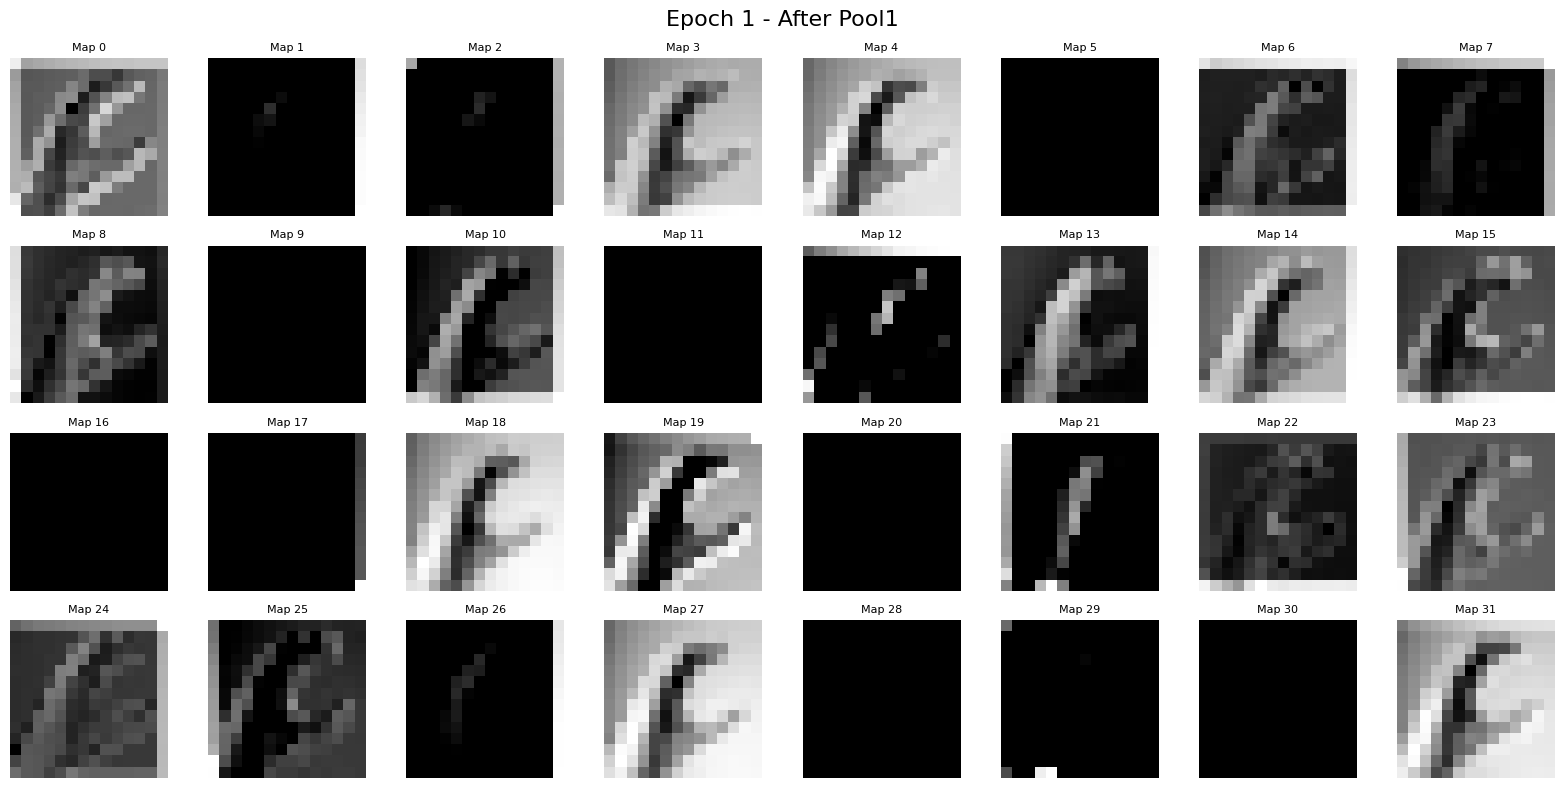

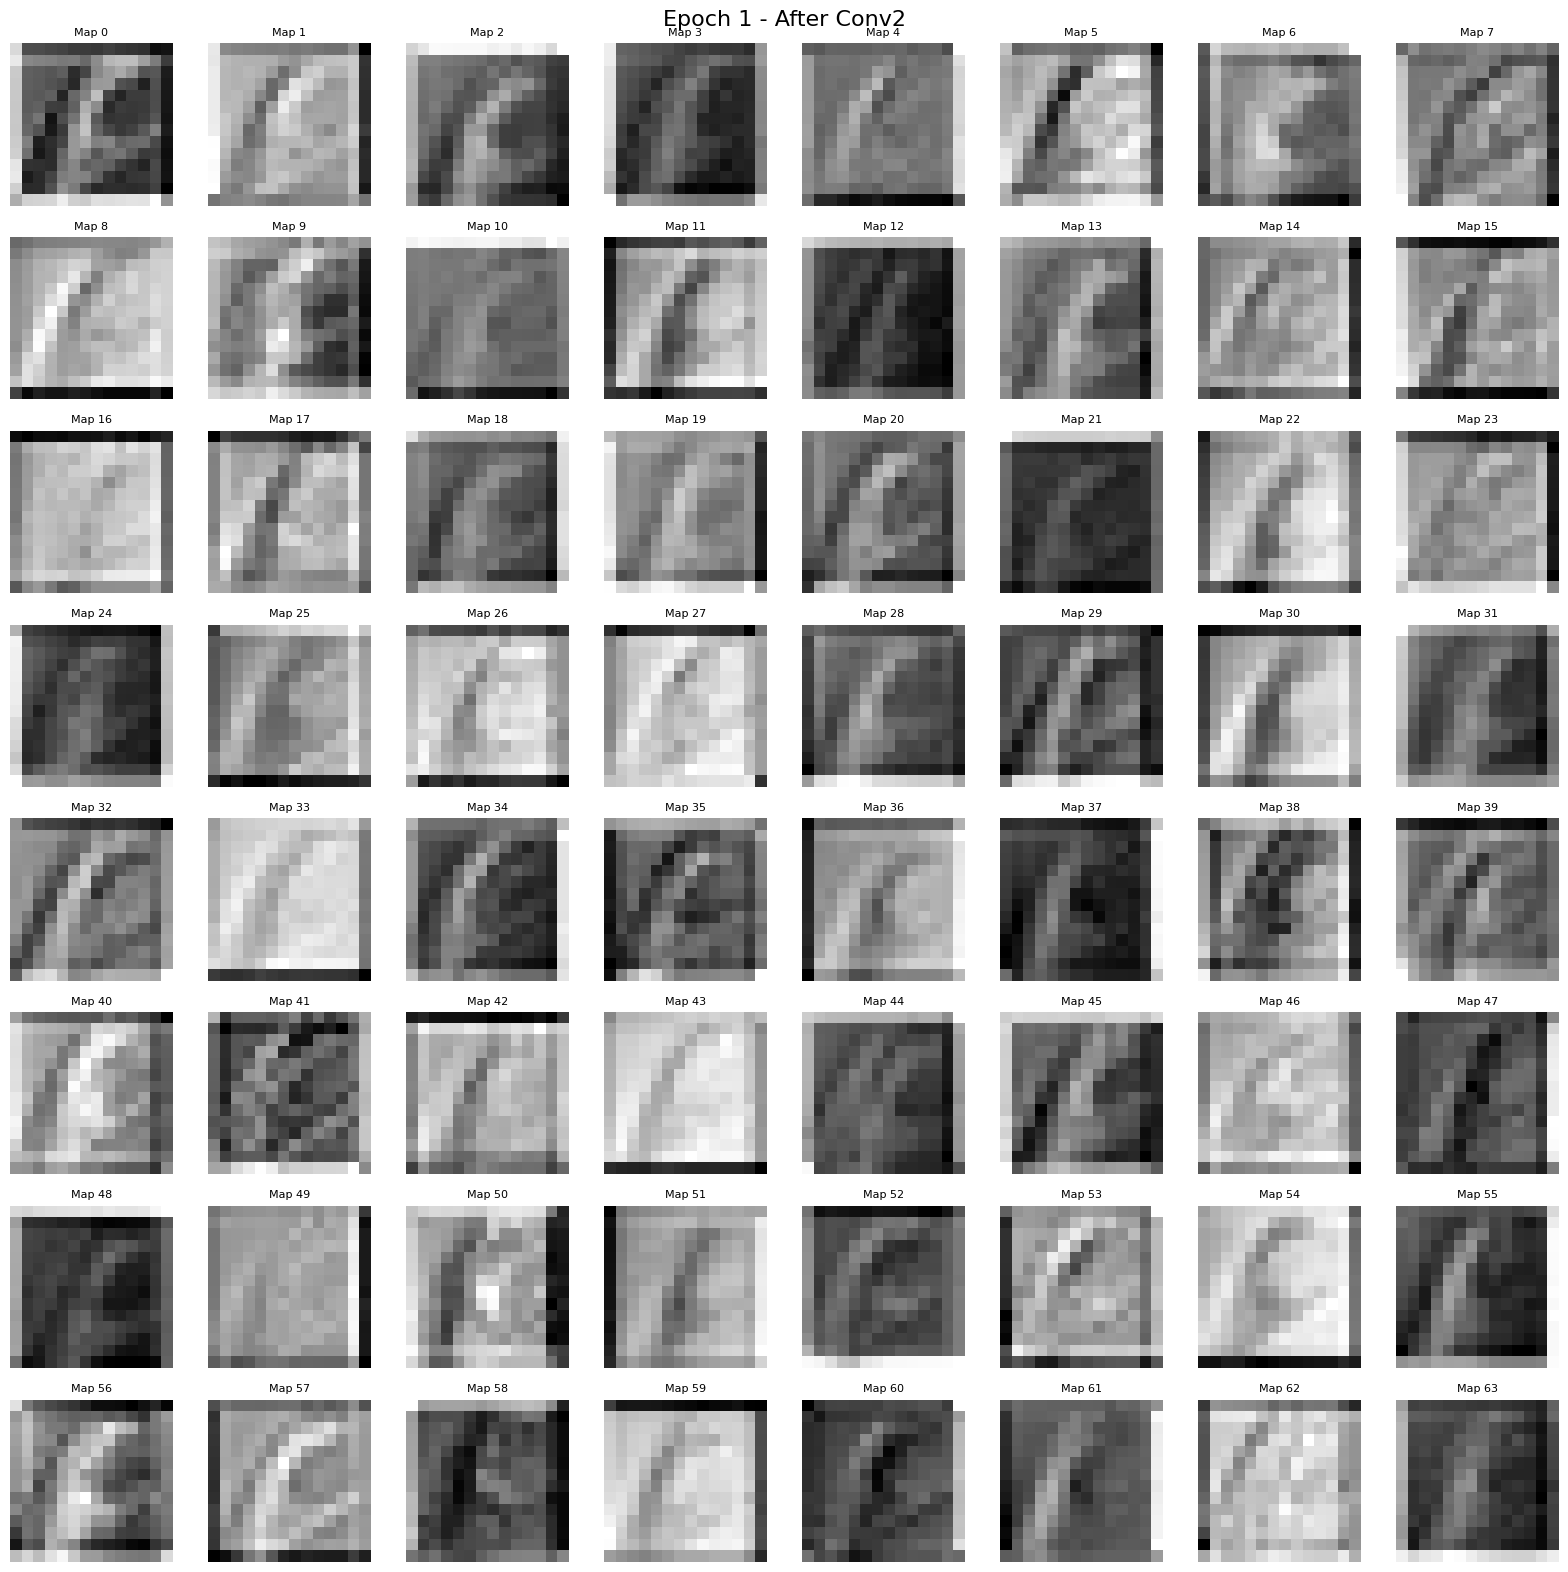

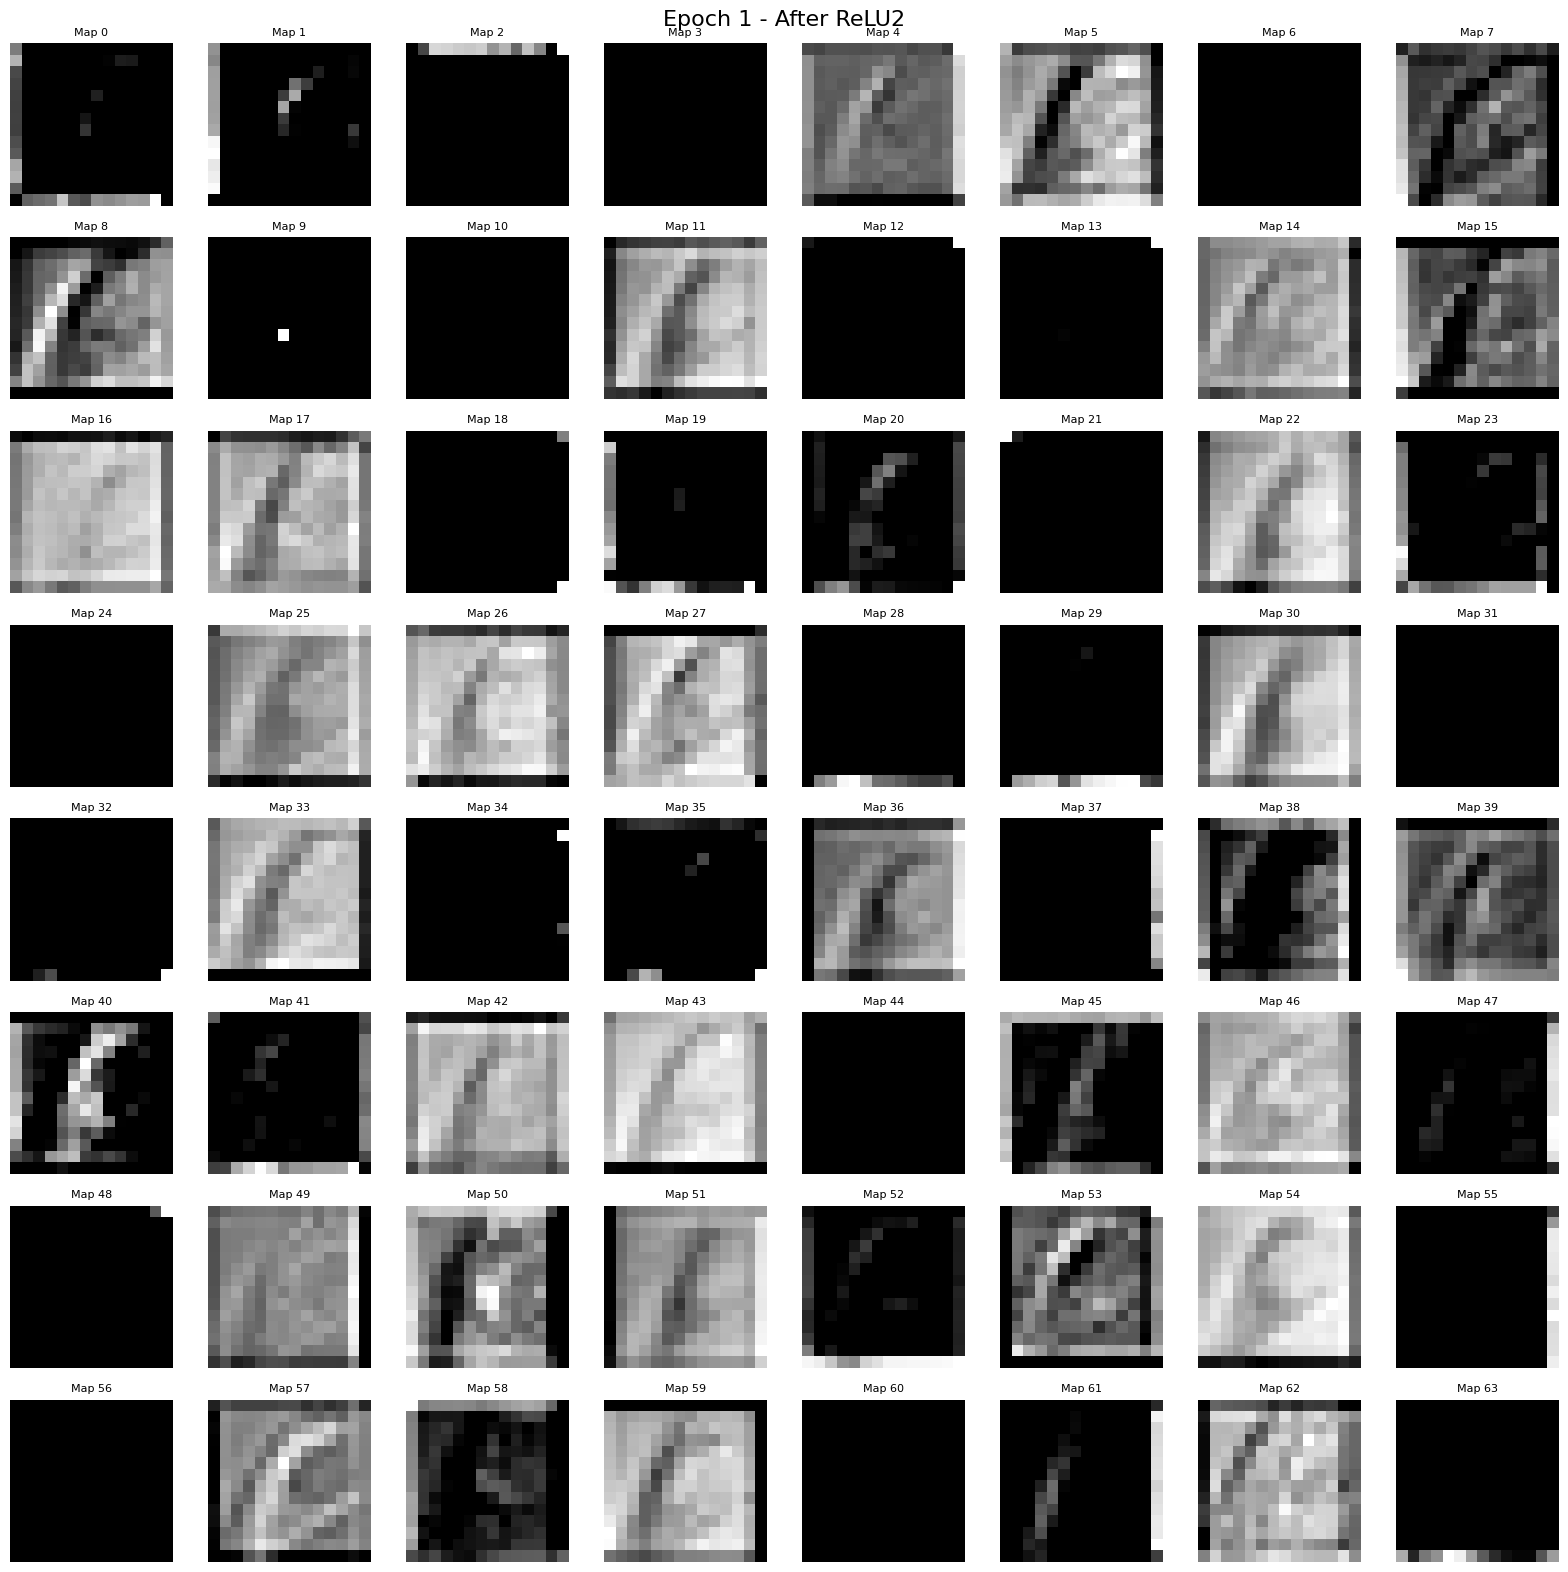

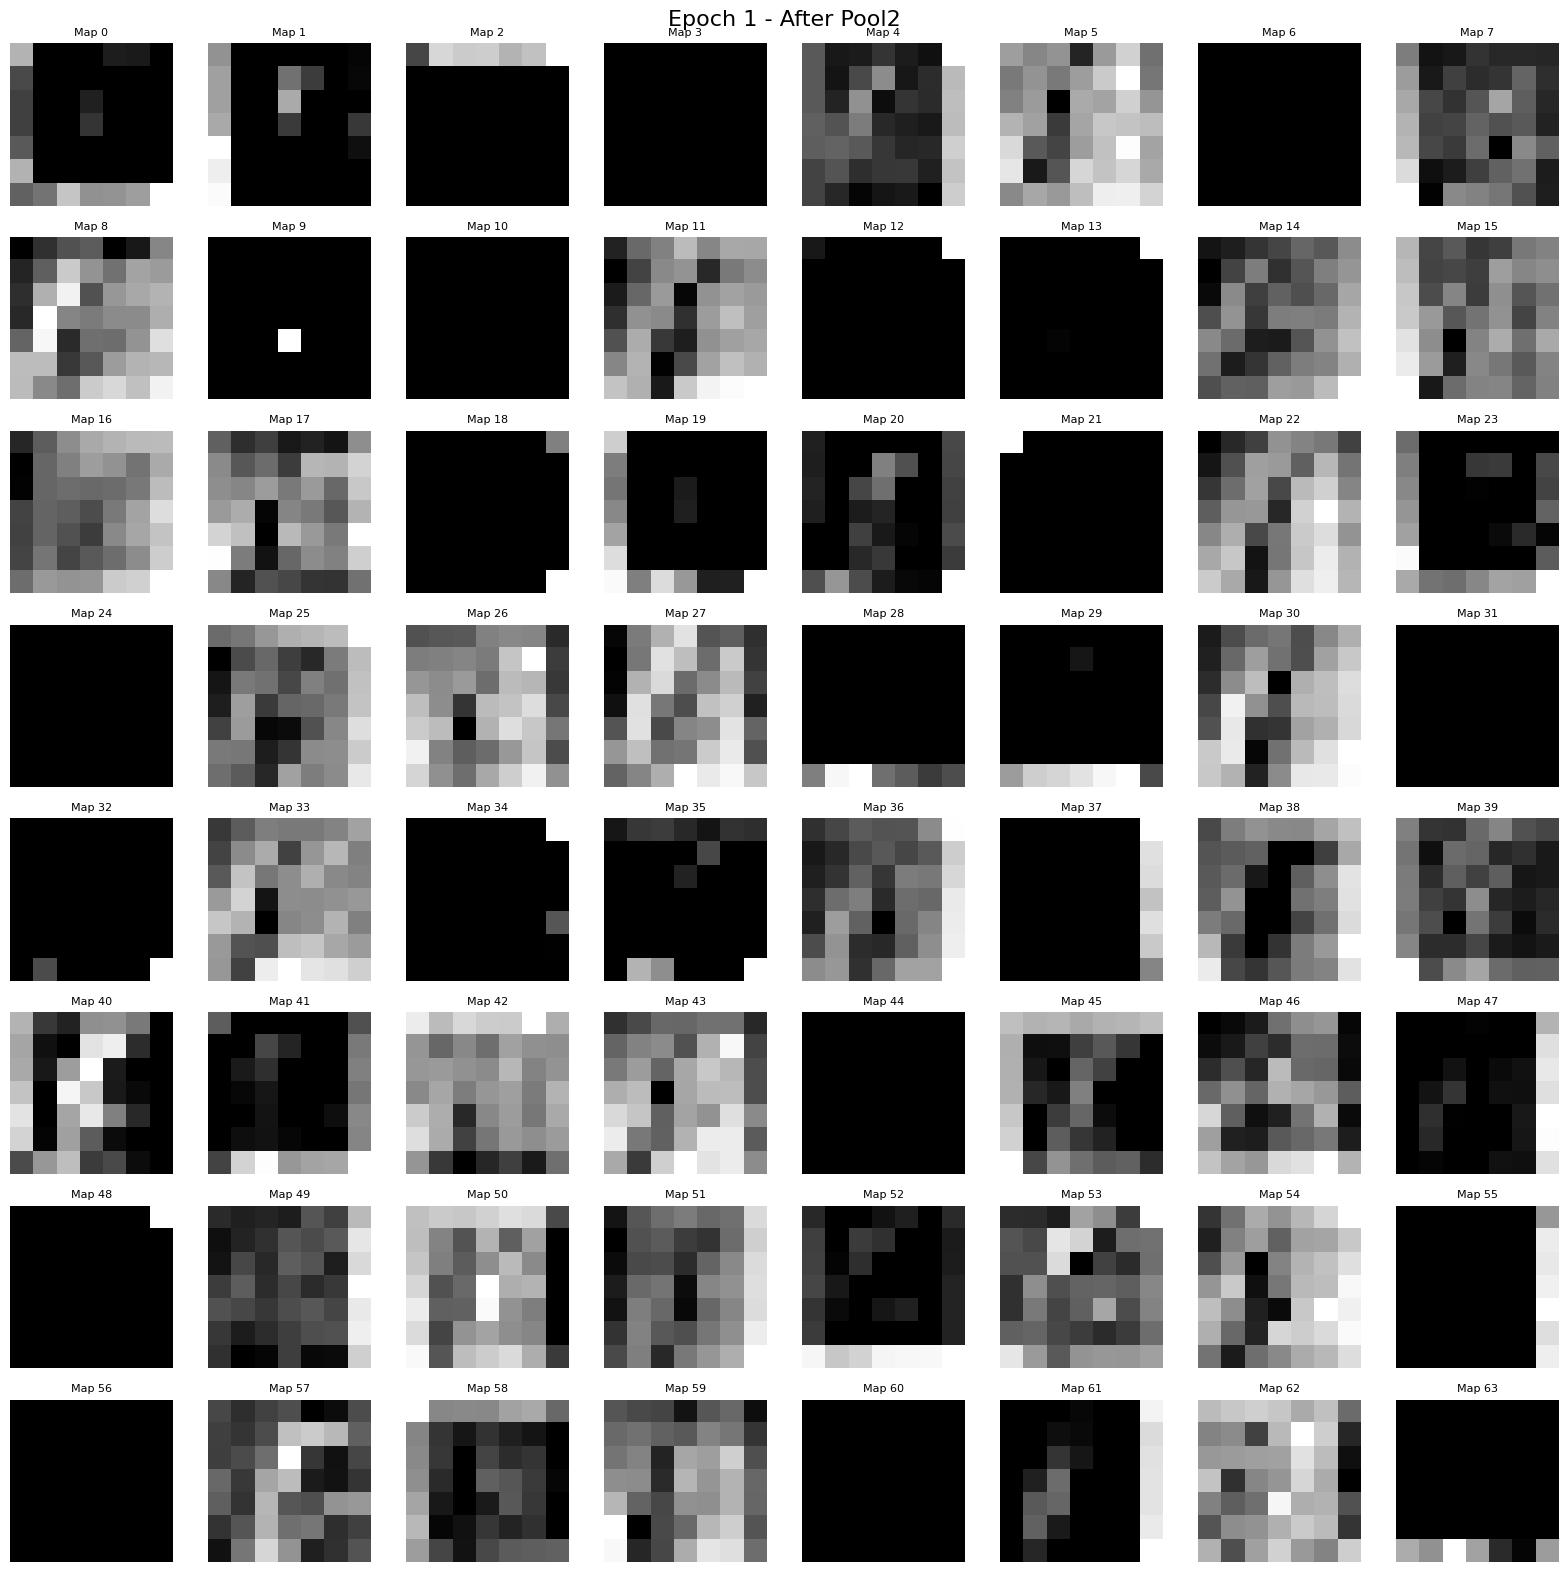

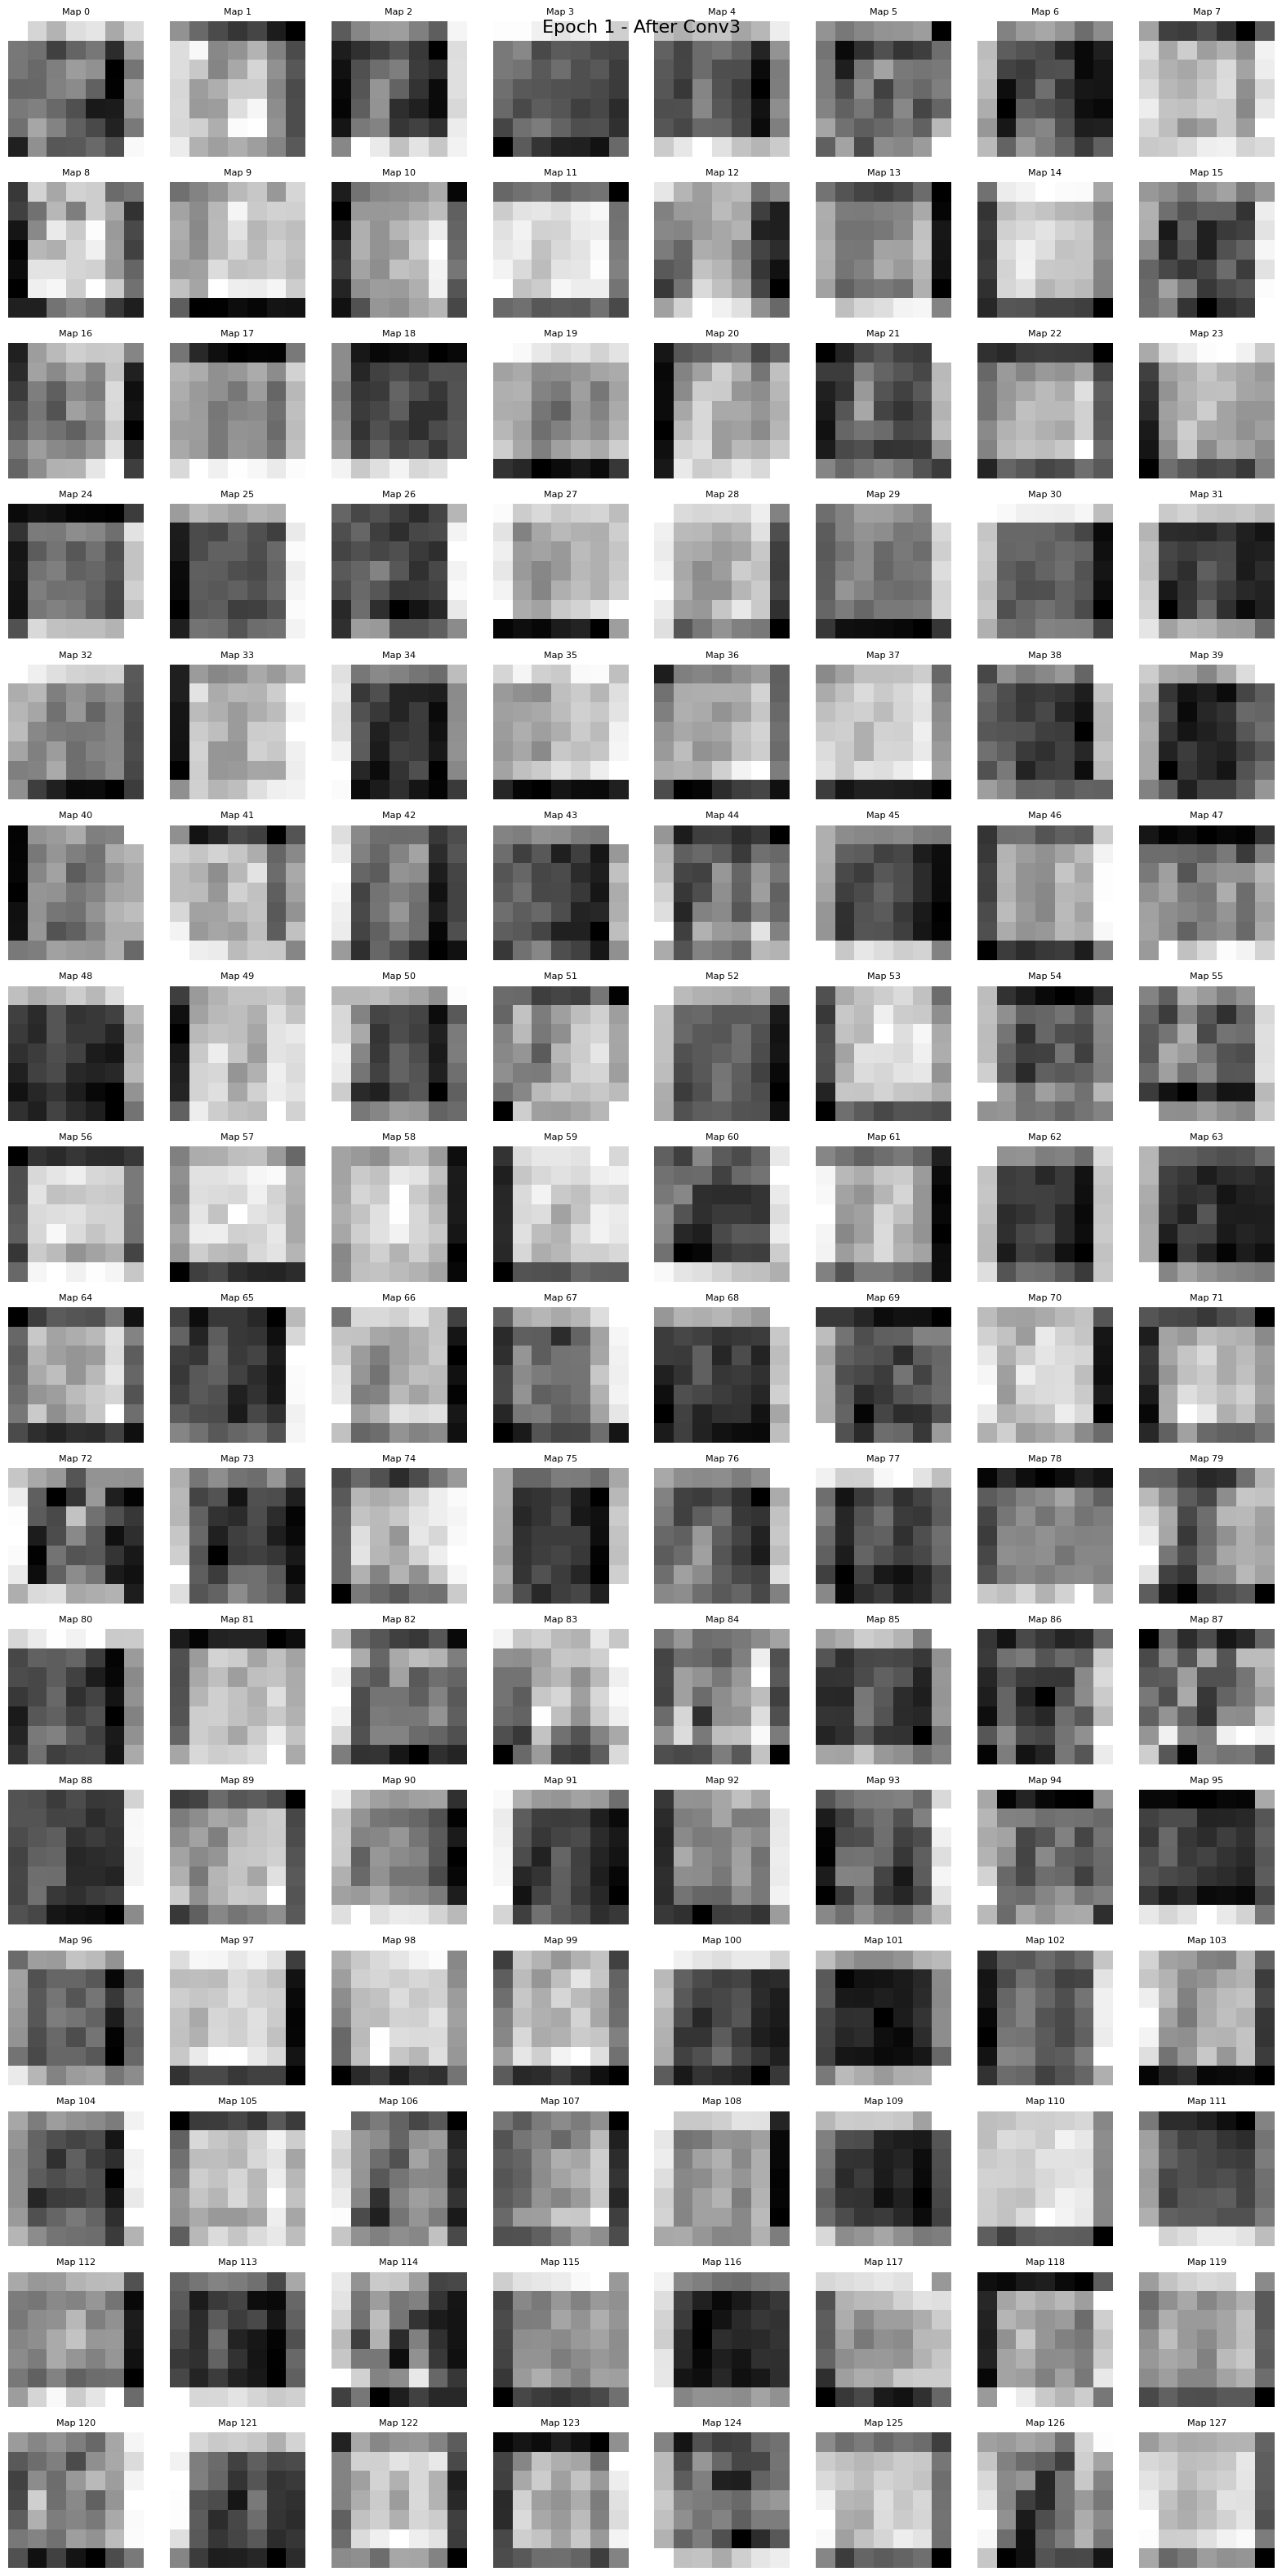

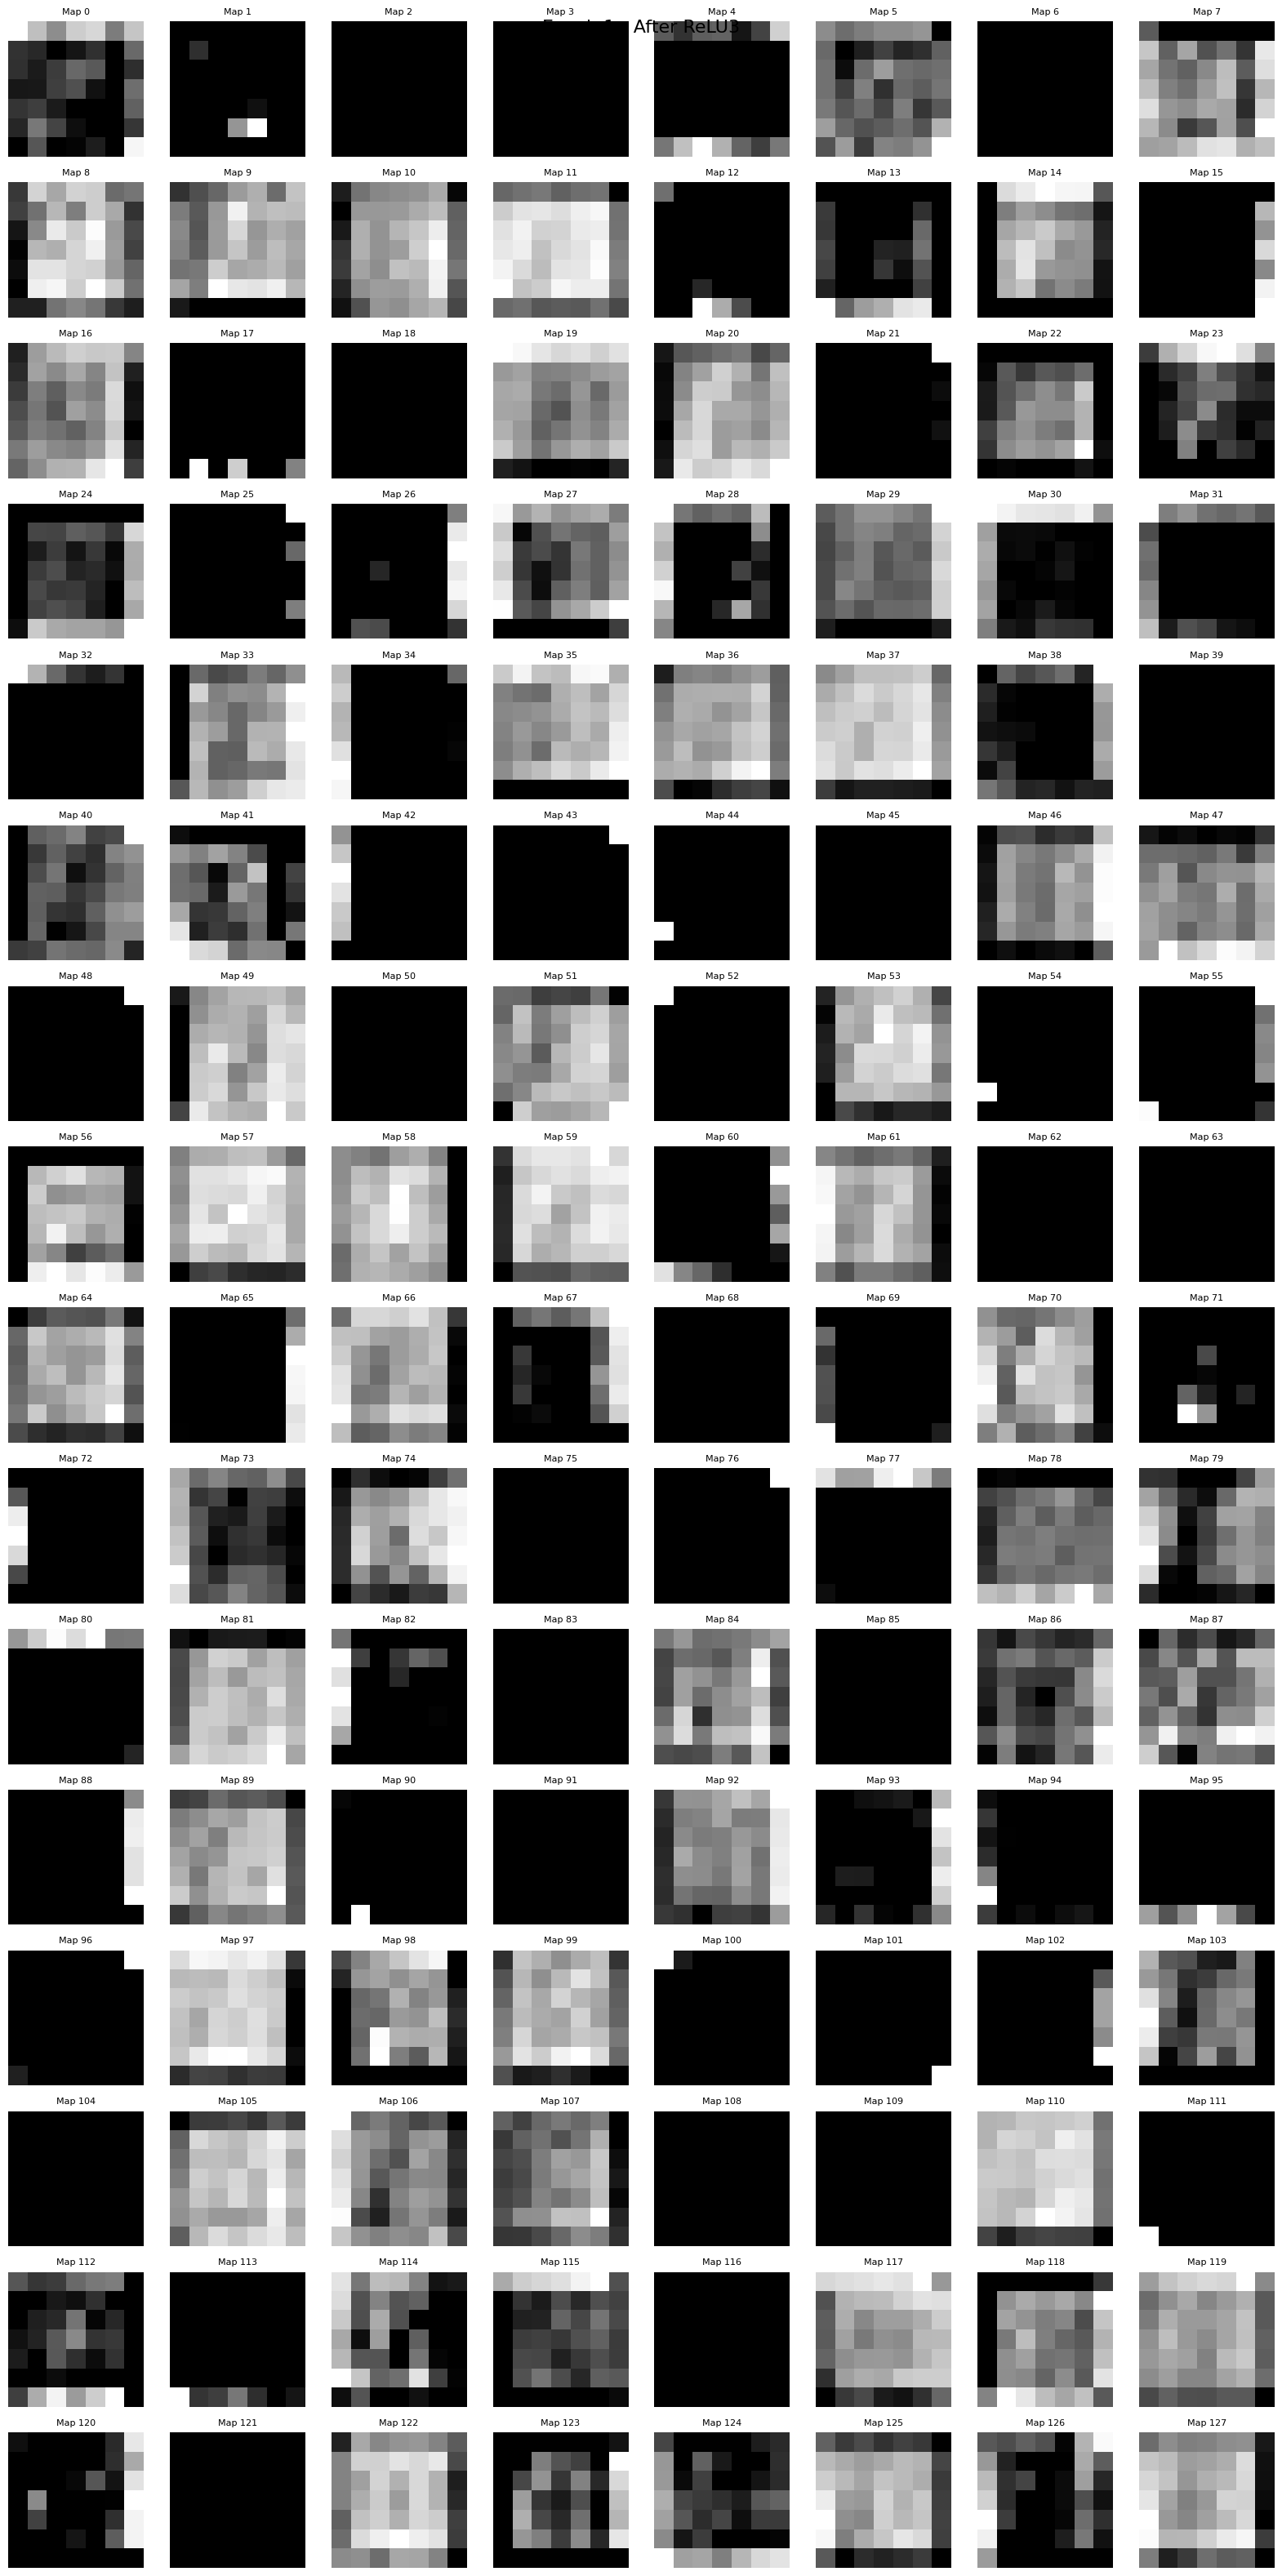

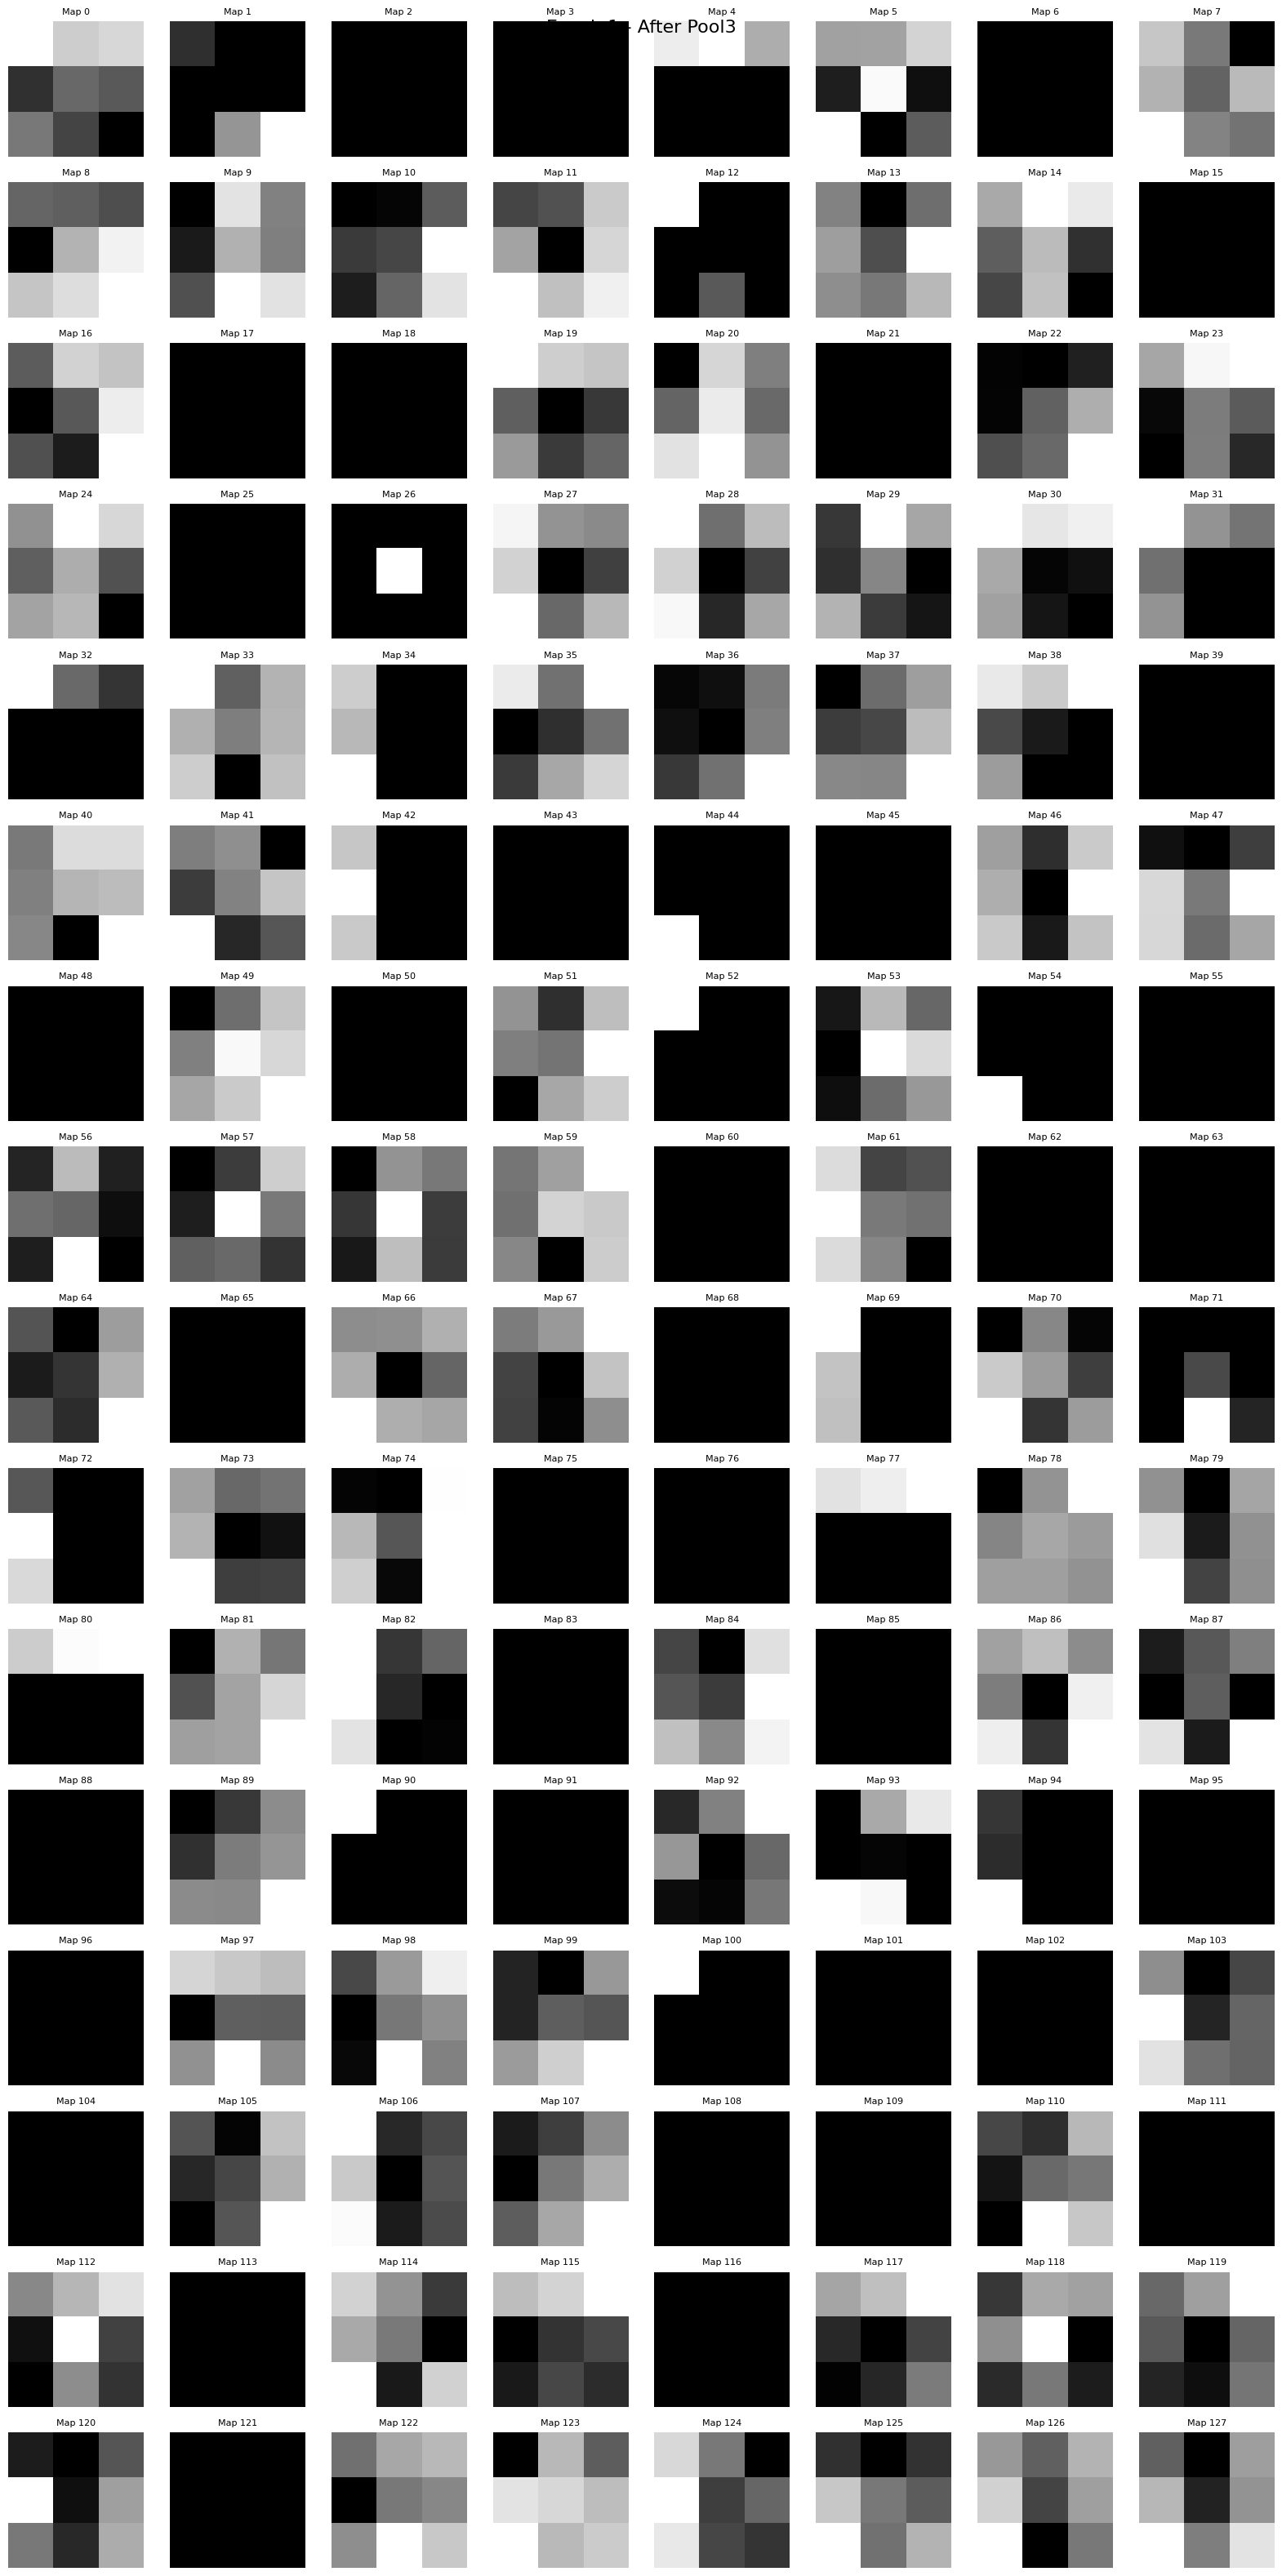


AFTER FLATTEN
Shape: (1152,)
First 40 values:
tensor([0.0509, 0.0409, 0.0429, 0.0097, 0.0209, 0.0177, 0.0239, 0.0136, 0.0000,
        0.0008, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0024, 0.0041,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0219, 0.0237, 0.0161, 0.0000])

AFTER LINEAR 1
Shape: (256,)
First 40 values:
tensor([ 0.0917,  0.0634, -0.0326, -0.0585, -0.0388, -0.0014, -0.0388, -0.0232,
        -0.0436,  0.0074,  0.0621,  0.0259,  0.0754, -0.1083, -0.0622, -0.0222,
        -0.0344,  0.0105,  0.0398,  0.0290, -0.0360, -0.0137,  0.0308, -0.0360,
         0.0709, -0.0082, -0.0404,  0.0645, -0.0184,  0.0391,  0.0326, -0.0063,
        -0.0491, -0.0371,  0.0414,  0.0777,  0.0339,  0.0031, -0.0323, -0.1175])

AFTER RELU
Shape: (256,)
First 40 values:
tensor([0.0917, 0.0634, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0074, 0.062

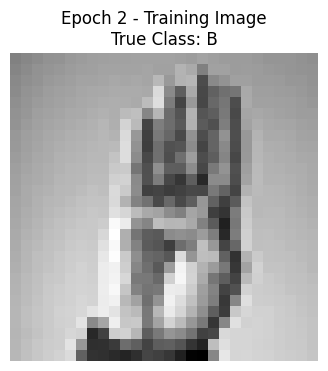



FORWARD PASS - EPOCH 2
input      Shape: (64, 1, 28, 28)      Mean:  0.615324 Min:  0.000000 Max:  1.000000
conv1      Shape: (64, 32, 28, 28)     Mean:  0.032878 Min: -1.160549 Max:  1.552509
relu1      Shape: (64, 32, 28, 28)     Mean:  0.189647 Min:  0.000000 Max:  1.552509
pool1      Shape: (64, 32, 14, 14)     Mean:  0.218089 Min:  0.000000 Max:  1.552509
conv2      Shape: (64, 64, 14, 14)     Mean: -0.002205 Min: -0.730748 Max:  0.823166
relu2      Shape: (64, 64, 14, 14)     Mean:  0.088901 Min:  0.000000 Max:  0.823166
pool2      Shape: (64, 64, 7, 7)       Mean:  0.110899 Min:  0.000000 Max:  0.823166
conv3      Shape: (64, 128, 7, 7)      Mean:  0.000877 Min: -0.527048 Max:  0.595289
relu3      Shape: (64, 128, 7, 7)      Mean:  0.047888 Min:  0.000000 Max:  0.595289
pool3      Shape: (64, 128, 3, 3)      Mean:  0.063885 Min:  0.000000 Max:  0.595289
flatten    Shape: (64, 1152)           Mean:  0.063885 Min:  0.000000 Max:  0.595289
fc1        Shape: (64, 256)            M

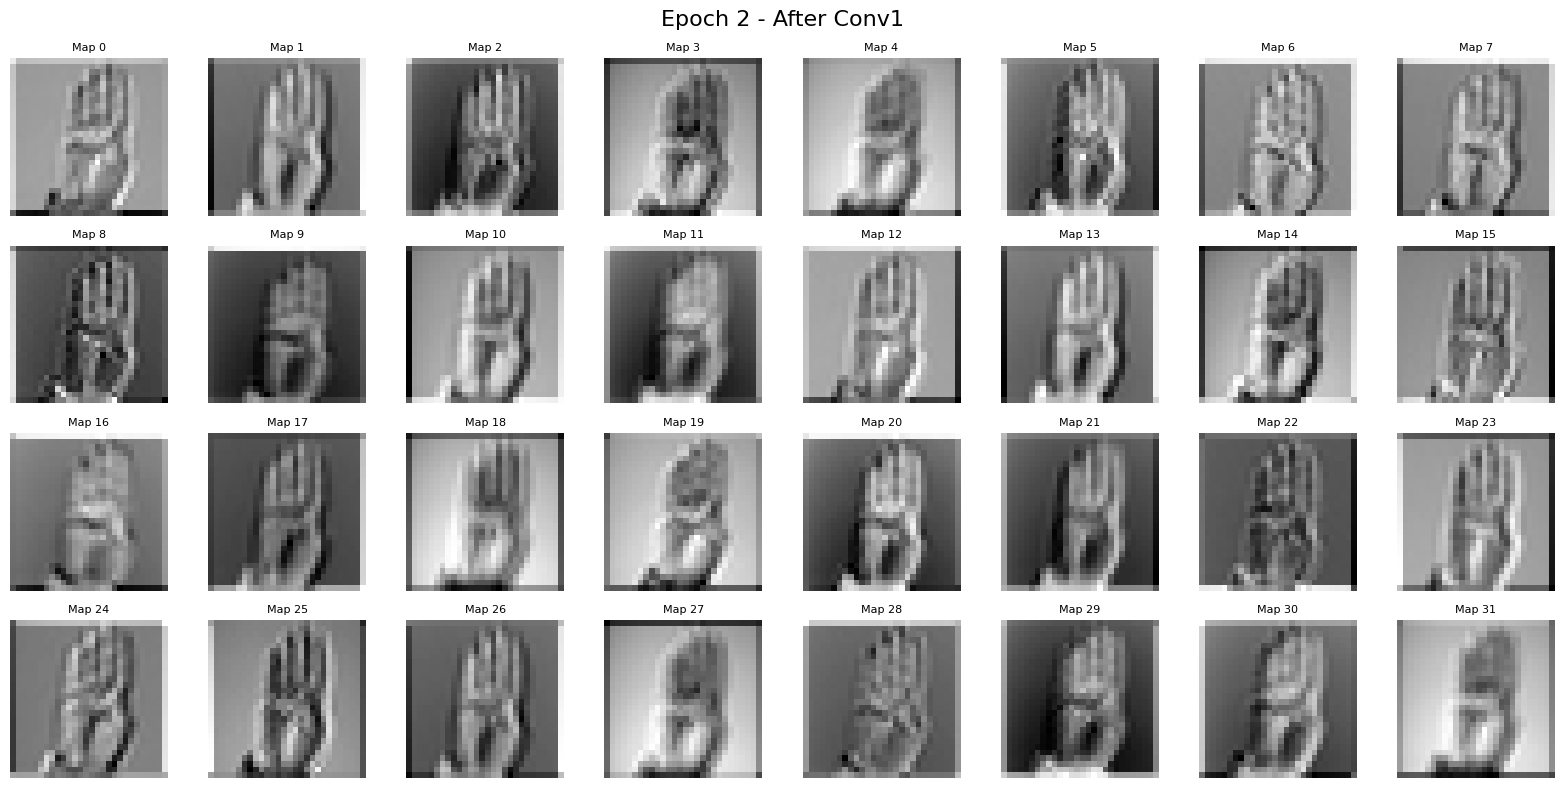

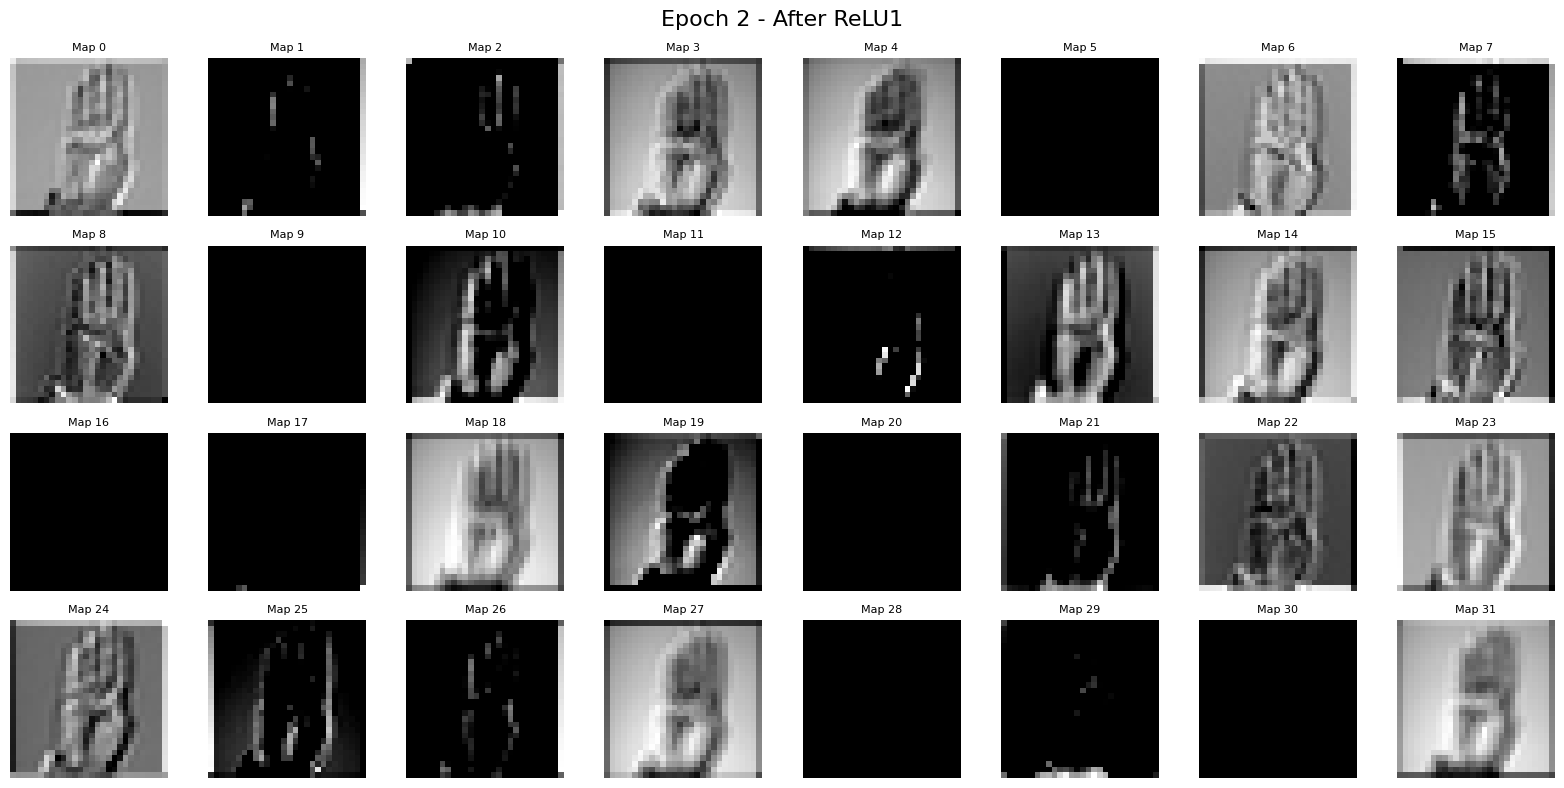

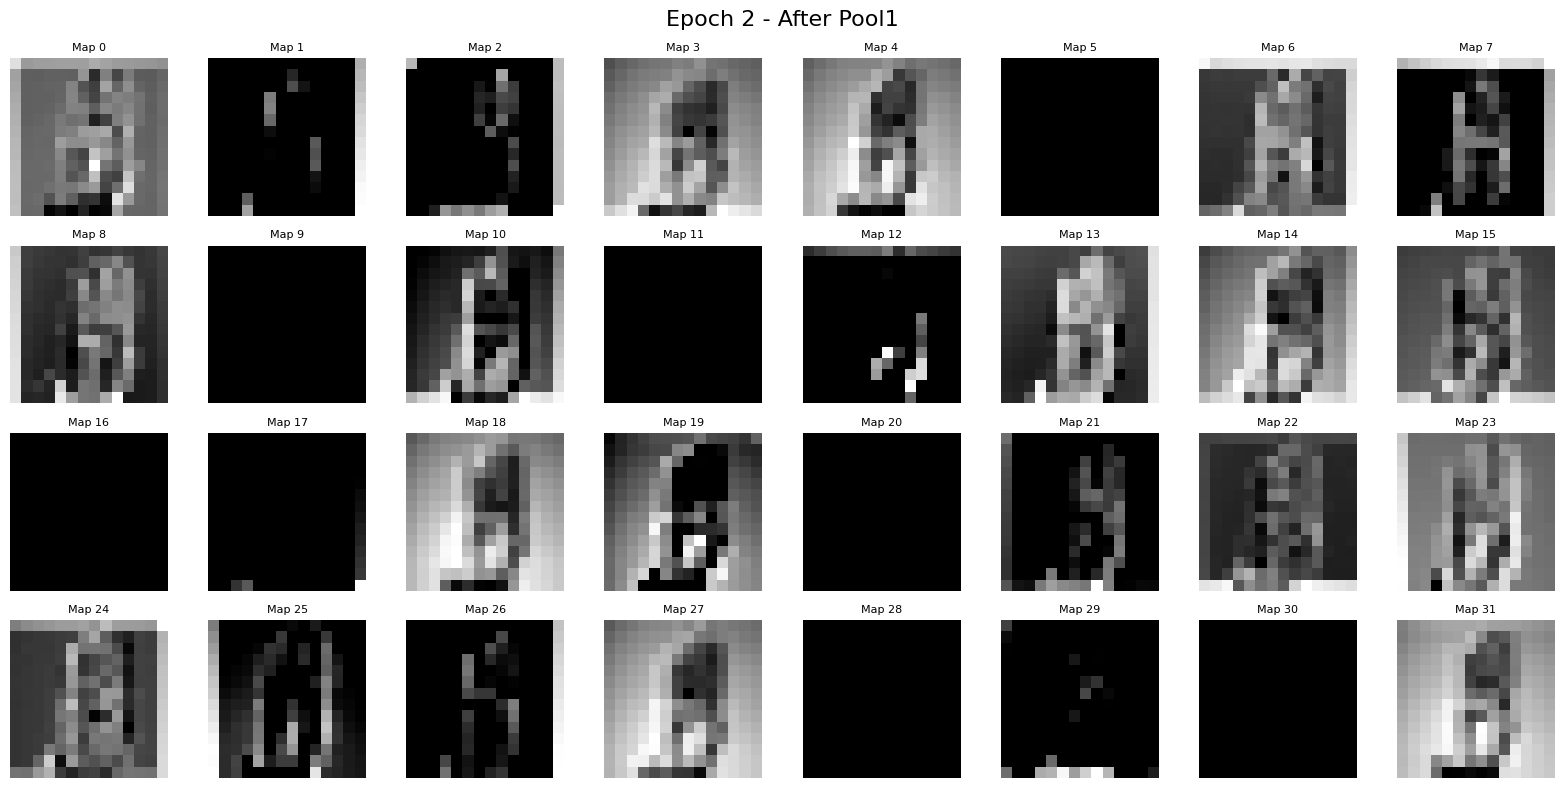

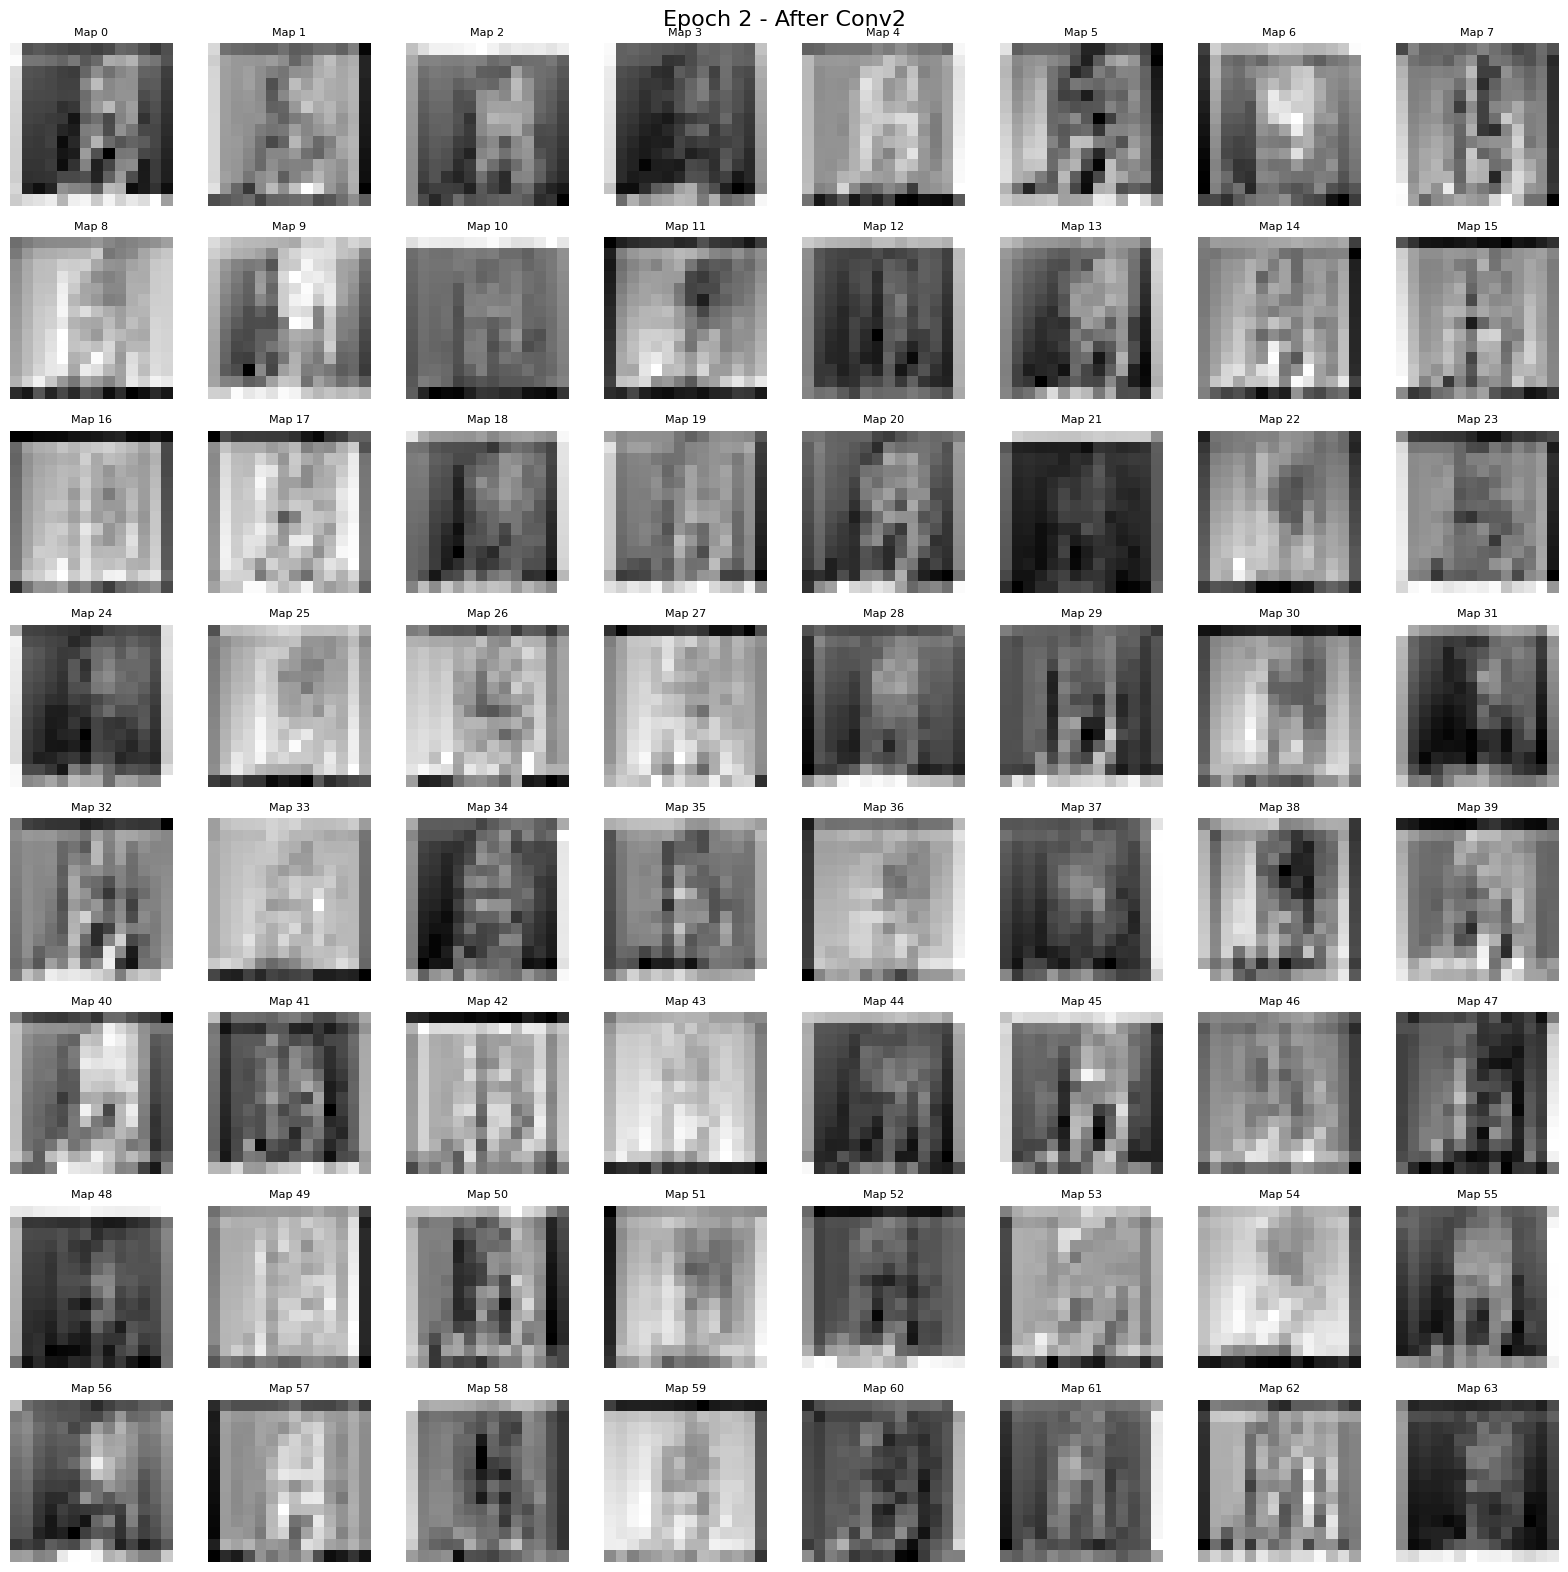

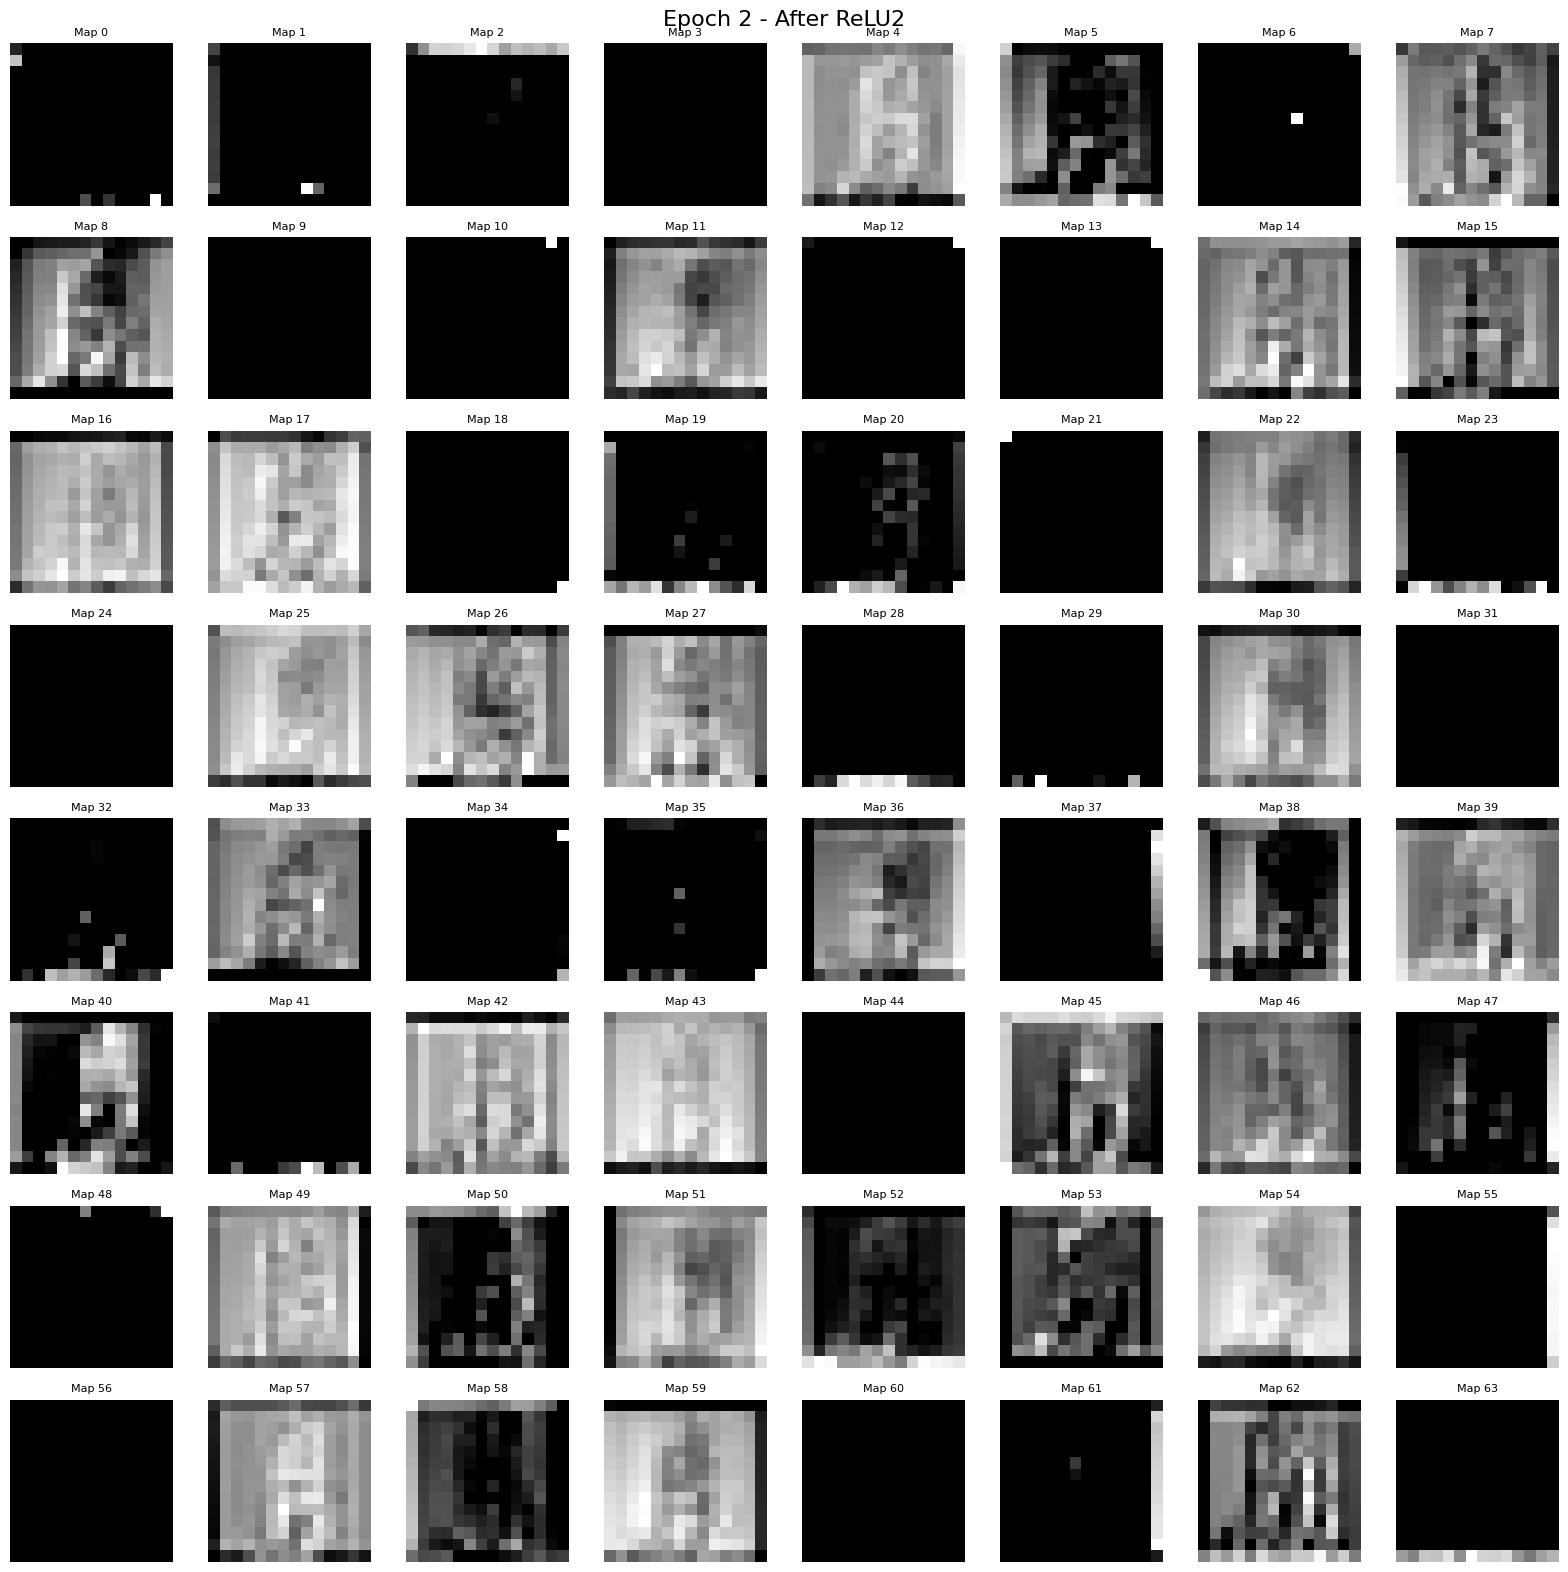

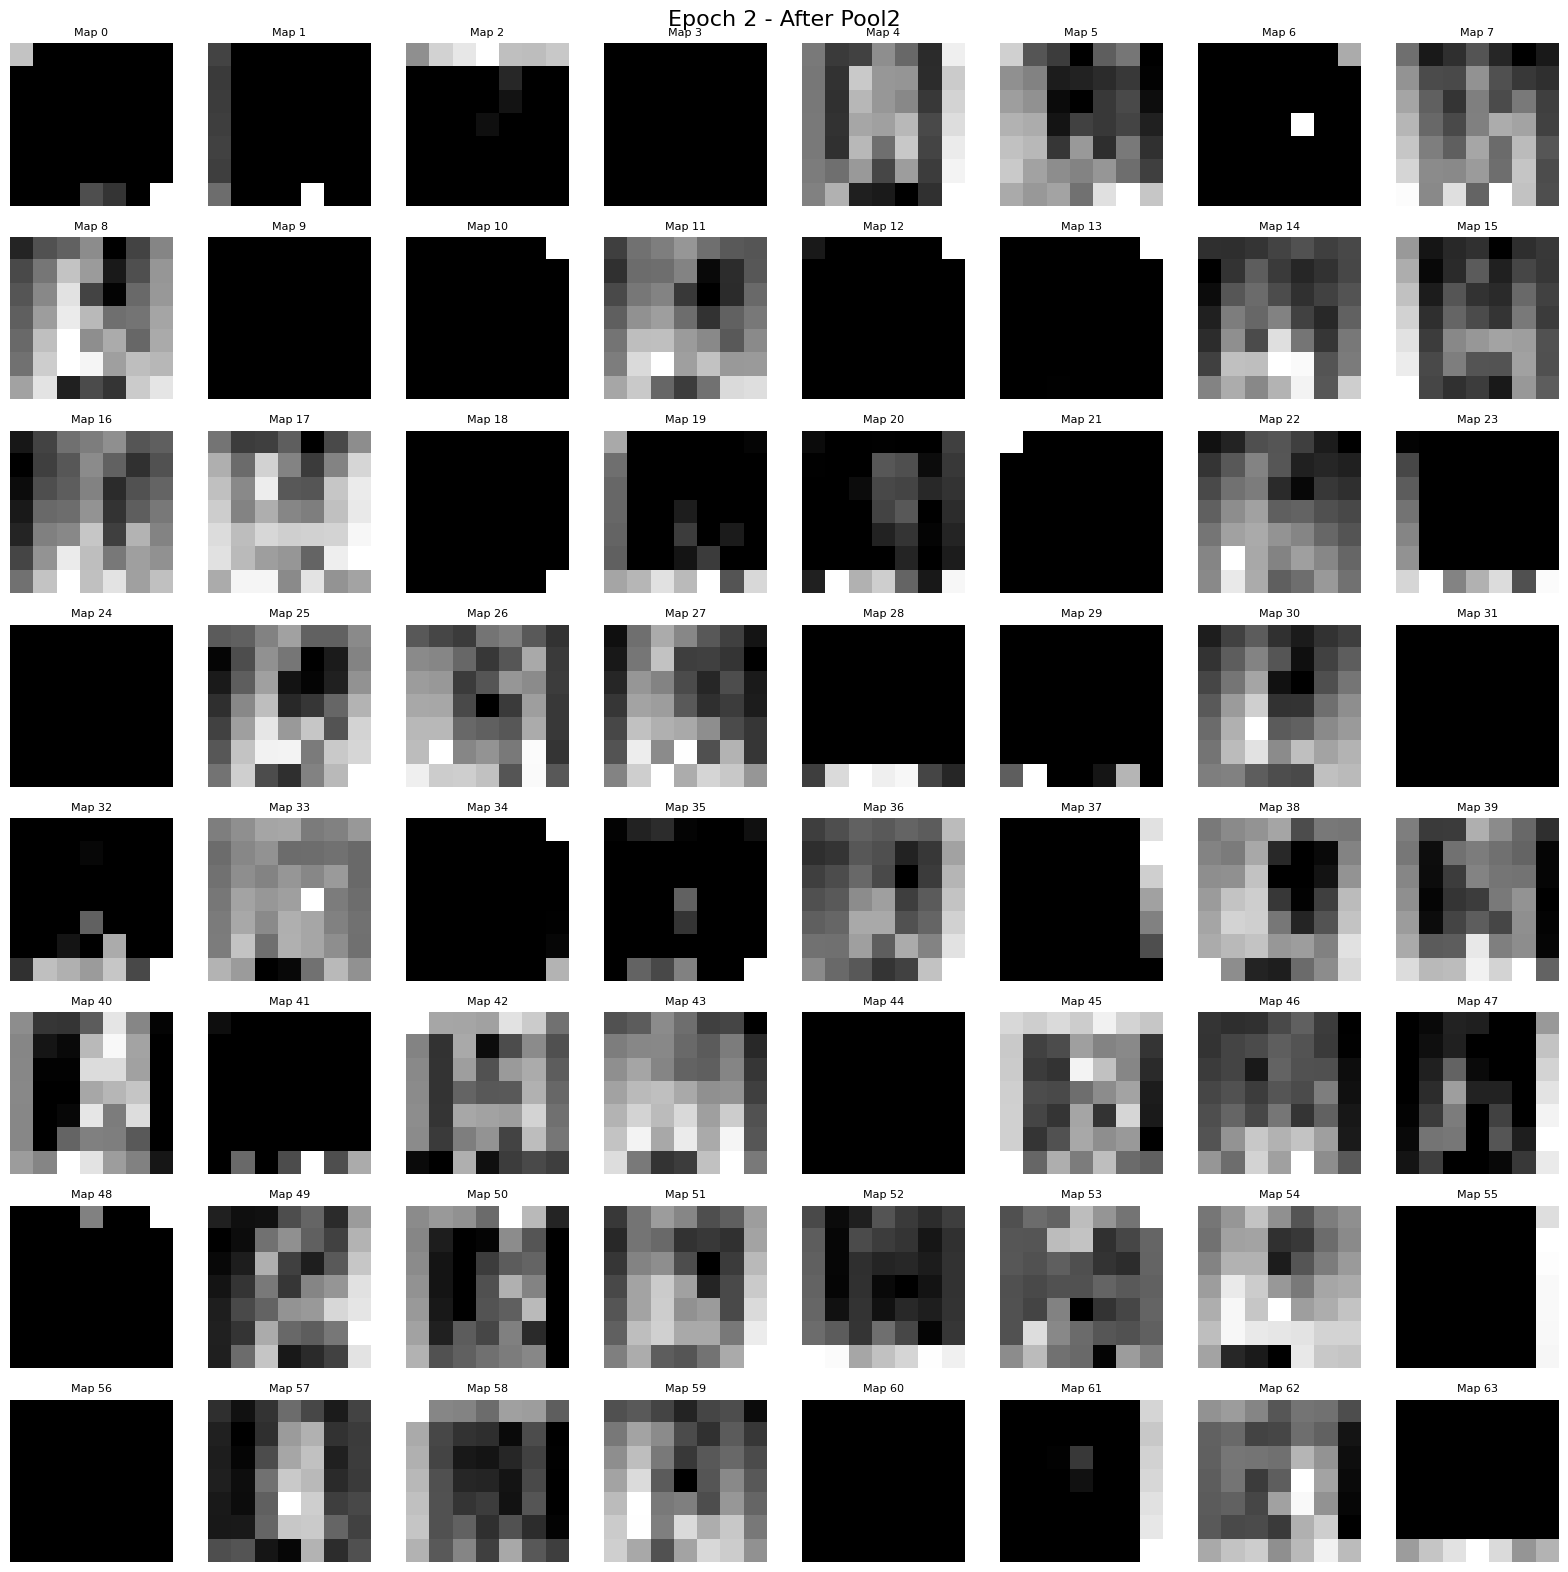

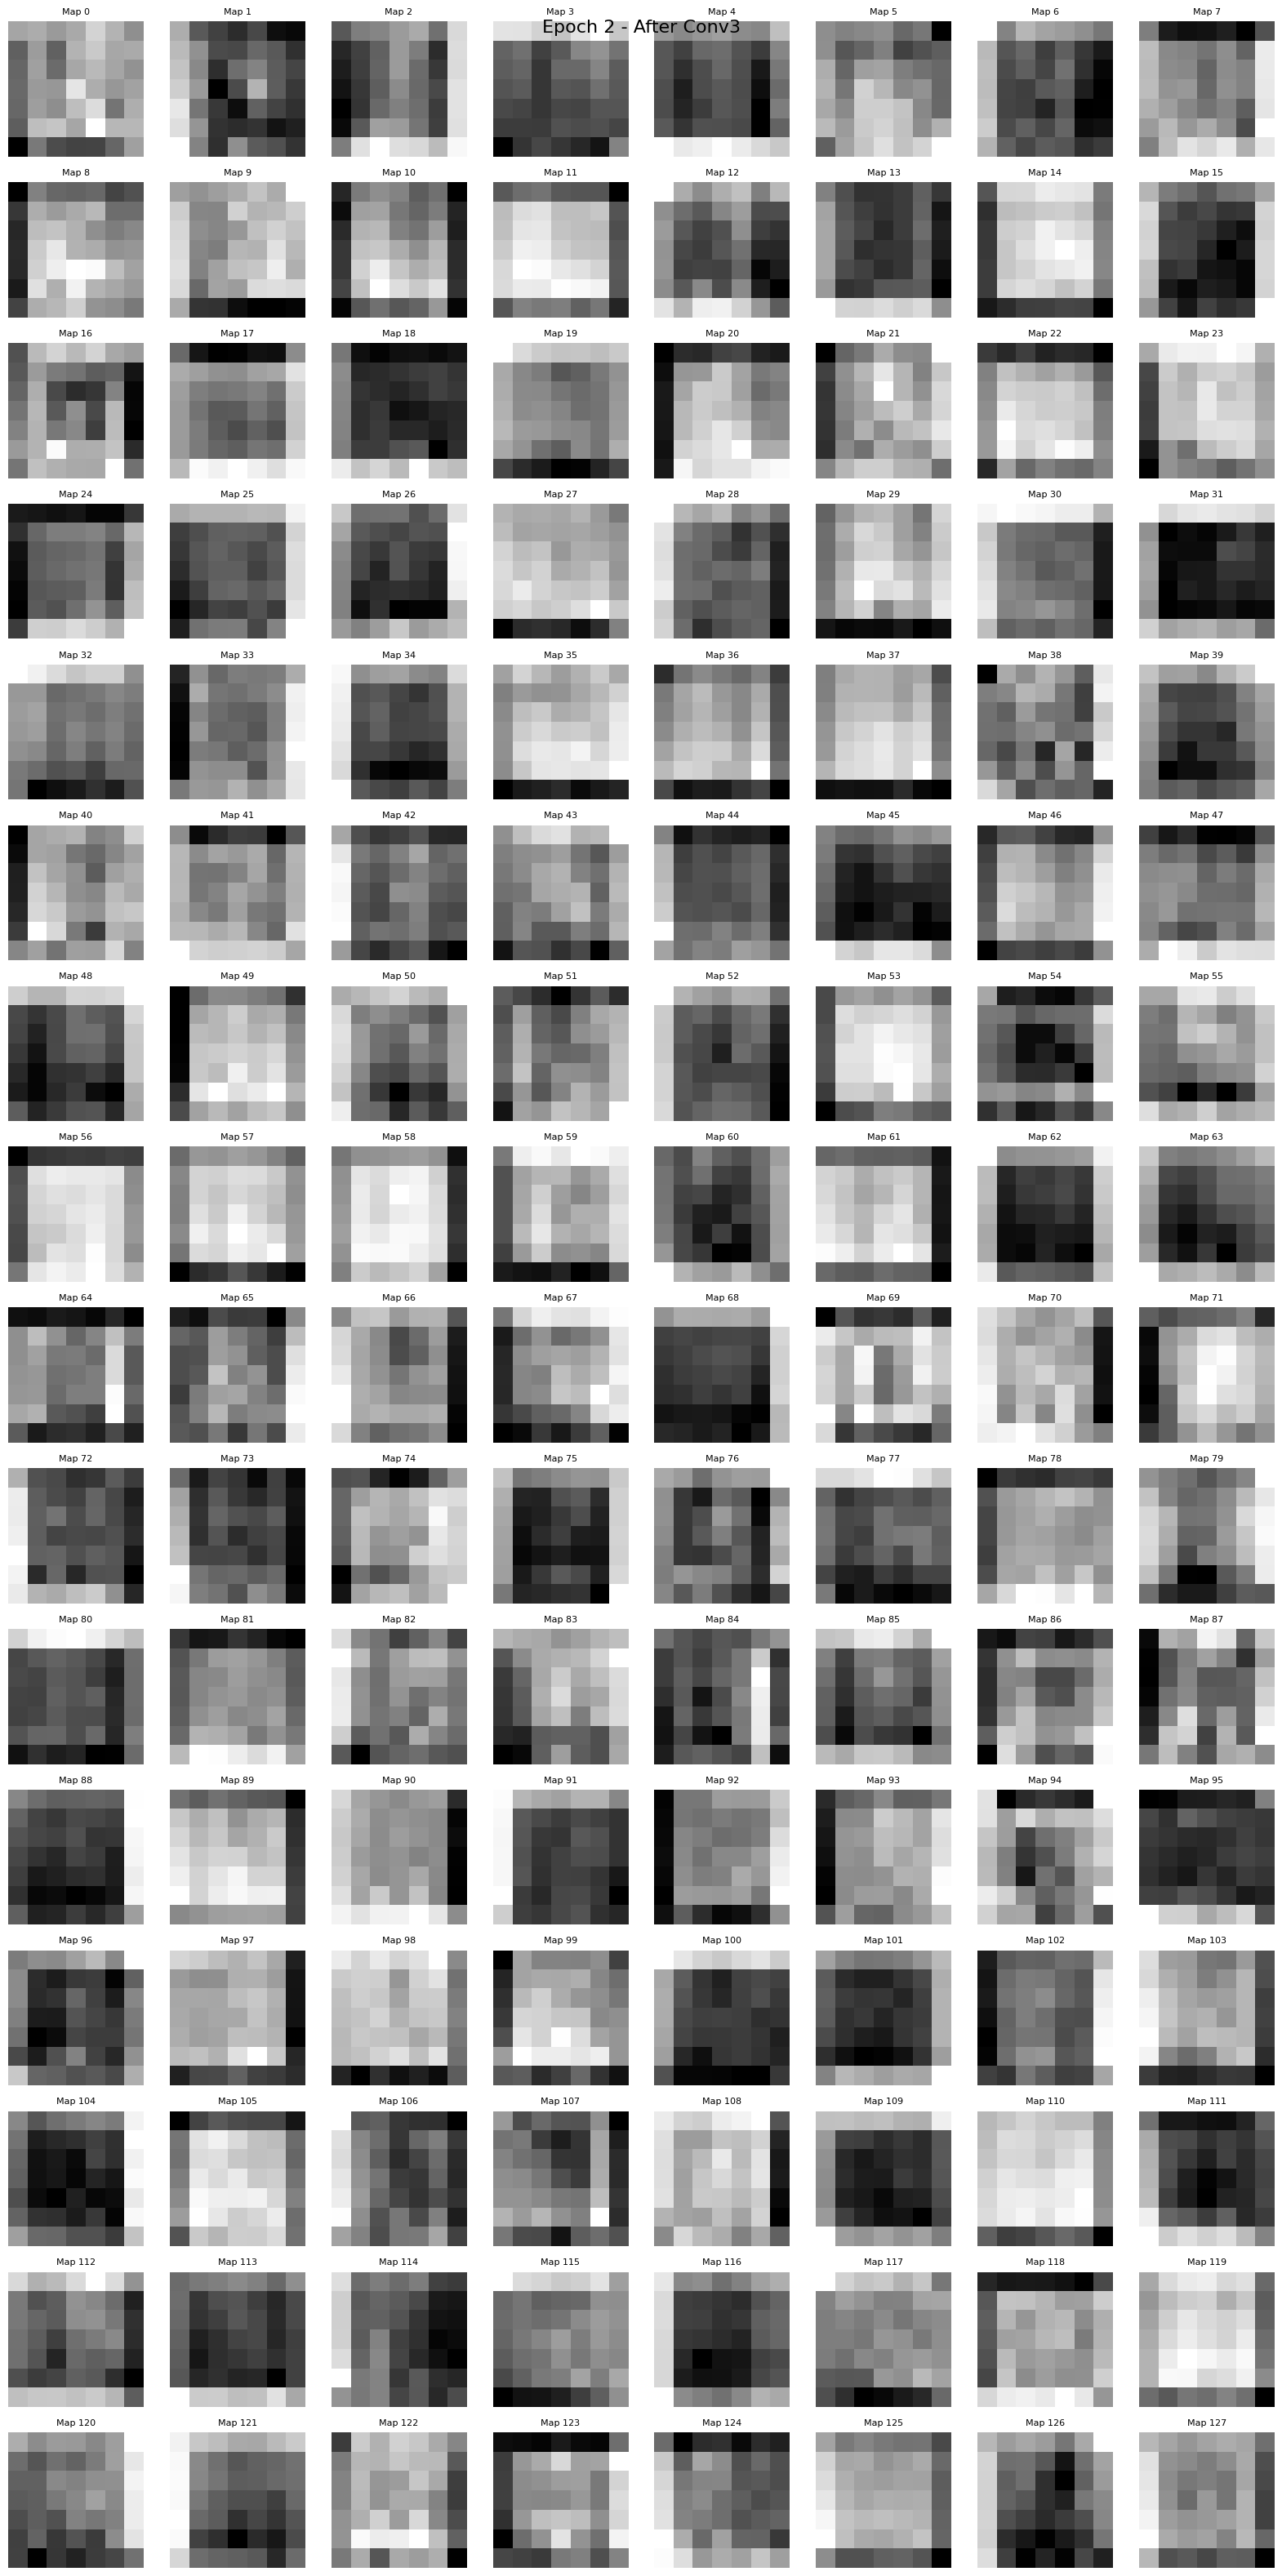

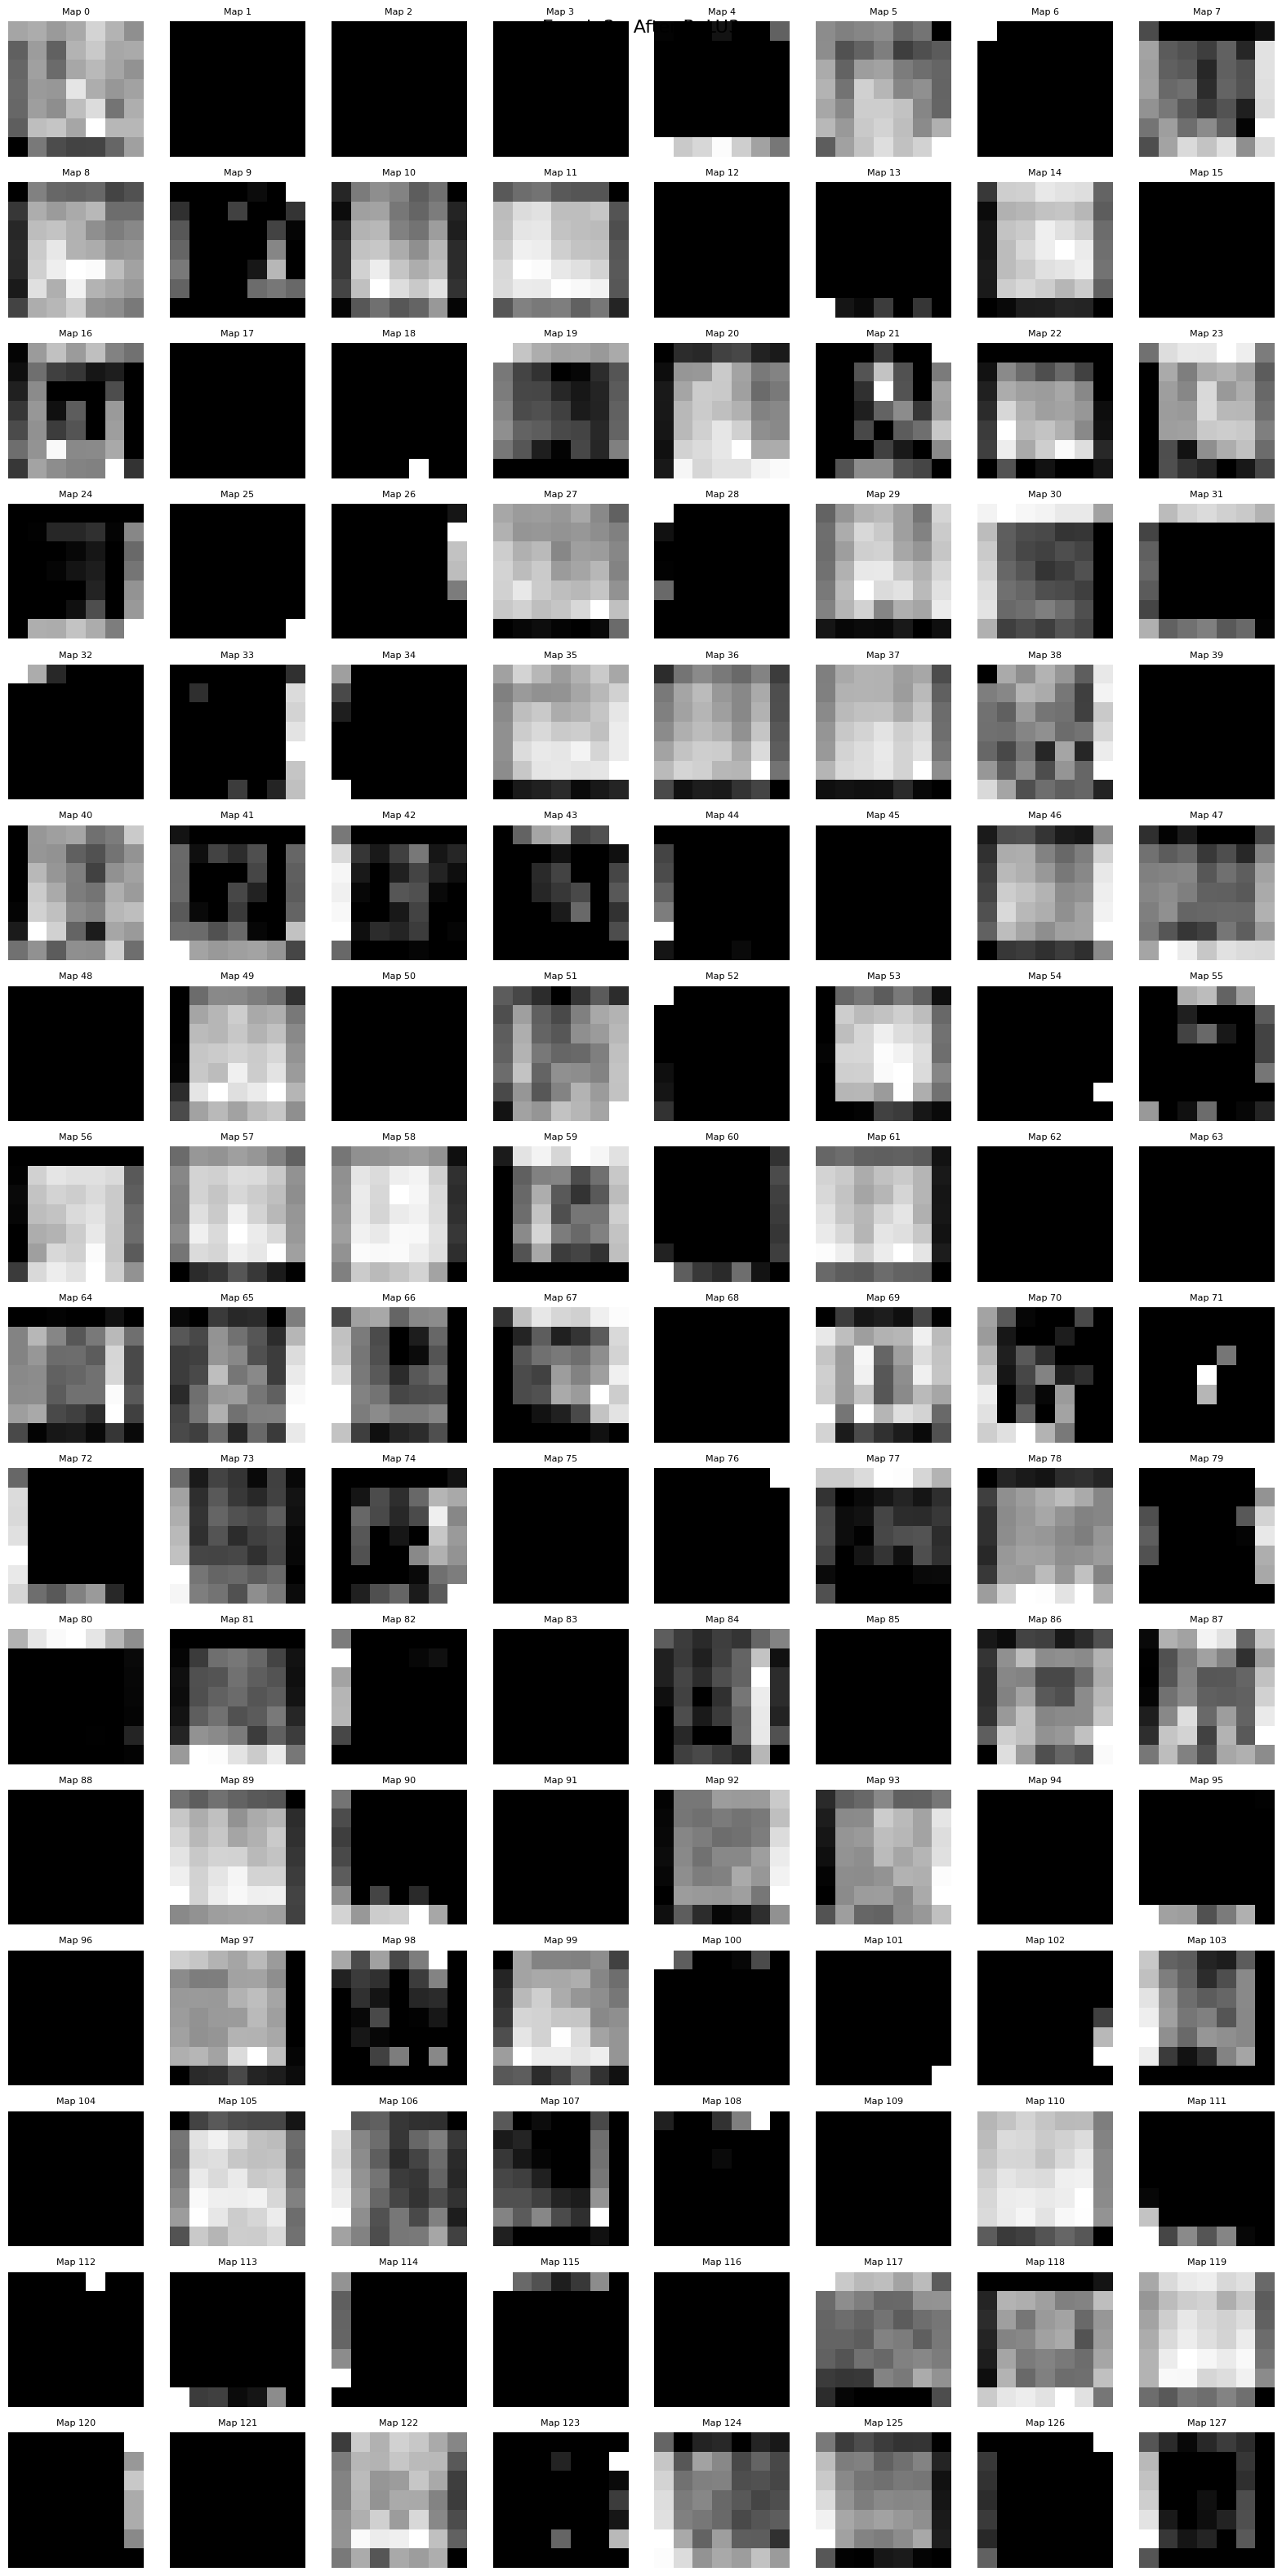

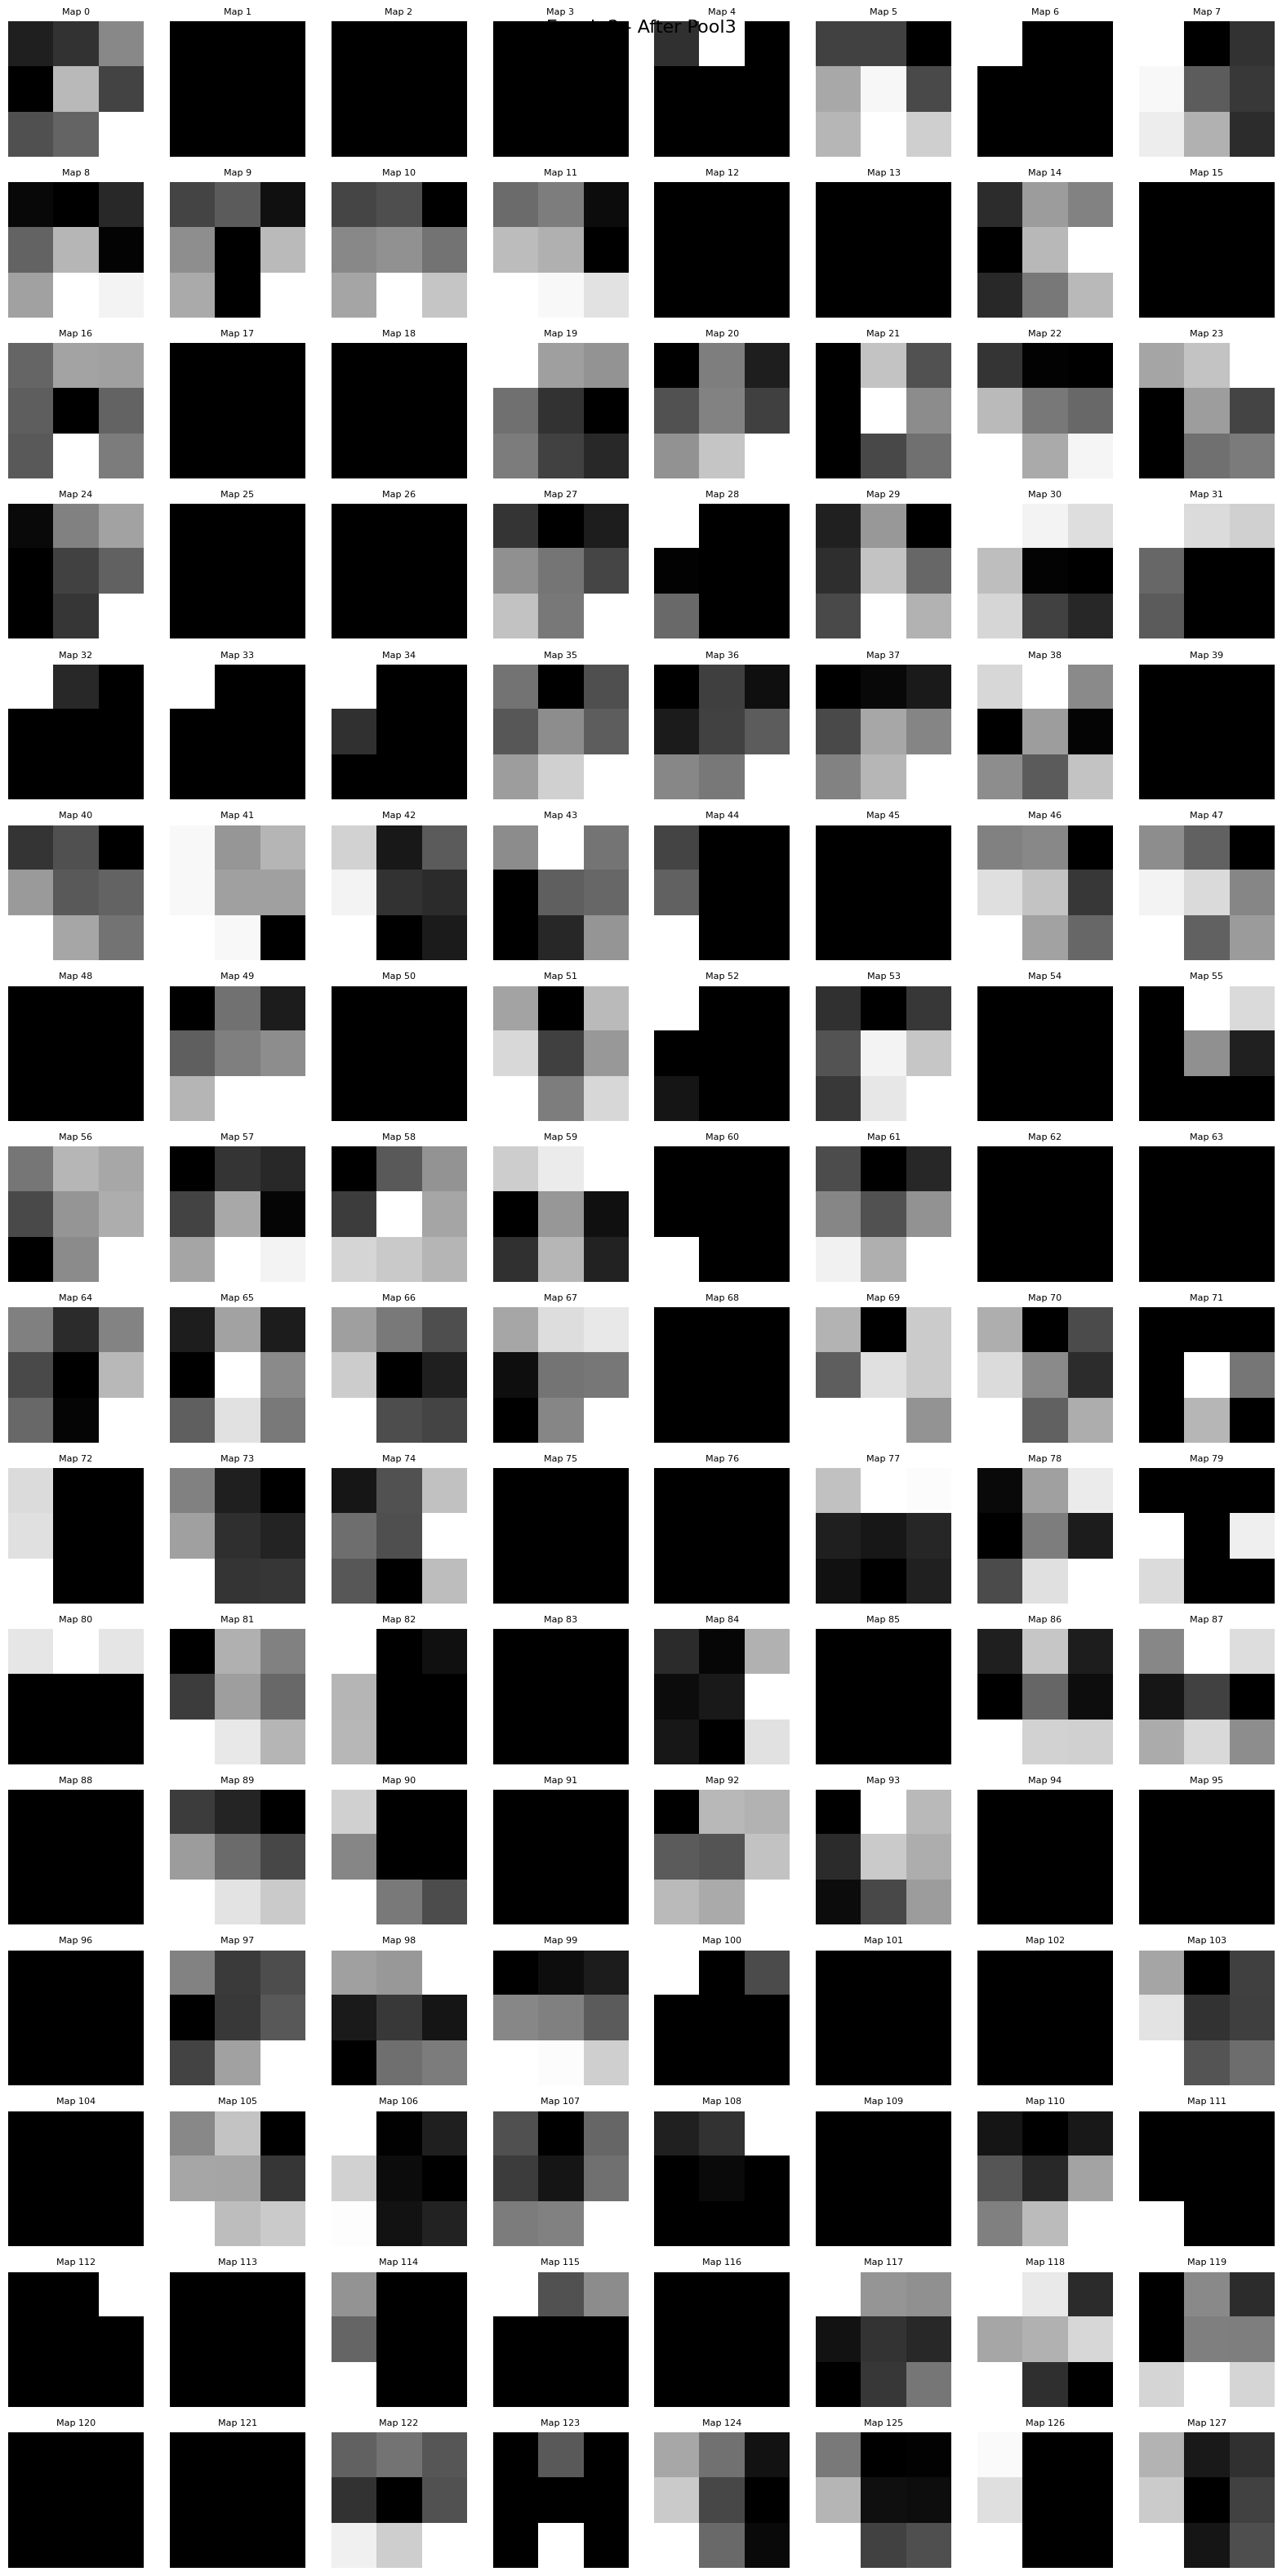


AFTER FLATTEN
Shape: (1152,)
First 40 values:
tensor([0.0719, 0.0743, 0.0851, 0.0679, 0.0912, 0.0763, 0.0780, 0.0805, 0.1001,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0010, 0.0050, 0.0000, 0.0000])

AFTER LINEAR 1
Shape: (256,)
First 40 values:
tensor([ 1.9034e-01, -2.8039e-02, -3.7303e-02, -1.9875e-02, -6.5941e-02,
        -4.5314e-02, -5.1144e-02, -2.8938e-02, -5.9690e-02, -2.7357e-02,
        -2.1841e-02,  1.5472e-01,  1.2357e-01, -1.0777e-01, -1.0371e-01,
         8.7089e-03, -3.5833e-02, -6.3095e-02, -2.2728e-02,  7.2145e-02,
         2.6134e-05, -6.6072e-02,  9.3972e-02, -6.2309e-02,  1.9903e-01,
         7.9606e-02, -5.7630e-02,  1.3106e-01, -8.1827e-02, -2.2145e-02,
         1.3435e-01, -7.1569e-02, -4.9018e-02, -5.7692e-02,  1.1832e-01,
         2.4342e-02,  8.9588e-02, 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader


# ============================================================
# CONFIGURATION
# ============================================================

BATCH_SIZE = 64
EPOCHS = 2
LR = 1e-3

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SELECTED_CLASSES = [0, 1, 2]

CLASS_NAMES = {
    0: "A",
    1: "B",
    2: "C"
}


print("Device:", DEVICE)


# ============================================================
# LOAD DATA
# ============================================================

train_df = pd.read_csv(
    "sign_mnist_train.csv"
)

train_df = train_df[
    train_df["label"].isin(SELECTED_CLASSES)
].copy()


# ============================================================
# DATASET
# ============================================================

class SignDataset(Dataset):

    def __init__(self, df):

        self.labels = df["label"].values

        self.images = (
            df.drop("label", axis=1)
            .values
            .reshape(-1, 28, 28)
            .astype(np.float32)
            / 255.0
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        image = torch.tensor(
            self.images[idx]
        ).unsqueeze(0)

        label = torch.tensor(
            self.labels[idx]
        ).long()

        return image, label


train_ds = SignDataset(train_df)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)


# ============================================================
# MODEL
# ============================================================

class SignCNN(nn.Module):

    def __init__(self):

        super().__init__()

        # ----------------------------------------------------
        # BLOCK 1
        # ----------------------------------------------------

        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        self.relu1 = nn.ReLU()

        self.pool1 = nn.MaxPool2d(2)


        # ----------------------------------------------------
        # BLOCK 2
        # ----------------------------------------------------

        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.relu2 = nn.ReLU()

        self.pool2 = nn.MaxPool2d(2)


        # ----------------------------------------------------
        # BLOCK 3
        # ----------------------------------------------------

        self.conv3 = nn.Conv2d(
            in_channels=64,
            out_channels=128,
            kernel_size=3,
            padding=1
        )

        self.relu3 = nn.ReLU()

        self.pool3 = nn.MaxPool2d(2)


        # ----------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(
            128 * 3 * 3,
            256
        )

        self.relu4 = nn.ReLU()

        self.dropout = nn.Dropout(0.5)

        self.fc2 = nn.Linear(
            256,
            3
        )


    def forward(self, x, return_intermediate=False):

        outputs = {}

        outputs["input"] = x

        x = self.conv1(x)
        outputs["conv1"] = x

        x = self.relu1(x)
        outputs["relu1"] = x

        x = self.pool1(x)
        outputs["pool1"] = x

        x = self.conv2(x)
        outputs["conv2"] = x

        x = self.relu2(x)
        outputs["relu2"] = x

        x = self.pool2(x)
        outputs["pool2"] = x

        x = self.conv3(x)
        outputs["conv3"] = x

        x = self.relu3(x)
        outputs["relu3"] = x

        x = self.pool3(x)
        outputs["pool3"] = x

        x = self.flatten(x)
        outputs["flatten"] = x

        x = self.fc1(x)
        outputs["fc1"] = x

        x = self.relu4(x)
        outputs["relu4"] = x

        x = self.dropout(x)
        outputs["dropout"] = x

        x = self.fc2(x)
        outputs["logits"] = x


        if return_intermediate:
            return x, outputs

        return x


# ============================================================
# CREATE MODEL
# ============================================================

model = SignCNN().to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LR
)


print("\nModel created.")
print(model)


# ============================================================
# FEATURE MAP VISUALIZATION
# ============================================================

def show_feature_maps(tensor, title, max_maps):

    data = tensor.detach().cpu()

    # Remove batch dimension
    data = data[0]

    number_of_maps = min(
        data.shape[0],
        max_maps
    )

    columns = 8

    rows = int(
        np.ceil(
            number_of_maps / columns
        )
    )

    plt.figure(
        figsize=(16, 2 * rows)
    )

    for i in range(number_of_maps):

        plt.subplot(
            rows,
            columns,
            i + 1
        )

        plt.imshow(
            data[i],
            cmap="gray"
        )

        plt.title(
            f"Map {i}",
            fontsize=8
        )

        plt.axis("off")

    plt.suptitle(
        title,
        fontsize=16
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# SHOW VECTOR VALUES
# ============================================================

def show_vector(tensor, title, max_values=30):

    values = (
        tensor
        .detach()
        .cpu()
        .flatten()
    )

    print("\n" + "=" * 70)

    print(title)

    print("=" * 70)

    print(
        "Shape:",
        tuple(tensor.shape)
    )

    print(
        "First",
        min(max_values, len(values)),
        "values:"
    )

    print(
        values[
            :max_values
        ]
    )


# ============================================================
# TRAINING DEMONSTRATION
# ============================================================

print("\n")
print("=" * 80)
print("              TRAINING PIPELINE DEMONSTRATION")
print("=" * 80)

print(
    f"Epochs: {EPOCHS}"
)

print(
    f"Batch size: {BATCH_SIZE}"
)

print(
    f"Learning rate: {LR}"
)

print("=" * 80)


# ============================================================
# TRAIN FOR 2 EPOCHS
# ============================================================

for epoch in range(EPOCHS):

    model.train()

    epoch_loss = 0.0

    epoch_correct = 0

    epoch_total = 0


    print("\n\n")
    print("#" * 80)
    print(
        f"                         EPOCH {epoch + 1}"
    )
    print("#" * 80)


    # --------------------------------------------------------
    # ONLY USE ONE BATCH FOR THIS DEMONSTRATION
    # --------------------------------------------------------

    for batch_idx, (
        images,
        labels
    ) in enumerate(train_loader):

        # ====================================================
        # STOP AFTER FIRST BATCH
        # ====================================================

        if batch_idx > 0:
            break

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)


        # ====================================================
        # SELECT ONE IMAGE FROM THIS BATCH
        # ====================================================

        selected_image = images[0:1]
        selected_label = labels[0:1]

        print("\n")
        print("-" * 80)

        print(
            f"EPOCH {epoch + 1} "
            f"| BATCH {batch_idx + 1} "
            f"| SELECTED IMAGE 1"
        )

        print("-" * 80)

        print(
            "Batch shape:",
            tuple(images.shape)
        )

        print(
            "Selected image shape:",
            tuple(selected_image.shape)
        )

        print(
            "True label:",
            selected_label.item(),
            f"({CLASS_NAMES[selected_label.item()]})"
        )


        # ====================================================
        # DISPLAY INPUT IMAGE
        # ====================================================

        plt.figure(
            figsize=(4, 4)
        )

        plt.imshow(
            selected_image[0, 0]
            .detach()
            .cpu(),
            cmap="gray"
        )

        plt.title(
            f"Epoch {epoch + 1} - "
            f"Training Image\n"
            f"True Class: "
            f"{CLASS_NAMES[selected_label.item()]}"
        )

        plt.axis("off")
        plt.show()


        # ====================================================
        # SAVE WEIGHTS BEFORE UPDATE
        # ====================================================

        conv1_weight_before = (
            model.conv1.weight
            .detach()
            .clone()
        )

        fc1_weight_before = model.fc1.weight.detach().clone()
        fc1_bias_before   = model.fc1.bias.detach().clone()

        # fc2_weight_before = model.fc2.weight.detach().clone()
        # fc2_bias_before   = model.fc2.bias.detach().clone()


        # ====================================================
        # CLEAR GRADIENTS
        # ====================================================

        optimizer.zero_grad()


        # ====================================================
        # FORWARD PASS
        # ====================================================

        logits, intermediate = model(
            images,
            return_intermediate=True
        )


        # ====================================================
        # DISPLAY SELECTED IMAGE'S FORWARD PASS
        # ====================================================

        print("\n")
        print("=" * 80)

        print(
            f"FORWARD PASS - EPOCH {epoch + 1}"
        )

        print("=" * 80)


        for name, tensor in intermediate.items():

            print(
                f"{name:10s} "
                f"Shape: {str(tuple(tensor.shape)):20s} "
                f"Mean: {tensor.mean().item(): .6f} "
                f"Min: {tensor.min().item(): .6f} "
                f"Max: {tensor.max().item(): .6f}"
            )


        # ====================================================
        # VISUALIZE IMAGE 1
        # ====================================================

        print("\n")
        print(
            "Showing feature maps for selected image..."
        )


        show_feature_maps(
            intermediate["conv1"][0:1],
            f"Epoch {epoch + 1} - "
            "After Conv1",
            32
        )


        show_feature_maps(
            intermediate["relu1"][0:1],
            f"Epoch {epoch + 1} - "
            "After ReLU1",
            32
        )


        show_feature_maps(
            intermediate["pool1"][0:1],
            f"Epoch {epoch + 1} - "
            "After Pool1",
            32
        )


        show_feature_maps(
            intermediate["conv2"][0:1],
            f"Epoch {epoch + 1} - "
            "After Conv2",
            64
        )


        show_feature_maps(
            intermediate["relu2"][0:1],
            f"Epoch {epoch + 1} - "
            "After ReLU2",
            64
        )


        show_feature_maps(
            intermediate["pool2"][0:1],
            f"Epoch {epoch + 1} - "
            "After Pool2",
            64
        )


        show_feature_maps(
            intermediate["conv3"][0:1],
            f"Epoch {epoch + 1} - "
            "After Conv3",
            128
        )


        show_feature_maps(
            intermediate["relu3"][0:1],
            f"Epoch {epoch + 1} - "
            "After ReLU3",
            128
        )


        show_feature_maps(
            intermediate["pool3"][0:1],
            f"Epoch {epoch + 1} - "
            "After Pool3",
            128
        )

        show_vector(
            intermediate["flatten"][0],
            "AFTER FLATTEN",
            40
        )

        show_vector(
            intermediate["fc1"][0],
            "AFTER LINEAR 1",
            40
        )

        show_vector(
            intermediate["relu4"][0],
            "AFTER RELU",
            40
        )

        zero_count = (
            intermediate["relu4"][0] == 0
        ).sum().item()

        total_count = intermediate["relu4"][0].numel()

        print(
            f"Zero activations: "
            f"{zero_count}/{total_count}"
        )

        print(
            f"Percentage zero: "
            f"{100 * zero_count / total_count:.2f}%"
        )

        show_vector(
            intermediate["dropout"][0],
            "AFTER DROPOUT",
            40
        )

        zero_count = (
            intermediate["dropout"][0] == 0
        ).sum().item()

        total_count = intermediate["dropout"][0].numel()

        print(
            f"Zero dropout: "
            f"{zero_count}/{total_count}"
        )

        print(
            f"Percentage zero: "
            f"{100 * zero_count / total_count:.2f}%"
        )

        # sys.exit()

        # ====================================================
        # LOGITS
        # ====================================================

        selected_logits = (
            logits[0]
        )

        print("\n")
        print("=" * 80)

        print("FINAL LOGITS")

        print("=" * 80)

        print(
            selected_logits
            .detach()
            .cpu()
        )


        # ====================================================
        # SOFTMAX
        # ====================================================

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        selected_probabilities = (
            probabilities[0]
        )


        print("\n")
        print("=" * 80)

        print("SOFTMAX PROBABILITIES")

        print("=" * 80)


        for class_id in range(3):

            print(
                f"Class {class_id} "
                f"({CLASS_NAMES[class_id]}): "
                f"{selected_probabilities[class_id].item():.6f}"
            )


        print(
            "\nProbability sum:",
            selected_probabilities.sum().item()
        )


        # ====================================================
        # PREDICTION
        # ====================================================

        predicted_class = torch.argmax(
            probabilities,
            dim=1
        )


        print("\n")
        print("=" * 80)

        print("PREDICTION")

        print("=" * 80)


        print(
            "True class:",
            selected_label.item(),
            f"({CLASS_NAMES[selected_label.item()]})"
        )

        print(
            "Predicted class:",
            predicted_class[0].item(),
            f"({CLASS_NAMES[predicted_class[0].item()]})"
        )

        print(
            "Confidence:",
            f"{selected_probabilities[predicted_class[0]].item():.6f}"
        )


        # ====================================================
        # LOSS CALCULATION
        # ====================================================

        loss = criterion(
            logits,
            labels
        )


        print("\n")
        print("=" * 80)

        print("CROSS ENTROPY LOSS")

        print("=" * 80)


        print(
            "Batch loss:",
            loss.item()
        )


        # ----------------------------------------------------
        # LOSS FOR SELECTED IMAGE ONLY
        # ----------------------------------------------------

        selected_loss = criterion(
            logits[0:1],
            labels[0:1]
        )


        print(
            "Selected image loss:",
            selected_loss.item()
        )


        # ====================================================
        # BACKPROPAGATION
        # ====================================================

        loss.backward()

        print("\n")
        print("=" * 80)

        print("BACKPROPAGATION / GRADIENTS")

        print("=" * 80)


        # ====================================================
        # SHOW GRADIENTS
        # ====================================================

        # for name, parameter in model.named_parameters():

        #     if parameter.grad is not None:

        #         print(
        #             f"\n{name}"
        #         )

        #         print(
        #             "Shape:",
        #             tuple(parameter.grad.shape)
        #         )

        #         print(
        #             "Mean gradient:",
        #             parameter.grad.mean().item()
        #         )

        #         print(
        #             "Min gradient:",
        #             parameter.grad.min().item()
        #         )

        #         print(
        #             "Max gradient:",
        #             parameter.grad.max().item()
        #         )

        #         print(
        #             "Gradient norm:",
        #             parameter.grad.norm().item()
        #         )


        # ====================================================
        # DISPLAY CONV1 GRADIENT MATRIX
        # ====================================================

        conv1_gradient = (
            model.conv1.weight.grad
            .detach()
            .cpu()
        )

        print(
            "CONV1 Gradient - Filter 0"
        )

        # print("=" * 80)

        print(
            conv1_gradient[0, 0]
        )

        # ------------------------------------------------------------
        # FC1 WEIGHT GRADIENT
        # ------------------------------------------------------------

        fc1_weight_grad = model.fc1.weight.grad

        print("\nFC1 Wweight Gradient")
        print("First 40 values:")
        print(
            fc1_weight_grad[0][:40]
        )


        # ------------------------------------------------------------
        # FC1 BIAS GRADIENT
        # ------------------------------------------------------------

        fc1_bias_grad = model.fc1.bias.grad

        print("\nFC1 Bias Gradient:")
        print("First 40 values:")
        print(
            fc1_bias_grad[:40]
        )


        # # ====================================================
        # # VISUALIZE GRADIENTS
        # # ====================================================

        # plt.figure(
        #     figsize=(12, 6)
        # )

        # for i in range(32):

        #     plt.subplot(
        #         4,
        #         8,
        #         i + 1
        #     )

        #     plt.imshow(
        #         conv1_gradient[i, 0],
        #         cmap="coolwarm"
        #     )

        #     plt.title(
        #         f"Grad {i}",
        #         fontsize=8
        #     )

        #     plt.axis("off")


        # plt.suptitle(
        #     f"Epoch {epoch + 1} - "
        #     "Conv1 Weight Gradients"
        # )

        # plt.tight_layout()
        # plt.show()


        # ====================================================
        # WEIGHT UPDATE
        # ====================================================

        print("\n")
        print("=" * 80)

        print("WEIGHT/BIAS UPDATE")

        print("=" * 80)


        print(
            "Conv1 Filter 0 Before optimizer.step():"
        )

        print(
            conv1_weight_before[0, 0]
            .cpu()
        )

        print("\n")


        # ====================================================
        # OPTIMIZER STEP
        # ====================================================

        optimizer.step()


        # ====================================================
        # SAVE WEIGHTS AFTER UPDATE
        # ====================================================

        conv1_weight_after = (
            model.conv1.weight
            .detach()
            .clone()
        )

        fc1_weight_after = model.fc1.weight.detach().clone()
        fc1_bias_after   = model.fc1.bias.detach().clone()

        # fc2_weight_after = model.fc2.weight.detach().clone()
        # fc2_bias_after   = model.fc2.bias.detach().clone()



        # ====================================================
        # CALCULATE ACTUAL WEIGHT CHANGE
        # ====================================================

        conv1_weight_change = (
            conv1_weight_after
            - conv1_weight_before
        )

        fc1_weight_change = (
            fc1_weight_after
            - fc1_weight_before
        )

        fc1_bias_change = (
            fc1_bias_after
            - fc1_bias_before
        )

        # fc2_weight_change = (
        #     fc2_weight_after
        #     - fc2_weight_before
        # )

        # fc2_bias_change = (
        #     fc2_bias_after
        #     - fc2_bias_before
        # )




        print(
            "Conv1 Filter 0 After optimizer.step():"
        )

        print(
            conv1_weight_after[0, 0]
            .cpu()
        )

        print("\n")

        print(
            "Conv1 Filter 0 actual change:"
        )

        print(
            conv1_weight_change[0, 0]
            .cpu()
        )


        # ====================================================
        # WEIGHT UPDATE STATISTICS
        # ====================================================

        # print("\n")
        # print(
        #     "Weight update statistics:"
        # )

        # print(
        #     "Mean:",
        #     conv1_weight_change.mean().item()
        # )

        # print(
        #     "Min:",
        #     conv1_weight_change.min().item()
        # )

        # print(
        #     "Max:",
        #     conv1_weight_change.max().item()
        # )

        # print(
        #     "L2 norm:",
        #     conv1_weight_change.norm().item()
        # )




        # ============================================================
        # FC1 WEIGHT UPDATE
        # ============================================================

        neuron = 0

        # print(
        #     "\nFC1 weight shape:",
        #     tuple(model.fc1.weight.shape)
        # )

        # print("\n")

        print(f"\nFC1 neuron {neuron} Weights Before optimizer.step():")
        print("First 40 values:")
        print(
            fc1_weight_before[neuron][:40]
        )

        print(f"\nFC1 neuron {neuron} Weights After optimizer.step():")
        print("First 40 values:")
        print(
            fc1_weight_after[neuron][:40]
        )

        print(f"\nFC1 neuron {neuron} Weight actual change:")
        print("First 40 values:")
        print(
            fc1_weight_change[neuron][:40]
        )

        # print("\n")

        print(f"\nFC1 neuron {neuron} Bias Before optimizer.step():")
        print("First 40 values:")
        print(
            fc1_bias_before[:40]
        )

        print(f"\nFC1 neuron {neuron} Bias After optimizer.step():")
        print("First 40 values:")
        print(
            fc1_bias_after[:40]
        )

        print(f"\nFC1 neuron {neuron} Bias Change:")
        print("First 40 values:")
        print(
            fc1_bias_change[:40]
        )


        # # ====================================================
        # # VISUALIZE WEIGHT CHANGE
        # # ====================================================

        # plt.figure(
        #     figsize=(12, 6)
        # )

        # for i in range(32):

        #     plt.subplot(
        #         4,
        #         8,
        #         i + 1
        #     )

        #     plt.imshow(
        #         conv1_weight_change[i, 0]
        #         .cpu(),
        #         cmap="coolwarm"
        #     )

        #     plt.title(
        #         f"Update {i}",
        #         fontsize=8
        #     )

        #     plt.axis("off")


        # plt.suptitle(
        #     f"Epoch {epoch + 1} - "
        #     "Conv1 Weight Updates"
        # )

        # plt.tight_layout()
        # plt.show()


        # ====================================================
        # UPDATE EPOCH STATISTICS
        # ====================================================

        epoch_loss += loss.item()

        epoch_correct += (
            predicted_class == labels
        ).sum().item()

        epoch_total += labels.size(0)


    # ========================================================
    # EPOCH RESULT
    # ========================================================

    epoch_accuracy = (
        epoch_correct /
        epoch_total
    )

    print("\n")
    print("#" * 80)

    print(
        f"EPOCH {epoch + 1} RESULT"
    )

    print(
        f"Training Loss: "
        f"{epoch_loss:.6f}"
    )

    print(
        f"Training Accuracy: "
        f"{epoch_accuracy:.6f}"
    )

    print("#" * 80)


print("\n")
print("=" * 80)
print("              TRAINING DEMONSTRATION COMPLETE")
print("=" * 80)


Device: cpu

Model created.
SignCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1152, out_features=256, bias=True)
  (relu4): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=3, bias=True)
)


              TRAINING PIPELINE DEMONSTRATION
Epochs: 2
Batch size: 64
Learning rate: 0.001



################################################################################
          

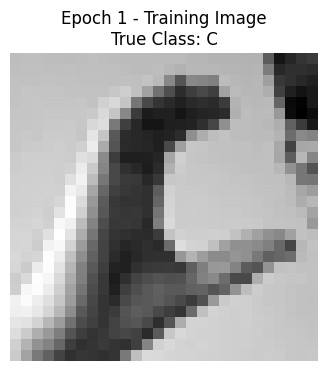



FORWARD PASS - EPOCH 1
input      Shape: (64, 1, 28, 28)      Mean:  0.624717 Min:  0.000000 Max:  1.000000
conv1      Shape: (64, 32, 28, 28)     Mean:  0.029088 Min: -1.008867 Max:  1.388968
relu1      Shape: (64, 32, 28, 28)     Mean:  0.142830 Min:  0.000000 Max:  1.388968
pool1      Shape: (64, 32, 14, 14)     Mean:  0.170398 Min:  0.000000 Max:  1.388968
conv2      Shape: (64, 64, 14, 14)     Mean: -0.018723 Min: -1.066698 Max:  0.509681
relu2      Shape: (64, 64, 14, 14)     Mean:  0.053903 Min:  0.000000 Max:  0.509681
pool2      Shape: (64, 64, 7, 7)       Mean:  0.070289 Min:  0.000000 Max:  0.509681
conv3      Shape: (64, 128, 7, 7)      Mean: -0.000204 Min: -0.237275 Max:  0.286034
relu3      Shape: (64, 128, 7, 7)      Mean:  0.026663 Min:  0.000000 Max:  0.286034
pool3      Shape: (64, 128, 3, 3)      Mean:  0.038000 Min:  0.000000 Max:  0.286034
flatten    Shape: (64, 1152)           Mean:  0.038000 Min:  0.000000 Max:  0.286034
fc1        Shape: (64, 256)            M

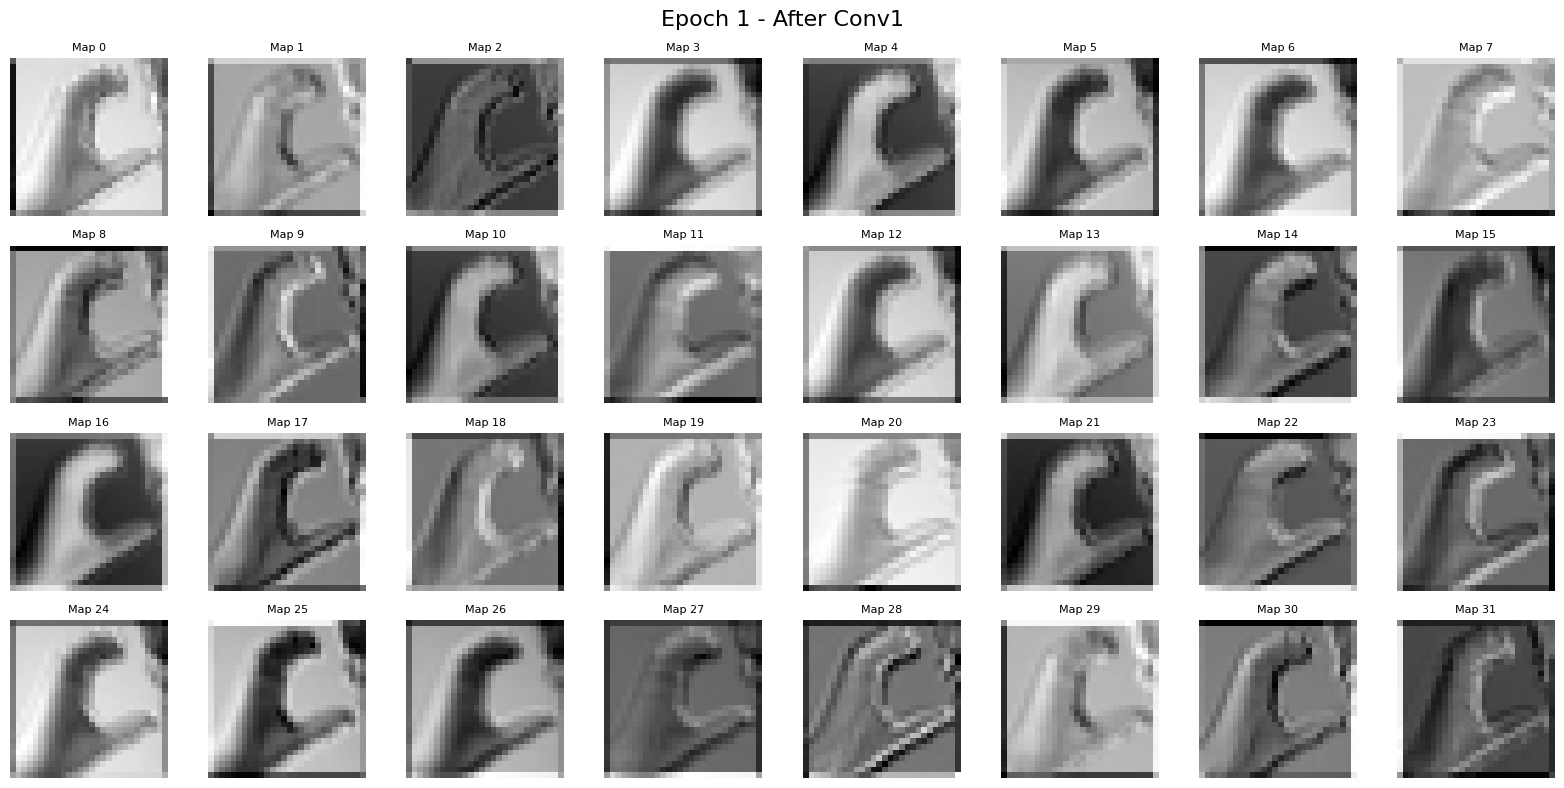


Input values
tensor([[0.7333, 0.7373, 0.7373, 0.7333, 0.7333, 0.7294, 0.7333, 0.7373, 0.7333,
         0.7294, 0.7255, 0.7255, 0.7255, 0.7216, 0.7216, 0.7216, 0.7098, 0.7098,
         0.7020, 0.7020, 0.7020, 0.6980, 0.6980, 0.4275, 0.2039, 0.2588, 0.3020,
         0.3255],
        [0.7373, 0.7412, 0.7412, 0.7373, 0.7373, 0.7412, 0.7373, 0.7373, 0.7373,
         0.7373, 0.7333, 0.7255, 0.7255, 0.7333, 0.7137, 0.6941, 0.7137, 0.7137,
         0.7137, 0.7059, 0.7059, 0.7020, 0.7059, 0.5294, 0.2627, 0.2863, 0.2863,
         0.2784],
        [0.7451, 0.7451, 0.7451, 0.7490, 0.7451, 0.7451, 0.7412, 0.7412, 0.7412,
         0.7373, 0.7412, 0.7373, 0.7529, 0.7216, 0.5647, 0.4039, 0.5647, 0.5569,
         0.5412, 0.7294, 0.7137, 0.7059, 0.7137, 0.6392, 0.3176, 0.2902, 0.2667,
         0.2392],
        [0.7490, 0.7569, 0.7529, 0.7529, 0.7529, 0.7490, 0.7490, 0.7490, 0.7490,
         0.7647, 0.7843, 0.7412, 0.6471, 0.4980, 0.3843, 0.2784, 0.3333, 0.3686,
         0.3373, 0.6471, 0.7216, 0.7137, 

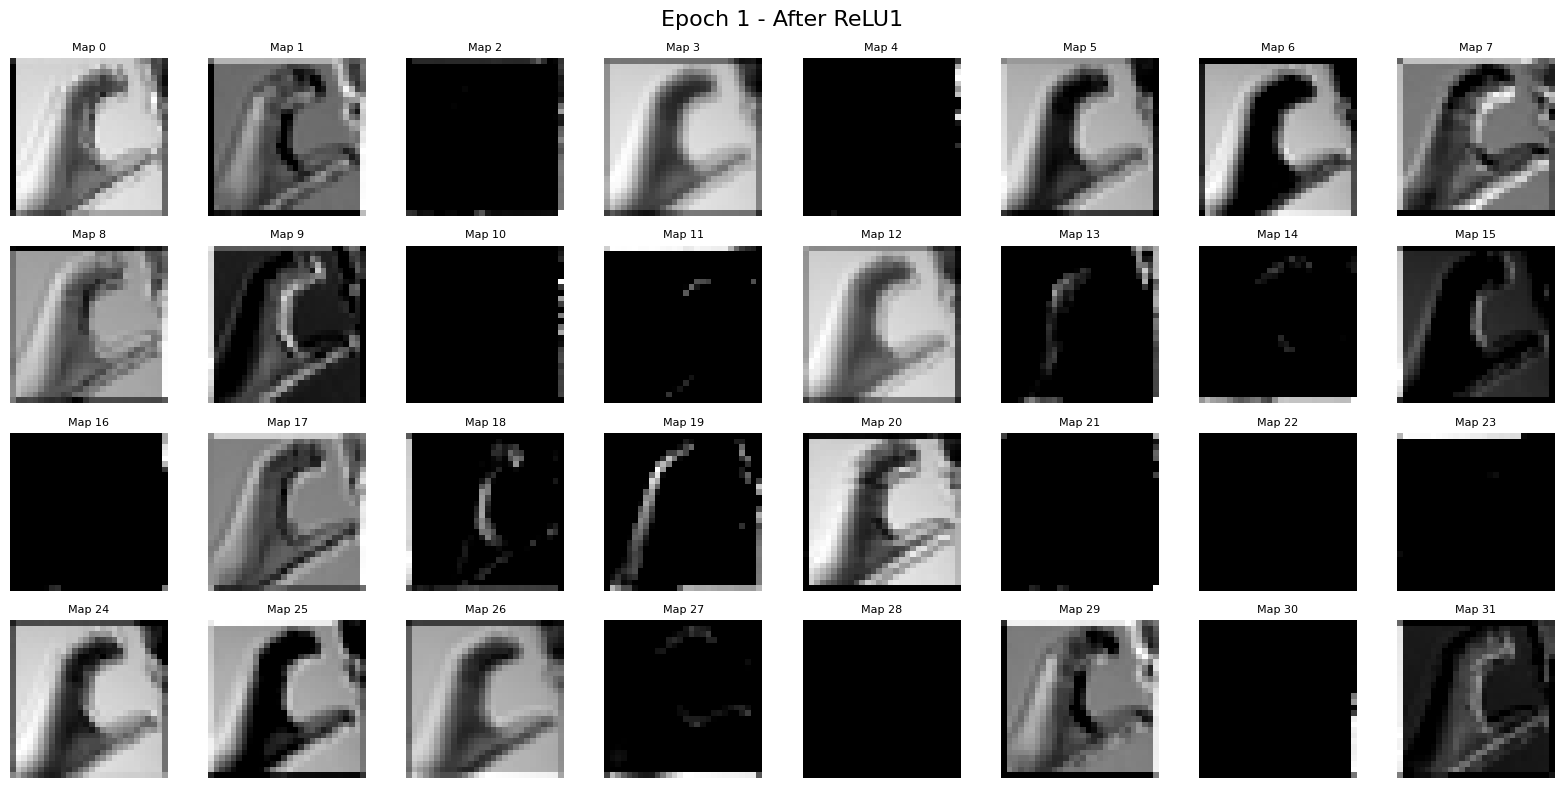

SystemExit: 0

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader


# ============================================================
# CONFIGURATION
# ============================================================

BATCH_SIZE = 64
EPOCHS = 2
LR = 1e-3

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SELECTED_CLASSES = [0, 1, 2]

CLASS_NAMES = {
    0: "A",
    1: "B",
    2: "C"
}


print("Device:", DEVICE)


# ============================================================
# LOAD DATA
# ============================================================

train_df = pd.read_csv(
    "sign_mnist_train.csv"
)

train_df = train_df[
    train_df["label"].isin(SELECTED_CLASSES)
].copy()


# ============================================================
# DATASET
# ============================================================

class SignDataset(Dataset):

    def __init__(self, df):

        self.labels = df["label"].values

        self.images = (
            df.drop("label", axis=1)
            .values
            .reshape(-1, 28, 28)
            .astype(np.float32)
            / 255.0
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        image = torch.tensor(
            self.images[idx]
        ).unsqueeze(0)

        label = torch.tensor(
            self.labels[idx]
        ).long()

        return image, label


train_ds = SignDataset(train_df)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)


# ============================================================
# MODEL
# ============================================================

class SignCNN(nn.Module):

    def __init__(self):

        super().__init__()

        # ----------------------------------------------------
        # BLOCK 1
        # ----------------------------------------------------

        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        self.relu1 = nn.ReLU()

        self.pool1 = nn.MaxPool2d(2)


        # ----------------------------------------------------
        # BLOCK 2
        # ----------------------------------------------------

        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.relu2 = nn.ReLU()

        self.pool2 = nn.MaxPool2d(2)


        # ----------------------------------------------------
        # BLOCK 3
        # ----------------------------------------------------

        self.conv3 = nn.Conv2d(
            in_channels=64,
            out_channels=128,
            kernel_size=3,
            padding=1
        )

        self.relu3 = nn.ReLU()

        self.pool3 = nn.MaxPool2d(2)


        # ----------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(
            128 * 3 * 3,
            256
        )

        self.relu4 = nn.ReLU()

        self.dropout = nn.Dropout(0.5)

        self.fc2 = nn.Linear(
            256,
            3
        )


    def forward(self, x, return_intermediate=False):

        outputs = {}

        outputs["input"] = x

        x = self.conv1(x)
        outputs["conv1"] = x

        x = self.relu1(x)
        outputs["relu1"] = x

        x = self.pool1(x)
        outputs["pool1"] = x

        x = self.conv2(x)
        outputs["conv2"] = x

        x = self.relu2(x)
        outputs["relu2"] = x

        x = self.pool2(x)
        outputs["pool2"] = x

        x = self.conv3(x)
        outputs["conv3"] = x

        x = self.relu3(x)
        outputs["relu3"] = x

        x = self.pool3(x)
        outputs["pool3"] = x

        x = self.flatten(x)
        outputs["flatten"] = x

        x = self.fc1(x)
        outputs["fc1"] = x

        x = self.relu4(x)
        outputs["relu4"] = x

        x = self.dropout(x)
        outputs["dropout"] = x

        x = self.fc2(x)
        outputs["logits"] = x


        if return_intermediate:
            return x, outputs

        return x


# ============================================================
# CREATE MODEL
# ============================================================

model = SignCNN().to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LR
)


print("\nModel created.")
print(model)


# ============================================================
# FEATURE MAP VISUALIZATION
# ============================================================

def show_feature_maps(tensor, title, max_maps):

    data = tensor.detach().cpu()

    # Remove batch dimension
    data = data[0]

    number_of_maps = min(
        data.shape[0],
        max_maps
    )

    columns = 8

    rows = int(
        np.ceil(
            number_of_maps / columns
        )
    )

    plt.figure(
        figsize=(16, 2 * rows)
    )

    for i in range(number_of_maps):

        plt.subplot(
            rows,
            columns,
            i + 1
        )

        plt.imshow(
            data[i],
            cmap="gray"
        )

        plt.title(
            f"Map {i}",
            fontsize=8
        )

        plt.axis("off")

    plt.suptitle(
        title,
        fontsize=16
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# SHOW VECTOR VALUES
# ============================================================

def show_vector(tensor, title, max_values=30):

    values = (
        tensor
        .detach()
        .cpu()
        .flatten()
    )

    print("\n" + "=" * 70)

    print(title)

    print("=" * 70)

    print(
        "Shape:",
        tuple(tensor.shape)
    )

    print(
        "First",
        min(max_values, len(values)),
        "values:"
    )

    print(
        values[
            :max_values
        ]
    )


# ============================================================
# TRAINING DEMONSTRATION
# ============================================================

print("\n")
print("=" * 80)
print("              TRAINING PIPELINE DEMONSTRATION")
print("=" * 80)

print(
    f"Epochs: {EPOCHS}"
)

print(
    f"Batch size: {BATCH_SIZE}"
)

print(
    f"Learning rate: {LR}"
)

print("=" * 80)


# ============================================================
# TRAIN FOR 2 EPOCHS
# ============================================================

for epoch in range(EPOCHS):

    model.train()

    epoch_loss = 0.0

    epoch_correct = 0

    epoch_total = 0


    print("\n\n")
    print("#" * 80)
    print(
        f"                         EPOCH {epoch + 1}"
    )
    print("#" * 80)


    # --------------------------------------------------------
    # ONLY USE ONE BATCH FOR THIS DEMONSTRATION
    # --------------------------------------------------------

    for batch_idx, (
        images,
        labels
    ) in enumerate(train_loader):

        # ====================================================
        # STOP AFTER FIRST BATCH
        # ====================================================

        if batch_idx > 0:
            break

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)


        # ====================================================
        # SELECT ONE IMAGE FROM THIS BATCH
        # ====================================================

        selected_image = images[0:1]
        selected_label = labels[0:1]

        print("\n")
        print("-" * 80)

        print(
            f"EPOCH {epoch + 1} "
            f"| BATCH {batch_idx + 1} "
            f"| SELECTED IMAGE 1"
        )

        print("-" * 80)

        print(
            "Batch shape:",
            tuple(images.shape)
        )

        print(
            "Selected image shape:",
            tuple(selected_image.shape)
        )

        print(
            "True label:",
            selected_label.item(),
            f"({CLASS_NAMES[selected_label.item()]})"
        )


        # ====================================================
        # DISPLAY INPUT IMAGE
        # ====================================================

        plt.figure(
            figsize=(4, 4)
        )

        plt.imshow(
            selected_image[0, 0]
            .detach()
            .cpu(),
            cmap="gray"
        )

        plt.title(
            f"Epoch {epoch + 1} - "
            f"Training Image\n"
            f"True Class: "
            f"{CLASS_NAMES[selected_label.item()]}"
        )

        plt.axis("off")
        plt.show()


        # ====================================================
        # SAVE WEIGHTS BEFORE UPDATE
        # ====================================================

        conv1_weight_before = (
            model.conv1.weight
            .detach()
            .clone()
        )

        fc1_weight_before = model.fc1.weight.detach().clone()
        fc1_bias_before   = model.fc1.bias.detach().clone()

        # fc2_weight_before = model.fc2.weight.detach().clone()
        # fc2_bias_before   = model.fc2.bias.detach().clone()


        # ====================================================
        # CLEAR GRADIENTS
        # ====================================================

        optimizer.zero_grad()


        # ====================================================
        # FORWARD PASS
        # ====================================================

        logits, intermediate = model(
            images,
            return_intermediate=True
        )


        # ====================================================
        # DISPLAY SELECTED IMAGE'S FORWARD PASS
        # ====================================================

        print("\n")
        print("=" * 80)

        print(
            f"FORWARD PASS - EPOCH {epoch + 1}"
        )

        print("=" * 80)


        for name, tensor in intermediate.items():

            print(
                f"{name:10s} "
                f"Shape: {str(tuple(tensor.shape)):20s} "
                f"Mean: {tensor.mean().item(): .6f} "
                f"Min: {tensor.min().item(): .6f} "
                f"Max: {tensor.max().item(): .6f}"
            )


        # ====================================================
        # VISUALIZE IMAGE 1
        # ====================================================

        print("\n")
        print(
            "Showing feature maps for selected image..."
        )


        show_feature_maps(
            intermediate["conv1"][0:1],
            f"Epoch {epoch + 1} - "
            "After Conv1",
            32
        )

        print("\nInput values")
        print(
            selected_image[0, 0]
        )

        print("\nFirst kernel")
        print(
            model.conv1.weight[0, 0]
            .cpu()
        )

        print("\nAfter convolution")
        print(intermediate["conv1"][0:1])

        print("\nAfter relu")
        print(intermediate["relu1"][0:1])


        show_feature_maps(
            intermediate["relu1"][0:1],
            f"Epoch {epoch + 1} - "
            "After ReLU1",
            32
        )

        sys.exit(0)

        show_feature_maps(
            intermediate["pool1"][0:1],
            f"Epoch {epoch + 1} - "
            "After Pool1",
            32
        )


        show_feature_maps(
            intermediate["conv2"][0:1],
            f"Epoch {epoch + 1} - "
            "After Conv2",
            64
        )


        show_feature_maps(
            intermediate["relu2"][0:1],
            f"Epoch {epoch + 1} - "
            "After ReLU2",
            64
        )


        show_feature_maps(
            intermediate["pool2"][0:1],
            f"Epoch {epoch + 1} - "
            "After Pool2",
            64
        )


        show_feature_maps(
            intermediate["conv3"][0:1],
            f"Epoch {epoch + 1} - "
            "After Conv3",
            128
        )


        show_feature_maps(
            intermediate["relu3"][0:1],
            f"Epoch {epoch + 1} - "
            "After ReLU3",
            128
        )


        show_feature_maps(
            intermediate["pool3"][0:1],
            f"Epoch {epoch + 1} - "
            "After Pool3",
            128
        )

        show_vector(
            intermediate["flatten"][0],
            "AFTER FLATTEN",
            40
        )

        show_vector(
            intermediate["fc1"][0],
            "AFTER LINEAR 1",
            40
        )

        show_vector(
            intermediate["relu4"][0],
            "AFTER RELU",
            40
        )

        zero_count = (
            intermediate["relu4"][0] == 0
        ).sum().item()

        total_count = intermediate["relu4"][0].numel()

        print(
            f"Zero activations: "
            f"{zero_count}/{total_count}"
        )

        print(
            f"Percentage zero: "
            f"{100 * zero_count / total_count:.2f}%"
        )

        show_vector(
            intermediate["dropout"][0],
            "AFTER DROPOUT",
            40
        )

        zero_count = (
            intermediate["dropout"][0] == 0
        ).sum().item()

        total_count = intermediate["dropout"][0].numel()

        print(
            f"Zero dropout: "
            f"{zero_count}/{total_count}"
        )

        print(
            f"Percentage zero: "
            f"{100 * zero_count / total_count:.2f}%"
        )

        # sys.exit()

        # ====================================================
        # LOGITS
        # ====================================================

        selected_logits = (
            logits[0]
        )

        print("\n")
        print("=" * 80)

        print("FINAL LOGITS")

        print("=" * 80)

        print(
            selected_logits
            .detach()
            .cpu()
        )


        # ====================================================
        # SOFTMAX
        # ====================================================

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        selected_probabilities = (
            probabilities[0]
        )


        print("\n")
        print("=" * 80)

        print("SOFTMAX PROBABILITIES")

        print("=" * 80)


        for class_id in range(3):

            print(
                f"Class {class_id} "
                f"({CLASS_NAMES[class_id]}): "
                f"{selected_probabilities[class_id].item():.6f}"
            )


        print(
            "\nProbability sum:",
            selected_probabilities.sum().item()
        )


        # ====================================================
        # PREDICTION
        # ====================================================

        predicted_class = torch.argmax(
            probabilities,
            dim=1
        )


        print("\n")
        print("=" * 80)

        print("PREDICTION")

        print("=" * 80)


        print(
            "True class:",
            selected_label.item(),
            f"({CLASS_NAMES[selected_label.item()]})"
        )

        print(
            "Predicted class:",
            predicted_class[0].item(),
            f"({CLASS_NAMES[predicted_class[0].item()]})"
        )

        print(
            "Confidence:",
            f"{selected_probabilities[predicted_class[0]].item():.6f}"
        )


        # ====================================================
        # LOSS CALCULATION
        # ====================================================

        loss = criterion(
            logits,
            labels
        )


        print("\n")
        print("=" * 80)

        print("CROSS ENTROPY LOSS")

        print("=" * 80)


        print(
            "Batch loss:",
            loss.item()
        )


        # ----------------------------------------------------
        # LOSS FOR SELECTED IMAGE ONLY
        # ----------------------------------------------------

        selected_loss = criterion(
            logits[0:1],
            labels[0:1]
        )


        print(
            "Selected image loss:",
            selected_loss.item()
        )


        # ====================================================
        # BACKPROPAGATION
        # ====================================================

        loss.backward()

        print("\n")
        print("=" * 80)

        print("BACKPROPAGATION / GRADIENTS")

        print("=" * 80)


        # ====================================================
        # SHOW GRADIENTS
        # ====================================================

        # for name, parameter in model.named_parameters():

        #     if parameter.grad is not None:

        #         print(
        #             f"\n{name}"
        #         )

        #         print(
        #             "Shape:",
        #             tuple(parameter.grad.shape)
        #         )

        #         print(
        #             "Mean gradient:",
        #             parameter.grad.mean().item()
        #         )

        #         print(
        #             "Min gradient:",
        #             parameter.grad.min().item()
        #         )

        #         print(
        #             "Max gradient:",
        #             parameter.grad.max().item()
        #         )

        #         print(
        #             "Gradient norm:",
        #             parameter.grad.norm().item()
        #         )


        # ====================================================
        # DISPLAY CONV1 GRADIENT MATRIX
        # ====================================================

        conv1_gradient = (
            model.conv1.weight.grad
            .detach()
            .cpu()
        )

        print(
            "CONV1 Gradient - Filter 0"
        )

        # print("=" * 80)

        print(
            conv1_gradient[0, 0]
        )

        # ------------------------------------------------------------
        # FC1 WEIGHT GRADIENT
        # ------------------------------------------------------------

        fc1_weight_grad = model.fc1.weight.grad

        print("\nFC1 Wweight Gradient")
        print("First 40 values:")
        print(
            fc1_weight_grad[0][:40]
        )


        # ------------------------------------------------------------
        # FC1 BIAS GRADIENT
        # ------------------------------------------------------------

        fc1_bias_grad = model.fc1.bias.grad

        print("\nFC1 Bias Gradient:")
        print("First 40 values:")
        print(
            fc1_bias_grad[:40]
        )


        # # ====================================================
        # # VISUALIZE GRADIENTS
        # # ====================================================

        # plt.figure(
        #     figsize=(12, 6)
        # )

        # for i in range(32):

        #     plt.subplot(
        #         4,
        #         8,
        #         i + 1
        #     )

        #     plt.imshow(
        #         conv1_gradient[i, 0],
        #         cmap="coolwarm"
        #     )

        #     plt.title(
        #         f"Grad {i}",
        #         fontsize=8
        #     )

        #     plt.axis("off")


        # plt.suptitle(
        #     f"Epoch {epoch + 1} - "
        #     "Conv1 Weight Gradients"
        # )

        # plt.tight_layout()
        # plt.show()


        # ====================================================
        # WEIGHT UPDATE
        # ====================================================

        print("\n")
        print("=" * 80)

        print("WEIGHT/BIAS UPDATE")

        print("=" * 80)


        print(
            "Conv1 Filter 0 Before optimizer.step():"
        )

        print(
            conv1_weight_before[0, 0]
            .cpu()
        )

        print("\n")


        # ====================================================
        # OPTIMIZER STEP
        # ====================================================

        optimizer.step()


        # ====================================================
        # SAVE WEIGHTS AFTER UPDATE
        # ====================================================

        conv1_weight_after = (
            model.conv1.weight
            .detach()
            .clone()
        )

        fc1_weight_after = model.fc1.weight.detach().clone()
        fc1_bias_after   = model.fc1.bias.detach().clone()

        # fc2_weight_after = model.fc2.weight.detach().clone()
        # fc2_bias_after   = model.fc2.bias.detach().clone()



        # ====================================================
        # CALCULATE ACTUAL WEIGHT CHANGE
        # ====================================================

        conv1_weight_change = (
            conv1_weight_after
            - conv1_weight_before
        )

        fc1_weight_change = (
            fc1_weight_after
            - fc1_weight_before
        )

        fc1_bias_change = (
            fc1_bias_after
            - fc1_bias_before
        )

        # fc2_weight_change = (
        #     fc2_weight_after
        #     - fc2_weight_before
        # )

        # fc2_bias_change = (
        #     fc2_bias_after
        #     - fc2_bias_before
        # )




        print(
            "Conv1 Filter 0 After optimizer.step():"
        )

        print(
            conv1_weight_after[0, 0]
            .cpu()
        )

        print("\n")

        print(
            "Conv1 Filter 0 actual change:"
        )

        print(
            conv1_weight_change[0, 0]
            .cpu()
        )


        # ====================================================
        # WEIGHT UPDATE STATISTICS
        # ====================================================

        # print("\n")
        # print(
        #     "Weight update statistics:"
        # )

        # print(
        #     "Mean:",
        #     conv1_weight_change.mean().item()
        # )

        # print(
        #     "Min:",
        #     conv1_weight_change.min().item()
        # )

        # print(
        #     "Max:",
        #     conv1_weight_change.max().item()
        # )

        # print(
        #     "L2 norm:",
        #     conv1_weight_change.norm().item()
        # )




        # ============================================================
        # FC1 WEIGHT UPDATE
        # ============================================================

        neuron = 0

        # print(
        #     "\nFC1 weight shape:",
        #     tuple(model.fc1.weight.shape)
        # )

        # print("\n")

        print(f"\nFC1 neuron {neuron} Weights Before optimizer.step():")
        print("First 40 values:")
        print(
            fc1_weight_before[neuron][:40]
        )

        print(f"\nFC1 neuron {neuron} Weights After optimizer.step():")
        print("First 40 values:")
        print(
            fc1_weight_after[neuron][:40]
        )

        print(f"\nFC1 neuron {neuron} Weight actual change:")
        print("First 40 values:")
        print(
            fc1_weight_change[neuron][:40]
        )

        # print("\n")

        print(f"\nFC1 neuron {neuron} Bias Before optimizer.step():")
        print("First 40 values:")
        print(
            fc1_bias_before[:40]
        )

        print(f"\nFC1 neuron {neuron} Bias After optimizer.step():")
        print("First 40 values:")
        print(
            fc1_bias_after[:40]
        )

        print(f"\nFC1 neuron {neuron} Bias Change:")
        print("First 40 values:")
        print(
            fc1_bias_change[:40]
        )


        # # ====================================================
        # # VISUALIZE WEIGHT CHANGE
        # # ====================================================

        # plt.figure(
        #     figsize=(12, 6)
        # )

        # for i in range(32):

        #     plt.subplot(
        #         4,
        #         8,
        #         i + 1
        #     )

        #     plt.imshow(
        #         conv1_weight_change[i, 0]
        #         .cpu(),
        #         cmap="coolwarm"
        #     )

        #     plt.title(
        #         f"Update {i}",
        #         fontsize=8
        #     )

        #     plt.axis("off")


        # plt.suptitle(
        #     f"Epoch {epoch + 1} - "
        #     "Conv1 Weight Updates"
        # )

        # plt.tight_layout()
        # plt.show()


        # ====================================================
        # UPDATE EPOCH STATISTICS
        # ====================================================

        epoch_loss += loss.item()

        epoch_correct += (
            predicted_class == labels
        ).sum().item()

        epoch_total += labels.size(0)


    # ========================================================
    # EPOCH RESULT
    # ========================================================

    epoch_accuracy = (
        epoch_correct /
        epoch_total
    )

    print("\n")
    print("#" * 80)

    print(
        f"EPOCH {epoch + 1} RESULT"
    )

    print(
        f"Training Loss: "
        f"{epoch_loss:.6f}"
    )

    print(
        f"Training Accuracy: "
        f"{epoch_accuracy:.6f}"
    )

    print("#" * 80)


print("\n")
print("=" * 80)
print("              TRAINING DEMONSTRATION COMPLETE")
print("=" * 80)


# exploration

Device: cpu

Model created.
SignCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1152, out_features=256, bias=True)
  (relu4): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=3, bias=True)
)


              TRAINING PIPELINE DEMONSTRATION
Epochs: 2
Batch size: 64
Learning rate: 0.001



################################################################################
          

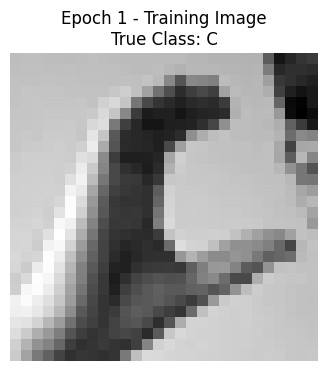

RuntimeError: Input type (long int) and bias type (float) should be the same

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader


# ============================================================
# CONFIGURATION
# ============================================================

BATCH_SIZE = 64
EPOCHS = 2
LR = 1e-3

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SELECTED_CLASSES = [0, 1, 2]

CLASS_NAMES = {
    0: "A",
    1: "B",
    2: "C"
}


print("Device:", DEVICE)


# ============================================================
# LOAD DATA
# ============================================================

train_df = pd.read_csv(
    "sign_mnist_train.csv"
)

train_df = train_df[
    train_df["label"].isin(SELECTED_CLASSES)
].copy()


# ============================================================
# DATASET
# ============================================================

class SignDataset(Dataset):

    def __init__(self, df):

        self.labels = df["label"].values

        self.images = (
            df.drop("label", axis=1)
            .values
            .reshape(-1, 28, 28)
            # .astype(np.float32)
            # / 255.0
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        image = torch.tensor(
            self.images[idx]
        ).unsqueeze(0)

        label = torch.tensor(
            self.labels[idx]
        ).long()

        return image, label


train_ds = SignDataset(train_df)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)


# ============================================================
# MODEL
# ============================================================

class SignCNN(nn.Module):

    def __init__(self):

        super().__init__()

        # ----------------------------------------------------
        # BLOCK 1
        # ----------------------------------------------------

        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        self.relu1 = nn.ReLU()

        self.pool1 = nn.MaxPool2d(2)


        # ----------------------------------------------------
        # BLOCK 2
        # ----------------------------------------------------

        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.relu2 = nn.ReLU()

        self.pool2 = nn.MaxPool2d(2)


        # ----------------------------------------------------
        # BLOCK 3
        # ----------------------------------------------------

        self.conv3 = nn.Conv2d(
            in_channels=64,
            out_channels=128,
            kernel_size=3,
            padding=1
        )

        self.relu3 = nn.ReLU()

        self.pool3 = nn.MaxPool2d(2)


        # ----------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(
            128 * 3 * 3,
            256
        )

        self.relu4 = nn.ReLU()

        self.dropout = nn.Dropout(0.5)

        self.fc2 = nn.Linear(
            256,
            3
        )


    def forward(self, x, return_intermediate=False):

        outputs = {}

        outputs["input"] = x

        x = self.conv1(x)
        outputs["conv1"] = x

        x = self.relu1(x)
        outputs["relu1"] = x

        x = self.pool1(x)
        outputs["pool1"] = x

        x = self.conv2(x)
        outputs["conv2"] = x

        x = self.relu2(x)
        outputs["relu2"] = x

        x = self.pool2(x)
        outputs["pool2"] = x

        x = self.conv3(x)
        outputs["conv3"] = x

        x = self.relu3(x)
        outputs["relu3"] = x

        x = self.pool3(x)
        outputs["pool3"] = x

        x = self.flatten(x)
        outputs["flatten"] = x

        x = self.fc1(x)
        outputs["fc1"] = x

        x = self.relu4(x)
        outputs["relu4"] = x

        x = self.dropout(x)
        outputs["dropout"] = x

        x = self.fc2(x)
        outputs["logits"] = x


        if return_intermediate:
            return x, outputs

        return x


# ============================================================
# CREATE MODEL
# ============================================================

model = SignCNN().to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LR
)


print("\nModel created.")
print(model)


# ============================================================
# FEATURE MAP VISUALIZATION
# ============================================================

def show_feature_maps(tensor, title, max_maps):

    data = tensor.detach().cpu()

    # Remove batch dimension
    data = data[0]

    number_of_maps = min(
        data.shape[0],
        max_maps
    )

    columns = 8

    rows = int(
        np.ceil(
            number_of_maps / columns
        )
    )

    plt.figure(
        figsize=(16, 2 * rows)
    )

    for i in range(number_of_maps):

        plt.subplot(
            rows,
            columns,
            i + 1
        )

        plt.imshow(
            data[i],
            cmap="gray"
        )

        plt.title(
            f"Map {i}",
            fontsize=8
        )

        plt.axis("off")

    plt.suptitle(
        title,
        fontsize=16
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# SHOW VECTOR VALUES
# ============================================================

def show_vector(tensor, title, max_values=30):

    values = (
        tensor
        .detach()
        .cpu()
        .flatten()
    )

    print("\n" + "=" * 70)

    print(title)

    print("=" * 70)

    print(
        "Shape:",
        tuple(tensor.shape)
    )

    print(
        "First",
        min(max_values, len(values)),
        "values:"
    )

    print(
        values[
            :max_values
        ]
    )


# ============================================================
# TRAINING DEMONSTRATION
# ============================================================

print("\n")
print("=" * 80)
print("              TRAINING PIPELINE DEMONSTRATION")
print("=" * 80)

print(
    f"Epochs: {EPOCHS}"
)

print(
    f"Batch size: {BATCH_SIZE}"
)

print(
    f"Learning rate: {LR}"
)

print("=" * 80)


# ============================================================
# TRAIN FOR 2 EPOCHS
# ============================================================

for epoch in range(EPOCHS):

    model.train()

    epoch_loss = 0.0

    epoch_correct = 0

    epoch_total = 0


    print("\n\n")
    print("#" * 80)
    print(
        f"                         EPOCH {epoch + 1}"
    )
    print("#" * 80)


    # --------------------------------------------------------
    # ONLY USE ONE BATCH FOR THIS DEMONSTRATION
    # --------------------------------------------------------

    for batch_idx, (
        images,
        labels
    ) in enumerate(train_loader):

        # ====================================================
        # STOP AFTER FIRST BATCH
        # ====================================================

        if batch_idx > 0:
            break

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)


        # ====================================================
        # SELECT ONE IMAGE FROM THIS BATCH
        # ====================================================

        selected_image = images[0:1]
        selected_label = labels[0:1]

        print("\n")
        print("-" * 80)

        print(
            f"EPOCH {epoch + 1} "
            f"| BATCH {batch_idx + 1} "
            f"| SELECTED IMAGE 1"
        )

        print("-" * 80)

        print(
            "Batch shape:",
            tuple(images.shape)
        )

        print(
            "Selected image shape:",
            tuple(selected_image.shape)
        )

        print(
            "True label:",
            selected_label.item(),
            f"({CLASS_NAMES[selected_label.item()]})"
        )


        # ====================================================
        # DISPLAY INPUT IMAGE
        # ====================================================

        plt.figure(
            figsize=(4, 4)
        )

        plt.imshow(
            selected_image[0, 0]
            .detach()
            .cpu(),
            cmap="gray"
        )

        plt.title(
            f"Epoch {epoch + 1} - "
            f"Training Image\n"
            f"True Class: "
            f"{CLASS_NAMES[selected_label.item()]}"
        )

        plt.axis("off")
        plt.show()


        # ====================================================
        # SAVE WEIGHTS BEFORE UPDATE
        # ====================================================

        conv1_weight_before = (
            model.conv1.weight
            .detach()
            .clone()
        )

        fc1_weight_before = model.fc1.weight.detach().clone()
        fc1_bias_before   = model.fc1.bias.detach().clone()

        # fc2_weight_before = model.fc2.weight.detach().clone()
        # fc2_bias_before   = model.fc2.bias.detach().clone()


        # ====================================================
        # CLEAR GRADIENTS
        # ====================================================

        optimizer.zero_grad()


        # ====================================================
        # FORWARD PASS
        # ====================================================

        logits, intermediate = model(
            images,
            return_intermediate=True
        )


        # ====================================================
        # DISPLAY SELECTED IMAGE'S FORWARD PASS
        # ====================================================

        print("\n")
        print("=" * 80)

        print(
            f"FORWARD PASS - EPOCH {epoch + 1}"
        )

        print("=" * 80)


        for name, tensor in intermediate.items():

            print(
                f"{name:10s} "
                f"Shape: {str(tuple(tensor.shape)):20s} "
                f"Mean: {tensor.mean().item(): .6f} "
                f"Min: {tensor.min().item(): .6f} "
                f"Max: {tensor.max().item(): .6f}"
            )


        # ====================================================
        # VISUALIZE IMAGE 1
        # ====================================================

        print("\n")
        print(
            "Showing feature maps for selected image..."
        )


        show_feature_maps(
            intermediate["conv1"][0:1],
            f"Epoch {epoch + 1} - "
            "After Conv1",
            32
        )


        show_feature_maps(
            intermediate["relu1"][0:1],
            f"Epoch {epoch + 1} - "
            "After ReLU1",
            32
        )


        show_feature_maps(
            intermediate["pool1"][0:1],
            f"Epoch {epoch + 1} - "
            "After Pool1",
            32
        )


        show_feature_maps(
            intermediate["conv2"][0:1],
            f"Epoch {epoch + 1} - "
            "After Conv2",
            64
        )


        show_feature_maps(
            intermediate["relu2"][0:1],
            f"Epoch {epoch + 1} - "
            "After ReLU2",
            64
        )


        show_feature_maps(
            intermediate["pool2"][0:1],
            f"Epoch {epoch + 1} - "
            "After Pool2",
            64
        )


        show_feature_maps(
            intermediate["conv3"][0:1],
            f"Epoch {epoch + 1} - "
            "After Conv3",
            128
        )


        show_feature_maps(
            intermediate["relu3"][0:1],
            f"Epoch {epoch + 1} - "
            "After ReLU3",
            128
        )


        show_feature_maps(
            intermediate["pool3"][0:1],
            f"Epoch {epoch + 1} - "
            "After Pool3",
            128
        )

        show_vector(
            intermediate["flatten"][0],
            "AFTER FLATTEN",
            40
        )

        show_vector(
            intermediate["fc1"][0],
            "AFTER LINEAR 1",
            40
        )

        show_vector(
            intermediate["relu4"][0],
            "AFTER RELU",
            40
        )

        zero_count = (
            intermediate["relu4"][0] == 0
        ).sum().item()

        total_count = intermediate["relu4"][0].numel()

        print(
            f"Zero activations: "
            f"{zero_count}/{total_count}"
        )

        print(
            f"Percentage zero: "
            f"{100 * zero_count / total_count:.2f}%"
        )

        show_vector(
            intermediate["dropout"][0],
            "AFTER DROPOUT",
            40
        )

        zero_count = (
            intermediate["dropout"][0] == 0
        ).sum().item()

        total_count = intermediate["dropout"][0].numel()

        print(
            f"Zero dropout: "
            f"{zero_count}/{total_count}"
        )

        print(
            f"Percentage zero: "
            f"{100 * zero_count / total_count:.2f}%"
        )

        # sys.exit()

        # ====================================================
        # LOGITS
        # ====================================================

        selected_logits = (
            logits[0]
        )

        print("\n")
        print("=" * 80)

        print("FINAL LOGITS")

        print("=" * 80)

        print(
            selected_logits
            .detach()
            .cpu()
        )


        # ====================================================
        # SOFTMAX
        # ====================================================

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        selected_probabilities = (
            probabilities[0]
        )


        print("\n")
        print("=" * 80)

        print("SOFTMAX PROBABILITIES")

        print("=" * 80)


        for class_id in range(3):

            print(
                f"Class {class_id} "
                f"({CLASS_NAMES[class_id]}): "
                f"{selected_probabilities[class_id].item():.6f}"
            )


        print(
            "\nProbability sum:",
            selected_probabilities.sum().item()
        )


        # ====================================================
        # PREDICTION
        # ====================================================

        predicted_class = torch.argmax(
            probabilities,
            dim=1
        )


        print("\n")
        print("=" * 80)

        print("PREDICTION")

        print("=" * 80)


        print(
            "True class:",
            selected_label.item(),
            f"({CLASS_NAMES[selected_label.item()]})"
        )

        print(
            "Predicted class:",
            predicted_class[0].item(),
            f"({CLASS_NAMES[predicted_class[0].item()]})"
        )

        print(
            "Confidence:",
            f"{selected_probabilities[predicted_class[0]].item():.6f}"
        )


        # ====================================================
        # LOSS CALCULATION
        # ====================================================

        loss = criterion(
            logits,
            labels
        )


        print("\n")
        print("=" * 80)

        print("CROSS ENTROPY LOSS")

        print("=" * 80)


        print(
            "Batch loss:",
            loss.item()
        )


        # ----------------------------------------------------
        # LOSS FOR SELECTED IMAGE ONLY
        # ----------------------------------------------------

        selected_loss = criterion(
            logits[0:1],
            labels[0:1]
        )


        print(
            "Selected image loss:",
            selected_loss.item()
        )


        # ====================================================
        # BACKPROPAGATION
        # ====================================================

        loss.backward()

        print("\n")
        print("=" * 80)

        print("BACKPROPAGATION / GRADIENTS")

        print("=" * 80)


        # ====================================================
        # SHOW GRADIENTS
        # ====================================================

        # for name, parameter in model.named_parameters():

        #     if parameter.grad is not None:

        #         print(
        #             f"\n{name}"
        #         )

        #         print(
        #             "Shape:",
        #             tuple(parameter.grad.shape)
        #         )

        #         print(
        #             "Mean gradient:",
        #             parameter.grad.mean().item()
        #         )

        #         print(
        #             "Min gradient:",
        #             parameter.grad.min().item()
        #         )

        #         print(
        #             "Max gradient:",
        #             parameter.grad.max().item()
        #         )

        #         print(
        #             "Gradient norm:",
        #             parameter.grad.norm().item()
        #         )


        # ====================================================
        # DISPLAY CONV1 GRADIENT MATRIX
        # ====================================================

        conv1_gradient = (
            model.conv1.weight.grad
            .detach()
            .cpu()
        )

        print(
            "CONV1 Gradient - Filter 0"
        )

        # print("=" * 80)

        print(
            conv1_gradient[0, 0]
        )

        # ------------------------------------------------------------
        # FC1 WEIGHT GRADIENT
        # ------------------------------------------------------------

        fc1_weight_grad = model.fc1.weight.grad

        print("\nFC1 Wweight Gradient")
        print("First 40 values:")
        print(
            fc1_weight_grad[0][:40]
        )


        # ------------------------------------------------------------
        # FC1 BIAS GRADIENT
        # ------------------------------------------------------------

        fc1_bias_grad = model.fc1.bias.grad

        print("\nFC1 Bias Gradient:")
        print("First 40 values:")
        print(
            fc1_bias_grad[:40]
        )


        # # ====================================================
        # # VISUALIZE GRADIENTS
        # # ====================================================

        # plt.figure(
        #     figsize=(12, 6)
        # )

        # for i in range(32):

        #     plt.subplot(
        #         4,
        #         8,
        #         i + 1
        #     )

        #     plt.imshow(
        #         conv1_gradient[i, 0],
        #         cmap="coolwarm"
        #     )

        #     plt.title(
        #         f"Grad {i}",
        #         fontsize=8
        #     )

        #     plt.axis("off")


        # plt.suptitle(
        #     f"Epoch {epoch + 1} - "
        #     "Conv1 Weight Gradients"
        # )

        # plt.tight_layout()
        # plt.show()


        # ====================================================
        # WEIGHT UPDATE
        # ====================================================

        print("\n")
        print("=" * 80)

        print("WEIGHT/BIAS UPDATE")

        print("=" * 80)


        print(
            "Conv1 Filter 0 Before optimizer.step():"
        )

        print(
            conv1_weight_before[0, 0]
            .cpu()
        )

        print("\n")


        # ====================================================
        # OPTIMIZER STEP
        # ====================================================

        optimizer.step()


        # ====================================================
        # SAVE WEIGHTS AFTER UPDATE
        # ====================================================

        conv1_weight_after = (
            model.conv1.weight
            .detach()
            .clone()
        )

        fc1_weight_after = model.fc1.weight.detach().clone()
        fc1_bias_after   = model.fc1.bias.detach().clone()

        # fc2_weight_after = model.fc2.weight.detach().clone()
        # fc2_bias_after   = model.fc2.bias.detach().clone()



        # ====================================================
        # CALCULATE ACTUAL WEIGHT CHANGE
        # ====================================================

        conv1_weight_change = (
            conv1_weight_after
            - conv1_weight_before
        )

        fc1_weight_change = (
            fc1_weight_after
            - fc1_weight_before
        )

        fc1_bias_change = (
            fc1_bias_after
            - fc1_bias_before
        )

        # fc2_weight_change = (
        #     fc2_weight_after
        #     - fc2_weight_before
        # )

        # fc2_bias_change = (
        #     fc2_bias_after
        #     - fc2_bias_before
        # )




        print(
            "Conv1 Filter 0 After optimizer.step():"
        )

        print(
            conv1_weight_after[0, 0]
            .cpu()
        )

        print("\n")

        print(
            "Conv1 Filter 0 actual change:"
        )

        print(
            conv1_weight_change[0, 0]
            .cpu()
        )


        # ====================================================
        # WEIGHT UPDATE STATISTICS
        # ====================================================

        # print("\n")
        # print(
        #     "Weight update statistics:"
        # )

        # print(
        #     "Mean:",
        #     conv1_weight_change.mean().item()
        # )

        # print(
        #     "Min:",
        #     conv1_weight_change.min().item()
        # )

        # print(
        #     "Max:",
        #     conv1_weight_change.max().item()
        # )

        # print(
        #     "L2 norm:",
        #     conv1_weight_change.norm().item()
        # )




        # ============================================================
        # FC1 WEIGHT UPDATE
        # ============================================================

        neuron = 0

        # print(
        #     "\nFC1 weight shape:",
        #     tuple(model.fc1.weight.shape)
        # )

        # print("\n")

        print(f"\nFC1 neuron {neuron} Weights Before optimizer.step():")
        print("First 40 values:")
        print(
            fc1_weight_before[neuron][:40]
        )

        print(f"\nFC1 neuron {neuron} Weights After optimizer.step():")
        print("First 40 values:")
        print(
            fc1_weight_after[neuron][:40]
        )

        print(f"\nFC1 neuron {neuron} Weight actual change:")
        print("First 40 values:")
        print(
            fc1_weight_change[neuron][:40]
        )

        # print("\n")

        print(f"\nFC1 neuron {neuron} Bias Before optimizer.step():")
        print("First 40 values:")
        print(
            fc1_bias_before[:40]
        )

        print(f"\nFC1 neuron {neuron} Bias After optimizer.step():")
        print("First 40 values:")
        print(
            fc1_bias_after[:40]
        )

        print(f"\nFC1 neuron {neuron} Bias Change:")
        print("First 40 values:")
        print(
            fc1_bias_change[:40]
        )


        # # ====================================================
        # # VISUALIZE WEIGHT CHANGE
        # # ====================================================

        # plt.figure(
        #     figsize=(12, 6)
        # )

        # for i in range(32):

        #     plt.subplot(
        #         4,
        #         8,
        #         i + 1
        #     )

        #     plt.imshow(
        #         conv1_weight_change[i, 0]
        #         .cpu(),
        #         cmap="coolwarm"
        #     )

        #     plt.title(
        #         f"Update {i}",
        #         fontsize=8
        #     )

        #     plt.axis("off")


        # plt.suptitle(
        #     f"Epoch {epoch + 1} - "
        #     "Conv1 Weight Updates"
        # )

        # plt.tight_layout()
        # plt.show()


        # ====================================================
        # UPDATE EPOCH STATISTICS
        # ====================================================

        epoch_loss += loss.item()

        epoch_correct += (
            predicted_class == labels
        ).sum().item()

        epoch_total += labels.size(0)


    # ========================================================
    # EPOCH RESULT
    # ========================================================

    epoch_accuracy = (
        epoch_correct /
        epoch_total
    )

    print("\n")
    print("#" * 80)

    print(
        f"EPOCH {epoch + 1} RESULT"
    )

    print(
        f"Training Loss: "
        f"{epoch_loss:.6f}"
    )

    print(
        f"Training Accuracy: "
        f"{epoch_accuracy:.6f}"
    )

    print("#" * 80)


print("\n")
print("=" * 80)
print("              TRAINING DEMONSTRATION COMPLETE")
print("=" * 80)
